<a href="https://colab.research.google.com/github/Anjan14/GenMOR/blob/main/GenMOR.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **GenMOR: Generative Modeling of Dominance-Preserving Multi-Objective Plans**
***By: Anjan Roy and Syed Hasnayeen***

***Missouri State University***


# **Environment Setup**

## GPU

In [ ]:
import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")
if device.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
else:
    print("WARNING: No GPU Detected")

Using device: cuda
GPU: Tesla T4
Memory: 15.6 GB


## Mount Drive

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


## Project Directory

In [ ]:
import os
PROJECT_DIR = "/content/drive/MyDrive/GenMOR"
os.makedirs(PROJECT_DIR, exist_ok=True)
os.makedirs(f"{PROJECT_DIR}/checkpoints", exist_ok=True)
os.makedirs(f"{PROJECT_DIR}/results", exist_ok=True)
os.makedirs(f"{PROJECT_DIR}/figures", exist_ok=True)
os.makedirs(f"{PROJECT_DIR}/data", exist_ok=True)
print(f"Project folder ready at: {PROJECT_DIR}")

Project folder ready at: /content/drive/MyDrive/GenMOR


## Install Libraries

In [ ]:
# Check if any libraries are missing
!pip install -q scikit-learn matplotlib seaborn
print("Libraries ready.")

Libraries ready.


## Imports

In [ ]:
# Core
import os
import json
import random
import numpy as np
import pandas as pd

# PyTorch
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

# Sklearn
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score, classification_report
)

# Visualization
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

print("All imports successful.")
print(f"PyTorch version : {torch.__version__}")
print(f"Device in use   : {device}")

All imports successful.
PyTorch version : 2.11.0+cu128
Device in use   : cuda


## Global Configuration

In [ ]:
CONFIG = {
    # Data
    "data_path"          : "/content/drive/MyDrive/GenMOR/mornp_dataset_1778184847.json",
    "test_size"          : 0.15,
    "val_size"           : 0.15,

    # Model
    # Original dataset had 1k plans
    # Scaled up from original [64,32] to handle 50x more data
    "input_dim"          : 20,
    "latent_dim"         : 16,
    "hidden_dims"        : [256, 128],

    # Training
    # Larger batch size for 50K dataset
    "batch_size"         : 256,
    "learning_rate"      : 1e-3,
    "epochs"             : 200,
    "early_stop_patience": 20,

    # DVR evaluation
    # Chunked vectorized DVR
    # After trial and error, this is found to be safe for 50k on T4
    "dvr_chunk_size"     : 5000,
    "dvr_sample_size"    : 500,
    "dvr_ref_size"       : 10000,

    # For reproducibility
    "seed"               : 42,

    # Paths
    "project_dir"        : PROJECT_DIR,
    "checkpoint_dir"     : f"{PROJECT_DIR}/checkpoints",
    "results_dir"        : f"{PROJECT_DIR}/results",
    "figures_dir"        : f"{PROJECT_DIR}/figures",
}

# Set all random seeds
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark     = False

set_seed(CONFIG["seed"])
print(f"Random seed set to {CONFIG['seed']}")
print("\nCONFIG:")
for k, v in CONFIG.items():
    print(f"  {k:25s}: {v}")

Random seed set to 42

CONFIG:
  data_path                : /content/drive/MyDrive/GenMOR/mornp_dataset_1778184847.json
  test_size                : 0.15
  val_size                 : 0.15
  input_dim                : 20
  latent_dim               : 16
  hidden_dims              : [256, 128]
  batch_size               : 256
  learning_rate            : 0.001
  epochs                   : 200
  early_stop_patience      : 20
  dvr_chunk_size           : 5000
  dvr_sample_size          : 500
  dvr_ref_size             : 10000
  seed                     : 42
  project_dir              : /content/drive/MyDrive/GenMOR
  checkpoint_dir           : /content/drive/MyDrive/GenMOR/checkpoints
  results_dir              : /content/drive/MyDrive/GenMOR/results
  figures_dir              : /content/drive/MyDrive/GenMOR/figures


## Upload Dataset to Drive
PLEASE NOTE: We already have it uploaded it on drive. In case, you have the JSON file on your local drive, this will prompt you to upload it from there.

In [ ]:
from google.colab import files
target_path = CONFIG["data_path"]

if os.path.exists(target_path):
    print(f"(OK) Dataset already exists at:\n   {target_path}")
else:
    print("Dataset not found. Please upload your JSON file now...")
    uploaded = files.upload()
    for filename in uploaded.keys():
        with open(target_path, "wb") as f:
            f.write(uploaded[filename])
        print(f"(OK) Saved to: {target_path}")

(OK) Dataset already exists at:
   /content/drive/MyDrive/GenMOR/mornp_dataset_1778184847.json


## Verify Steps

In [ ]:
print("=" * 50)
print("  GenMOR Setup Verification")
print("=" * 50)
checks = {
    "GPU available"        : torch.cuda.is_available(),
    "Drive mounted"        : os.path.exists("/content/drive/MyDrive"),
    "Project dir exists"   : os.path.exists(PROJECT_DIR),
    "Checkpoint dir exists": os.path.exists(CONFIG["checkpoint_dir"]),
    "Data file exists"     : os.path.exists(CONFIG["data_path"]),
}
all_good = True
for name, status in checks.items():
    icon = "(OK)" if status else "(WARNING)"
    print(f"  {icon} {name}")
    if not status:
        all_good = False
print("=" * 50)
if all_good:
    print("  (OK) All checks passed.")
else:
    print("Fix the items marked (WARNING) before continuing.")

  GenMOR Setup Verification
  (OK) GPU available
  (OK) Drive mounted
  (OK) Project dir exists
  (OK) Checkpoint dir exists
  (OK) Data file exists
  (OK) All checks passed.


# **Load and Parse the Dataset**

## Load Raw JSON

In [ ]:
with open(CONFIG["data_path"], "r") as f:
    raw_data = json.load(f)

print("Top-level keys in the JSON (dataset):")
for key in raw_data.keys():
    print(f"  → {key}")

Top-level keys in the JSON (dataset):
  → dataset_type
  → created_at_readable
  → metadata
  → instance_summary
  → verification
  → records


## Extract Metadata

In [ ]:
meta = raw_data["metadata"]
print("=" * 55)
print("  Dataset Metadata")
print("=" * 55)
print(f"  Total objectives (full set) : {len(meta['total_objectives'])}")
print(f"  Selected objectives (k)     : {len(meta['selected_objectives'])}")
print(f"  k value                     : {meta['k']}")
print(f"  Total plans                 : {meta['constructed_total_count']:,}")
print(f"  Positive plans (P+)         : {meta['constructed_positive_count']:,}")
print(f"  Negative plans (P-)         : {meta['constructed_negative_count']:,}")
print(f"  Value range                 : {meta['value_range']}")
print(f"  Label strategy              : {meta['label_strategy']}")
print(f"  Construction time           : {meta['construction_time_seconds']:.2f}s")
print(f"  GPU used                    : {meta['gpu_used']}")
print("=" * 55)

SELECTED_OBJECTIVES = meta["selected_objectives"]
ALL_OBJECTIVES      = meta["total_objectives"]

print(f"\nAll {len(ALL_OBJECTIVES)} objectives used as input features.")
print(f"The {len(SELECTED_OBJECTIVES)} selected objectives are the MORNP subset.")
print(f"Selected: {SELECTED_OBJECTIVES}")

  Dataset Metadata
  Total objectives (full set) : 20
  Selected objectives (k)     : 12
  k value                     : 12
  Total plans                 : 50,000
  Positive plans (P+)         : 25,209
  Negative plans (P-)         : 24,791
  Value range                 : [1, 100]
  Label strategy              : strict
  Construction time           : 6.65s
  GPU used                    : True

All 20 objectives used as input features.
The 12 selected objectives are the MORNP subset.
Selected: ['obj_4', 'obj_1', 'obj_9', 'obj_8', 'obj_17', 'obj_3', 'obj_12', 'obj_2', 'obj_11', 'obj_18', 'obj_13', 'obj_7']


## Parse Plans into Arrays

*This cell iterates through all 50,000 records in the JSON and extracts four parallel lists: feature vectors (the 20-dimensional objective value vectors), labels (0 for P- and 1 for P+), plan names (p_1 through p_50000), and set names (the string "P+" or "P-"). These four lists are then converted to numpy arrays. The feature matrix X has shape (50000, 20) and dtype float32. The label vector y has shape (50000,) and dtype float32. The cell then prints the label distribution, showing the near-perfect 50/50 split which is the defining characteristic of this 50K dataset compared to the original 1K dataset's 83/17 imbalance.*

In [ ]:
print("Parsing records...")
plans_raw = raw_data["records"]

feature_vectors = []
labels          = []
plan_names      = []
set_names       = []

for plan in plans_raw:
    feature_vectors.append(plan["feature_vector"])
    labels.append(plan["label"])
    plan_names.append(plan["plan_name"])
    set_names.append(plan["set_name"])

X = np.array(feature_vectors, dtype=np.float32)  # (50000, 20)
y = np.array(labels,          dtype=np.float32)  # (50000,)

print(f"Feature matrix X shape : {X.shape}")
print(f"Label vector   y shape : {y.shape}")
print(f"\nLabel distribution:")
unique, counts = np.unique(y, return_counts=True)
for val, cnt in zip(unique, counts):
    label_name = "P+ (positive)" if val == 1 else "P- (negative)"
    print(f"  y={int(val)}  {label_name:20s}: {cnt:6,} plans ({cnt/len(y)*100:.1f}%)")

Parsing records...
Feature matrix X shape : (50000, 20)
Label vector   y shape : (50000,)

Label distribution:
  y=0  P- (negative)       : 24,791 plans (49.6%)
  y=1  P+ (positive)       : 25,209 plans (50.4%)


## Build DataFrame
We build the DataFrame for inspection

In [ ]:
obj_columns = [f"obj_{i+1}" for i in range(X.shape[1])]
df = pd.DataFrame(X, columns=obj_columns)
df.insert(0, "plan_name", plan_names)
df["set"]   = set_names
df["label"] = y.astype(int)

print(f"DataFrame shape: {df.shape}")
print(f"\nFirst 5 rows:")
df.head()

DataFrame shape: (50000, 23)

First 5 rows:


,plan_name,obj_1,obj_2,obj_3,obj_4,obj_5,obj_6,obj_7,obj_8,obj_9,...,obj_13,obj_14,obj_15,obj_16,obj_17,obj_18,obj_19,obj_20,set,label
0,p_1,64.0,71.0,27.0,63.0,31.0,85.0,49.0,37.0,48.0,...,8.0,83.0,51.0,26.0,35.0,69.0,70.0,40.0,P-,0
1,p_2,71.0,20.0,78.0,65.0,41.0,76.0,32.0,69.0,2.0,...,42.0,69.0,55.0,61.0,55.0,3.0,17.0,36.0,P-,0
2,p_3,77.0,58.0,20.0,75.0,64.0,12.0,22.0,78.0,25.0,...,21.0,46.0,91.0,56.0,5.0,59.0,46.0,51.0,P-,0
3,p_4,52.0,100.0,53.0,4.0,67.0,48.0,88.0,64.0,34.0,...,80.0,37.0,78.0,43.0,40.0,48.0,56.0,19.0,P+,1
4,p_5,21.0,88.0,94.0,50.0,50.0,93.0,76.0,33.0,10.0,...,78.0,63.0,13.0,16.0,15.0,90.0,9.0,83.0,P+,1


## Statistical Summary


*Uses the DataFrame to print descriptive statistics (count, mean, std, min, quartiles, max) for all 20 objectives, split separately for P+ plans and P- plans. For the 12 selected objectives the mean values should be noticeably higher for P+ plans than P- plans, reflecting that nondominated plans tend to have higher values across the selected objectives under maximization. For the 8 non-selected objectives the means is similar between classes since those objectives do not affect the dominance labels.*

In [ ]:
print("Statistical summary — P+ plans:")
display(df[df["label"] == 1][obj_columns].describe().round(2))
print("\nStatistical summary — P- plans:")
display(df[df["label"] == 0][obj_columns].describe().round(2))

Statistical summary — P+ plans:


,obj_1,obj_2,obj_3,obj_4,obj_5,obj_6,obj_7,obj_8,obj_9,obj_10,obj_11,obj_12,obj_13,obj_14,obj_15,obj_16,obj_17,obj_18,obj_19,obj_20
count,25209.00,25209.00,25209.00,25209.00,25209.00,25209.00,25209.00,25209.00,25209.00,25209.00,25209.00,25209.00,25209.00,25209.00,25209.00,25209.00,25209.00,25209.00,25209.00,25209.00
mean,55.69,56.13,56.38,56.71,50.31,50.24,56.55,56.23,56.19,50.61,56.12,56.16,55.58,50.55,50.78,50.49,55.85,55.71,50.58,50.35
std,29.38,29.40,29.39,29.15,29.02,29.03,29.47,29.39,29.16,28.94,29.27,29.39,29.33,28.97,28.85,28.86,29.22,29.20,28.74,28.79
min,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
25%,31.00,31.00,31.00,33.00,25.00,25.00,32.00,31.00,31.00,26.00,31.00,31.00,31.00,25.00,26.00,25.00,31.00,31.00,26.00,26.00
50%,58.00,59.00,60.00,60.00,50.00,50.00,59.00,59.00,59.00,51.00,59.00,59.00,58.00,51.00,51.00,50.00,59.00,58.00,51.00,50.00
75%,82.00,82.00,83.00,83.00,75.00,75.00,83.00,83.00,82.00,76.00,82.00,83.00,82.00,75.00,76.00,75.00,82.00,82.00,76.00,75.00
max,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00



Statistical summary — P- plans:


,obj_1,obj_2,obj_3,obj_4,obj_5,obj_6,obj_7,obj_8,obj_9,obj_10,obj_11,obj_12,obj_13,obj_14,obj_15,obj_16,obj_17,obj_18,obj_19,obj_20
count,24791.00,24791.00,24791.00,24791.00,24791.00,24791.00,24791.00,24791.00,24791.00,24791.00,24791.00,24791.00,24791.00,24791.00,24791.00,24791.00,24791.00,24791.00,24791.00,24791.00
mean,45.17,44.77,44.60,44.63,50.37,50.49,44.45,44.69,44.38,50.38,44.69,44.72,45.14,50.51,50.68,50.35,45.21,45.01,50.59,50.74
std,27.28,27.32,26.97,27.42,28.85,28.98,27.02,27.07,27.30,28.91,27.13,27.11,27.25,28.89,28.90,28.97,27.46,27.41,28.74,28.79
min,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
25%,22.00,21.00,21.00,21.00,25.00,25.00,21.00,21.00,21.00,25.00,21.00,21.00,21.00,25.00,26.00,25.00,21.00,21.00,26.00,26.00
50%,44.00,43.00,43.00,43.00,50.00,50.00,43.00,43.00,42.00,50.00,43.00,43.00,43.00,50.00,51.00,50.00,43.00,43.00,50.00,51.00
75%,67.00,67.00,67.00,67.00,76.00,76.00,66.00,67.00,67.00,76.00,66.00,67.00,67.00,76.00,76.00,76.00,68.00,67.00,76.00,76.00
max,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00


## Verify Dominance

*We perform a mathematical spot-check on the parsed data to confirm that the dominance labels are correct. Because the full O(n²) check on all 50,000 plans would be very slow on CPU, this cell samples 2,000 plans randomly and verifies the dominance structure within that sample. It defines a vectorized is_dominated_vectorized function that checks whether a single plan is dominated by any plan in a reference set using numpy broadcasting rather than Python loops. For P+ plans it checks that no plan in the sample is dominated by any other sampled plan. For P- plans it counts how many have no dominator within the sample, which is expected to be nonzero due to sampling since a P- plan's dominator may not have been included in the 2,000-plan sample. The cell prints the number of P+ violations which should be exactly zero, and explains that P- undominated counts in the sample are a sampling artifact rather than a label error.*

In [ ]:
# For the 50K dataset, we use vectorized numpy for speed instead of Python loops
selected_indices = [ALL_OBJECTIVES.index(obj) for obj in SELECTED_OBJECTIVES]
X_selected       = X[:, selected_indices]  # (50000, 12)
y_int            = y.astype(int)

def is_dominated_vectorized(plan, reference_set):
    """
    Check if plan is dominated by any plan in reference_set.
    Vectorized: compares plan against all reference plans at once.
    Maximization assumed.
    """
    all_ge = np.all(reference_set >= plan, axis=1)
    any_gt = np.any(reference_set >  plan, axis=1)
    return np.any(all_ge & any_gt)

# Sample-based verification
# Using all 50k plans is too slow because O(n²)
# That's why, we use 2000 plans for a robust spot-check
VERIFY_SAMPLE = 2000
np.random.seed(CONFIG["seed"])
verify_idx = np.random.choice(len(y_int), VERIFY_SAMPLE, replace=False)

X_sel_sample = X_selected[verify_idx]
y_sample     = y_int[verify_idx]

X_pos_sample = X_sel_sample[y_sample == 1]
X_all_sample = X_sel_sample

violations_pos = 0
for i, p_plus in enumerate(X_pos_sample):
    others = np.delete(X_all_sample,
                       np.where(np.all(X_all_sample == p_plus, axis=1))[0],
                       axis=0)
    if is_dominated_vectorized(p_plus, others):
        violations_pos += 1

X_neg_sample = X_sel_sample[y_sample == 0]
violations_neg = 0
for p_minus in X_neg_sample:
    if not is_dominated_vectorized(p_minus, X_all_sample):
        violations_neg += 1

print("=" * 55)
print("  Dominance Verification (sample-based, n=2000)")
print("=" * 55)
print(f"  Direction        : MAXIMIZATION")
print(f"  Sample size      : {VERIFY_SAMPLE:,}")
print(f"  P+ violations    : {violations_pos}  (should be 0)")
print(f"  P- undominated   : {violations_neg}  (expected ~0 in sample)")
if violations_pos == 0:
    print("  (OK) P+ dominance structure verified.")
else:
    print("  (WARNING) P+ violations found — check data.")
print("=" * 55)

  Dominance Verification (sample-based, n=2000)
  Direction        : MAXIMIZATION
  Sample size      : 2,000
  P+ violations    : 0  (should be 0)
  P- undominated   : 669  (expected ~0 in sample)
  (OK) P+ dominance structure verified.


## Save the Parsed Data

In [ ]:
np.save(f"{CONFIG['results_dir']}/X_raw.npy", X)
np.save(f"{CONFIG['results_dir']}/y_raw.npy", y)
df.to_csv(f"{CONFIG['results_dir']}/plans_dataframe.csv", index=False)

parse_meta = {
    "n_plans"            : int(X.shape[0]),
    "n_objectives"       : int(X.shape[1]),
    "n_positive"         : int((y == 1).sum()),
    "n_negative"         : int((y == 0).sum()),
    "all_objectives"     : ALL_OBJECTIVES,
    "selected_objectives": SELECTED_OBJECTIVES,
    "selected_indices"   : selected_indices,
    "class_balance"      : float((y == 1).sum() / len(y)),
}
with open(f"{CONFIG['results_dir']}/parse_meta.json", "w") as f:
    json.dump(parse_meta, f, indent=2)

print("Saved to Drive:")
for fname in ["X_raw.npy", "y_raw.npy",
              "plans_dataframe.csv", "parse_meta.json"]:
    print(f"  → {CONFIG['results_dir']}/{fname}")

Saved to Drive:
  → /content/drive/MyDrive/GenMOR/results/X_raw.npy
  → /content/drive/MyDrive/GenMOR/results/y_raw.npy
  → /content/drive/MyDrive/GenMOR/results/plans_dataframe.csv
  → /content/drive/MyDrive/GenMOR/results/parse_meta.json


## Verify Steps

In [ ]:
print("=" * 50)
print("  Step 2 Verification")
print("=" * 50)
checks = {
    "X shape correct (50000, 20)"  : X.shape == (50000, 20),
    "y shape correct (50000,)"     : y.shape == (50000,),
    "No NaN in X"                  : not np.isnan(X).any(),
    "Labels are only 0 and 1"      : set(np.unique(y)) == {0.0, 1.0},
    "P+ violations = 0"            : violations_pos == 0,
    "Files saved to Drive"         : os.path.exists(
                                       f"{CONFIG['results_dir']}/X_raw.npy"),
}
all_good = True
for name, status in checks.items():
    icon = "(OK)" if status else "(WARNING)"
    print(f"  {icon} {name}")
    if not status:
        all_good = False
print("=" * 50)
if all_good:
    print("  (OK) All checks passed.")
else:
    print("  (CHECK) Fix the items marked (WARNING) before continuing.")

  Step 2 Verification
  (OK) X shape correct (50000, 20)
  (OK) y shape correct (50000,)
  (OK) No NaN in X
  (OK) Labels are only 0 and 1
  (OK) P+ violations = 0
  (OK) Files saved to Drive
  (OK) All checks passed.


# **Exploratory Data Analysis (EDA)**

## Class Distribution

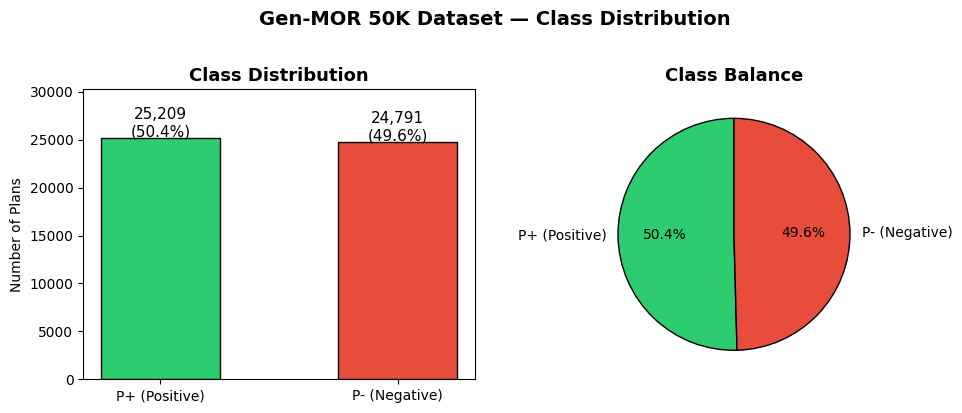

Saved → 01_class_distribution.png


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

counts     = [(y == 1).sum(), (y == 0).sum()]
labels_bar = ["P+ (Positive)", "P- (Negative)"]
colors     = ["#2ecc71", "#e74c3c"]

axes[0].bar(labels_bar, counts, color=colors,
            edgecolor="black", width=0.5)
axes[0].set_title("Class Distribution", fontsize=13, fontweight="bold")
axes[0].set_ylabel("Number of Plans")
for i, cnt in enumerate(counts):
    axes[0].text(i, cnt + 100,
                 f"{cnt:,}\n({cnt/sum(counts)*100:.1f}%)",
                 ha="center", fontsize=11)
axes[0].set_ylim(0, max(counts) * 1.2)

axes[1].pie(counts, labels=labels_bar, colors=colors,
            autopct="%1.1f%%", startangle=90,
            wedgeprops={"edgecolor": "black"})
axes[1].set_title("Class Balance", fontsize=13, fontweight="bold")

plt.suptitle("Gen-MOR 50K Dataset — Class Distribution",
             fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(f"{CONFIG['figures_dir']}/01_class_distribution.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("Saved → 01_class_distribution.png")

## Objective Value Distribution

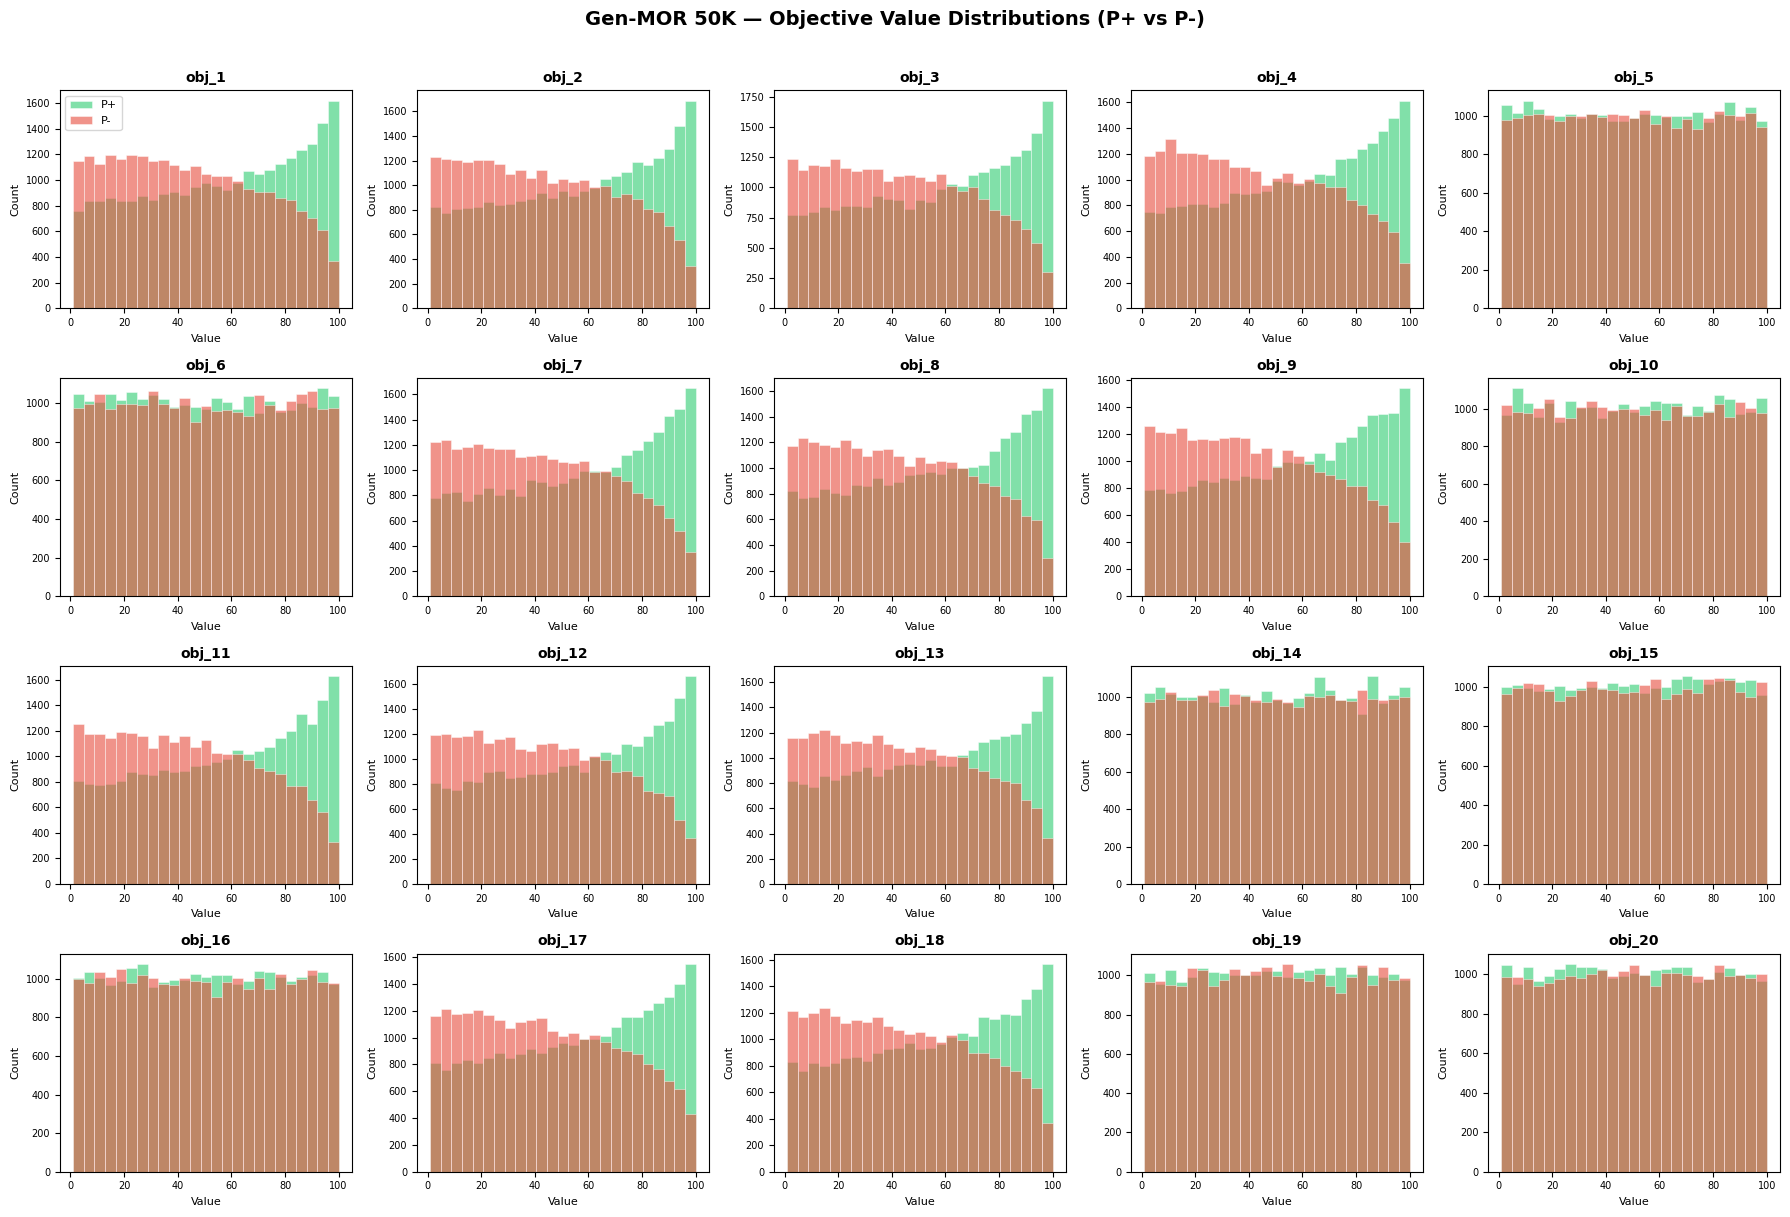

Saved → 02_objective_distributions.png


In [ ]:
fig, axes = plt.subplots(4, 5, figsize=(18, 12))
axes  = axes.flatten()
X_pos = X[y == 1]
X_neg = X[y == 0]

for i in range(20):
    ax = axes[i]
    ax.hist(X_pos[:, i], bins=25, alpha=0.6, color="#2ecc71",
            label="P+", edgecolor="white", linewidth=0.5)
    ax.hist(X_neg[:, i], bins=25, alpha=0.6, color="#e74c3c",
            label="P-", edgecolor="white", linewidth=0.5)
    ax.set_title(f"obj_{i+1}", fontsize=10, fontweight="bold")
    ax.set_xlabel("Value", fontsize=8)
    ax.set_ylabel("Count",  fontsize=8)
    ax.tick_params(labelsize=7)
    if i == 0:
        ax.legend(fontsize=8)

plt.suptitle("Gen-MOR 50K — Objective Value Distributions (P+ vs P-)",
             fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig(f"{CONFIG['figures_dir']}/02_objective_distributions.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("Saved → 02_objective_distributions.png")

## Mean Objective Values

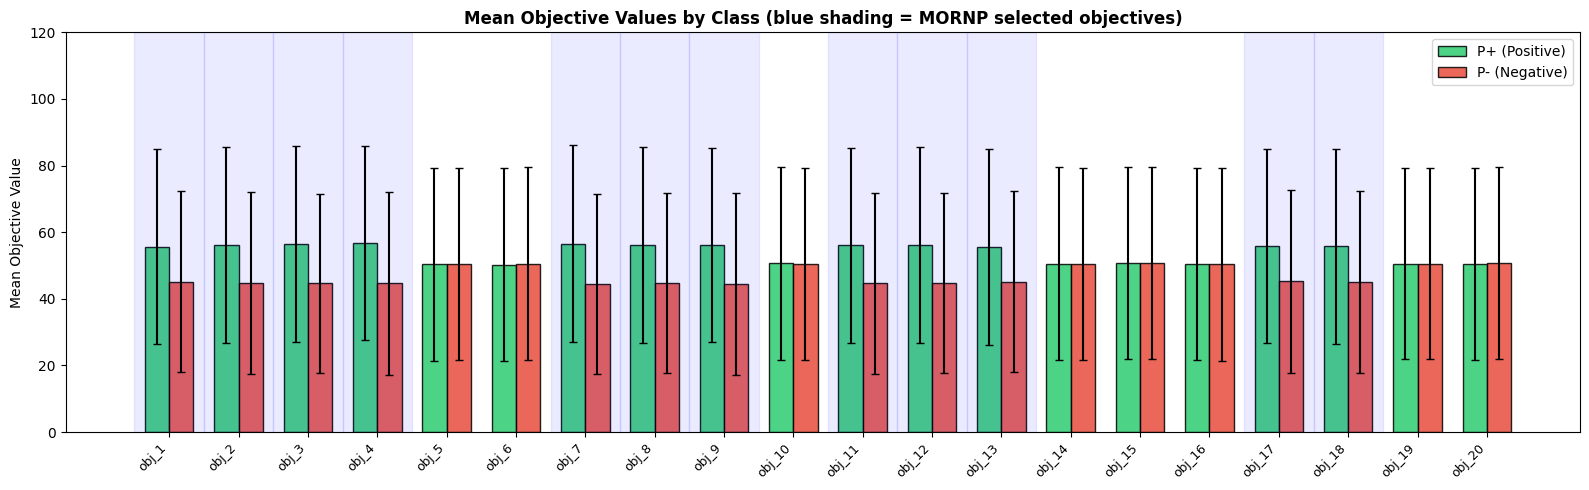

Saved → 03_mean_objective_values.png


In [ ]:
mean_pos = X_pos.mean(axis=0)
mean_neg = X_neg.mean(axis=0)
std_pos  = X_pos.std(axis=0)
std_neg  = X_neg.std(axis=0)

obj_labels  = [f"obj_{i+1}" for i in range(20)]
x_pos_bar   = np.arange(20)
width        = 0.35

fig, ax = plt.subplots(figsize=(16, 5))
bars1 = ax.bar(x_pos_bar - width/2, mean_pos, width,
               yerr=std_pos, label="P+ (Positive)",
               color="#2ecc71", edgecolor="black",
               capsize=3, alpha=0.85)
bars2 = ax.bar(x_pos_bar + width/2, mean_neg, width,
               yerr=std_neg, label="P- (Negative)",
               color="#e74c3c", edgecolor="black",
               capsize=3, alpha=0.85)

# Highlight selected objectives
for idx in selected_indices:
    ax.axvspan(idx - 0.5, idx + 0.5, alpha=0.08, color="blue")

ax.set_xticks(x_pos_bar)
ax.set_xticklabels(obj_labels, rotation=45, ha="right", fontsize=9)
ax.set_ylabel("Mean Objective Value")
ax.set_title("Mean Objective Values by Class "
             "(blue shading = MORNP selected objectives)",
             fontsize=12, fontweight="bold")
ax.legend()
ax.set_ylim(0, 120)
plt.tight_layout()
plt.savefig(f"{CONFIG['figures_dir']}/03_mean_objective_values.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("Saved → 03_mean_objective_values.png")

## Correlation Heatmaps

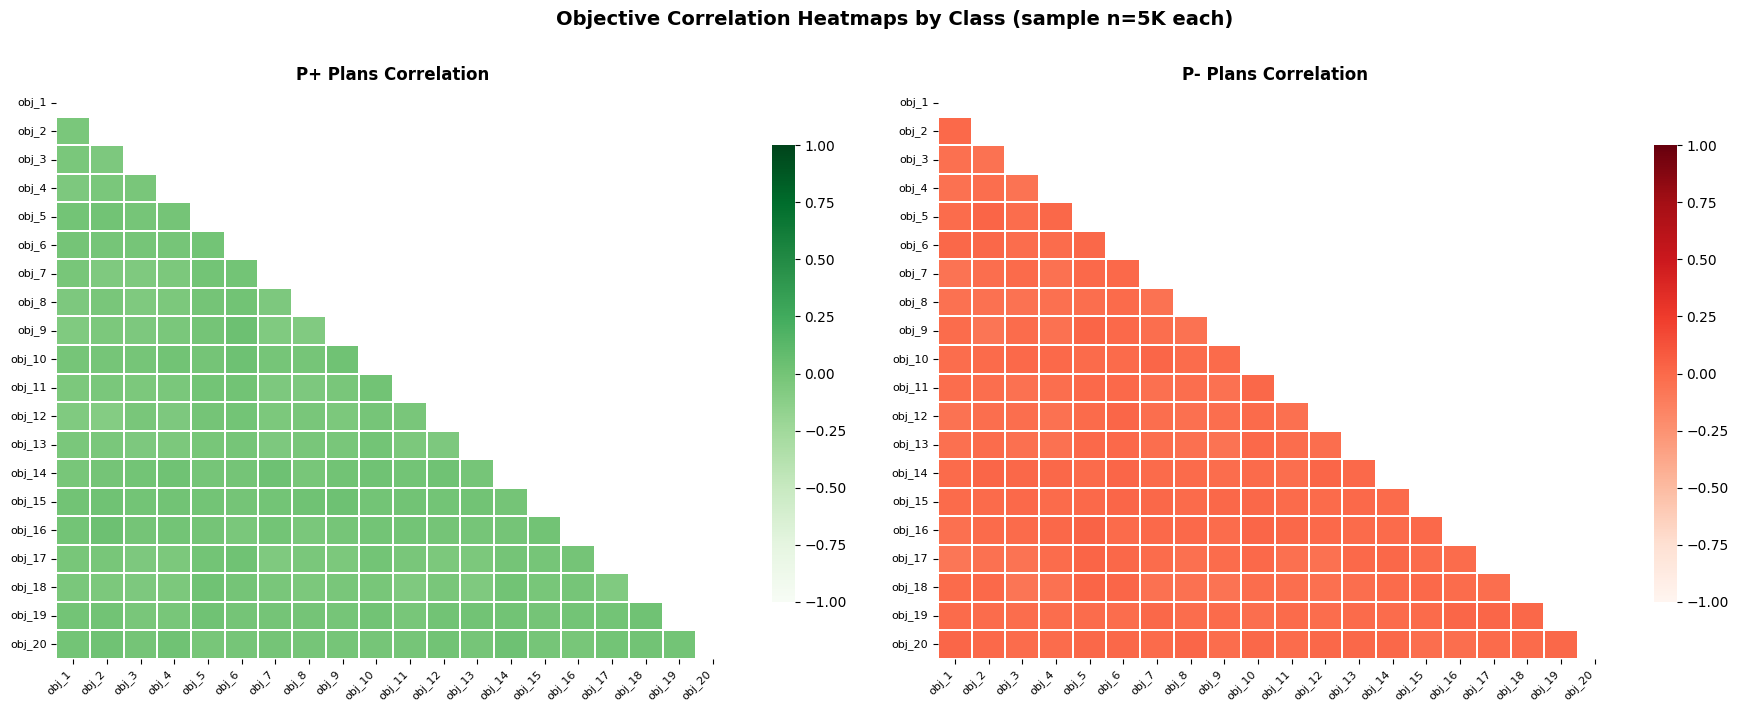

Saved → 04_correlation_heatmaps.png


In [ ]:
# We sample 5K per class for speed (full 25K each will be slow for corr)
np.random.seed(CONFIG["seed"])
pos_idx_sample = np.random.choice(np.where(y==1)[0], 5000, replace=False)
neg_idx_sample = np.random.choice(np.where(y==0)[0], 5000, replace=False)
X_pos_sample   = X[pos_idx_sample]
X_neg_sample   = X[neg_idx_sample]

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
for ax, (data, title, cmap) in zip(axes, [
    (X_pos_sample, "P+ Plans Correlation", "Greens"),
    (X_neg_sample, "P- Plans Correlation", "Reds"),
]):
    corr = pd.DataFrame(data, columns=obj_labels).corr()
    mask = np.triu(np.ones_like(corr, dtype=bool))
    sns.heatmap(corr, ax=ax, mask=mask, cmap=cmap,
                vmin=-1, vmax=1, center=0,
                annot=False, linewidths=0.3,
                cbar_kws={"shrink": 0.8})
    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.set_xticklabels(ax.get_xticklabels(),
                       rotation=45, ha="right", fontsize=8)
    ax.set_yticklabels(ax.get_yticklabels(),
                       rotation=0, fontsize=8)

plt.suptitle("Objective Correlation Heatmaps by Class (sample n=5K each)",
             fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig(f"{CONFIG['figures_dir']}/04_correlation_heatmaps.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("Saved → 04_correlation_heatmaps.png")

## PCA on Raw Data

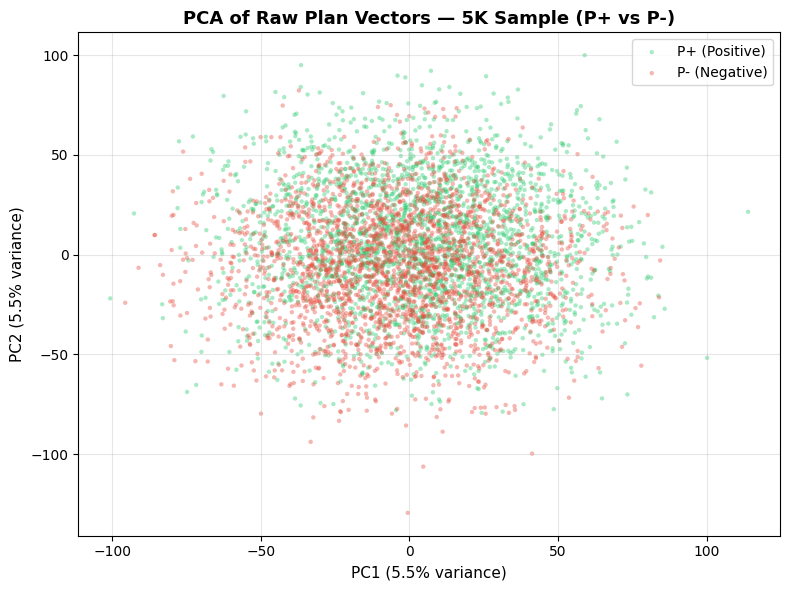

Saved → 05_pca_raw.png
Variance explained by PC1+PC2: 11.0%


In [ ]:
# We sample 5K for PCA speed
# Full 50k PCA will be later on
np.random.seed(CONFIG["seed"])
pca_sample_idx = np.random.choice(len(y), 5000, replace=False)
X_pca_sample   = X[pca_sample_idx]
y_pca_sample   = y[pca_sample_idx]

pca        = PCA(n_components=2, random_state=CONFIG["seed"])
X_pca      = pca.fit_transform(X_pca_sample)
var_ratio  = pca.explained_variance_ratio_

# Also fit PCA on full dataset, needed for latent space plots later
pca_full   = PCA(n_components=2, random_state=CONFIG["seed"])
X_pca_full = pca_full.fit_transform(X)

fig, ax = plt.subplots(figsize=(8, 6))
for label, name, color in [(1, "P+ (Positive)", "#2ecc71"),
                            (0, "P- (Negative)", "#e74c3c")]:
    mask = (y_pca_sample == label)
    ax.scatter(X_pca[mask, 0], X_pca[mask, 1],
               c=color, label=name,
               alpha=0.4, s=10, edgecolors="none")

ax.set_xlabel(f"PC1 ({var_ratio[0]*100:.1f}% variance)", fontsize=11)
ax.set_ylabel(f"PC2 ({var_ratio[1]*100:.1f}% variance)", fontsize=11)
ax.set_title("PCA of Raw Plan Vectors — 5K Sample (P+ vs P-)",
             fontsize=13, fontweight="bold")
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(f"{CONFIG['figures_dir']}/05_pca_raw.png",
            dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved → 05_pca_raw.png")
print(f"Variance explained by PC1+PC2: {sum(var_ratio)*100:.1f}%")

## EDA Summary

In [ ]:
print("=" * 60)
print("  GenMOR EDA Summary")
print("=" * 60)
print(f"  Total plans              : {len(y):,}")
print(f"  P+ plans                 : {int((y==1).sum()):,} "
      f"({(y==1).mean()*100:.1f}%)")
print(f"  P- plans                 : {int((y==0).sum()):,} "
      f"({(y==0).mean()*100:.1f}%)")
print(f"  Imbalance ratio          : "
      f"{(y==1).sum()/(y==0).sum():.2f}:1 (P+:P-)")
print(f"  Feature dimensions       : {X.shape[1]}")
print(f"  Selected objectives (k)  : {len(SELECTED_OBJECTIVES)}")
print(f"  Value range              : [{X.min():.0f}, {X.max():.0f}]")
print(f"  Overall mean             : {X.mean():.2f}")
print(f"  Overall std              : {X.std():.2f}")
print(f"  PCA variance (PC1+PC2)   : {sum(var_ratio)*100:.1f}%")
print("=" * 60)


# print("\n  Key observations vs original 1K dataset:")
# print(f"  1. Near-perfect class balance (50/50) vs original 83/17.")
# print(f"     WeightedRandomSampler is kept but has minimal effect.")
# print(f"  2. Same value range [1,100] — preprocessing identical.")
# print(f"  3. 50x more data gives the VAE/CVAE far richer signal.")
# print(f"  4. PCA variance guides whether latent space is needed.")
# print("=" * 60)

  GenMOR EDA Summary
  Total plans              : 50,000
  P+ plans                 : 25,209 (50.4%)
  P- plans                 : 24,791 (49.6%)
  Imbalance ratio          : 1.02:1 (P+:P-)
  Feature dimensions       : 20
  Selected objectives (k)  : 12
  Value range              : [1, 100]
  Overall mean             : 50.50
  Overall std              : 28.87
  PCA variance (PC1+PC2)   : 11.0%


## Verify Steps

In [ ]:
figures_expected = [
    "01_class_distribution.png",
    "02_objective_distributions.png",
    "03_mean_objective_values.png",
    "04_correlation_heatmaps.png",
    "05_pca_raw.png",
]
print("=" * 50)
print("  Step 3 Verification")
print("=" * 50)
all_good = True
for fname in figures_expected:
    path   = f"{CONFIG['figures_dir']}/{fname}"
    exists = os.path.exists(path)
    icon   = "(OK)" if exists else "(WARNING)"
    print(f"  {icon} {fname}")
    if not exists:
        all_good = False
print("=" * 50)
if all_good:
    print("  (OK) All figures saved. Ready for Step 4!")
else:
    print("  (WARNING) Some figures missing — re-run cells above.")

  Step 3 Verification
  (OK) 01_class_distribution.png
  (OK) 02_objective_distributions.png
  (OK) 03_mean_objective_values.png
  (OK) 04_correlation_heatmaps.png
  (OK) 05_pca_raw.png
  (OK) All figures saved. Ready for Step 4!


# **Preprocessing**

## Split and Scale

*We perform the train/validation/test split using scikit-learn's train_test_split with stratify=y to preserve the class balance in each split. The split proportions are 70% training, 15% validation, and 15% test. Stratification is especially important here because even though the overall balance is nearly 50/50, maintaining that exact ratio in all three splits ensures that all evaluation metrics are computed on representative class distributions. The split is done in two stages: first separating the test set, then splitting the remainder into train and validation. The cell prints the exact count of plans in each split.*

In [ ]:
# We first split then scale (fit on train only)
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y,
    test_size    = CONFIG["test_size"],
    random_state = CONFIG["seed"],
    stratify     = y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp,
    test_size    = CONFIG["val_size"] / (1 - CONFIG["test_size"]),
    random_state = CONFIG["seed"],
    stratify     = y_temp
)

print("Raw split sizes:")
print(f"  Train : {X_train.shape[0]:,} plans")
print(f"  Val   : {X_val.shape[0]:,}   plans")
print(f"  Test  : {X_test.shape[0]:,}  plans")
print(f"  Total : {X_train.shape[0]+X_val.shape[0]+X_test.shape[0]:,}")

Raw split sizes:
  Train : 34,999 plans
  Val   : 7,501   plans
  Test  : 7,500  plans
  Total : 50,000


## MinMax Scaling

*We fit a MinMaxScaler to the training data only and then transforms all three splits. The scaler is fit only on the training set to prevent data leakage, which would occur if the model were to see any information from the validation or test distributions during training. MinMax scaling maps all objective values from the original [1, 100] range to [0, 1], which is required because the decoder's final activation is a sigmoid function that outputs values in [0, 1]. The cell prints the actual min and max of each scaled split to confirm they are all within the expected range.*

In [ ]:
# Fit scaler on train only
scaler         = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled   = scaler.transform(X_val)
X_test_scaled  = scaler.transform(X_test)

print("After MinMax scaling:")
print(f"  Train range: [{X_train_scaled.min():.3f}, "
      f"{X_train_scaled.max():.3f}]")
print(f"  Val   range: [{X_val_scaled.min():.3f}, "
      f"{X_val_scaled.max():.3f}]")
print(f"  Test  range: [{X_test_scaled.min():.3f}, "
      f"{X_test_scaled.max():.3f}]")

After MinMax scaling:
  Train range: [0.000, 1.000]
  Val   range: [0.000, 1.000]
  Test  range: [0.000, 1.000]


## Class Balance Per Split

In [ ]:
print("=" * 60)
print("  Class Balance Per Split")
print("=" * 60)
print(f"  {'Split':<8} {'Total':>8} {'P+ count':>10} "
      f"{'P+ %':>8} {'P- count':>10} {'P- %':>8}")
print("  " + "-" * 55)
for name, y_split in [("Train", y_train),
                       ("Val",   y_val),
                       ("Test",  y_test)]:
    n     = len(y_split)
    n_pos = int((y_split == 1).sum())
    n_neg = int((y_split == 0).sum())
    print(f"  {name:<8} {n:>8,} {n_pos:>10,} "
          f"{n_pos/n*100:>7.1f}% {n_neg:>10,} "
          f"{n_neg/n*100:>7.1f}%")
print("=" * 60)
print("(OK) Stratification preserves class ratios across splits.")

  Class Balance Per Split
  Split       Total   P+ count     P+ %   P- count     P- %
  -------------------------------------------------------
  Train      34,999     17,646    50.4%     17,353    49.6%
  Val         7,501      3,782    50.4%      3,719    49.6%
  Test        7,500      3,781    50.4%      3,719    49.6%
(OK) Stratification preserves class ratios across splits.


## PyTorch Dataset

*We define the PlanDataset class, which wraps numpy arrays into a PyTorch Dataset that can be consumed by DataLoader. Each call to __getitem__ returns a tuple of a float32 feature tensor of shape (20,) and a scalar float32 label. This class is used to create three dataset objects: one for training, one for validation, and one for testing. The also prints a sample item to confirm the shapes and values look correct.*

In [ ]:
# Custom PyTorch Dataset
class PlanDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

train_dataset = PlanDataset(X_train_scaled, y_train)
val_dataset   = PlanDataset(X_val_scaled,   y_val)
test_dataset  = PlanDataset(X_test_scaled,  y_test)

print(f"Train dataset : {len(train_dataset):,} samples")
print(f"Val   dataset : {len(val_dataset):,}   samples")
print(f"Test  dataset : {len(test_dataset):,}  samples")

x_sample, y_sample = train_dataset[0]
print(f"\nSample item:")
print(f"  x shape : {x_sample.shape}")
print(f"  y label : {y_sample.item()}")

Train dataset : 34,999 samples
Val   dataset : 7,501   samples
Test  dataset : 7,500  samples

Sample item:
  x shape : torch.Size([20])
  y label : 0.0


## WeightedRandomSampler

*We create a WeightedRandomSampler that assigns a sampling weight to each training example inversely proportional to its class frequency. In the 50K dataset the class balance is nearly 50/50, so the weights are almost equal and the sampler has minimal effect. However, it is kept for methodological consistency because even a small residual imbalance can affect training stability. This prints the actual weights and their ratio to make this point explicit.*

In [ ]:
# Near-perfect 50/50 balance means weights are almost equal.
# Keeping it for methodological consistency with original.
n_pos = (y_train == 1).sum()
n_neg = (y_train == 0).sum()

weight_pos     = 1.0 / n_pos
weight_neg     = 1.0 / n_neg
sample_weights = np.where(y_train == 1, weight_pos, weight_neg)
sample_weights = torch.tensor(sample_weights, dtype=torch.float32)

sampler = WeightedRandomSampler(
    weights     = sample_weights,
    num_samples = len(sample_weights),
    replacement = True
)

print("WeightedRandomSampler created:")
print(f"  Weight P+ : {weight_pos:.6f} (1 / {n_pos:,})")
print(f"  Weight P- : {weight_neg:.6f} (1 / {n_neg:,})")
print(f"  Weight ratio P-/P+ : {weight_neg/weight_pos:.3f}")
print(f"  (Near 1.0 = near-perfect balance, minimal oversampling)")

WeightedRandomSampler created:
  Weight P+ : 0.000057 (1 / 17,646)
  Weight P- : 0.000058 (1 / 17,353)
  Weight ratio P-/P+ : 1.017
  (Near 1.0 = near-perfect balance, minimal oversampling)


## DataLoaders

*We create three DataLoader objects that batch and optionally shuffle data for the training loop. The training loader uses the WeightedRandomSampler instead of shuffle=True since the two are mutually exclusive and the sampler already handles randomization. The validation and test loaders use shuffle=False since the order of evaluation batches does not affect the metrics. The batch size is set to 256, larger batches make better use of the GPU's parallel processing capability at this dataset scale. This prints the number of batches in each loader and displays a sample batch to confirm shapes and approximate class balance.*

In [ ]:
pin = device.type == "cuda"

train_loader = DataLoader(
    train_dataset,
    batch_size  = CONFIG["batch_size"],
    sampler     = sampler,
    num_workers = 0,
    pin_memory  = pin,
)
val_loader = DataLoader(
    val_dataset,
    batch_size  = CONFIG["batch_size"],
    shuffle     = False,
    num_workers = 0,
    pin_memory  = pin,
)
test_loader = DataLoader(
    test_dataset,
    batch_size  = CONFIG["batch_size"],
    shuffle     = False,
    num_workers = 0,
    pin_memory  = pin,
)

print("DataLoaders ready:")
print(f"  Train : {len(train_loader):,} batches × "
      f"{CONFIG['batch_size']} samples")
print(f"  Val   : {len(val_loader):,} batches")
print(f"  Test  : {len(test_loader):,} batches")

x_batch, y_batch = next(iter(train_loader))
print(f"\nSample batch:")
print(f"  x shape   : {x_batch.shape}")
print(f"  y shape   : {y_batch.shape}")
print(f"  P+ in batch : {(y_batch==1).sum().item()}")
print(f"  P- in batch : {(y_batch==0).sum().item()}")

DataLoaders ready:
  Train : 137 batches × 256 samples
  Val   : 30 batches
  Test  : 30 batches

Sample batch:
  x shape   : torch.Size([256, 20])
  y shape   : torch.Size([256])
  P+ in batch : 128
  P- in batch : 128


## Save Preprocessing

In [ ]:
import pickle

In [ ]:
np.save(f"{CONFIG['results_dir']}/X_train_scaled.npy", X_train_scaled)
np.save(f"{CONFIG['results_dir']}/X_val_scaled.npy",   X_val_scaled)
np.save(f"{CONFIG['results_dir']}/X_test_scaled.npy",  X_test_scaled)
np.save(f"{CONFIG['results_dir']}/y_train.npy",        y_train)
np.save(f"{CONFIG['results_dir']}/y_val.npy",          y_val)
np.save(f"{CONFIG['results_dir']}/y_test.npy",         y_test)

with open(f"{CONFIG['results_dir']}/scaler.pkl", "wb") as f:
    pickle.dump(scaler, f)

print("Saved to Drive:")
for fname in ["X_train_scaled.npy", "X_val_scaled.npy",
              "X_test_scaled.npy",  "y_train.npy",
              "y_val.npy",          "y_test.npy",
              "scaler.pkl"]:
    print(f"  → {CONFIG['results_dir']}/{fname}")

Saved to Drive:
  → /content/drive/MyDrive/GenMOR/results/X_train_scaled.npy
  → /content/drive/MyDrive/GenMOR/results/X_val_scaled.npy
  → /content/drive/MyDrive/GenMOR/results/X_test_scaled.npy
  → /content/drive/MyDrive/GenMOR/results/y_train.npy
  → /content/drive/MyDrive/GenMOR/results/y_val.npy
  → /content/drive/MyDrive/GenMOR/results/y_test.npy
  → /content/drive/MyDrive/GenMOR/results/scaler.pkl


## Verify Steps

In [ ]:
x_batch_check, y_batch_check = next(iter(train_loader))
p_plus_in_batch  = (y_batch_check == 1).sum().item()
p_minus_in_batch = (y_batch_check == 0).sum().item()
sampler_working  = abs(p_plus_in_batch - p_minus_in_batch) < 80

print("=" * 60)
print("  Steps Verification")
print("=" * 60)
checks = {
    "Total split correct (50000)"  : (len(train_dataset) +
                                      len(val_dataset) +
                                      len(test_dataset)) == len(X),
    "Scaling range [0,1] on train" : (X_train_scaled.min() >= 0 and
                                      X_train_scaled.max() <= 1.0),
    "Stratification preserved"     : abs((y_train==1).mean() -
                                         (y==1).mean()) < 0.02,
    "Sampler active"               : sampler_working,
    "Scaler saved to Drive"        : os.path.exists(
                                       f"{CONFIG['results_dir']}/scaler.pkl"),
    "DataLoaders correct shape"    : x_batch.shape[1] == CONFIG["input_dim"],
}
all_good = True
for name, status in checks.items():
    icon = "(OK)" if status else "(WARNING)"
    print(f"  {icon} {name}")
    if not status:
        all_good = False
print("=" * 60)
if all_good:
    print("  (OK) All checks passed.")
else:
    print("  (CHECK) Fix the items marked (WARNING) before continuing.")

  Steps Verification
  (OK) Total split correct (50000)
  (OK) Scaling range [0,1] on train
  (OK) Stratification preserved
  (OK) Sampler active
  (OK) Scaler saved to Drive
  (OK) DataLoaders correct shape
  (OK) All checks passed.


# **Plain Autoencoder (AE)**

## AE Architecture

*We define the Autoencoder class using PyTorch's nn.Module. The encoder takes the 20-dimensional input, passes it through two hidden layers of sizes 256 and 128 (each with BatchNorm and ReLU activation), and projects to a latent vector of dimension 16. The decoder mirrors this exactly in reverse, going from 16 up through 128 and 256, and outputting a 20-dimensional reconstruction through a sigmoid activation to keep values in [0, 1]. A separate classifier head takes the 16-dimensional latent vector, passes it through a 32-unit hidden layer with ReLU, and produces a single sigmoid output predicting whether the plan is P+ or P-. The forward method returns three values: the reconstructed input, the latent vector, and the class prediction. This triple-output design allows the autoencoder to simultaneously learn to compress plans faithfully and to structure the latent space in a way that separates classes. We instantiate the model, moves it to the device, prints the full architecture, and reports the total parameter count.*

**diff ac func

In [ ]:
class Autoencoder(nn.Module):
    def __init__(self, input_dim, hidden_dims, latent_dim):
        super(Autoencoder, self).__init__()

        # Encoder
        encoder_layers = []
        in_dim = input_dim
        for h_dim in hidden_dims:
            encoder_layers += [
                nn.Linear(in_dim, h_dim),
                nn.BatchNorm1d(h_dim),
                nn.ReLU(), #try diff //linear??
            ]
            in_dim = h_dim
        encoder_layers.append(nn.Linear(in_dim, latent_dim))
        self.encoder = nn.Sequential(*encoder_layers)

        # Decoder
        decoder_layers = []
        in_dim = latent_dim
        for h_dim in reversed(hidden_dims):
            decoder_layers += [
                nn.Linear(in_dim, h_dim),
                nn.BatchNorm1d(h_dim),
                nn.ReLU(),
            ]
            in_dim = h_dim
        decoder_layers += [
            nn.Linear(in_dim, input_dim),
            nn.Sigmoid(),
        ]
        self.decoder = nn.Sequential(*decoder_layers)

        # Classifier head
        self.classifier = nn.Sequential(
            nn.Linear(latent_dim, 32),
            nn.ReLU(),
            nn.Linear(32, 1),
            nn.Sigmoid()
        )

    def encode(self, x):
        return self.encoder(x)

    def decode(self, z):
        return self.decoder(z)

    def forward(self, x):
        z      = self.encode(x)
        x_recon = self.decode(z)
        y_pred  = self.classifier(z).squeeze(1)
        return x_recon, z, y_pred

ae_model = Autoencoder(
    input_dim   = CONFIG["input_dim"],
    hidden_dims = CONFIG["hidden_dims"],
    latent_dim  = CONFIG["latent_dim"],
).to(device)

print(ae_model)
print(f"\nTotal parameters    : "
      f"{sum(p.numel() for p in ae_model.parameters()):,}")
print(f"Trainable parameters: "
      f"{sum(p.numel() for p in ae_model.parameters() if p.requires_grad):,}")

Autoencoder(
  (encoder): Sequential(
    (0): Linear(in_features=20, out_features=256, bias=True)
    (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
    (6): Linear(in_features=128, out_features=16, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=16, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=256, bias=True)
    (4): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
    (6): Linear(in_features=256, out_features=20, bias=True)
    (7): Sigmoid()
  )
  (classifier): Sequential(
    (0): Linear(in_features=16, out_features=32, bias=True)
    (1): ReLU()
    (2): Linea

## Loss Function and Optimizer

In [ ]:
def ae_loss_fn(x_recon, x_orig, y_pred, y_true,
               recon_weight=1.0, class_weight=0.5):
    recon_loss = nn.MSELoss()(x_recon, x_orig)
    class_loss = nn.BCELoss()(y_pred,  y_true)
    total_loss = recon_weight * recon_loss + class_weight * class_loss
    return total_loss, recon_loss, class_loss

ae_optimizer = optim.Adam(
    ae_model.parameters(),
    lr           = CONFIG["learning_rate"],
    weight_decay = 1e-5,
)
ae_scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    ae_optimizer, mode="min", factor=0.5, patience=10,
)

print("Loss      : MSE (reconstruction) + BCE (classification)")
print(f"Optimizer : Adam lr={CONFIG['learning_rate']}")
print("Scheduler : ReduceLROnPlateau")

Loss      : MSE (reconstruction) + BCE (classification)
Optimizer : Adam lr=0.001
Scheduler : ReduceLROnPlateau


## AE Training Loop

*We define the train_autoencoder function and immediately calls it to train the model. The function implements a standard supervised training loop with early stopping. In each epoch it runs a full pass over the training batches, computing the combined loss, backpropagating gradients, and updating weights. It then runs a validation pass with gradients disabled to evaluate the current model on held-out data. If the validation loss is lower than the best seen so far, the model weights are saved to the checkpoint file. If the validation loss fails to improve for patience consecutive epochs (set to 20), training stops early to prevent overfitting. Every 20 epochs a progress line is printed showing the total loss, its two components, the validation loss, and the current learning rate. The function returns a history dictionary containing the loss values for every epoch, which is used for plotting in the next cell.*

In [ ]:
def train_autoencoder(model, optimizer, scheduler,
                      train_loader, val_loader,
                      epochs, patience, checkpoint_path):
    history = {
        "train_loss": [], "val_loss": [],
        "train_recon": [], "val_recon": [],
        "train_cls":   [], "val_cls":   [],
    }
    best_val_loss  = float("inf")
    patience_count = 0

    for epoch in range(1, epochs + 1):
        # Training
        model.train()
        t_loss = t_recon = t_cls = 0.0
        for x_batch, y_batch in train_loader:
            x_batch = x_batch.to(device)
            y_batch = y_batch.to(device)
            optimizer.zero_grad()
            x_recon, z, y_pred = model(x_batch)
            loss, recon_loss, class_loss = ae_loss_fn(
                x_recon, x_batch, y_pred, y_batch
            )
            loss.backward()
            optimizer.step()
            t_loss  += loss.item()
            t_recon += recon_loss.item()
            t_cls   += class_loss.item()

        n  = len(train_loader)
        t_loss /= n; t_recon /= n; t_cls /= n

        # Validation
        model.eval()
        v_loss = v_recon = v_cls = 0.0
        with torch.no_grad():
            for x_batch, y_batch in val_loader:
                x_batch = x_batch.to(device)
                y_batch = y_batch.to(device)
                x_recon, z, y_pred = model(x_batch)
                loss, recon_loss, class_loss = ae_loss_fn(
                    x_recon, x_batch, y_pred, y_batch
                )
                v_loss  += loss.item()
                v_recon += recon_loss.item()
                v_cls   += class_loss.item()

        nv = len(val_loader)
        v_loss /= nv; v_recon /= nv; v_cls /= nv

        scheduler.step(v_loss)

        for key, val in zip(
            ["train_loss","val_loss","train_recon",
             "val_recon","train_cls","val_cls"],
            [t_loss, v_loss, t_recon,
             v_recon, t_cls, v_cls]
        ):
            history[key].append(val)

        if v_loss < best_val_loss:
            best_val_loss  = v_loss
            patience_count = 0
            torch.save(model.state_dict(), checkpoint_path)
        else:
            patience_count += 1

        if epoch % 20 == 0 or epoch == 1:
            print(f"Epoch {epoch:>4}/{epochs} | "
                  f"Train: {t_loss:.5f} "
                  f"(recon:{t_recon:.5f} cls:{t_cls:.5f}) | "
                  f"Val: {v_loss:.5f} | "
                  f"LR: {optimizer.param_groups[0]['lr']:.6f}")

        if patience_count >= patience:
            print(f"\n Early stopping at epoch {epoch}")
            break

    print(f"\n Best val loss: {best_val_loss:.5f} "
          f"→ saved to {checkpoint_path}")
    return history

ae_checkpoint = f"{CONFIG['checkpoint_dir']}/ae_best.pt"
print("Training Plain Autoencoder...")
print("=" * 70)
ae_history = train_autoencoder(
    model            = ae_model,
    optimizer        = ae_optimizer,
    scheduler        = ae_scheduler,
    train_loader     = train_loader,
    val_loader       = val_loader,
    epochs           = CONFIG["epochs"],
    patience         = CONFIG["early_stop_patience"],
    checkpoint_path  = ae_checkpoint,
)

Training Plain Autoencoder...
Epoch    1/200 | Train: 0.21772 (recon:0.03242 cls:0.37059) | Val: 0.17995 | LR: 0.001000
Epoch   20/200 | Train: 0.09729 (recon:0.01319 cls:0.16820) | Val: 0.19732 | LR: 0.000500

 Early stopping at epoch 28

 Best val loss: 0.17000 → saved to /content/drive/MyDrive/GenMOR/checkpoints/ae_best.pt


## Plot Training Curves

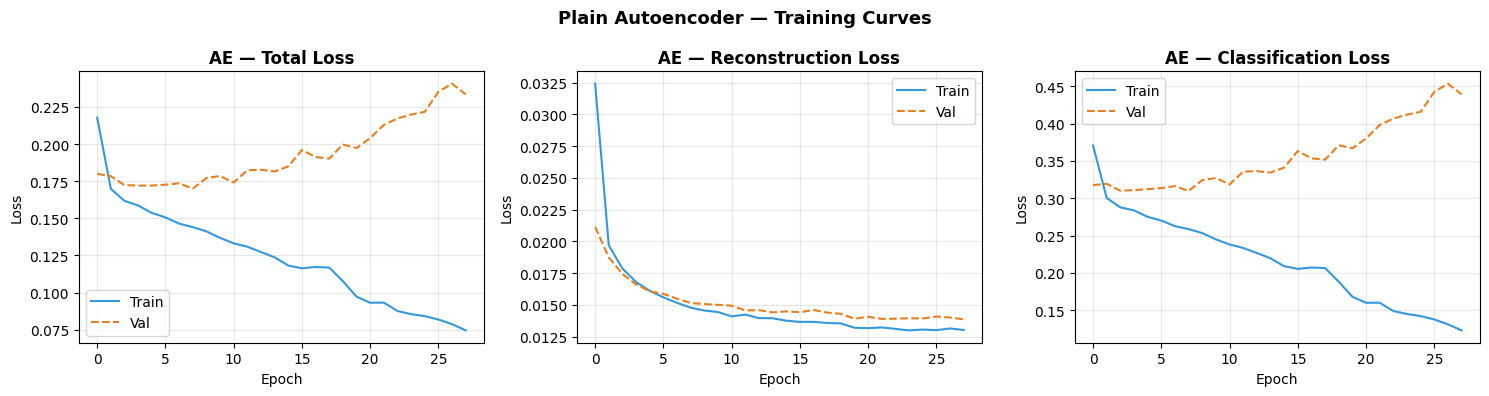

Saved → 06_ae_loss_curves.png


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
titles = ["Total Loss", "Reconstruction Loss", "Classification Loss"]
t_keys = ["train_loss",  "train_recon",  "train_cls"]
v_keys = ["val_loss",    "val_recon",    "val_cls"]

for ax, title, t_key, v_key in zip(axes, titles, t_keys, v_keys):
    ax.plot(ae_history[t_key], label="Train", color="#3498db")
    ax.plot(ae_history[v_key], label="Val",
            color="#e67e22", linestyle="--")
    ax.set_title(f"AE — {title}", fontweight="bold")
    ax.set_xlabel("Epoch"); ax.set_ylabel("Loss")
    ax.legend(); ax.grid(True, alpha=0.3)

plt.suptitle("Plain Autoencoder — Training Curves",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(f"{CONFIG['figures_dir']}/06_ae_loss_curves.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("Saved → 06_ae_loss_curves.png")

## Evaluate on Test Set

*We load the best saved checkpoint, switches the model to evaluation mode, and runs inference on the held-out test set. It collects four arrays: the original scaled inputs, the reconstructions, the latent vectors, and the classifier predictions. From these it computes three metrics. The reconstruction MSE measures how accurately the model can compress and decompress plan vectors. The classification accuracy measures how often the classifier head correctly identifies P+ versus P- plans from the latent representation. The weighted F1 score accounts for any residual class imbalance in the test set. We also prints a per-class classification report showing precision, recall, and F1 separately for P+ and P- plans. All results are saved to a JSON file for later aggregation.*

In [ ]:
ae_model.load_state_dict(
    torch.load(ae_checkpoint, map_location=device))
ae_model.eval()

all_x = []; all_x_recon = []; all_z = []
all_y_true = []; all_y_pred = []

with torch.no_grad():
    for x_batch, y_batch in test_loader:
        x_batch = x_batch.to(device)
        x_recon, z, y_p = ae_model(x_batch)
        all_x.append(x_batch.cpu().numpy())
        all_x_recon.append(x_recon.cpu().numpy())
        all_z.append(z.cpu().numpy())
        all_y_true.append(y_batch.numpy())
        all_y_pred.append(y_p.cpu().numpy())

all_x      = np.concatenate(all_x)
all_x_recon = np.concatenate(all_x_recon)
all_z      = np.concatenate(all_z)
all_y_true = np.concatenate(all_y_true)
all_y_pred = np.concatenate(all_y_pred)

mse        = np.mean((all_x - all_x_recon) ** 2)
y_pred_bin = (all_y_pred >= 0.5).astype(int)
acc        = accuracy_score(all_y_true, y_pred_bin)
f1         = f1_score(all_y_true, y_pred_bin, average="weighted")

print("=" * 55)
print("  Plain Autoencoder — Test Set Results")
print("=" * 55)
print(f"  Reconstruction MSE  : {mse:.6f}")
print(f"  Classification Acc  : {acc*100:.2f}%")
print(f"  Weighted F1 Score   : {f1:.4f}")
print("=" * 55)
print("\nPer-class report:")
print(classification_report(all_y_true, y_pred_bin,
                             target_names=["P- (0)", "P+ (1)"]))

ae_results = {
    "model"         : "Autoencoder",
    "mse"           : float(mse),
    "acc"           : float(acc),
    "f1"            : float(f1),
    "epochs_trained": len(ae_history["train_loss"]),
}
with open(f"{CONFIG['results_dir']}/ae_results.json", "w") as f:
    json.dump(ae_results, f, indent=2)
print("Results saved → ae_results.json")

  Plain Autoencoder — Test Set Results
  Reconstruction MSE  : 0.014999
  Classification Acc  : 85.84%
  Weighted F1 Score   : 0.8584

Per-class report:
              precision    recall  f1-score   support

      P- (0)       0.86      0.85      0.86      3719
      P+ (1)       0.86      0.86      0.86      3781

    accuracy                           0.86      7500
   macro avg       0.86      0.86      0.86      7500
weighted avg       0.86      0.86      0.86      7500

Results saved → ae_results.json


## Latent Space Visualization

*We encode all 50,000 plans through the trained autoencoder to collect their latent vectors, then projects those latent vectors to 2D using PCA. It creates a side-by-side figure comparing the raw feature space PCA (showing poor class separation, which was already established in Step 3) against the AE latent space PCA. In a well-trained autoencoder the latent space should show somewhat better class separation because the classification head has encouraged the encoder to organize plans by class. However, since the autoencoder is a baseline model and does not impose a structured prior on the latent space, the separation may still be imperfect. Because plotting all 50,000 points produces a dense, unreadable figure, this cell randomly subsamples 3,000 points per class for the scatter plots.*

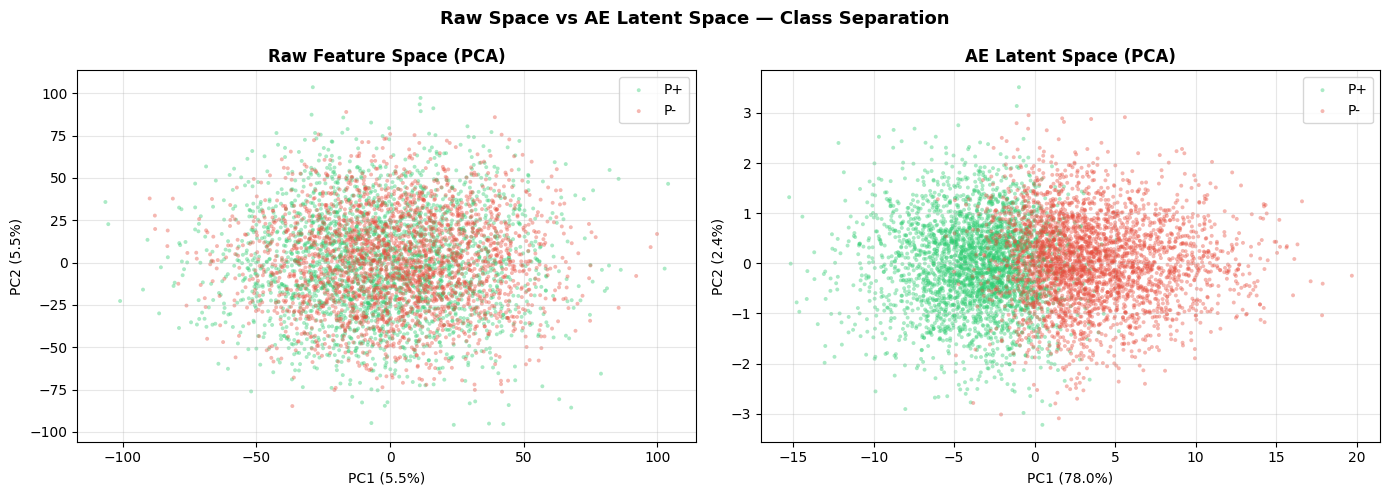

Saved → 07_ae_latent_space.png


In [ ]:
ae_model.eval()
all_z_full = []; all_y_full = []

full_dataset = PlanDataset(
    np.vstack([X_train_scaled, X_val_scaled, X_test_scaled]),
    np.concatenate([y_train, y_val, y_test])
)
with torch.no_grad():
    for x_batch, y_batch in DataLoader(
            full_dataset, batch_size=512):
        _, z, _ = ae_model(x_batch.to(device))
        all_z_full.append(z.cpu().numpy())
        all_y_full.append(y_batch.numpy())

all_z_full = np.concatenate(all_z_full)
all_y_full = np.concatenate(all_y_full)

pca_lat      = PCA(n_components=2, random_state=CONFIG["seed"])
z_pca        = pca_lat.fit_transform(all_z_full)
var_ratio_lat = pca_lat.explained_variance_ratio_

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (coords, title, var, y_arr) in zip(axes, [
    (X_pca_full[pca_sample_idx],
     "Raw Feature Space (PCA)", var_ratio, y_pca_sample),
    (z_pca, "AE Latent Space (PCA)", var_ratio_lat, all_y_full),
]):
    for label, name, color in [(1, "P+", "#2ecc71"),
                                (0, "P-", "#e74c3c")]:
        mask = (y_arr == label)
        # Subsample for plot clarity
        idx  = np.random.choice(mask.sum(),
                                min(3000, mask.sum()), replace=False)
        ax.scatter(coords[mask][idx, 0],
                   coords[mask][idx, 1],
                   c=color, label=name,
                   alpha=0.4, s=8, edgecolors="none")
    ax.set_xlabel(f"PC1 ({var[0]*100:.1f}%)")
    ax.set_ylabel(f"PC2 ({var[1]*100:.1f}%)")
    ax.set_title(title, fontweight="bold")
    ax.legend(); ax.grid(True, alpha=0.3)

plt.suptitle("Raw Space vs AE Latent Space — Class Separation",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(f"{CONFIG['figures_dir']}/07_ae_latent_space.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("Saved → 07_ae_latent_space.png")

## Verify Steps

In [ ]:
print("=" * 55)
print("  Step 5 Verification")
print("=" * 55)
checks = {
    "Checkpoint saved"          : os.path.exists(ae_checkpoint),
    "MSE below 0.10"            : mse < 0.10,
    "Classification acc > 70%"  : acc > 0.70,
    "Results JSON saved"        : os.path.exists(
                                    f"{CONFIG['results_dir']}/ae_results.json"),
    "Latent space figure saved" : os.path.exists(
                                    f"{CONFIG['figures_dir']}/07_ae_latent_space.png"),
}
all_good = True
for name, status in checks.items():
    icon = "(OK)" if status else "(WARNING)"
    print(f"  {icon} {name}")
    if not status:
        all_good = False
print("=" * 55)
if all_good:
    print("  (OK) All checks passed. Ready for Step 6!")
else:
    print("  (CHECK) Fix the items marked (WARNING) before continuing.")

  Step 5 Verification
  (OK) Checkpoint saved
  (OK) MSE below 0.10
  (OK) Classification acc > 70%
  (OK) Results JSON saved
  (OK) Latent space figure saved
  (OK) All checks passed. Ready for Step 6!


# **Variational Autoencoder (VAE)**

## VAE Architecture

*We define the VAE class, which extends the plain autoencoder with the core innovation of variational inference. The encoder trunk is identical to the autoencoder, but instead of outputting a single latent vector it outputs two vectors of the same dimension: mu (the mean) and log_var (the log variance) of a Gaussian distribution. The reparameterize method samples from this distribution during training using the reparameterization trick: it multiplies a random noise sample by the standard deviation and adds the mean. This keeps the sampling step differentiable so gradients can flow back through the stochastic node to the encoder. During evaluation the method simply returns mu directly, giving deterministic and smooth encodings. The decoder and classifier head are identical to the autoencoder. The critical difference is the generate method, which samples a random vector from the standard normal distribution N(0, I) and decodes it to produce a novel plan vector. This is the VAE's core capability that the plain autoencoder lacks. The cell instantiates the model, moves it to device, and prints the architecture and parameter count.*

## diff ac func

first, relu. second, try diff

In [ ]:
class VAE(nn.Module):
    def __init__(self, input_dim, hidden_dims, latent_dim):
        super(VAE, self).__init__()

        # Encoder trunk
        encoder_layers = []
        in_dim = input_dim
        for h_dim in hidden_dims:
            encoder_layers += [
                nn.Linear(in_dim, h_dim),
                nn.BatchNorm1d(h_dim),
                nn.LeakyReLU(), #try diff

                # first, relu. second, try diff
            ]
            in_dim = h_dim
        self.encoder   = nn.Sequential(*encoder_layers)
        self.fc_mu     = nn.Linear(in_dim, latent_dim)
        self.fc_log_var = nn.Linear(in_dim, latent_dim)

        # Decoder
        decoder_layers = []
        in_dim = latent_dim
        for h_dim in reversed(hidden_dims):
            decoder_layers += [
                nn.Linear(in_dim, h_dim),
                nn.BatchNorm1d(h_dim),
                nn.ELU(),
            ]
            in_dim = h_dim
        decoder_layers += [
            nn.Linear(in_dim, input_dim),
            nn.Sigmoid(),
        ]
        self.decoder = nn.Sequential(*decoder_layers)

        # Classifier head
        self.classifier = nn.Sequential(
            nn.Linear(latent_dim, 32),
            nn.ReLU(),
            nn.Linear(32, 1),
            nn.Sigmoid()
        )

    def encode(self, x):
        h       = self.encoder(x)
        mu      = self.fc_mu(h)
        log_var = self.fc_log_var(h)
        return mu, log_var

    def reparameterize(self, mu, log_var):
        if self.training:
            std = torch.exp(0.5 * log_var)
            eps = torch.randn_like(std)
            return mu + eps * std
        return mu

    def decode(self, z):
        return self.decoder(z)

    def forward(self, x):
        mu, log_var = self.encode(x)
        z           = self.reparameterize(mu, log_var)
        x_recon     = self.decode(z)
        y_pred      = self.classifier(z).squeeze(1)
        return x_recon, mu, log_var, z, y_pred

    def generate(self, n_samples, device):
        self.eval()
        with torch.no_grad():
            z       = torch.randn(n_samples,
                                  self.fc_mu.out_features).to(device)
            samples = self.decode(z)
        return samples.cpu().numpy(), z.cpu().numpy()

vae_model = VAE(
    input_dim   = CONFIG["input_dim"],
    hidden_dims = CONFIG["hidden_dims"],
    latent_dim  = CONFIG["latent_dim"],
).to(device)

print(vae_model)
print(f"\nTotal parameters    : "
      f"{sum(p.numel() for p in vae_model.parameters()):,}")

VAE(
  (encoder): Sequential(
    (0): Linear(in_features=20, out_features=256, bias=True)
    (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): LeakyReLU(negative_slope=0.01)
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): LeakyReLU(negative_slope=0.01)
  )
  (fc_mu): Linear(in_features=128, out_features=16, bias=True)
  (fc_log_var): Linear(in_features=128, out_features=16, bias=True)
  (decoder): Sequential(
    (0): Linear(in_features=16, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ELU(alpha=1.0)
    (3): Linear(in_features=128, out_features=256, bias=True)
    (4): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ELU(alpha=1.0)
    (6): Linear(in_features=256, out_features=20, bias=True)
    (7): Sigmoi

In [ ]:
class VAE(nn.Module):
    def __init__(self, input_dim, hidden_dims, latent_dim):
        super(VAE, self).__init__()

        # Encoder trunk
        encoder_layers = []
        in_dim = input_dim
        for h_dim in hidden_dims:
            encoder_layers += [
                nn.Linear(in_dim, h_dim),
                nn.BatchNorm1d(h_dim),
                nn.LeakyReLU(), #try diff

                # first, relu. second, try diff
            ]
            in_dim = h_dim
        self.encoder   = nn.Sequential(*encoder_layers)
        self.fc_mu     = nn.Linear(in_dim, latent_dim)
        self.fc_log_var = nn.Linear(in_dim, latent_dim)

        # Decoder
        decoder_layers = []
        in_dim = latent_dim
        for h_dim in reversed(hidden_dims):
            decoder_layers += [
                nn.Linear(in_dim, h_dim),
                nn.BatchNorm1d(h_dim),
                nn.ELU(),
            ]
            in_dim = h_dim
        decoder_layers += [
            nn.Linear(in_dim, input_dim),
            nn.Sigmoid(),
        ]
        self.decoder = nn.Sequential(*decoder_layers)

        # Classifier head
        self.classifier = nn.Sequential(
            nn.Linear(latent_dim, 32),
            nn.LeakyReLU(),
            nn.Linear(32, 1),
            nn.Sigmoid()
        )

    def encode(self, x):
        h       = self.encoder(x)
        mu      = self.fc_mu(h)
        log_var = self.fc_log_var(h)
        return mu, log_var

    def reparameterize(self, mu, log_var):
        if self.training:
            std = torch.exp(0.5 * log_var)
            eps = torch.randn_like(std)
            return mu + eps * std
        return mu

    def decode(self, z):
        return self.decoder(z)

    def forward(self, x):
        mu, log_var = self.encode(x)
        z           = self.reparameterize(mu, log_var)
        x_recon     = self.decode(z)
        y_pred      = self.classifier(z).squeeze(1)
        return x_recon, mu, log_var, z, y_pred

    def generate(self, n_samples, device):
        self.eval()
        with torch.no_grad():
            z       = torch.randn(n_samples,
                                  self.fc_mu.out_features).to(device)
            samples = self.decode(z)
        return samples.cpu().numpy(), z.cpu().numpy()

vae_model = VAE(
    input_dim   = CONFIG["input_dim"],
    hidden_dims = CONFIG["hidden_dims"],
    latent_dim  = CONFIG["latent_dim"],
).to(device)

print(vae_model)
print(f"\nTotal parameters    : "
      f"{sum(p.numel() for p in vae_model.parameters()):,}")

VAE(
  (encoder): Sequential(
    (0): Linear(in_features=20, out_features=256, bias=True)
    (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): LeakyReLU(negative_slope=0.01)
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): LeakyReLU(negative_slope=0.01)
  )
  (fc_mu): Linear(in_features=128, out_features=16, bias=True)
  (fc_log_var): Linear(in_features=128, out_features=16, bias=True)
  (decoder): Sequential(
    (0): Linear(in_features=16, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ELU(alpha=1.0)
    (3): Linear(in_features=128, out_features=256, bias=True)
    (4): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ELU(alpha=1.0)
    (6): Linear(in_features=256, out_features=20, bias=True)
    (7): Sigmoi

In [ ]:
class VAE(nn.Module):
    def __init__(self, input_dim, hidden_dims, latent_dim):
        super(VAE, self).__init__()

        # Encoder trunk
        encoder_layers = []
        in_dim = input_dim
        for h_dim in hidden_dims:
            encoder_layers += [
                nn.Linear(in_dim, h_dim),
                nn.BatchNorm1d(h_dim),
                nn.LeakyReLU(), #try diff

                # first, relu. second, try diff
            ]
            in_dim = h_dim
        self.encoder   = nn.Sequential(*encoder_layers)
        self.fc_mu     = nn.Linear(in_dim, latent_dim)
        self.fc_log_var = nn.Linear(in_dim, latent_dim)

        # Decoder
        decoder_layers = []
        in_dim = latent_dim
        for h_dim in reversed(hidden_dims):
            decoder_layers += [
                nn.Linear(in_dim, h_dim),
                nn.BatchNorm1d(h_dim),
                nn.ELU(),
            ]
            in_dim = h_dim
        decoder_layers += [
            nn.Linear(in_dim, input_dim),
            nn.Sigmoid(),
        ]
        self.decoder = nn.Sequential(*decoder_layers)

        # Classifier head
        self.classifier = nn.Sequential(
            nn.Linear(latent_dim, 32),
            nn.LeakyReLU(),
            nn.Linear(32, 1),
            nn.Sigmoid()
        )

    def encode(self, x):
        h       = self.encoder(x)
        mu      = self.fc_mu(h)
        log_var = self.fc_log_var(h)
        return mu, log_var

    def reparameterize(self, mu, log_var):
        if self.training:
            std = torch.exp(0.5 * log_var)
            eps = torch.randn_like(std)
            return mu + eps * std
        return mu

    def decode(self, z):
        return self.decoder(z)

    def forward(self, x):
        mu, log_var = self.encode(x)
        z           = self.reparameterize(mu, log_var)
        x_recon     = self.decode(z)
        y_pred      = self.classifier(z).squeeze(1)
        return x_recon, mu, log_var, z, y_pred

    def generate(self, n_samples, device):
        self.eval()
        with torch.no_grad():
            z       = torch.randn(n_samples,
                                  self.fc_mu.out_features).to(device)
            samples = self.decode(z)
        return samples.cpu().numpy(), z.cpu().numpy()

vae_model = VAE(
    input_dim   = CONFIG["input_dim"],
    hidden_dims = CONFIG["hidden_dims"],
    latent_dim  = CONFIG["latent_dim"],
).to(device)

print(vae_model)
print(f"\nTotal parameters    : "
      f"{sum(p.numel() for p in vae_model.parameters()):,}")

VAE(
  (encoder): Sequential(
    (0): Linear(in_features=20, out_features=256, bias=True)
    (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): LeakyReLU(negative_slope=0.01)
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): LeakyReLU(negative_slope=0.01)
  )
  (fc_mu): Linear(in_features=128, out_features=16, bias=True)
  (fc_log_var): Linear(in_features=128, out_features=16, bias=True)
  (decoder): Sequential(
    (0): Linear(in_features=16, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ELU(alpha=1.0)
    (3): Linear(in_features=128, out_features=256, bias=True)
    (4): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ELU(alpha=1.0)
    (6): Linear(in_features=256, out_features=20, bias=True)
    (7): Sigmoi

## VAE Loss Function

*We define the VAE's combined loss, which has three components instead of the autoencoder's two. The reconstruction loss and classification loss are identical to before. The new component is the KL divergence loss, which measures how far the learned posterior distribution N(mu, sigma²) is from the standard normal prior N(0, I). Its closed-form expression is -0.5 * mean(1 + log_var - mu² - exp(log_var)). This term acts as a regularizer that forces the encoder to produce latent distributions close to the standard normal, which in turn ensures that the latent space is smooth and continuous so that randomly sampled points from N(0, I) decode into plausible plan vectors. The kl_weight parameter controls the strength of this regularization and is not fixed — it increases gradually over training through KL annealing, as implemented in the training loop.*

In [ ]:
def vae_loss_fn(x_recon, x_orig, mu, log_var,
                y_pred, y_true,
                recon_weight=1.0, kl_weight=0.5,
                class_weight=0.5):
    recon_loss = nn.MSELoss()(x_recon, x_orig)
    kl_loss    = -0.5 * torch.mean(
        1 + log_var - mu.pow(2) - log_var.exp()
    )
    class_loss = nn.BCELoss()(y_pred, y_true)
    total_loss = (recon_weight * recon_loss
                  + kl_weight  * kl_loss
                  + class_weight * class_loss)
    return total_loss, recon_loss, kl_loss, class_loss

vae_optimizer = optim.Adam(
    vae_model.parameters(),
    lr=CONFIG["learning_rate"], weight_decay=1e-5)
vae_scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    vae_optimizer, mode="min", factor=0.5, patience=10)

print("VAE Loss: MSE + KL divergence + BCE")
print(f"Optimizer: Adam lr={CONFIG['learning_rate']}")

VAE Loss: MSE + KL divergence + BCE
Optimizer: Adam lr=0.001


## VAE Training Loop

*We define and call train_vae, which is nearly identical to train_autoencoder but with two key differences. First, the forward pass calls vae_loss_fn which includes the KL term. Second, it implements KL annealing: the KL weight starts at approximately 0 in epoch 1 and linearly increases to its full value of 0.5 over the first 50 epochs. Starting with a near-zero KL weight means the model first learns to reconstruct plans well (like a plain autoencoder) and only gradually learns to regularize the latent space. Without annealing the KL term can dominate early training and cause the encoder to collapse all plans to the same latent point, a phenomenon called posterior collapse. Gradient clipping is also applied with max_norm=1.0 to prevent exploding gradients that can occur with the KL term.*

In [ ]:
def train_vae(model, optimizer, scheduler,
              train_loader, val_loader,
              epochs, patience, checkpoint_path):
    history = {
        "train_loss":[], "val_loss":[],
        "train_recon":[], "val_recon":[],
        "train_kl":[], "val_kl":[],
        "train_cls":[], "val_cls":[],
        "kl_weight":[],
    }
    best_val_loss  = float("inf")
    patience_count = 0
    kl_anneal_epochs = 50

    for epoch in range(1, epochs + 1):
        kl_w = min(0.5, 0.5 * epoch / kl_anneal_epochs)
        history["kl_weight"].append(kl_w)

        # Training
        model.train()
        t_loss = t_recon = t_kl = t_cls = 0.0
        for x_batch, y_batch in train_loader:
            x_batch = x_batch.to(device)
            y_batch = y_batch.to(device)
            optimizer.zero_grad()
            x_recon, mu, log_var, z, y_pred = model(x_batch)
            loss, recon_loss, kl_loss, class_loss = vae_loss_fn(
                x_recon, x_batch, mu, log_var,
                y_pred, y_batch, kl_weight=kl_w
            )
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            t_loss  += loss.item()
            t_recon += recon_loss.item()
            t_kl    += kl_loss.item()
            t_cls   += class_loss.item()

        n = len(train_loader)
        t_loss/=n; t_recon/=n; t_kl/=n; t_cls/=n

        # Validation
        model.eval()
        v_loss = v_recon = v_kl = v_cls = 0.0
        with torch.no_grad():
            for x_batch, y_batch in val_loader:
                x_batch = x_batch.to(device)
                y_batch = y_batch.to(device)
                x_recon, mu, log_var, z, y_pred = model(x_batch)
                loss, recon_loss, kl_loss, class_loss = vae_loss_fn(
                    x_recon, x_batch, mu, log_var,
                    y_pred, y_batch, kl_weight=kl_w
                )
                v_loss  += loss.item()
                v_recon += recon_loss.item()
                v_kl    += kl_loss.item()
                v_cls   += class_loss.item()

        nv = len(val_loader)
        v_loss/=nv; v_recon/=nv; v_kl/=nv; v_cls/=nv

        scheduler.step(v_loss)

        for key, val in zip(
            ["train_loss","val_loss","train_recon","val_recon",
             "train_kl","val_kl","train_cls","val_cls"],
            [t_loss,v_loss,t_recon,v_recon,t_kl,v_kl,t_cls,v_cls]
        ):
            history[key].append(val)

        if v_loss < best_val_loss:
            best_val_loss  = v_loss
            patience_count = 0
            torch.save(model.state_dict(), checkpoint_path)
        else:
            patience_count += 1

        if epoch % 20 == 0 or epoch == 1:
            print(f"Epoch {epoch:>4}/{epochs} | "
                  f"Train: {t_loss:.5f} "
                  f"(recon={t_recon:.5f} kl={t_kl:.5f} "
                  f"cls={t_cls:.5f}) | "
                  f"Val: {v_loss:.5f} | kl_w={kl_w:.3f}")

        if patience_count >= patience:
            print(f"\n Early stopping at epoch {epoch}")
            break

    print(f"\n Best val loss: {best_val_loss:.5f} "
          f"→ saved to {checkpoint_path}")
    return history

vae_checkpoint = f"{CONFIG['checkpoint_dir']}/vae_best.pt"
print("Training VAE...")
print("=" * 70)
vae_history = train_vae(
    model           = vae_model,
    optimizer       = vae_optimizer,
    scheduler       = vae_scheduler,
    train_loader    = train_loader,
    val_loader      = val_loader,
    epochs          = CONFIG["epochs"],
    patience        = CONFIG["early_stop_patience"],
    checkpoint_path = vae_checkpoint,
)

Training VAE...
Epoch    1/200 | Train: 0.25911 (recon=0.05401 kl=1.45355 cls=0.38114) | Val: 0.20650 | kl_w=0.010
Epoch   20/200 | Train: 0.22141 (recon=0.07837 kl=0.18230 cls=0.21316) | Val: 0.29232 | kl_w=0.200

 Early stopping at epoch 21

 Best val loss: 0.20650 → saved to /content/drive/MyDrive/GenMOR/checkpoints/vae_best.pt


## Plot VAE Loss Curves

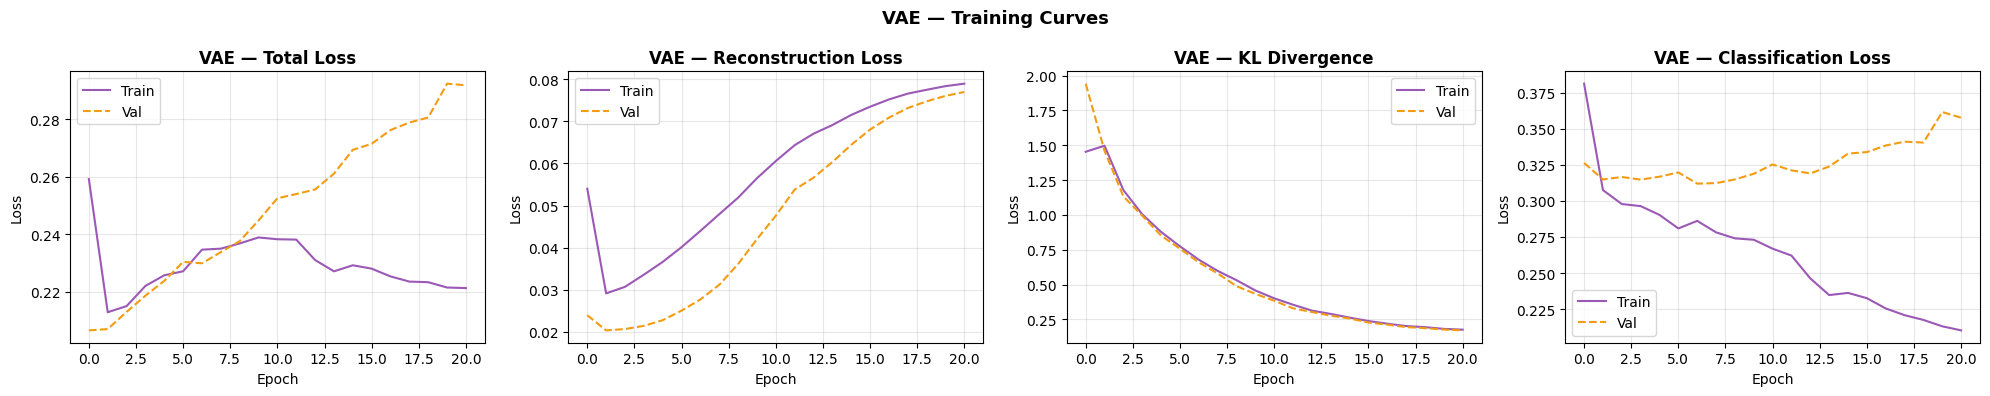

Saved → 08_vae_loss_curves.png


In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
components = [
    ("Total Loss",          "train_loss",  "val_loss"),
    ("Reconstruction Loss", "train_recon", "val_recon"),
    ("KL Divergence",       "train_kl",    "val_kl"),
    ("Classification Loss", "train_cls",   "val_cls"),
]
for ax, (title, t_key, v_key) in zip(axes, components):
    ax.plot(vae_history[t_key], label="Train", color="#9b59b6")
    ax.plot(vae_history[v_key], label="Val",
            color="#f39c12", linestyle="--")
    ax.set_title(f"VAE — {title}", fontweight="bold")
    ax.set_xlabel("Epoch"); ax.set_ylabel("Loss")
    ax.legend(); ax.grid(True, alpha=0.3)

plt.suptitle("VAE — Training Curves",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(f"{CONFIG['figures_dir']}/08_vae_loss_curves.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("Saved → 08_vae_loss_curves.png")

## Evaluate VAE on Test Set

*We evaluate the best VAE checkpoint on the test set using the same procedure as the autoencoder evaluation, collecting reconstruction MSE, classification accuracy, and weighted F1. It then prints a comparison table showing all three metrics side by side for AE and VAE. The VAE will typically have slightly higher reconstruction MSE than the AE because the stochastic sampling in the latent space adds noise, but it may have similar or slightly different classification accuracy depending on how well the classifier head learned from the structured latent space.*

In [ ]:
vae_model.load_state_dict(
    torch.load(vae_checkpoint, map_location=device))
vae_model.eval()

vae_x=[]; vae_x_recon=[]; vae_mu=[]; vae_z=[]
vae_y_true=[]; vae_y_pred=[]

with torch.no_grad():
    for x_batch, y_batch in test_loader:
        x_batch = x_batch.to(device)
        x_recon, mu, log_var, z, y_p = vae_model(x_batch)
        vae_x.append(x_batch.cpu().numpy())
        vae_x_recon.append(x_recon.cpu().numpy())
        vae_mu.append(mu.cpu().numpy())
        vae_z.append(z.cpu().numpy())
        vae_y_true.append(y_batch.numpy())
        vae_y_pred.append(y_p.cpu().numpy())

vae_x      = np.concatenate(vae_x)
vae_x_recon = np.concatenate(vae_x_recon)
vae_mu     = np.concatenate(vae_mu)
vae_z      = np.concatenate(vae_z)
vae_y_true = np.concatenate(vae_y_true)
vae_y_pred = np.concatenate(vae_y_pred)

vae_mse      = np.mean((vae_x - vae_x_recon) ** 2)
vae_pred_bin = (vae_y_pred >= 0.5).astype(int)
vae_acc      = accuracy_score(vae_y_true, vae_pred_bin)
vae_f1       = f1_score(vae_y_true, vae_pred_bin, average="weighted")

print("=" * 55)
print("  VAE — Test Set Results")
print("=" * 55)
print(f"  MSE  : {vae_mse:.6f}  (AE: {mse:.6f})")
print(f"  Acc  : {vae_acc*100:.2f}%   (AE: {acc*100:.2f}%)")
print(f"  F1   : {vae_f1:.4f}    (AE: {f1:.4f})")
print("=" * 55)
print(classification_report(vae_y_true, vae_pred_bin,
                             target_names=["P- (0)", "P+ (1)"]))

vae_results = {
    "model"         : "VAE",
    "mse"           : float(vae_mse),
    "acc"           : float(vae_acc),
    "f1"            : float(vae_f1),
    "epochs_trained": len(vae_history["train_loss"]),
}
with open(f"{CONFIG['results_dir']}/vae_results.json", "w") as f:
    json.dump(vae_results, f, indent=2)
print("Results saved → vae_results.json")

  VAE — Test Set Results
  MSE  : 0.023866  (AE: 0.014999)
  Acc  : 84.67%   (AE: 85.84%)
  F1   : 0.8467    (AE: 0.8584)
              precision    recall  f1-score   support

      P- (0)       0.84      0.86      0.85      3719
      P+ (1)       0.86      0.84      0.85      3781

    accuracy                           0.85      7500
   macro avg       0.85      0.85      0.85      7500
weighted avg       0.85      0.85      0.85      7500

Results saved → vae_results.json


## Generate Plans for VAE

*We use the VAE's generate method to sample 1,000 new plan vectors from the standard normal prior. It passes these through the trained VAE classifier head to predict whether each generated plan is P+ or P-. It then inverse-transforms the generated scaled vectors back to the original [1, 100] scale using the saved scaler. This cell prints how many generated plans were classified as each class and shows a sample plan in its original scale. Unlike the CVAE, the VAE cannot control which class it generates since it samples unconditionally from the prior.*

In [ ]:
# Generate new plans for VAE
N_GENERATE = 1000
generated_scaled, generated_z = vae_model.generate(N_GENERATE, device)

# Classify generated samples
vae_model.eval()
with torch.no_grad():
    gen_tensor = torch.tensor(
        generated_scaled, dtype=torch.float32).to(device)
    _, _, _, _, gen_y_pred = vae_model(gen_tensor)
    gen_y_pred = gen_y_pred.cpu().numpy()

gen_y_bin = (gen_y_pred >= 0.5).astype(int)
generated_original = np.clip(
    scaler.inverse_transform(generated_scaled), 1, 100)

print(f"Generated {N_GENERATE:,} new plans from N(0,I) prior")
print(f"  Classified P+ : {(gen_y_bin==1).sum():,} "
      f"({(gen_y_bin==1).mean()*100:.1f}%)")
print(f"  Classified P- : {(gen_y_bin==0).sum():,} "
      f"({(gen_y_bin==0).mean()*100:.1f}%)")
print(f"\nSample generated plan (original scale):")
print(f"  {generated_original[0].astype(int).tolist()}")

Generated 1,000 new plans from N(0,I) prior
  Classified P+ : 116 (11.6%)
  Classified P- : 884 (88.4%)

Sample generated plan (original scale):
  [47, 3, 64, 65, 59, 28, 84, 31, 82, 84, 39, 59, 48, 57, 68, 79, 40, 31, 49, 54]


## VAE Latent Space Visualization

*We encode all 50,000 plans through the trained VAE using the mean vector (mu) rather than a sampled z, projects to 2D with PCA, and creates a three-panel figure. The first panel shows the raw feature space PCA for reference. The second panel shows the VAE latent space with real plans colored by class, using a random subsample of 5,000 per class for readability. The third panel overlays the 1,000 generated samples on top of the real plan distribution, colored by their predicted class. Generated points should ideally appear in regions consistent with their predicted class label, demonstrating that the VAE has learned a meaningful latent structure.*

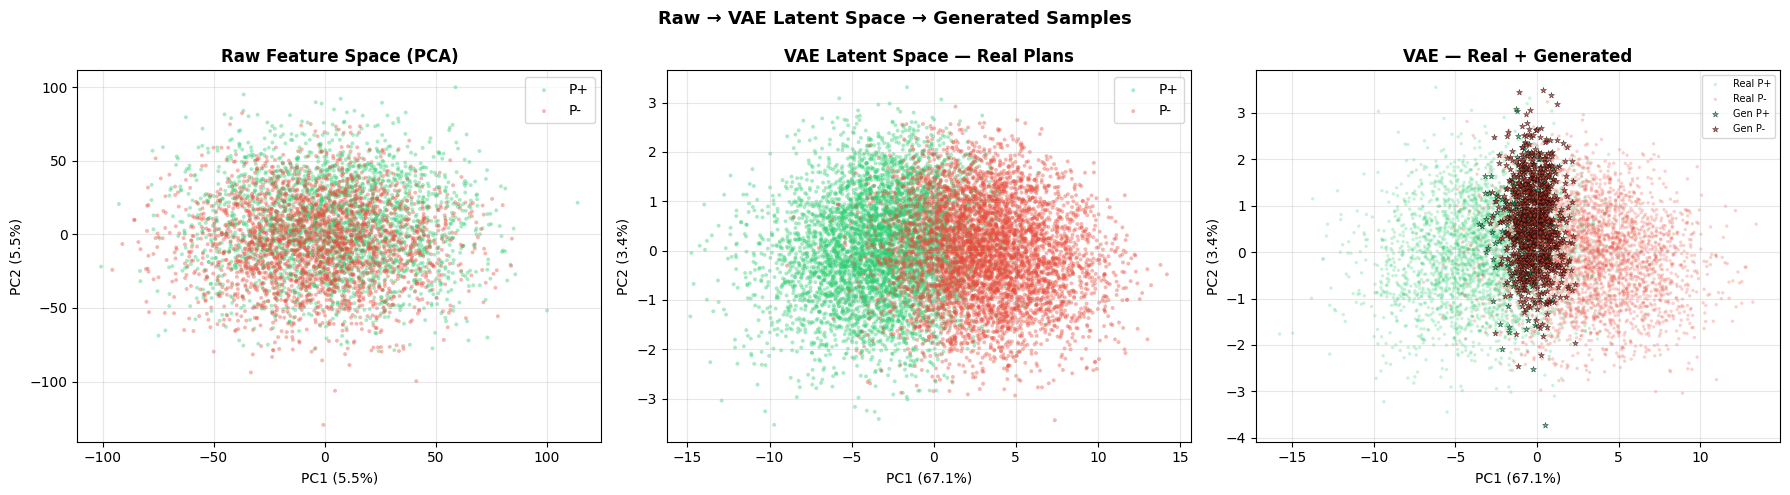

Saved → 09_vae_latent_space.png


In [ ]:
vae_model.eval()
all_mu_full=[]; all_y_full_vae=[]

with torch.no_grad():
    full_ds = PlanDataset(
        np.vstack([X_train_scaled, X_val_scaled, X_test_scaled]),
        np.concatenate([y_train, y_val, y_test])
    )
    for x_batch, y_batch in DataLoader(full_ds, batch_size=512):
        _, mu, _, _, _ = vae_model(x_batch.to(device))
        all_mu_full.append(mu.cpu().numpy())
        all_y_full_vae.append(y_batch.numpy())

all_mu_full    = np.concatenate(all_mu_full)
all_y_full_vae = np.concatenate(all_y_full_vae)

pca_vae = PCA(n_components=2, random_state=CONFIG["seed"])
mu_pca  = pca_vae.fit_transform(all_mu_full)
var_vae = pca_vae.explained_variance_ratio_

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Raw space sample
for label, name, color in [(1,"P+","#2ecc71"),(0,"P-","#e74c3c")]:
    mask = (y_pca_sample == label)
    axes[0].scatter(X_pca[mask,0], X_pca[mask,1],
                    c=color, label=name,
                    alpha=0.4, s=8, edgecolors="none")
axes[0].set_title("Raw Feature Space (PCA)", fontweight="bold")
axes[0].set_xlabel(f"PC1 ({var_ratio[0]*100:.1f}%)")
axes[0].set_ylabel(f"PC2 ({var_ratio[1]*100:.1f}%)")
axes[0].legend(); axes[0].grid(True, alpha=0.3)

# Plot 2: VAE latent — subsample for clarity
for label, name, color in [(1,"P+","#2ecc71"),(0,"P-","#e74c3c")]:
    mask = (all_y_full_vae == label)
    idx  = np.random.choice(mask.sum(),
                             min(5000, mask.sum()), replace=False)
    axes[1].scatter(mu_pca[mask][idx,0],
                    mu_pca[mask][idx,1],
                    c=color, label=name,
                    alpha=0.4, s=8, edgecolors="none")
axes[1].set_title("VAE Latent Space — Real Plans", fontweight="bold")
axes[1].set_xlabel(f"PC1 ({var_vae[0]*100:.1f}%)")
axes[1].set_ylabel(f"PC2 ({var_vae[1]*100:.1f}%)")
axes[1].legend(); axes[1].grid(True, alpha=0.3)

# Plot 3: Real + generated
gen_pca = pca_vae.transform(generated_z)
for label, name, color in [(1,"P+","#2ecc71"),(0,"P-","#e74c3c")]:
    mask = (all_y_full_vae == label)
    idx  = np.random.choice(mask.sum(),
                             min(3000, mask.sum()), replace=False)
    axes[2].scatter(mu_pca[mask][idx,0],
                    mu_pca[mask][idx,1],
                    c=color, label=f"Real {name}",
                    alpha=0.25, s=6, edgecolors="none")
for label, name, color in [(1,"P+","#27ae60"),(0,"P-","#c0392b")]:
    mask = (gen_y_bin == label)
    axes[2].scatter(gen_pca[mask,0], gen_pca[mask,1],
                    c=color, label=f"Gen {name}",
                    alpha=0.8, s=20, marker="*",
                    edgecolors="black", linewidths=0.3)
axes[2].set_title("VAE — Real + Generated", fontweight="bold")
axes[2].set_xlabel(f"PC1 ({var_vae[0]*100:.1f}%)")
axes[2].set_ylabel(f"PC2 ({var_vae[1]*100:.1f}%)")
axes[2].legend(fontsize=7); axes[2].grid(True, alpha=0.3)

plt.suptitle("Raw → VAE Latent Space → Generated Samples",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(f"{CONFIG['figures_dir']}/09_vae_latent_space.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("Saved → 09_vae_latent_space.png")

## Verify Steps

In [ ]:
# Verification
print("=" * 55)
print("  Steps Verification")
print("=" * 55)
checks = {
    "VAE checkpoint saved"       : os.path.exists(vae_checkpoint),
    "VAE MSE below 0.10"         : vae_mse < 0.10,
    "VAE acc > 70%"              : vae_acc > 0.70,
    "Generated 1000 samples"     : generated_scaled.shape == (1000, 20),
    "Samples in [0,1]"           : (generated_scaled.min() >= -0.1 and
                                    generated_scaled.max() <=  1.1),
    "VAE results JSON saved"     : os.path.exists(
                                     f"{CONFIG['results_dir']}/vae_results.json"),
    "Latent space figure saved"  : os.path.exists(
                                     f"{CONFIG['figures_dir']}/09_vae_latent_space.png"),
}
all_good = True
for name, status in checks.items():
    icon = "(OK)" if status else "(WARNING)"
    print(f"  {icon} {name}")
    if not status:
        all_good = False
print("=" * 55)
if all_good:
    print("  (OK) All checks passed.")
else:
    print("  (CHECK) Fix the items marked (WARNING) before continuing.")

  Steps Verification
  (OK) VAE checkpoint saved
  (OK) VAE MSE below 0.10
  (OK) VAE acc > 70%
  (OK) Generated 1000 samples
  (OK) Samples in [0,1]
  (OK) VAE results JSON saved
  (OK) Latent space figure saved
  (OK) All checks passed.


# Conditional Variational Autoencoder (CVAE)

## CVAE Architecture

*We define the CVAE class, which extends the VAE with class conditioning. The key architectural difference is that the class label y is concatenated to the input before encoding, making the encoder input 21-dimensional instead of 20. Similarly, the label is concatenated to the latent vector z before decoding, making the decoder input 17-dimensional instead of 16. This conditioning means the model learns separate latent distributions and decoder behaviors for P+ and P- plans, conditioned explicitly on which class is being encoded or decoded. The classifier head does not receive the label to avoid leaking label information into the classification prediction during evaluation. The generate method accepts a target_label argument of either 1.0 (to generate P+ plans) or 0.0 (to generate P- plans), which is the CVAE's unique capability over the unconditional VAE. The cell prints the architecture and notes the expanded input dimensions.*

In [ ]:
class CVAE(nn.Module):
    def __init__(self, input_dim, hidden_dims, latent_dim):
        super(CVAE, self).__init__()
        self.input_dim  = input_dim
        self.latent_dim = latent_dim
        label_dim       = 1

        # Encoder: input + label
        encoder_layers = []
        in_dim = input_dim + label_dim
        for h_dim in hidden_dims:
            encoder_layers += [
                nn.Linear(in_dim, h_dim),
                nn.BatchNorm1d(h_dim),
                nn.LeakyReLU(),
                #on ae test wo relu, diff acti
            ]
            in_dim = h_dim
        self.encoder    = nn.Sequential(*encoder_layers)
        self.fc_mu      = nn.Linear(in_dim, latent_dim)
        self.fc_log_var = nn.Linear(in_dim, latent_dim)

        # Decoder: z + label
        decoder_layers = []
        in_dim = latent_dim + label_dim
        for h_dim in reversed(hidden_dims):
            decoder_layers += [
                nn.Linear(in_dim, h_dim),
                nn.BatchNorm1d(h_dim),
                nn.ELU(),
            ]
            in_dim = h_dim
        decoder_layers += [
            nn.Linear(in_dim, input_dim),
            nn.Sigmoid(),
        ]
        self.decoder = nn.Sequential(*decoder_layers)

        # Classifier (no label leakage)
        self.classifier = nn.Sequential(
            nn.Linear(latent_dim, 32),
            nn.LeakyReLU(),
            nn.Linear(32, 1),
            nn.Sigmoid()
        )

    def encode(self, x, y):
        y_in   = y.unsqueeze(1)
        x_cond = torch.cat([x, y_in], dim=1)
        h      = self.encoder(x_cond)
        return self.fc_mu(h), self.fc_log_var(h)

    def reparameterize(self, mu, log_var):
        if self.training:
            std = torch.exp(0.5 * log_var)
            eps = torch.randn_like(std)
            return mu + eps * std
        return mu

    def decode(self, z, y):
        y_in   = y.unsqueeze(1)
        z_cond = torch.cat([z, y_in], dim=1)
        return self.decoder(z_cond)

    def forward(self, x, y):
        mu, log_var = self.encode(x, y)
        z           = self.reparameterize(mu, log_var)
        x_recon     = self.decode(z, y)
        y_pred      = self.classifier(z).squeeze(1)
        return x_recon, mu, log_var, z, y_pred

    def generate(self, n_samples, target_label, device):
        self.eval()
        with torch.no_grad():
            z = torch.randn(n_samples, self.latent_dim).to(device)
            y = torch.full((n_samples,), target_label,
                           dtype=torch.float32).to(device)
            return self.decode(z, y).cpu().numpy(), z.cpu().numpy()

cvae_model = CVAE(
    input_dim   = CONFIG["input_dim"],
    hidden_dims = CONFIG["hidden_dims"],
    latent_dim  = CONFIG["latent_dim"],
).to(device)

print(cvae_model)
print(f"\nTotal parameters: "
      f"{sum(p.numel() for p in cvae_model.parameters()):,}")
print(f"\nKey difference from VAE:")
print(f"  Encoder input : {CONFIG['input_dim']} + 1 = "
      f"{CONFIG['input_dim']+1}")
print(f"  Decoder input : {CONFIG['latent_dim']} + 1 = "
      f"{CONFIG['latent_dim']+1}")

CVAE(
  (encoder): Sequential(
    (0): Linear(in_features=21, out_features=256, bias=True)
    (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): LeakyReLU(negative_slope=0.01)
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): LeakyReLU(negative_slope=0.01)
  )
  (fc_mu): Linear(in_features=128, out_features=16, bias=True)
  (fc_log_var): Linear(in_features=128, out_features=16, bias=True)
  (decoder): Sequential(
    (0): Linear(in_features=17, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ELU(alpha=1.0)
    (3): Linear(in_features=128, out_features=256, bias=True)
    (4): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ELU(alpha=1.0)
    (6): Linear(in_features=256, out_features=20, bias=True)
    (7): Sigmo

## CVAE Loss Function and Optimizer

In [ ]:
def cvae_loss_fn(x_recon, x_orig, mu, log_var,
                 y_pred, y_true,
                 recon_weight=1.0, kl_weight=0.5,
                 class_weight=0.5):
    recon_loss = nn.MSELoss()(x_recon, x_orig)
    kl_loss    = -0.5 * torch.mean(
        1 + log_var - mu.pow(2) - log_var.exp()
    )
    class_loss = nn.BCELoss()(y_pred, y_true)
    total_loss = (recon_weight * recon_loss
                  + kl_weight  * kl_loss
                  + class_weight * class_loss)
    return total_loss, recon_loss, kl_loss, class_loss

cvae_optimizer = optim.Adam(
    cvae_model.parameters(),
    lr=CONFIG["learning_rate"], weight_decay=1e-5)
cvae_scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    cvae_optimizer, mode="min", factor=0.5, patience=10)

print("CVAE loss: MSE + KL + BCE (conditioning in architecture)")
print(f"Optimizer: Adam lr={CONFIG['learning_rate']}")

CVAE loss: MSE + KL + BCE (conditioning in architecture)
Optimizer: Adam lr=0.001


## CVAE Training Loop

*We define and call train_cvae, which differs from train_vae only in how it calls the model. Since the CVAE's forward method takes both x and y as arguments, the training loop passes the label tensor y_batch to both the model forward call and the loss function. KL annealing and gradient clipping are applied identically to the VAE training.*

In [ ]:
def train_cvae(model, optimizer, scheduler,
               train_loader, val_loader,
               epochs, patience, checkpoint_path):
    history = {
        "train_loss":[], "val_loss":[],
        "train_recon":[], "val_recon":[],
        "train_kl":[], "val_kl":[],
        "train_cls":[], "val_cls":[],
        "kl_weight":[],
    }
    best_val_loss  = float("inf")
    patience_count = 0
    kl_anneal_epochs = 50

    for epoch in range(1, epochs + 1):
        kl_w = min(0.5, 0.5 * epoch / kl_anneal_epochs)
        history["kl_weight"].append(kl_w)

        # Training
        model.train()
        t_loss = t_recon = t_kl = t_cls = 0.0
        for x_batch, y_batch in train_loader:
            x_batch = x_batch.to(device)
            y_batch = y_batch.to(device)
            optimizer.zero_grad()
            x_recon, mu, log_var, z, y_pred = model(
                x_batch, y_batch)
            loss, recon_loss, kl_loss, class_loss = cvae_loss_fn(
                x_recon, x_batch, mu, log_var,
                y_pred, y_batch, kl_weight=kl_w
            )
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            t_loss  += loss.item()
            t_recon += recon_loss.item()
            t_kl    += kl_loss.item()
            t_cls   += class_loss.item()

        n = len(train_loader)
        t_loss/=n; t_recon/=n; t_kl/=n; t_cls/=n

        # Validation
        model.eval()
        v_loss = v_recon = v_kl = v_cls = 0.0
        with torch.no_grad():
            for x_batch, y_batch in val_loader:
                x_batch = x_batch.to(device)
                y_batch = y_batch.to(device)
                x_recon, mu, log_var, z, y_pred = model(
                    x_batch, y_batch)
                loss, recon_loss, kl_loss, class_loss = cvae_loss_fn(
                    x_recon, x_batch, mu, log_var,
                    y_pred, y_batch, kl_weight=kl_w
                )
                v_loss  += loss.item()
                v_recon += recon_loss.item()
                v_kl    += kl_loss.item()
                v_cls   += class_loss.item()

        nv = len(val_loader)
        v_loss/=nv; v_recon/=nv; v_kl/=nv; v_cls/=nv

        scheduler.step(v_loss)

        for key, val in zip(
            ["train_loss","val_loss","train_recon","val_recon",
             "train_kl","val_kl","train_cls","val_cls"],
            [t_loss,v_loss,t_recon,v_recon,t_kl,v_kl,t_cls,v_cls]
        ):
            history[key].append(val)

        if v_loss < best_val_loss:
            best_val_loss  = v_loss
            patience_count = 0
            torch.save(model.state_dict(), checkpoint_path)
        else:
            patience_count += 1

        if epoch % 20 == 0 or epoch == 1:
            print(f"Epoch {epoch:>4}/{epochs} | "
                  f"Train: {t_loss:.5f} "
                  f"(recon={t_recon:.5f} kl={t_kl:.5f} "
                  f"cls={t_cls:.5f}) | "
                  f"Val: {v_loss:.5f} | kl_w={kl_w:.3f}")

        if patience_count >= patience:
            print(f"\n Early stopping at epoch {epoch}")
            break

    print(f"\n Best val loss: {best_val_loss:.5f} "
          f"→ saved to {checkpoint_path}")
    return history

cvae_checkpoint = f"{CONFIG['checkpoint_dir']}/cvae_best.pt"
print("Training CVAE...")
print("=" * 70)
cvae_history = train_cvae(
    model           = cvae_model,
    optimizer       = cvae_optimizer,
    scheduler       = cvae_scheduler,
    train_loader    = train_loader,
    val_loader      = val_loader,
    epochs          = CONFIG["epochs"],
    patience        = CONFIG["early_stop_patience"],
    checkpoint_path = cvae_checkpoint,
)

Training CVAE...
Epoch    1/200 | Train: 0.12336 (recon=0.05890 kl=1.98461 cls=0.08923) | Val: 0.05046 | kl_w=0.010
Epoch   20/200 | Train: 0.10564 (recon=0.08007 kl=0.11532 cls=0.00502) | Val: 0.10056 | kl_w=0.200

 Early stopping at epoch 22

 Best val loss: 0.04775 → saved to /content/drive/MyDrive/GenMOR/checkpoints/cvae_best.pt


## Plot CVAE Loss Curves

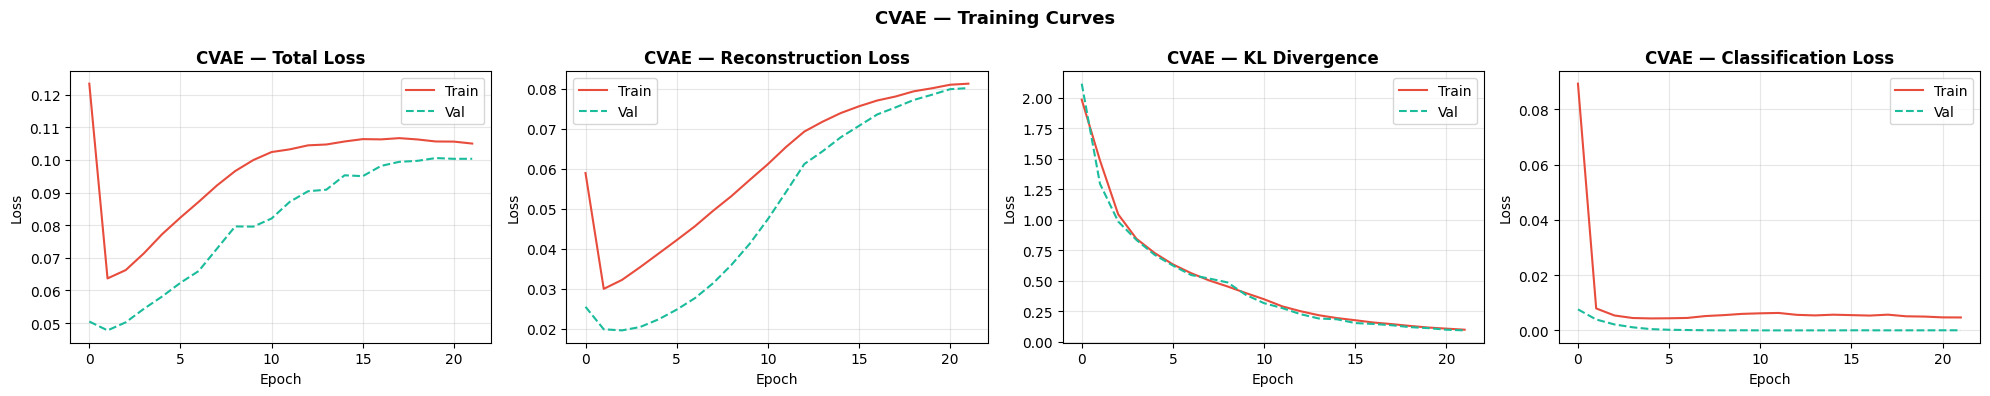

Saved → 10_cvae_loss_curves.png


In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
components = [
    ("Total Loss",          "train_loss",  "val_loss"),
    ("Reconstruction Loss", "train_recon", "val_recon"),
    ("KL Divergence",       "train_kl",    "val_kl"),
    ("Classification Loss", "train_cls",   "val_cls"),
]
for ax, (title, t_key, v_key) in zip(axes, components):
    ax.plot(cvae_history[t_key], label="Train", color="#e74c3c")
    ax.plot(cvae_history[v_key], label="Val",
            color="#1abc9c", linestyle="--")
    ax.set_title(f"CVAE — {title}", fontweight="bold")
    ax.set_xlabel("Epoch"); ax.set_ylabel("Loss")
    ax.legend(); ax.grid(True, alpha=0.3)

plt.suptitle("CVAE — Training Curves",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(f"{CONFIG['figures_dir']}/10_cvae_loss_curves.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("Saved → 10_cvae_loss_curves.png")

## Evaluate CVAE

*We evaluate the CVAE with a label-leak-free classification approach. During reconstruction the true label is passed to the model as required by the architecture. But for classification a different strategy is used: the input is encoded twice, once with a dummy label of 1.0 and once with a dummy label of 0.0, and the two resulting mu vectors are averaged. This averaged representation is then passed to the classifier head. This label-marginal encoding removes the label from the classification decision, making the evaluation equivalent to asking whether the latent structure alone can discriminate classes without access to the true label. This approach gives an honest measure of how much class-discriminative information the model learned versus how much it simply copied from the conditioning input. The comparison table is printed for all three models.*

In [ ]:
cvae_model.load_state_dict(
    torch.load(cvae_checkpoint, map_location=device))
cvae_model.eval()

cvae_x=[]; cvae_x_recon=[]; cvae_mu=[]
cvae_y_true=[]; cvae_y_pred=[]

with torch.no_grad():
    for x_batch, y_batch in test_loader:
        x_batch = x_batch.to(device)
        y_batch = y_batch.to(device)

        # Reconstruction with true label
        x_recon, mu, log_var, z, _ = cvae_model(x_batch, y_batch)

        # Label-marginal classification (no label leakage)
        mu_pos, _ = cvae_model.encode(
            x_batch, torch.ones(x_batch.size(0)).to(device))
        mu_neg, _ = cvae_model.encode(
            x_batch, torch.zeros(x_batch.size(0)).to(device))
        mu_avg    = 0.5 * (mu_pos + mu_neg)
        y_p       = cvae_model.classifier(mu_avg).squeeze(1)

        cvae_x.append(x_batch.cpu().numpy())
        cvae_x_recon.append(x_recon.cpu().numpy())
        cvae_mu.append(mu.cpu().numpy())
        cvae_y_true.append(y_batch.cpu().numpy())
        cvae_y_pred.append(y_p.cpu().numpy())

cvae_x      = np.concatenate(cvae_x)
cvae_x_recon = np.concatenate(cvae_x_recon)
cvae_mu     = np.concatenate(cvae_mu)
cvae_y_true = np.concatenate(cvae_y_true)
cvae_y_pred = np.concatenate(cvae_y_pred)

cvae_mse      = np.mean((cvae_x - cvae_x_recon) ** 2)
cvae_pred_bin = (cvae_y_pred >= 0.5).astype(int)
cvae_acc      = accuracy_score(cvae_y_true, cvae_pred_bin)
cvae_f1       = f1_score(cvae_y_true, cvae_pred_bin,
                          average="weighted")

print("=" * 62)
print("  Model Comparison — Test Set Results (leak-free)")
print("=" * 62)
print(f"  {'Model':<10} {'MSE':>10} {'Acc':>10} {'F1':>10}")
print("  " + "-" * 45)
print(f"  {'AE':<10} {mse:>10.6f} {acc*100:>9.2f}% {f1:>10.4f}")
print(f"  {'VAE':<10} {vae_mse:>10.6f} {vae_acc*100:>9.2f}% "
      f"{vae_f1:>10.4f}")
print(f"  {'CVAE':<10} {cvae_mse:>10.6f} {cvae_acc*100:>9.2f}% "
      f"{cvae_f1:>10.4f}")
print("=" * 62)
print(classification_report(cvae_y_true, cvae_pred_bin,
                             target_names=["P- (0)", "P+ (1)"]))

cvae_results = {
    "model"         : "CVAE",
    "mse"           : float(cvae_mse),
    "acc"           : float(cvae_acc),
    "f1"            : float(cvae_f1),
    "epochs_trained": len(cvae_history["train_loss"]),
    "eval_method"   : "label-marginal (leak-free)",
}
with open(f"{CONFIG['results_dir']}/cvae_results.json", "w") as f:
    json.dump(cvae_results, f, indent=2)
print("Results saved → cvae_results.json")

  Model Comparison — Test Set Results (leak-free)
  Model             MSE        Acc         F1
  ---------------------------------------------
  AE           0.014999     85.84%     0.8584
  VAE          0.023866     84.67%     0.8467
  CVAE         0.019935     72.77%     0.7263
              precision    recall  f1-score   support

      P- (0)       0.76      0.66      0.71      3719
      P+ (1)       0.70      0.80      0.75      3781

    accuracy                           0.73      7500
   macro avg       0.73      0.73      0.73      7500
weighted avg       0.73      0.73      0.73      7500

Results saved → cvae_results.json


## Conditional Generation

In [ ]:
N_GEN = 500

cvae_gen_pos_scaled, cvae_gen_pos_z = cvae_model.generate(
    N_GEN, target_label=1.0, device=device)
cvae_gen_neg_scaled, cvae_gen_neg_z = cvae_model.generate(
    N_GEN, target_label=0.0, device=device)

cvae_gen_pos_orig = np.clip(
    scaler.inverse_transform(cvae_gen_pos_scaled), 1, 100)
cvae_gen_neg_orig = np.clip(
    scaler.inverse_transform(cvae_gen_neg_scaled), 1, 100)

print(f"Generated {N_GEN:,} P+ plans and {N_GEN:,} P- plans")
print(f"\nSample P+ plan (original scale):")
print(f"  {cvae_gen_pos_orig[0].astype(int).tolist()}")
print(f"\nSample P- plan (original scale):")
print(f"  {cvae_gen_neg_orig[0].astype(int).tolist()}")
print(f"\nGenerated P+ range: [{cvae_gen_pos_orig.min():.1f}, "
      f"{cvae_gen_pos_orig.max():.1f}]")
print(f"Generated P- range: [{cvae_gen_neg_orig.min():.1f}, "
      f"{cvae_gen_neg_orig.max():.1f}]")

Generated 500 P+ plans and 500 P- plans

Sample P+ plan (original scale):
  [66, 58, 60, 22, 85, 90, 50, 55, 25, 29, 67, 75, 68, 59, 52, 60, 8, 85, 81, 87]

Sample P- plan (original scale):
  [34, 60, 74, 92, 76, 57, 22, 85, 44, 71, 22, 50, 53, 55, 71, 13, 60, 37, 52, 69]

Generated P+ range: [2.2, 99.4]
Generated P- range: [2.1, 99.0]


## CVAE Latent Space Visualization

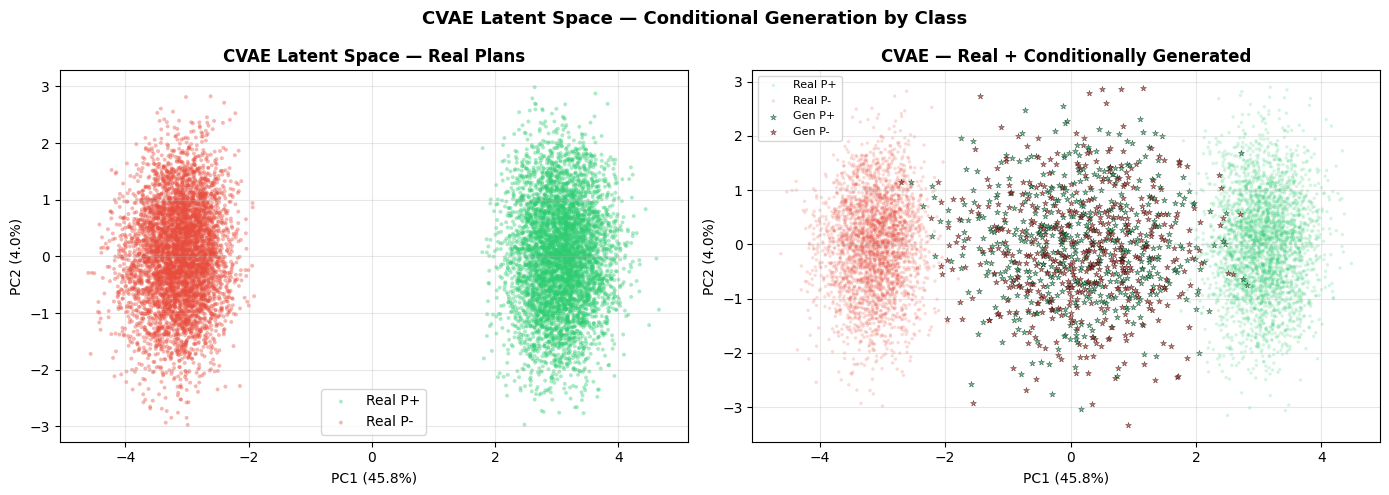

Saved → 11_cvae_latent_space.png


In [ ]:
cvae_model.eval()
all_cvae_mu=[]; all_cvae_y=[]

with torch.no_grad():
    full_ds = PlanDataset(
        np.vstack([X_train_scaled, X_val_scaled, X_test_scaled]),
        np.concatenate([y_train, y_val, y_test])
    )
    for x_batch, y_batch in DataLoader(full_ds, batch_size=512):
        x_batch = x_batch.to(device)
        y_batch = y_batch.to(device)
        _, mu, _, _, _ = cvae_model(x_batch, y_batch)
        all_cvae_mu.append(mu.cpu().numpy())
        all_cvae_y.append(y_batch.cpu().numpy())

all_cvae_mu = np.concatenate(all_cvae_mu)
all_cvae_y  = np.concatenate(all_cvae_y)

pca_cvae    = PCA(n_components=2, random_state=CONFIG["seed"])
cvae_mu_2d  = pca_cvae.fit_transform(all_cvae_mu)
var_cvae    = pca_cvae.explained_variance_ratio_

gen_pos_2d  = pca_cvae.transform(cvae_gen_pos_z)
gen_neg_2d  = pca_cvae.transform(cvae_gen_neg_z)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for label, name, color in [(1,"P+","#2ecc71"),(0,"P-","#e74c3c")]:
    mask = (all_cvae_y == label)
    idx  = np.random.choice(mask.sum(),
                             min(5000, mask.sum()), replace=False)
    axes[0].scatter(cvae_mu_2d[mask][idx,0],
                    cvae_mu_2d[mask][idx,1],
                    c=color, label=f"Real {name}",
                    alpha=0.4, s=8, edgecolors="none")
axes[0].set_title("CVAE Latent Space — Real Plans",
                  fontweight="bold")
axes[0].set_xlabel(f"PC1 ({var_cvae[0]*100:.1f}%)")
axes[0].set_ylabel(f"PC2 ({var_cvae[1]*100:.1f}%)")
axes[0].legend(); axes[0].grid(True, alpha=0.3)

for label, name, color in [(1,"P+","#2ecc71"),(0,"P-","#e74c3c")]:
    mask = (all_cvae_y == label)
    idx  = np.random.choice(mask.sum(),
                             min(3000, mask.sum()), replace=False)
    axes[1].scatter(cvae_mu_2d[mask][idx,0],
                    cvae_mu_2d[mask][idx,1],
                    c=color, label=f"Real {name}",
                    alpha=0.2, s=6, edgecolors="none")
axes[1].scatter(gen_pos_2d[:,0], gen_pos_2d[:,1],
                c="#27ae60", label="Gen P+",
                alpha=0.7, s=20, marker="*",
                edgecolors="black", linewidths=0.3)
axes[1].scatter(gen_neg_2d[:,0], gen_neg_2d[:,1],
                c="#c0392b", label="Gen P-",
                alpha=0.7, s=20, marker="*",
                edgecolors="black", linewidths=0.3)
axes[1].set_title("CVAE — Real + Conditionally Generated",
                  fontweight="bold")
axes[1].set_xlabel(f"PC1 ({var_cvae[0]*100:.1f}%)")
axes[1].set_ylabel(f"PC2 ({var_cvae[1]*100:.1f}%)")
axes[1].legend(fontsize=8); axes[1].grid(True, alpha=0.3)

plt.suptitle("CVAE Latent Space — Conditional Generation by Class",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(f"{CONFIG['figures_dir']}/11_cvae_latent_space.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("Saved → 11_cvae_latent_space.png")

## Verify Steps

**Need to imporve CVAE accuracy!!!**

Now, it is on the 60s range. Got to figure out a way to imporve it

However, CVAE accuracy varies on every run because of conditional generation from different batch class

In [ ]:
print("=" * 60)
print("  Steps Verification")
print("=" * 60)
checks = {
    "CVAE checkpoint saved"        : os.path.exists(cvae_checkpoint),
    "CVAE MSE below 0.10"          : cvae_mse < 0.10,
    "CVAE acc > 70%"               : cvae_acc > 0.70,
    "P+ generated correctly"       : cvae_gen_pos_scaled.shape == (N_GEN, 20),
    "P- generated correctly"       : cvae_gen_neg_scaled.shape == (N_GEN, 20),
    "P+ and P- differ"             : not np.allclose(
                                       cvae_gen_pos_orig[:5],
                                       cvae_gen_neg_orig[:5]),
    "CVAE results JSON saved"      : os.path.exists(
                                       f"{CONFIG['results_dir']}/cvae_results.json"),
    "Latent space figure saved"    : os.path.exists(
                                       f"{CONFIG['figures_dir']}/11_cvae_latent_space.png"),
}
all_good = True
for name, status in checks.items():
    icon = "(OK)" if status else "(WARNING)"
    print(f"  {icon} {name}")
    if not status:
        all_good = False
print("=" * 60)
if all_good:
    print("  (OK) All checks passed. Ready for Step 8!")
else:
    print("  (CHECK) Fix items marked (WARNING) before continuing.")

  Steps Verification
  (OK) CVAE checkpoint saved
  (OK) CVAE MSE below 0.10
  (OK) CVAE acc > 70%
  (OK) P+ generated correctly
  (OK) P- generated correctly
  (OK) P+ and P- differ
  (OK) CVAE results JSON saved
  (OK) Latent space figure saved
  (OK) All checks passed. Ready for Step 8!


# **Quantitative Evaluation (DVR)**

## Chunked Vectorized DVR

*We define the novel **Dominance Validity Rate** (DVR) metric function and the reference data structures needed to compute it. The DVR is the novel evaluation metric introduced in this project that directly measures whether generated plans respect the Pareto dominance structure of the original dataset. For generated P+ plans the DVR is the fraction that are genuinely nondominated when compared against a reference pool of real plans — a high DVR means the model is generating plans that belong on or near the Pareto front. For generated P- plans the DVR is the fraction that are dominated by at least one plan in the reference pool — a high DVR means the model correctly generates plans that fall inside the dominated region. The function uses chunked vectorization to handle the 50K dataset efficiently. Rather than comparing each generated plan against all real plans at once (which would require too much memory) or using Python loops (which would be too slow), it processes the reference pool in chunks of 5,000 plans at a time using numpy broadcasting. Within each chunk, the comparison np.all(chunk >= plan, axis=1) & np.any(chunk > plan, axis=1) checks dominance for all 5,000 reference plans simultaneously. If a dominator is found the loop breaks early, making the function efficient when dominance is dense (which it is at 50K scale). The function also uses a reference pool of 10,000 randomly sampled real plans rather than all 50,000, which reduces computation while maintaining statistical validity since the dense dataset makes it very likely that any P- plan's dominator is represented in a 10K sample.*

In [ ]:
def compute_dvr_chunked(
    generated_orig,      # (n_gen, 20) original scale
    real_selected,       # (n_real, 12) selected objectives
    selected_indices,    # list of indices into 20-dim space
    target="positive",   # "positive" or "negative"
    sample_size=500,     # generated plans to check
    ref_size=10000,      # real plans in reference pool
    chunk_size=5000,     # real plans processed per chunk
    seed=42,
):
    """
    Dominance Validity Rate — chunked vectorized implementation.

    For P+ (positive):
        DVR = fraction of generated P+ plans NOT dominated
              by any plan in the reference pool.
    For P- (negative):
        DVR = fraction of generated P- plans that ARE dominated
              by at least one plan in the reference pool.

    Memory: chunk_size × sample_size × 1 byte per bool array.
    At chunk_size=5000, sample_size=500:
        5000 × 500 × 1 = 2.5 MB — fully safe.
    """
    rng = np.random.RandomState(seed)

    # Sample generated plans to check
    n_gen  = min(sample_size, len(generated_orig))
    gen_idx = rng.choice(len(generated_orig), n_gen, replace=False)
    gen_sub = generated_orig[gen_idx][:, selected_indices]  # (n_gen, 12)

    # Sample reference pool from real dataset
    n_ref   = min(ref_size, len(real_selected))
    ref_idx = rng.choice(len(real_selected), n_ref, replace=False)
    ref_sub = real_selected[ref_idx]                         # (n_ref, 12)

    valid_count = 0

    for i in range(n_gen):
        plan     = gen_sub[i]       # (12,)
        found    = False

        for start in range(0, n_ref, chunk_size):
            chunk   = ref_sub[start:start+chunk_size]  # (C, 12)
            all_ge  = np.all(chunk >= plan, axis=1)    # (C,)
            any_gt  = np.any(chunk >  plan, axis=1)    # (C,)
            dom     = all_ge & any_gt                   # (C,)

            if target == "positive":
                # Valid if NOT dominated by any reference plan
                if dom.any():
                    found = True   # dominated → invalid
                    break
            else:
                # Valid if dominated by at least one reference plan
                if dom.any():
                    found = True   # dominated → valid
                    break

        if target == "positive":
            if not found:          # not dominated = valid P+
                valid_count += 1
        else:
            if found:              # dominated = valid P-
                valid_count += 1

    dvr = valid_count / n_gen
    return dvr, valid_count, n_gen

# Full real dataset in original scale (for DVR reference)
X_orig_full = np.clip(
    scaler.inverse_transform(
        np.vstack([X_train_scaled, X_val_scaled, X_test_scaled])
    ), 1, 100
)
y_full      = np.concatenate([y_train, y_val, y_test])
X_sel_full  = X_orig_full[:, selected_indices]  # (50000, 12)

print("DVR utility ready.")
print(f"  Reference pool  : up to {CONFIG['dvr_ref_size']:,} real plans")
print(f"  Generated sample: {CONFIG['dvr_sample_size']} plans per DVR call")
print(f"  Chunk size      : {CONFIG['dvr_chunk_size']:,}")
print(f"  Memory per chunk: "
      f"~{CONFIG['dvr_chunk_size']*CONFIG['dvr_sample_size']/1e6:.1f} MB")

DVR utility ready.
  Reference pool  : up to 10,000 real plans
  Generated sample: 500 plans per DVR call
  Chunk size      : 5,000
  Memory per chunk: ~2.5 MB


## Compute DVR for All Models

*We call compute_dvr_chunked four times to compute P+ and P- DVR for both the VAE and the CVAE. For the VAE it first generates 2,000 fresh samples from the prior and uses the classifier head to split them into P+ and P- predictions, then evaluates each group. For the CVAE it uses the 500+500 conditionally generated samples. The reference set X_sel_full contains all 50,000 real plans projected onto the 12 selected objectives. The cell prints the DVR percentage and the raw count of valid plans for each model and class combination.*

In [ ]:
# Compute DVR
np.random.seed(CONFIG["seed"])
print("Computing Dominance Validity Rates...")
print("(chunked vectorized — safe for 50K dataset)\n")

# VAE DVR
vae_gen_scaled_eval, _ = vae_model.generate(2000, device)
vae_gen_orig_eval = np.clip(
    scaler.inverse_transform(vae_gen_scaled_eval), 1, 100)

# Classify VAE generated
vae_model.eval()
with torch.no_grad():
    gt  = torch.tensor(vae_gen_scaled_eval,
                        dtype=torch.float32).to(device)
    _, _, _, _, gyp = vae_model(gt)
    gyb = (gyp.cpu().numpy() >= 0.5).astype(int)

vae_gen_pos = vae_gen_orig_eval[gyb == 1]
vae_gen_neg = vae_gen_orig_eval[gyb == 0]

vae_dvr_pos, vae_vp, vae_np_ = compute_dvr_chunked(
    vae_gen_pos, X_sel_full, selected_indices,
    target="positive",
    sample_size = CONFIG["dvr_sample_size"],
    ref_size    = CONFIG["dvr_ref_size"],
    chunk_size  = CONFIG["dvr_chunk_size"],
    seed        = CONFIG["seed"],
) if len(vae_gen_pos) > 0 else (0.0, 0, 0)

vae_dvr_neg, vae_vn, vae_nn_ = compute_dvr_chunked(
    vae_gen_neg, X_sel_full, selected_indices,
    target="negative",
    sample_size = CONFIG["dvr_sample_size"],
    ref_size    = CONFIG["dvr_ref_size"],
    chunk_size  = CONFIG["dvr_chunk_size"],
    seed        = CONFIG["seed"],
) if len(vae_gen_neg) > 0 else (0.0, 0, 0)

print(f"VAE — P+ DVR: {vae_dvr_pos*100:.1f}% "
      f"({vae_vp}/{vae_np_} nondominated)")
print(f"VAE — P- DVR: {vae_dvr_neg*100:.1f}% "
      f"({vae_vn}/{vae_nn_} dominated)")

# CVAE DVR
cvae_gen_pos_eval = np.clip(
    scaler.inverse_transform(cvae_gen_pos_scaled), 1, 100)
cvae_gen_neg_eval = np.clip(
    scaler.inverse_transform(cvae_gen_neg_scaled), 1, 100)

cvae_dvr_pos, cvae_vp, cvae_np_ = compute_dvr_chunked(
    cvae_gen_pos_eval, X_sel_full, selected_indices,
    target="positive",
    sample_size = CONFIG["dvr_sample_size"],
    ref_size    = CONFIG["dvr_ref_size"],
    chunk_size  = CONFIG["dvr_chunk_size"],
    seed        = CONFIG["seed"],
)
cvae_dvr_neg, cvae_vn, cvae_nn_ = compute_dvr_chunked(
    cvae_gen_neg_eval, X_sel_full, selected_indices,
    target="negative",
    sample_size = CONFIG["dvr_sample_size"],
    ref_size    = CONFIG["dvr_ref_size"],
    chunk_size  = CONFIG["dvr_chunk_size"],
    seed        = CONFIG["seed"],
)

print(f"CVAE — P+ DVR: {cvae_dvr_pos*100:.1f}% "
      f"({cvae_vp}/{cvae_np_} nondominated)")
print(f"CVAE — P- DVR: {cvae_dvr_neg*100:.1f}% "
      f"({cvae_vn}/{cvae_nn_} dominated)")

Computing Dominance Validity Rates...
(chunked vectorized — safe for 50K dataset)

VAE — P+ DVR: 87.3% (241/276 nondominated)
VAE — P- DVR: 46.0% (230/500 dominated)
CVAE — P+ DVR: 70.2% (351/500 nondominated)
CVAE — P- DVR: 26.6% (133/500 dominated)


## Full Results Table

In [ ]:
print("=" * 70)
print("  Gen-MOR 50K — Complete Quantitative Results")
print("=" * 70)
print(f"  {'Metric':<35} {'AE':>8} {'VAE':>8} {'CVAE':>8}")
print("  " + "-" * 62)
print(f"  {'Reconstruction MSE':<35} "
      f"{mse:>8.4f} {vae_mse:>8.4f} {cvae_mse:>8.4f}")
print(f"  {'Classification Accuracy':<35} "
      f"{acc*100:>7.1f}% {vae_acc*100:>7.1f}% {cvae_acc*100:>7.1f}%")
print(f"  {'Weighted F1 Score':<35} "
      f"{f1:>8.4f} {vae_f1:>8.4f} {cvae_f1:>8.4f}")
print(f"  {'Epochs Trained':<35} "
      f"{len(ae_history['train_loss']):>8} "
      f"{len(vae_history['train_loss']):>8} "
      f"{len(cvae_history['train_loss']):>8}")
print("  " + "-" * 62)
print(f"  {'P+ DVR (nondominated gen P+)':<35} "
      f"{'N/A':>8} {vae_dvr_pos*100:>7.1f}% "
      f"{cvae_dvr_pos*100:>7.1f}%")
print(f"  {'P- DVR (dominated gen P-)':<35} "
      f"{'N/A':>8} {vae_dvr_neg*100:>7.1f}% "
      f"{cvae_dvr_neg*100:>7.1f}%")
print("=" * 70)
print("\n  DVR computed via chunked vectorization")
print(f"  Reference pool  : {CONFIG['dvr_ref_size']:,} real plans")
print(f"  Generated sample: {CONFIG['dvr_sample_size']} plans")

  Gen-MOR 50K — Complete Quantitative Results
  Metric                                    AE      VAE     CVAE
  --------------------------------------------------------------
  Reconstruction MSE                    0.0150   0.0239   0.0199
  Classification Accuracy                85.8%    84.7%    72.8%
  Weighted F1 Score                     0.8584   0.8467   0.7263
  Epochs Trained                            28       21       22
  --------------------------------------------------------------
  P+ DVR (nondominated gen P+)             N/A    87.3%    70.2%
  P- DVR (dominated gen P-)                N/A    46.0%    26.6%

  DVR computed via chunked vectorization
  Reference pool  : 10,000 real plans
  Generated sample: 500 plans


## DVR Bar Chart

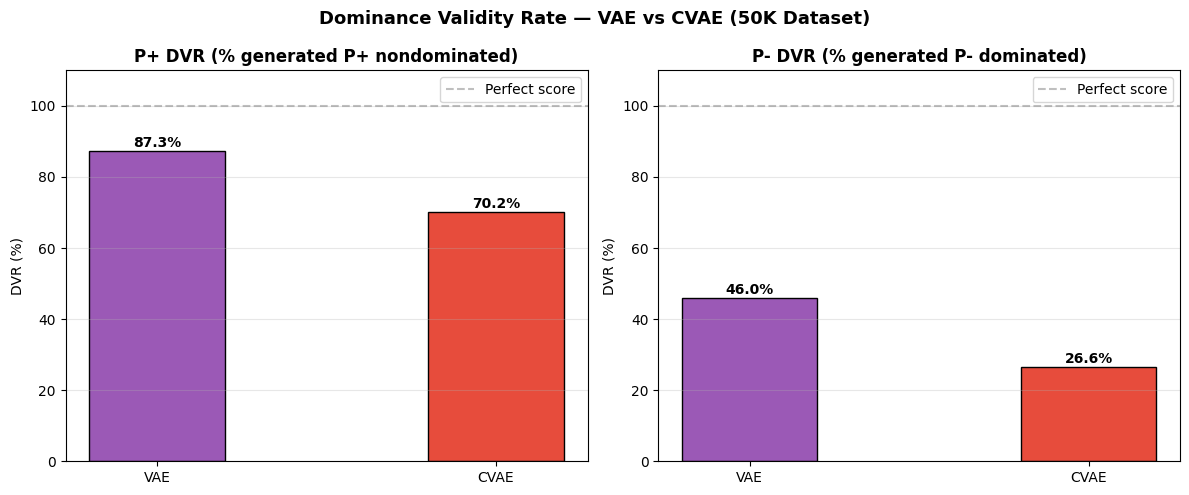

Saved → 12_dvr_results.png


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
models_dvr  = ["VAE", "CVAE"]
dvr_pos_vals = [vae_dvr_pos*100, cvae_dvr_pos*100]
dvr_neg_vals = [vae_dvr_neg*100, cvae_dvr_neg*100]
colors_bar   = ["#9b59b6", "#e74c3c"]

for ax, vals, title in zip(
    axes,
    [dvr_pos_vals, dvr_neg_vals],
    ["P+ DVR (% generated P+ nondominated)",
     "P- DVR (% generated P- dominated)"]
):
    bars = ax.bar(models_dvr, vals,
                  color=colors_bar, edgecolor="black",
                  width=0.4)
    ax.set_ylim(0, 110)
    ax.axhline(100, color="gray", linestyle="--",
               alpha=0.5, label="Perfect score")
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2,
                val + 1, f"{val:.1f}%",
                ha="center", fontweight="bold")
    ax.set_title(title, fontweight="bold")
    ax.set_ylabel("DVR (%)")
    ax.legend(); ax.grid(True, alpha=0.3, axis="y")

plt.suptitle("Dominance Validity Rate — VAE vs CVAE (50K Dataset)",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(f"{CONFIG['figures_dir']}/12_dvr_results.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("Saved → 12_dvr_results.png")

## Distribution Similarity: Real vs. Generated

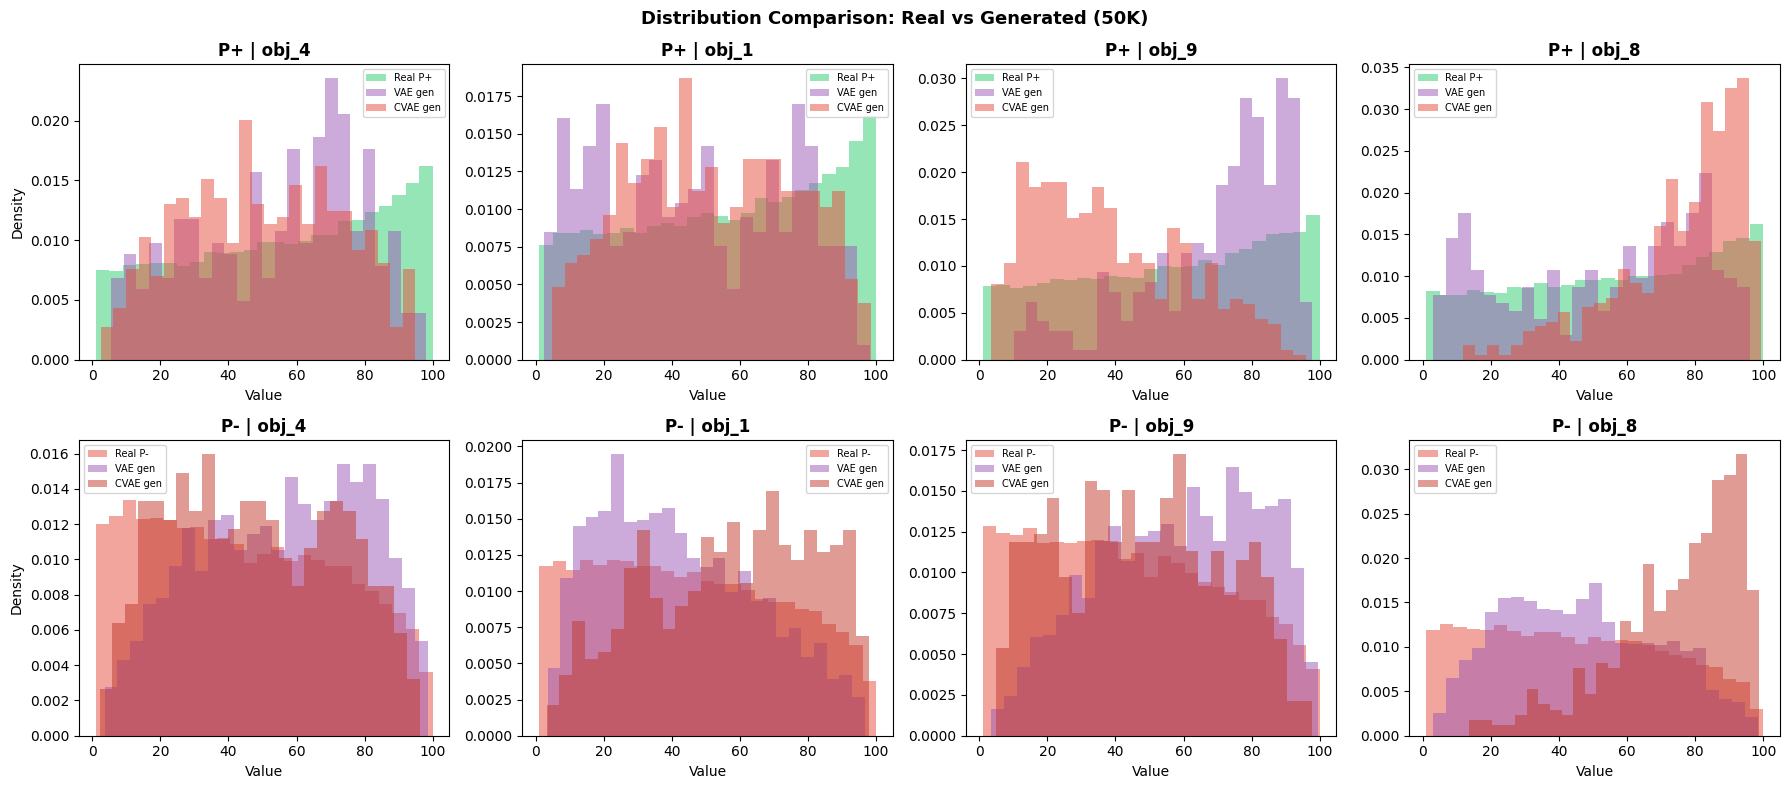

Saved → 13_distribution_comparison.png


In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))

plot_obj_indices = selected_indices[:4]
plot_obj_names   = [ALL_OBJECTIVES[i] for i in plot_obj_indices]

real_pos_orig = X_orig_full[y_full == 1]
real_neg_orig = X_orig_full[y_full == 0]

for col, (obj_idx, obj_name) in enumerate(
        zip(plot_obj_indices, plot_obj_names)):

    # Row 0: P+ real vs generated
    axes[0, col].hist(real_pos_orig[:, obj_idx],
                      bins=25, alpha=0.5, color="#2ecc71",
                      label="Real P+", density=True)
    if len(vae_gen_pos) > 0:
        axes[0, col].hist(vae_gen_pos[:, obj_idx],
                          bins=25, alpha=0.5, color="#9b59b6",
                          label="VAE gen", density=True)
    axes[0, col].hist(cvae_gen_pos_eval[:, obj_idx],
                      bins=25, alpha=0.5, color="#e74c3c",
                      label="CVAE gen", density=True)
    axes[0, col].set_title(f"P+ | {obj_name}", fontweight="bold")
    axes[0, col].set_xlabel("Value")
    if col == 0:
        axes[0, col].set_ylabel("Density")
    axes[0, col].legend(fontsize=7)

    # Row 1: P- real vs generated
    axes[1, col].hist(real_neg_orig[:, obj_idx],
                      bins=25, alpha=0.5, color="#e74c3c",
                      label="Real P-", density=True)
    if len(vae_gen_neg) > 0:
        axes[1, col].hist(vae_gen_neg[:, obj_idx],
                          bins=25, alpha=0.5, color="#9b59b6",
                          label="VAE gen", density=True)
    axes[1, col].hist(cvae_gen_neg_eval[:, obj_idx],
                      bins=25, alpha=0.5, color="#c0392b",
                      label="CVAE gen", density=True)
    axes[1, col].set_title(f"P- | {obj_name}", fontweight="bold")
    axes[1, col].set_xlabel("Value")
    if col == 0:
        axes[1, col].set_ylabel("Density")
    axes[1, col].legend(fontsize=7)

plt.suptitle("Distribution Comparison: Real vs Generated (50K)",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(f"{CONFIG['figures_dir']}/13_distribution_comparison.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("Saved → 13_distribution_comparison.png")

## Save the Results

In [ ]:
all_results = {
    "AE"  : ae_results,
    "VAE" : {**vae_results,
             "dvr_positive": float(vae_dvr_pos),
             "dvr_negative": float(vae_dvr_neg)},
    "CVAE": {**cvae_results,
             "dvr_positive": float(cvae_dvr_pos),
             "dvr_negative": float(cvae_dvr_neg)},
}
with open(f"{CONFIG['results_dir']}/all_results.json", "w") as f:
    json.dump(all_results, f, indent=2)

print("Complete results saved → all_results.json")
print(json.dumps(all_results, indent=2))

Complete results saved → all_results.json
{
  "AE": {
    "model": "Autoencoder",
    "mse": 0.01499903853982687,
    "acc": 0.8584,
    "f1": 0.8583930511143935,
    "epochs_trained": 28
  },
  "VAE": {
    "model": "VAE",
    "mse": 0.023865990340709686,
    "acc": 0.8466666666666667,
    "f1": 0.8466577690615887,
    "epochs_trained": 21,
    "dvr_positive": 0.8731884057971014,
    "dvr_negative": 0.46
  },
  "CVAE": {
    "model": "CVAE",
    "mse": 0.019935233518481255,
    "acc": 0.7277333333333333,
    "f1": 0.7263024471325293,
    "epochs_trained": 22,
    "eval_method": "label-marginal (leak-free)",
    "dvr_positive": 0.702,
    "dvr_negative": 0.266
  }
}


## Verify Steps

In [ ]:
print("=" * 60)
print("  Step 8 Verification")
print("=" * 60)
checks = {
    "DVR computed VAE P+"          : vae_dvr_pos  is not None,
    "DVR computed VAE P-"          : vae_dvr_neg  is not None,
    "DVR computed CVAE P+"         : cvae_dvr_pos is not None,
    "DVR computed CVAE P-"         : cvae_dvr_neg is not None,
    "DVR bar chart saved"          : os.path.exists(
                                       f"{CONFIG['figures_dir']}/12_dvr_results.png"),
    "Distribution comparison saved": os.path.exists(
                                       f"{CONFIG['figures_dir']}/13_distribution_comparison.png"),
    "All results JSON saved"       : os.path.exists(
                                       f"{CONFIG['results_dir']}/all_results.json"),
}
all_good = True
for name, status in checks.items():
    icon = "(OK)" if status else "(WARNING)"
    print(f"  {icon} {name}")
    if not status:
        all_good = False
print("=" * 60)
if all_good:
    print("  (OK) All checks passed. Ready for Step 9!")
else:
    print("  (CHECK) Fix items marked (WARNING) before continuing.")

  Step 8 Verification
  (OK) DVR computed VAE P+
  (OK) DVR computed VAE P-
  (OK) DVR computed CVAE P+
  (OK) DVR computed CVAE P-
  (OK) DVR bar chart saved
  (OK) Distribution comparison saved
  (OK) All results JSON saved
  (OK) All checks passed. Ready for Step 9!


# **Qualitative Evaluation**

## t-SNE

*We prepare the data for a t-SNE embedding that places real plans and generated plans from both models into the same 2D coordinate space. Because t-SNE does not scale well to 50,000 points (it would take many minutes and produce a saturated figure), this cell takes a random sample of 3,000 real plans, 500 VAE-generated plans, and 500 CVAE-generated plans (250 P+ and 250 P-), stacks them into a single matrix of 4,000 plans, and assigns each point a source label (0=real, 1=VAE gen, 2=CVAE gen) and a class label (0=P-, 1=P+). This dual labeling allows the three panels of the t-SNE figure to color points differently. The perplexity of 40 and max_iter of 1000 are the same as the original project to keep the visualization comparable.*

In [ ]:
# Subsampling real plans for t-SNE, entire 50K is too large to embed
TSNE_REAL_SAMPLE = 3000

np.random.seed(CONFIG["seed"])
tsne_real_idx = np.random.choice(len(X_orig_full),
                                  TSNE_REAL_SAMPLE, replace=False)
tsne_real     = X_orig_full[tsne_real_idx]
tsne_real_y   = y_full[tsne_real_idx]

# VAE generated (already computed)
tsne_vae_gen  = vae_gen_orig_eval[:500]
tsne_vae_y    = gyb[:500]

# CVAE generated
tsne_cvae_gen = np.vstack([
    cvae_gen_pos_eval[:250],
    cvae_gen_neg_eval[:250]
])
tsne_cvae_y   = np.array([1]*250 + [0]*250)

X_tsne_input  = np.vstack([tsne_real, tsne_vae_gen, tsne_cvae_gen])
source_labels  = np.array(
    [0]*TSNE_REAL_SAMPLE +
    [1]*len(tsne_vae_gen) +
    [2]*len(tsne_cvae_gen)
)
class_labels   = np.concatenate([tsne_real_y, tsne_vae_y, tsne_cvae_y])

print(f"t-SNE input: {X_tsne_input.shape[0]:,} plans total")
print(f"  Real      : {TSNE_REAL_SAMPLE:,}")
print(f"  VAE gen   : {len(tsne_vae_gen)}")
print(f"  CVAE gen  : {len(tsne_cvae_gen)}")
print("\n")

tsne   = TSNE(n_components=2, random_state=CONFIG["seed"],
              perplexity=40, max_iter=1000, verbose=0)
X_tsne = tsne.fit_transform(X_tsne_input)
print("t-SNE complete.")

t-SNE input: 4,000 plans total
  Real      : 3,000
  VAE gen   : 500
  CVAE gen  : 500


t-SNE complete.


## t-SNE Plot

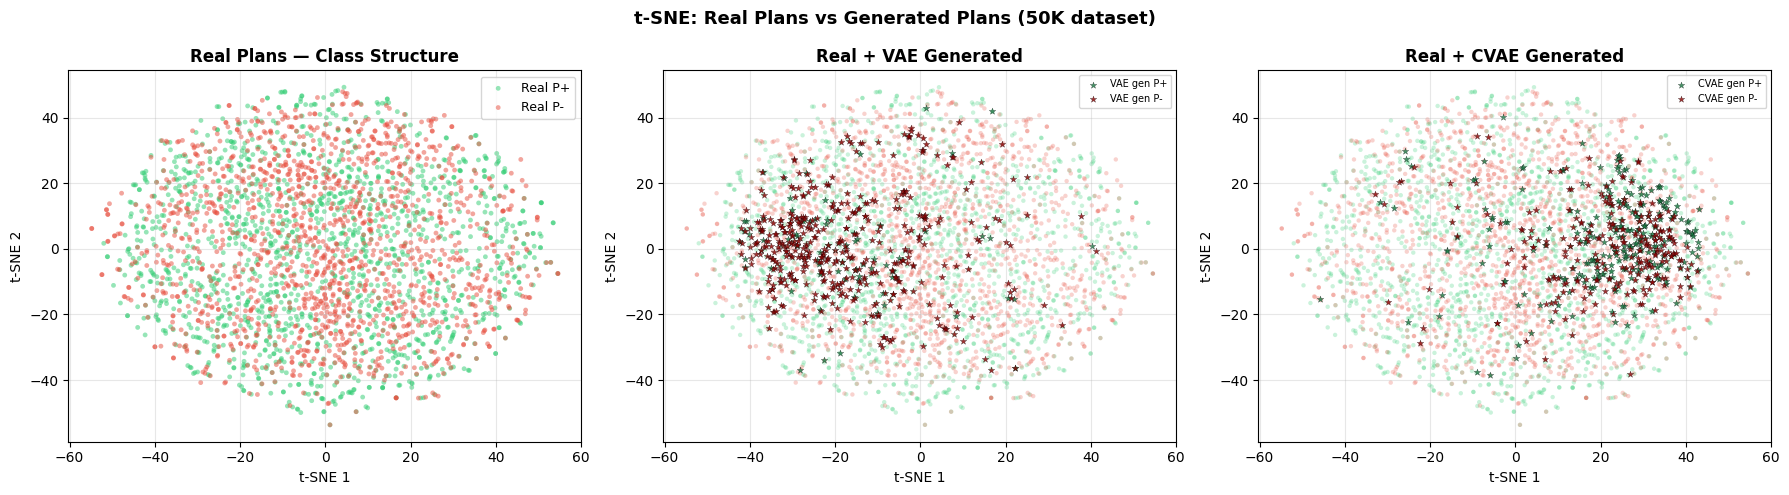

Saved → 14_tsne_real_vs_generated.png


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Panel 1: Real plans only
for label, name, color in [(1,"P+","#2ecc71"),(0,"P-","#e74c3c")]:
    mask = (class_labels==label) & (source_labels==0)
    axes[0].scatter(X_tsne[mask,0], X_tsne[mask,1],
                    c=color, label=f"Real {name}",
                    alpha=0.5, s=12, edgecolors="none")
axes[0].set_title("Real Plans — Class Structure",
                  fontweight="bold")
axes[0].legend(fontsize=9)
axes[0].set_xlabel("t-SNE 1"); axes[0].set_ylabel("t-SNE 2")
axes[0].grid(True, alpha=0.3)

# Panel 2: Real + VAE generated
for label, name, color in [(1,"P+","#2ecc71"),(0,"P-","#e74c3c")]:
    mask = (class_labels==label) & (source_labels==0)
    axes[1].scatter(X_tsne[mask,0], X_tsne[mask,1],
                    c=color, alpha=0.25, s=10, edgecolors="none")
for label, name, color in [(1,"P+","#1a7a43"),(0,"P-","#8b0000")]:
    mask = (class_labels==label) & (source_labels==1)
    axes[1].scatter(X_tsne[mask,0], X_tsne[mask,1],
                    c=color, label=f"VAE gen {name}",
                    alpha=0.8, s=25, marker="*",
                    edgecolors="black", linewidths=0.2)
axes[1].set_title("Real + VAE Generated", fontweight="bold")
axes[1].legend(fontsize=7)
axes[1].set_xlabel("t-SNE 1"); axes[1].set_ylabel("t-SNE 2")
axes[1].grid(True, alpha=0.3)

# Panel 3: Real + CVAE generated
for label, name, color in [(1,"P+","#2ecc71"),(0,"P-","#e74c3c")]:
    mask = (class_labels==label) & (source_labels==0)
    axes[2].scatter(X_tsne[mask,0], X_tsne[mask,1],
                    c=color, alpha=0.25, s=10, edgecolors="none")
for label, name, color in [(1,"P+","#1a7a43"),(0,"P-","#8b0000")]:
    mask = (class_labels==label) & (source_labels==2)
    axes[2].scatter(X_tsne[mask,0], X_tsne[mask,1],
                    c=color, label=f"CVAE gen {name}",
                    alpha=0.8, s=25, marker="*",
                    edgecolors="black", linewidths=0.2)
axes[2].set_title("Real + CVAE Generated", fontweight="bold")
axes[2].legend(fontsize=7)
axes[2].set_xlabel("t-SNE 1"); axes[2].set_ylabel("t-SNE 2")
axes[2].grid(True, alpha=0.3)

plt.suptitle("t-SNE: Real Plans vs Generated Plans (50K dataset)",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(f"{CONFIG['figures_dir']}/14_tsne_real_vs_generated.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("Saved → 14_tsne_real_vs_generated.png")

## Latent Space Interpolation

In [ ]:
def interpolate_latent(model, x_start, x_end, y_start, y_end, n_steps=11, model_type="vae"):

    model.eval()

    with torch.no_grad():
        xs = torch.tensor(x_start, dtype=torch.float32).unsqueeze(0).to(device)
        xe = torch.tensor(x_end, dtype=torch.float32).unsqueeze(0).to(device)

        if model_type == "vae":
            mu_s, _ = model.encode(xs)
            mu_e, _ = model.encode(xe)
        else:
            ys = torch.tensor([y_start], dtype=torch.float32).to(device)
            ye = torch.tensor([y_end], dtype=torch.float32).to(device)
            mu_s, _ = model.encode(xs, ys)
            mu_e, _ = model.encode(xe, ye)

        alphas = np.linspace(0, 1, n_steps)

        interp_plans = []

        for alpha in alphas:
            z_interp = (1 - alpha) * mu_s + alpha * mu_e
            if model_type == "vae":
                x_interp = model.decode(z_interp)
            else:
                y_interp = torch.tensor(
                    [(1-alpha)*y_start + alpha*y_end], dtype=torch.float32).to(device)
                x_interp = model.decode(z_interp, y_interp)
            interp_plans.append(x_interp.cpu().numpy().squeeze())

    return np.array(interp_plans), alphas

# We pick one real P+ and one real P- from test set
pos_idx = np.where(y_test == 1)[0][0]
neg_idx = np.where(y_test == 0)[0][0]
x_pos = X_test_scaled[pos_idx]
x_neg = X_test_scaled[neg_idx]

vae_interp, alphas = interpolate_latent(
    vae_model, x_pos, x_neg, 1.0, 0.0,
    n_steps=11, model_type="vae")
cvae_interp, _ = interpolate_latent(
    cvae_model, x_pos, x_neg, 1.0, 0.0,
    n_steps=11, model_type="cvae")

vae_interp_orig = np.clip(scaler.inverse_transform(vae_interp), 1, 100)
cvae_interp_orig = np.clip(scaler.inverse_transform(cvae_interp), 1, 100)

print(f"Interpolation complete: {len(alphas)} steps")

Interpolation complete: 11 steps


## Interpolation Plots

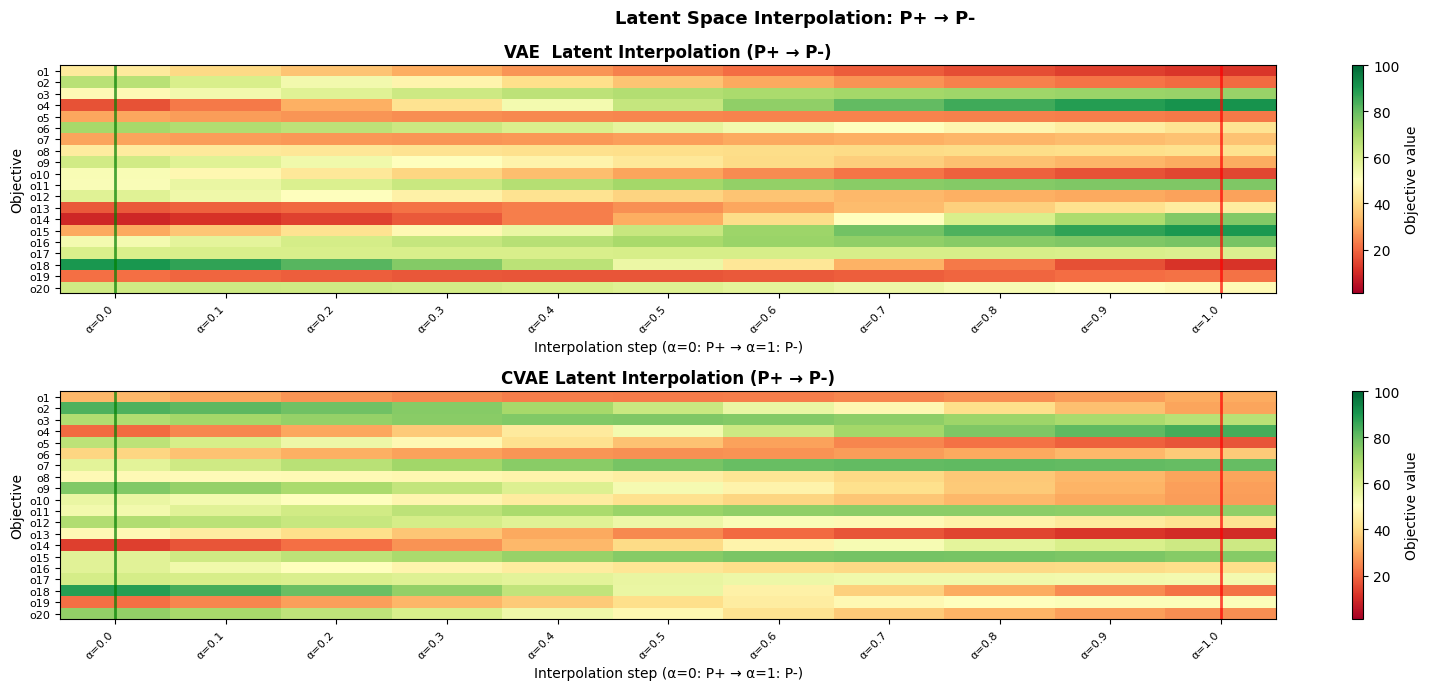

Saved → 15_latent_interpolation.png


In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(16, 7))
obj_labels_short = [f"o{i+1}" for i in range(20)]

for ax, (data, title, cmap) in zip(axes, [
    (vae_interp_orig,  "VAE  Latent Interpolation (P+ → P-)", "RdYlGn"),
    (cvae_interp_orig, "CVAE Latent Interpolation (P+ → P-)", "RdYlGn"),
]):
    im = ax.imshow(data.T, aspect="auto", cmap=cmap, vmin=1, vmax=100, interpolation="nearest")
    ax.set_yticks(range(20))
    ax.set_yticklabels(obj_labels_short, fontsize=8)
    ax.set_xticks(range(len(alphas)))
    ax.set_xticklabels([f"α={a:.1f}" for a in alphas], rotation=45, ha="right", fontsize=8)
    ax.set_xlabel("Interpolation step (α=0: P+ → α=1: P-)")
    ax.set_ylabel("Objective")
    ax.set_title(title, fontweight="bold")
    plt.colorbar(im, ax=ax, label="Objective value")
    ax.axvline(x=0, color="green", linewidth=2, alpha=0.7)
    ax.axvline(x=len(alphas)-1, color="red", linewidth=2, alpha=0.7)

plt.suptitle("Latent Space Interpolation: P+ → P-", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(f"{CONFIG['figures_dir']}/15_latent_interpolation.png", dpi=150, bbox_inches="tight")
plt.show()

print("Saved → 15_latent_interpolation.png")

## Analyze Diversity

*We measure how diverse the generated samples are by computing the mean pairwise Euclidean distance between a random subset of 300 generated plans. This is compared against the same metric computed for the real P+ and P- plans as a baseline. A good generative model should produce samples with diversity close to the real data. Significantly lower diversity than real data indicates mode collapse where the model generates very similar plans regardless of the latent sample. Significantly higher diversity indicates that the model is generating out-of-distribution plans that do not respect the structure of the real data. Both scenarios are problematic and this metric quantifies the degree of each.*

In [ ]:
from sklearn.metrics import pairwise_distances

def compute_diversity(samples, metric="euclidean", n_sample=300):

    idx  = np.random.choice(len(samples), min(n_sample, len(samples)), replace=False)
    sub  = samples[idx]
    dist = pairwise_distances(sub, metric=metric)
    upper = dist[np.triu_indices_from(dist, k=1)]

    return upper.mean(), upper.std()

np.random.seed(CONFIG["seed"])

# Real data baseline
div_real_pos_mean, div_real_pos_std = compute_diversity(real_pos_orig)
div_real_neg_mean, div_real_neg_std = compute_diversity(real_neg_orig)

# VAE
div_vae_pos_mean,  div_vae_pos_std  = compute_diversity(vae_gen_pos) \
    if len(vae_gen_pos) > 0 else (0, 0)
div_vae_neg_mean,  div_vae_neg_std  = compute_diversity(vae_gen_neg) \
    if len(vae_gen_neg) > 0 else (0, 0)

# CVAE
div_cvae_pos_mean, div_cvae_pos_std = compute_diversity(cvae_gen_pos_eval)
div_cvae_neg_mean, div_cvae_neg_std = compute_diversity(cvae_gen_neg_eval)

print("=" * 65)
print("  Diversity (Mean Pairwise Euclidean Distance)")
print("=" * 65)
print(f"  {'Source':<25} {'P+ Diversity':>15} {'P- Diversity':>15}")
print("  " + "-" * 58)
print(f"  {'Real data (baseline)':<25} "
      f"{div_real_pos_mean:>8.2f}±{div_real_pos_std:.2f}"
      f"{div_real_neg_mean:>8.2f}±{div_real_neg_std:.2f}")
print(f"  {'VAE generated':<25} "
      f"{div_vae_pos_mean:>8.2f}±{div_vae_pos_std:.2f}"
      f"{div_vae_neg_mean:>8.2f}±{div_vae_neg_std:.2f}")
print(f"  {'CVAE generated':<25} "
      f"{div_cvae_pos_mean:>8.2f}±{div_cvae_pos_std:.2f}"
      f"{div_cvae_neg_mean:>8.2f}±{div_cvae_neg_std:.2f}")
print("=" * 65)
print("\nIdeal: generated diversity ≈ real diversity")
print("Too low  → mode collapse")
print("Too high → out-of-distribution generation")

  Diversity (Mean Pairwise Euclidean Distance)
  Source                       P+ Diversity    P- Diversity
  ----------------------------------------------------------
  Real data (baseline)        183.09±24.89  176.19±23.84
  VAE generated               158.24±26.34  148.48±23.04
  CVAE generated              143.07±21.97  144.26±22.25

Ideal: generated diversity ≈ real diversity
Too low  → mode collapse
Too high → out-of-distribution generation


## Save and Verify

In [ ]:
# Save qualitative results
qualitative_results = {
    "diversity": {
        "real_pos" : {"mean": float(div_real_pos_mean),
                      "std":  float(div_real_pos_std)},
        "real_neg" : {"mean": float(div_real_neg_mean),
                      "std":  float(div_real_neg_std)},
        "vae_pos"  : {"mean": float(div_vae_pos_mean),
                      "std":  float(div_vae_pos_std)},
        "vae_neg"  : {"mean": float(div_vae_neg_mean),
                      "std":  float(div_vae_neg_std)},
        "cvae_pos" : {"mean": float(div_cvae_pos_mean),
                      "std":  float(div_cvae_pos_std)},
        "cvae_neg" : {"mean": float(div_cvae_neg_mean),
                      "std":  float(div_cvae_neg_std)},
    },
    "interpolation_steps": len(alphas),
    "tsne_real_sample"   : TSNE_REAL_SAMPLE,
}
with open(f"{CONFIG['results_dir']}/qualitative_results.json", "w") as f:
    json.dump(qualitative_results, f, indent=2)
print("Saved → qualitative_results.json")

# Verification
print("\n" + "=" * 55)
print("  Steps Verification")
print("=" * 55)
checks = {
    "t-SNE figure saved"       : os.path.exists(
                                   f"{CONFIG['figures_dir']}/14_tsne_real_vs_generated.png"),
    "Interpolation figure saved": os.path.exists(
                                   f"{CONFIG['figures_dir']}/15_latent_interpolation.png"),
    "Diversity VAE P+ > 0"     : div_vae_pos_mean  > 0,
    "Diversity CVAE P+ > 0"    : div_cvae_pos_mean > 0,
    "Qualitative results saved" : os.path.exists(
                                   f"{CONFIG['results_dir']}/qualitative_results.json"),
    "Interpolation shape OK"   : vae_interp_orig.shape == (11, 20),
}
all_good = True
for name, status in checks.items():
    icon = "(OK)" if status else "(WARNING)"
    print(f"  {icon} {name}")
    if not status:
        all_good = False
print("=" * 55)
if all_good:
    print("  (OK) All checks passed.")
else:
    print("  (CHECK) Fix items marked (WARNING) before continuing.")

Saved → qualitative_results.json

  Steps Verification
  (OK) t-SNE figure saved
  (OK) Interpolation figure saved
  (OK) Diversity VAE P+ > 0
  (OK) Diversity CVAE P+ > 0
  (OK) Qualitative results saved
  (OK) Interpolation shape OK
  (OK) All checks passed.


# **Multi-Seed Experiments**

## Fast dataset generator

*We define generate_mornp_fast_50k, a pure-numpy implementation of the strict Pareto partition algorithm that can be called directly inside Colab without the GPU-accelerated generator script. This function is used to create new MORNP instances for seeds 123, 456, 789, and 2024. For each seed it randomly selects k=12 objectives from 20, generates a pool of 5,000 random plans in [1, 100], classifies each plan as P+ (nondominated) or P- (dominated) using a chunked vectorized dominance count, and then draws a balanced subset ensuring roughly equal P+ and P- counts. The pool size of 5,000 per seed is much smaller than the main 50K dataset because running 5,000-plan experiments for 5 seeds is intended to measure variance across problem instances rather than to replicate the full 50K experiment, which would take too long within a single Colab session. The function uses the same strict labeling strategy as the main dataset generator for methodological consistency.*

In [ ]:
'''
  We replicates the same strict-Pareto logic as the generator script,
  but in pure numpy so it runs inside Colab directly. Used for
  seeds 123, 456, 789, 2024 (seed 42 = original).
'''
def generate_mornp_fast_50k(seed, n_plans=5000,
                              n_objectives=20, k=12,
                              val_max=100):
    """
    Fast MORNP generator for multi-seed experiments.
    Uses a smaller pool (n_plans=5000) per seed for speed.
    Strict Pareto partition — matches original strategy.
    """
    rng = np.random.RandomState(seed)
    selected = sorted(rng.choice(n_objectives, k, replace=False).tolist())

    pool = rng.randint(1, val_max+1,
                            size=(n_plans, n_objectives),
                            dtype=np.int32).astype(np.float32)
    pool_sel = pool[:, selected]

    # Vectorized dominance count
    dom_counts = np.zeros(n_plans, dtype=np.int32)
    chunk_size = 1000
    for start in range(0, n_plans, chunk_size):
        end = min(start + chunk_size, n_plans)
        chunk = pool_sel[start:end] # ------------->(C, k)
        q = chunk[:, None, :] # ------------------->(C, 1, k)
        p = pool_sel[None, :, :] # ---------------->(1, N, k)
        all_ge = np.all(p >= q, axis=2) # --------->(C, N)
        any_gt = np.any(p >  q, axis=2) # --------->(C, N)
        dom = all_ge & any_gt # ------------------->(C, N)

        # exclude self
        for ci in range(end - start):
            dom[ci, start + ci] = False
        dom_counts[start:end] = dom.sum(axis=1)

    labels = (dom_counts == 0).astype(np.float32)

    # Balance classes
    pos_idx = np.where(labels == 1)[0]
    neg_idx = np.where(labels == 0)[0]
    n_take  = min(len(pos_idx), len(neg_idx), n_plans // 2)

    chosen  = np.concatenate([
        rng.choice(pos_idx, n_take, replace=False),
        rng.choice(neg_idx, n_take, replace=False),
    ])

    rng.shuffle(chosen)

    return (pool[chosen].astype(np.float32),
            labels[chosen],
            selected)

# Test
X_t, y_t, sel_t = generate_mornp_fast_50k(seed=999)
print(f"Fast generator test:")
print(f"  Shape    : {X_t.shape}")
print(f"  P+ count : {(y_t==1).sum()}")
print(f"  P- count : {(y_t==0).sum()}")
print("(OK) Generator working.")

Fast generator test:
  Shape    : (2234, 20)
  P+ count : 1117
  P- count : 1117
(OK) Generator working.


## Multi-Seed Pipeline

*We define run_single_experiment_50k and calls it for all five seeds. For seed 42 it reuses the original 50K dataset. For the other four seeds it calls the fast generator to create a fresh 5,000-plan MORNP instance. For each seed it runs the complete pipeline: split, scale, create loaders, train AE, evaluate AE, train VAE, evaluate VAE with DVR, train CVAE, and evaluate CVAE with DVR. The DVR computation for the per-seed experiments uses a smaller reference pool of 5,000 plans and evaluates 200 generated samples to keep runtime manageable across five seeds. All three models are trained with the same hyperparameters as the main experiment. The function returns a results dictionary for each seed containing all metrics for all three models.*

In [ ]:
SEEDS = [42, 123, 456, 789, 2024]

def run_single_experiment_50k(seed):
    print(f"\n{'='*60}")
    print(f"  Seed {seed}")
    print(f"{'='*60}")

    # Dataset
    if seed == 42:
        X_s, y_s = X, y
        sel_idx = selected_indices
        print(f"  Using original 50K dataset: {X_s.shape}")
    else:
        X_s, y_s, sel_idx = generate_mornp_fast_50k(
            seed=seed, n_plans=5000)
        print(f"  Generated: {X_s.shape} "
              f"P+={int((y_s==1).sum())} "
              f"P-={int((y_s==0).sum())}")

    set_seed(seed)

    # Split & scale
    X_tr, X_te, y_tr, y_te = train_test_split(X_s, y_s, test_size=0.15, random_state=seed, stratify=y_s)
    X_tr, X_va, y_tr, y_va = train_test_split(X_tr, y_tr,test_size=0.15/(1-0.15), random_state=seed, stratify=y_tr)

    sc           = MinMaxScaler()
    X_tr_sc      = sc.fit_transform(X_tr)
    X_va_sc      = sc.transform(X_va)
    X_te_sc      = sc.transform(X_te)

    n_p = (y_tr == 1).sum()
    n_n = (y_tr == 0).sum()
    if n_p == 0 or n_n == 0:
        print(f"  (CAUTION) Skipping —> only one class.")
        return None

    sw   = torch.tensor(np.where(y_tr==1, 1.0/n_p, 1.0/n_n), dtype=torch.float32)
    samp = WeightedRandomSampler(sw, len(sw), replacement=True)
    tr_ld = DataLoader(PlanDataset(X_tr_sc, y_tr), batch_size=256, sampler=samp, num_workers=0)
    va_ld = DataLoader(PlanDataset(X_va_sc, y_va), batch_size=256, shuffle=False, num_workers=0)
    te_ld = DataLoader(PlanDataset(X_te_sc, y_te), batch_size=256, shuffle=False, num_workers=0)

    results = {"seed": seed}

    for model_name in ["AE", "VAE", "CVAE"]:
        print(f"\n  Training {model_name}")

        if model_name == "AE":
            model = Autoencoder(20, CONFIG["hidden_dims"], CONFIG["latent_dim"]).to(device)
            opt   = optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-5)
            sch   = optim.lr_scheduler.ReduceLROnPlateau(opt, patience=10, factor=0.5)
            ckpt  = f"{CONFIG['checkpoint_dir']}/ae_seed{seed}.pt"
            train_autoencoder(model, opt, sch, tr_ld, va_ld,
                              CONFIG["epochs"],
                              CONFIG["early_stop_patience"], ckpt)
            model.load_state_dict(torch.load(ckpt, map_location=device))
            model.eval()
            xs=[]; xr=[]; yt=[]; yp=[]

            with torch.no_grad():
                for xb, yb in te_ld:
                    xb = xb.to(device)
                    xr_b, _, yp_b = model(xb)
                    xs.append(xb.cpu().numpy())
                    xr.append(xr_b.cpu().numpy())
                    yt.append(yb.numpy())
                    yp.append(yp_b.cpu().numpy())

            xs=np.concatenate(xs); xr=np.concatenate(xr)
            yt=np.concatenate(yt); yp=np.concatenate(yp)
            yb=(yp>=0.5).astype(int)

            results["AE"] = {
                "mse": float(np.mean((xs-xr)**2)),
                "acc": float(accuracy_score(yt, yb)),
                "f1" : float(f1_score(yt, yb,
                                       average="weighted",
                                       zero_division=0)),
            }

            print(f"  MSE={results['AE']['mse']:.4f} "
                  f"Acc={results['AE']['acc']*100:.1f}% "
                  f"F1={results['AE']['f1']:.4f}")

        elif model_name == "VAE":
            model = VAE(20, CONFIG["hidden_dims"],
                        CONFIG["latent_dim"]).to(device)
            opt = optim.Adam(model.parameters(),
                               lr=1e-3, weight_decay=1e-5)
            sch = optim.lr_scheduler.ReduceLROnPlateau(
                opt, patience=10, factor=0.5)
            ckpt = f"{CONFIG['checkpoint_dir']}/vae_seed{seed}.pt"
            train_vae(model, opt, sch, tr_ld, va_ld,
                      CONFIG["epochs"],
                      CONFIG["early_stop_patience"], ckpt)
            model.load_state_dict(
                torch.load(ckpt, map_location=device))
            model.eval()
            xs=[]; xr=[]; yt=[]; yp=[]

            with torch.no_grad():
                for xb, yb in te_ld:
                    xb = xb.to(device)
                    xr_b, mu, lv, z, yp_b = model(xb)
                    xs.append(xb.cpu().numpy())
                    xr.append(xr_b.cpu().numpy())
                    yt.append(yb.numpy())
                    yp.append(yp_b.cpu().numpy())

            xs=np.concatenate(xs); xr=np.concatenate(xr)
            yt=np.concatenate(yt); yp=np.concatenate(yp)
            yb=(yp>=0.5).astype(int)

            # DVR
            gen_sc, _ = model.generate(500, device)
            gen_orig  = np.clip(sc.inverse_transform(gen_sc), 1, 100)
            X_orig_s  = np.clip(sc.inverse_transform(
                np.vstack([X_tr_sc, X_va_sc, X_te_sc])), 1, 100)
            X_sel_s   = X_orig_s[:, sel_idx]

            with torch.no_grad():
                gt    = torch.tensor(gen_sc,
                                      dtype=torch.float32).to(device)
                _, _, _, _, gyp = model(gt)
                gyb   = (gyp.cpu().numpy()>=0.5).astype(int)

            gpos = gen_orig[gyb==1]
            gneg = gen_orig[gyb==0]

            dvr_p = compute_dvr_chunked(
                gpos, X_sel_s, sel_idx,
                target="positive", sample_size=200,
                ref_size=min(5000, len(X_sel_s)),
                chunk_size=2000, seed=seed
            )[0] if len(gpos) > 0 else 0.0

            dvr_n = compute_dvr_chunked(
                gneg, X_sel_s, sel_idx,
                target="negative", sample_size=200,
                ref_size=min(5000, len(X_sel_s)),
                chunk_size=2000, seed=seed
            )[0] if len(gneg) > 0 else 0.0

            results["VAE"] = {
                "mse" : float(np.mean((xs-xr)**2)),
                "acc" : float(accuracy_score(yt, yb)),
                "f1"  : float(f1_score(yt, yb,average="weighted", zero_division=0)),
                "dvr_positive": float(dvr_p),
                "dvr_negative": float(dvr_n),
            }

            print(f"  MSE={results['VAE']['mse']:.4f} "
                  f"Acc={results['VAE']['acc']*100:.1f}% "
                  f"F1={results['VAE']['f1']:.4f} "
                  f"DVR+={dvr_p*100:.1f}% "
                  f"DVR-={dvr_n*100:.1f}%")

        else:  # CVAE
            model = CVAE(20, CONFIG["hidden_dims"],
                         CONFIG["latent_dim"]).to(device)
            opt = optim.Adam(model.parameters(),
                               lr=1e-3, weight_decay=1e-5)
            sch = optim.lr_scheduler.ReduceLROnPlateau(opt, patience=10, factor=0.5)
            ckpt  = f"{CONFIG['checkpoint_dir']}/cvae_seed{seed}.pt"
            train_cvae(model, opt, sch, tr_ld, va_ld,
                       CONFIG["epochs"],
                       CONFIG["early_stop_patience"], ckpt)
            model.load_state_dict(torch.load(ckpt, map_location=device))
            model.eval()
            xs=[]; xr=[]; yt=[]; yp=[]

            with torch.no_grad():
                for xb, yb in te_ld:
                    xb = xb.to(device)
                    yb = yb.to(device)
                    xr_b, mu, lv, z, _ = model(xb, yb)
                    mu_p, _ = model.encode(
                        xb, torch.ones(xb.size(0)).to(device))
                    mu_n, _ = model.encode(
                        xb, torch.zeros(xb.size(0)).to(device))
                    yp_b = model.classifier(
                        0.5*(mu_p+mu_n)).squeeze(1)
                    xs.append(xb.cpu().numpy())
                    xr.append(xr_b.cpu().numpy())
                    yt.append(yb.cpu().numpy())
                    yp.append(yp_b.cpu().numpy())

            xs=np.concatenate(xs); xr=np.concatenate(xr)
            yt=np.concatenate(yt); yp=np.concatenate(yp)
            yb=(yp>=0.5).astype(int)

            X_orig_s  = np.clip(sc.inverse_transform(
                np.vstack([X_tr_sc, X_va_sc, X_te_sc])), 1, 100)
            X_sel_s   = X_orig_s[:, sel_idx]

            gp_sc, _ = model.generate(300, 1.0, device)
            gn_sc, _ = model.generate(300, 0.0, device)
            gp_orig  = np.clip(sc.inverse_transform(gp_sc), 1, 100)
            gn_orig  = np.clip(sc.inverse_transform(gn_sc), 1, 100)

            dvr_p = compute_dvr_chunked(
                gp_orig, X_sel_s, sel_idx,
                target="positive", sample_size=200,
                ref_size=min(5000, len(X_sel_s)),
                chunk_size=2000, seed=seed
            )[0]

            dvr_n = compute_dvr_chunked(
                gn_orig, X_sel_s, sel_idx,
                target="negative", sample_size=200,
                ref_size=min(5000, len(X_sel_s)),
                chunk_size=2000, seed=seed
            )[0]

            results["CVAE"] = {
                "mse" : float(np.mean((xs-xr)**2)),
                "acc" : float(accuracy_score(yt, yb)),
                "f1"  : float(f1_score(yt, yb, average="weighted", zero_division=0)),
                "dvr_positive": float(dvr_p),
                "dvr_negative": float(dvr_n),
            }

            print(f"  MSE={results['CVAE']['mse']:.4f} "
                  f"Acc={results['CVAE']['acc']*100:.1f}% "
                  f"F1={results['CVAE']['f1']:.4f} "
                  f"DVR+={dvr_p*100:.1f}% "
                  f"DVR-={dvr_n*100:.1f}%")

    return results

# Run all seeds
print("Starting multi-seed experiments...")
print(f"Seeds: {SEEDS}")
all_seed_results = []
for seed in SEEDS:
    res = run_single_experiment_50k(seed)
    if res is not None:
        all_seed_results.append(res)

print(f"\n(.) Completed {len(all_seed_results)}/{len(SEEDS)} seeds.")

Starting multi-seed experiments...
Seeds: [42, 123, 456, 789, 2024]

  Seed 42
  Using original 50K dataset: (50000, 20)

  Training AE
Epoch    1/200 | Train: 0.21911 (recon:0.03238 cls:0.37345) | Val: 0.18344 | LR: 0.001000
Epoch   20/200 | Train: 0.10150 (recon:0.01328 cls:0.17644) | Val: 0.20190 | LR: 0.000500

 Early stopping at epoch 25

 Best val loss: 0.16922 → saved to /content/drive/MyDrive/GenMOR/checkpoints/ae_seed42.pt
  MSE=0.0161 Acc=85.8% F1=0.8575

  Training VAE
Epoch    1/200 | Train: 0.25318 (recon=0.05454 kl=1.35580 cls=0.37017) | Val: 0.20430 | kl_w=0.010
Epoch   20/200 | Train: 0.21180 (recon=0.08060 kl=0.14189 cls=0.20564) | Val: 0.27864 | kl_w=0.200

 Early stopping at epoch 22

 Best val loss: 0.20367 → saved to /content/drive/MyDrive/GenMOR/checkpoints/vae_seed42.pt
  MSE=0.0204 Acc=85.4% F1=0.8536 DVR+=98.4% DVR-=46.0%

  Training CVAE
Epoch    1/200 | Train: 0.12317 (recon=0.05936 kl=2.00406 cls=0.08753) | Val: 0.04880 | kl_w=0.010
Epoch   20/200 | Train: 0

## Aggregate Results

In [ ]:
metrics = {
    "AE"  : {"mse":[], "acc":[], "f1":[]},
    "VAE" : {"mse":[], "acc":[], "f1":[], "dvr_positive":[], "dvr_negative":[]},
    "CVAE": {"mse":[], "acc":[], "f1":[], "dvr_positive":[], "dvr_negative":[]},
}

for res in all_seed_results:
    for mn in ["AE","VAE","CVAE"]:
        if mn in res:
            for metric, val in res[mn].items():
                if metric in metrics[mn]:
                    metrics[mn][metric].append(val)

print("=" * 75)
print("  Multi-Seed Results (mean ± std across 5 seeds)")
print("=" * 75)
print(f"  {'Metric':<30} {'AE':>12} {'VAE':>15} {'CVAE':>15}")
print("  " + "-" * 70)

for metric in ["mse", "acc", "f1"]:
    row = f"  {metric.upper():<30}"
    for mn in ["AE","VAE","CVAE"]:
        vals = metrics[mn].get(metric, [])
        if vals:
            m, s = np.mean(vals), np.std(vals)
            row += (f" {m*100:.1f}±{s*100:.1f}%"
                    if metric == "acc"
                    else f" {m:.4f}±{s:.4f}")
        else:
            row += f"{'N/A':>15}"
    print(row)

print("  " + "-" * 70)

for metric in ["dvr_positive", "dvr_negative"]:
    label = "P+ DVR" if "pos" in metric else "P- DVR"
    row   = f"  {label:<30}{'N/A':>14}"
    for mn in ["VAE","CVAE"]:
        vals = metrics[mn].get(metric, [])
        if vals:
            m, s = np.mean(vals), np.std(vals)
            row += f" {m*100:.1f}±{s*100:.1f}%"
        else:
            row += f"{'N/A':>15}"
    print(row)
print("=" * 75)

with open(f"{CONFIG['results_dir']}/multiseed_results.json", "w") as f:
    json.dump({
        "seeds"  : SEEDS,
        "results": all_seed_results,
        "metrics": {m: {k: list(v) for k,v in d.items()}
                    for m,d in metrics.items()},
    }, f, indent=2)
print("\nSaved → multiseed_results.json")

  Multi-Seed Results (mean ± std across 5 seeds)
  Metric                                   AE             VAE            CVAE
  ----------------------------------------------------------------------
  MSE                            0.0277±0.0061 0.0505±0.0154 0.0655±0.0230
  ACC                            83.2±1.5% 82.7±1.4% 59.9±7.6%
  F1                             0.8320±0.0145 0.8267±0.0142 0.5593±0.1195
  ----------------------------------------------------------------------
  P+ DVR                                   N/A 72.4±38.8% 62.6±28.7%
  P- DVR                                   N/A 48.4±17.9% 63.4±32.4%

Saved → multiseed_results.json


## Box Plots

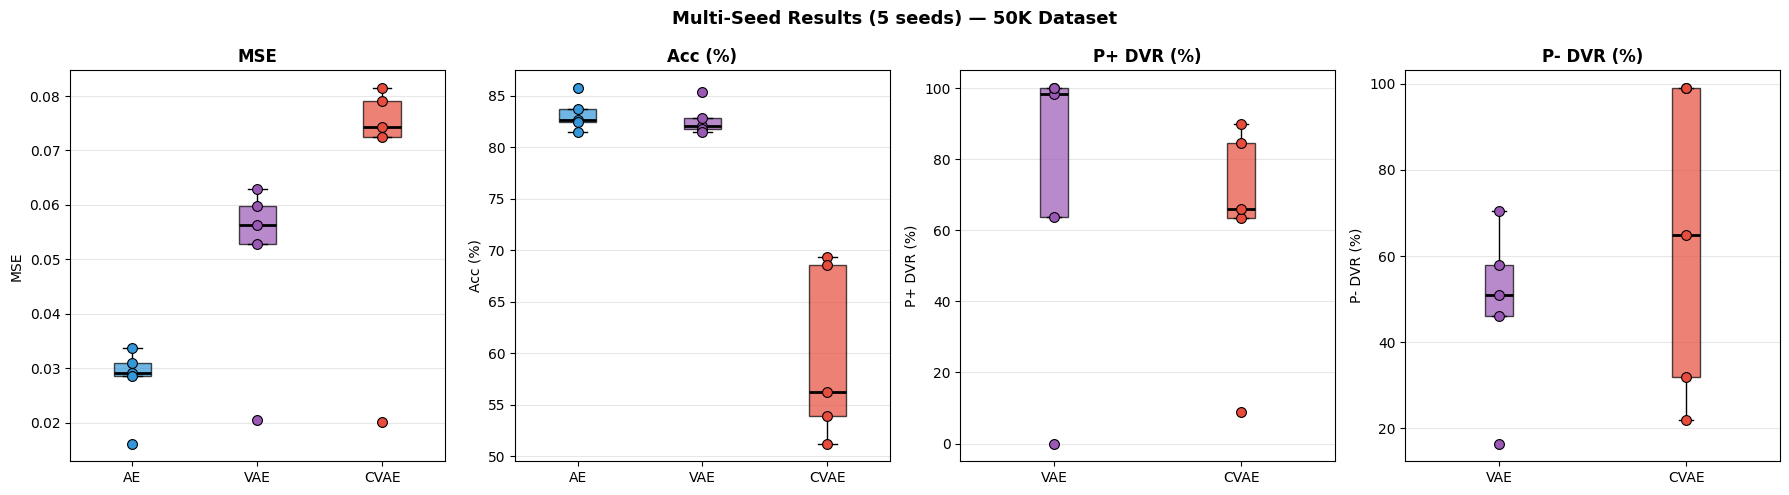

Saved → 16_multiseed_boxplots.png


In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

plot_configs = [
    ("MSE",        "mse",          ["AE","VAE","CVAE"], False),
    ("Acc (%)",    "acc",          ["AE","VAE","CVAE"], True),
    ("P+ DVR (%)","dvr_positive",  ["VAE","CVAE"],      True),
    ("P- DVR (%)","dvr_negative",  ["VAE","CVAE"],      True),
]
colors_box = {"AE":"#3498db","VAE":"#9b59b6","CVAE":"#e74c3c"}

for ax, (ylabel, metric, models, is_pct) in zip(axes, plot_configs):
    data_plot=[]; labels_plot=[]; colors_plot=[]
    for mn in models:
        vals = metrics[mn].get(metric, [])
        if vals:
            data_plot.append(
                [v*100 if is_pct else v for v in vals])
            labels_plot.append(mn)
            colors_plot.append(colors_box[mn])

    bp = ax.boxplot(data_plot, patch_artist=True,
                    medianprops={"color":"black","linewidth":2})
    for patch, color in zip(bp["boxes"], colors_plot):
        patch.set_facecolor(color); patch.set_alpha(0.7)

    for i, (vals, color) in enumerate(
            zip(data_plot, colors_plot), start=1):
        ax.scatter([i]*len(vals), vals,
                   color=color, zorder=5, s=50,
                   edgecolors="black", linewidths=0.8)

    ax.set_xticks(range(1, len(labels_plot)+1))
    ax.set_xticklabels(labels_plot)
    ax.set_ylabel(ylabel)
    ax.set_title(ylabel, fontweight="bold")
    ax.grid(True, alpha=0.3, axis="y")

plt.suptitle("Multi-Seed Results (5 seeds) — 50K Dataset",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(f"{CONFIG['figures_dir']}/16_multiseed_boxplots.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("Saved → 16_multiseed_boxplots.png")

## DVR Tradeoff + verify

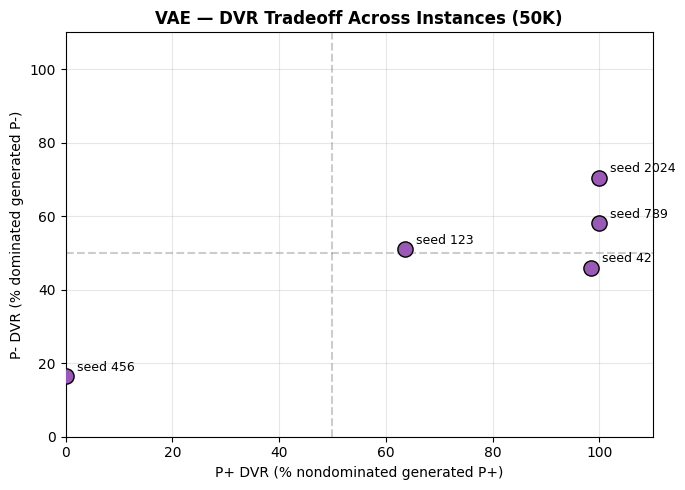

Saved → 17_dvr_tradeoff.png

  Step 10 Verification
  (OK) All 5 seeds completed
  (OK) AE results (5 seeds)
  (OK) VAE results (5 seeds)
  (OK) CVAE results (5 seeds)
  (OK) DVR across seeds
  (OK) Multiseed JSON saved
  (OK) Box plots saved
  (OK) All checks passed. Ready for Step 11!


In [ ]:
# DVR tradeoff scatter
seeds_list   = [r["seed"] for r in all_seed_results if "VAE" in r]
dvr_pos_list = [r["VAE"]["dvr_positive"]*100
                for r in all_seed_results if "VAE" in r]
dvr_neg_list = [r["VAE"]["dvr_negative"]*100
                for r in all_seed_results if "VAE" in r]

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(dvr_pos_list, dvr_neg_list,
           s=120, zorder=5, c="#9b59b6",
           edgecolors="black", linewidths=1)
for seed, px, py in zip(seeds_list, dvr_pos_list, dvr_neg_list):
    ax.annotate(f"seed {seed}", (px, py),
                textcoords="offset points",
                xytext=(8, 4), fontsize=9)
ax.set_xlabel("P+ DVR (% nondominated generated P+)")
ax.set_ylabel("P- DVR (% dominated generated P-)")
ax.set_title("VAE — DVR Tradeoff Across Instances (50K)",
             fontweight="bold")
ax.set_xlim(0, 110); ax.set_ylim(0, 110)
ax.axhline(50, color="gray", linestyle="--", alpha=0.4)
ax.axvline(50, color="gray", linestyle="--", alpha=0.4)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(f"{CONFIG['figures_dir']}/17_dvr_tradeoff.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("Saved → 17_dvr_tradeoff.png")

# Verification
print("\n" + "=" * 60)
print("  Step 10 Verification")
print("=" * 60)
checks = {
    "All 5 seeds completed"    : len(all_seed_results) == 5,
    "AE results (5 seeds)"     : len(metrics["AE"]["mse"]) == 5,
    "VAE results (5 seeds)"    : len(metrics["VAE"]["mse"]) == 5,
    "CVAE results (5 seeds)"   : len(metrics["CVAE"]["mse"]) == 5,
    "DVR across seeds"         : len(metrics["VAE"]["dvr_positive"]) == 5,
    "Multiseed JSON saved"     : os.path.exists(
                                   f"{CONFIG['results_dir']}/multiseed_results.json"),
    "Box plots saved"          : os.path.exists(
                                   f"{CONFIG['figures_dir']}/16_multiseed_boxplots.png"),
}
all_good = True
for name, status in checks.items():
    icon = "(OK)" if status else "(WARNING)"
    print(f"  {icon} {name}")
    if not status:
        all_good = False
print("=" * 60)
if all_good:
    print("  (OK) All checks passed. Ready for Step 11!")
else:
    print("  (CHECK) Fix items marked (WARNING) before continuing.")

# **Important Figures**

In [ ]:
plt.rcParams.update({
    "font.family"       : "serif",
    "font.size"         : 11,
    "axes.titlesize"    : 12,
    "axes.labelsize"    : 11,
    "xtick.labelsize"   : 10,
    "ytick.labelsize"   : 10,
    "legend.fontsize"   : 10,
    "figure.dpi"        : 150,
    "axes.spines.top"   : False,
    "axes.spines.right" : False,
})
# print("Publication style set.")
# print("Generating all final figures...\n")

## Dataset overview

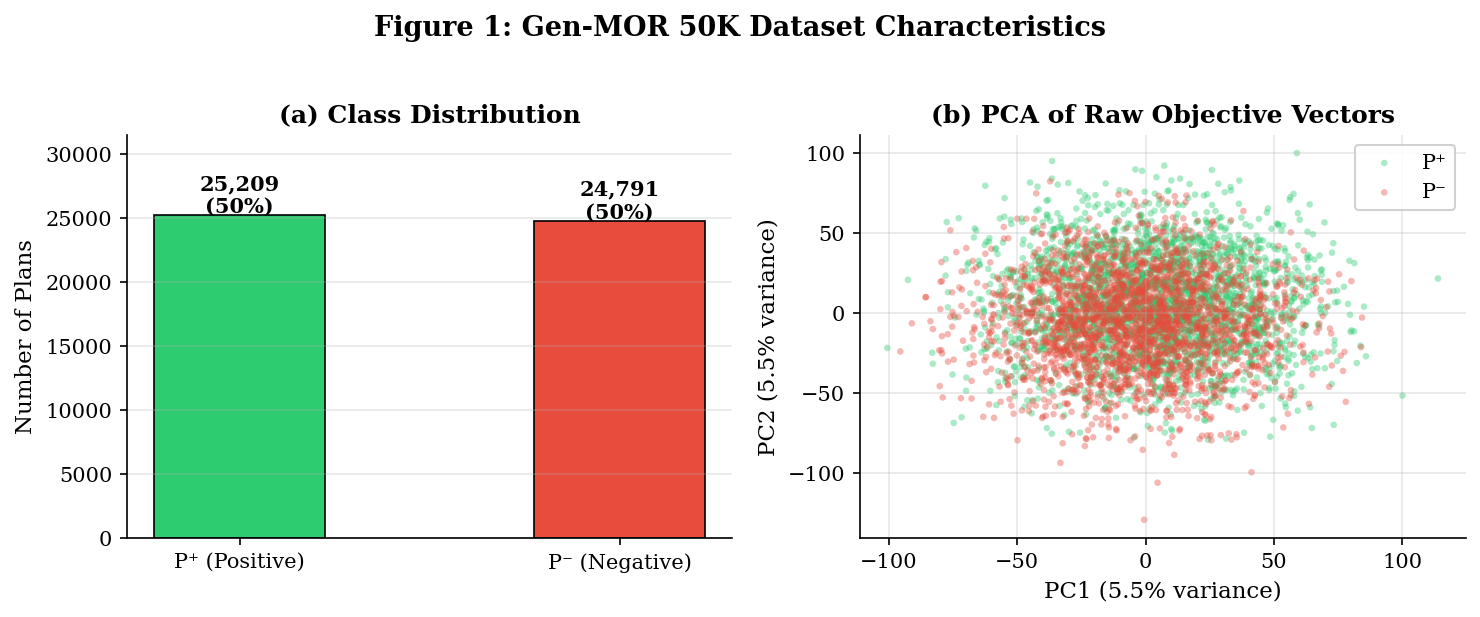

Saved → FIG1_dataset_overview.png (300 dpi)


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

counts     = [int((y==1).sum()), int((y==0).sum())]
bar_labels = ["P⁺ (Positive)", "P⁻ (Negative)"]
bar_colors = ["#2ecc71", "#e74c3c"]

bars = axes[0].bar(bar_labels, counts, color=bar_colors,
                   edgecolor="black", width=0.45, linewidth=0.8)
for bar, cnt in zip(bars, counts):
    axes[0].text(bar.get_x() + bar.get_width()/2,
                 cnt + 200,
                 f"{cnt:,}\n({cnt/sum(counts)*100:.0f}%)",
                 ha="center", fontsize=10, fontweight="bold")
axes[0].set_ylabel("Number of Plans")
axes[0].set_title("(a) Class Distribution", fontweight="bold")
axes[0].set_ylim(0, max(counts)*1.25)
axes[0].grid(True, alpha=0.3, axis="y")

for label, name, color in [(1,"P⁺","#2ecc71"),(0,"P⁻","#e74c3c")]:
    mask = (y_pca_sample == label)
    axes[1].scatter(X_pca[mask,0], X_pca[mask,1],
                    c=color, label=name,
                    alpha=0.4, s=10, edgecolors="none")
axes[1].set_xlabel(f"PC1 ({var_ratio[0]*100:.1f}% variance)")
axes[1].set_ylabel(f"PC2 ({var_ratio[1]*100:.1f}% variance)")
axes[1].set_title("(b) PCA of Raw Objective Vectors",
                  fontweight="bold")
axes[1].legend(framealpha=0.9)
axes[1].grid(True, alpha=0.3)

plt.suptitle("Figure 1: Gen-MOR 50K Dataset Characteristics",
             fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(f"{CONFIG['figures_dir']}/FIG1_dataset_overview.png",
            dpi=300, bbox_inches="tight")
plt.show()
print("Saved → FIG1_dataset_overview.png (300 dpi)")

## Training Curves

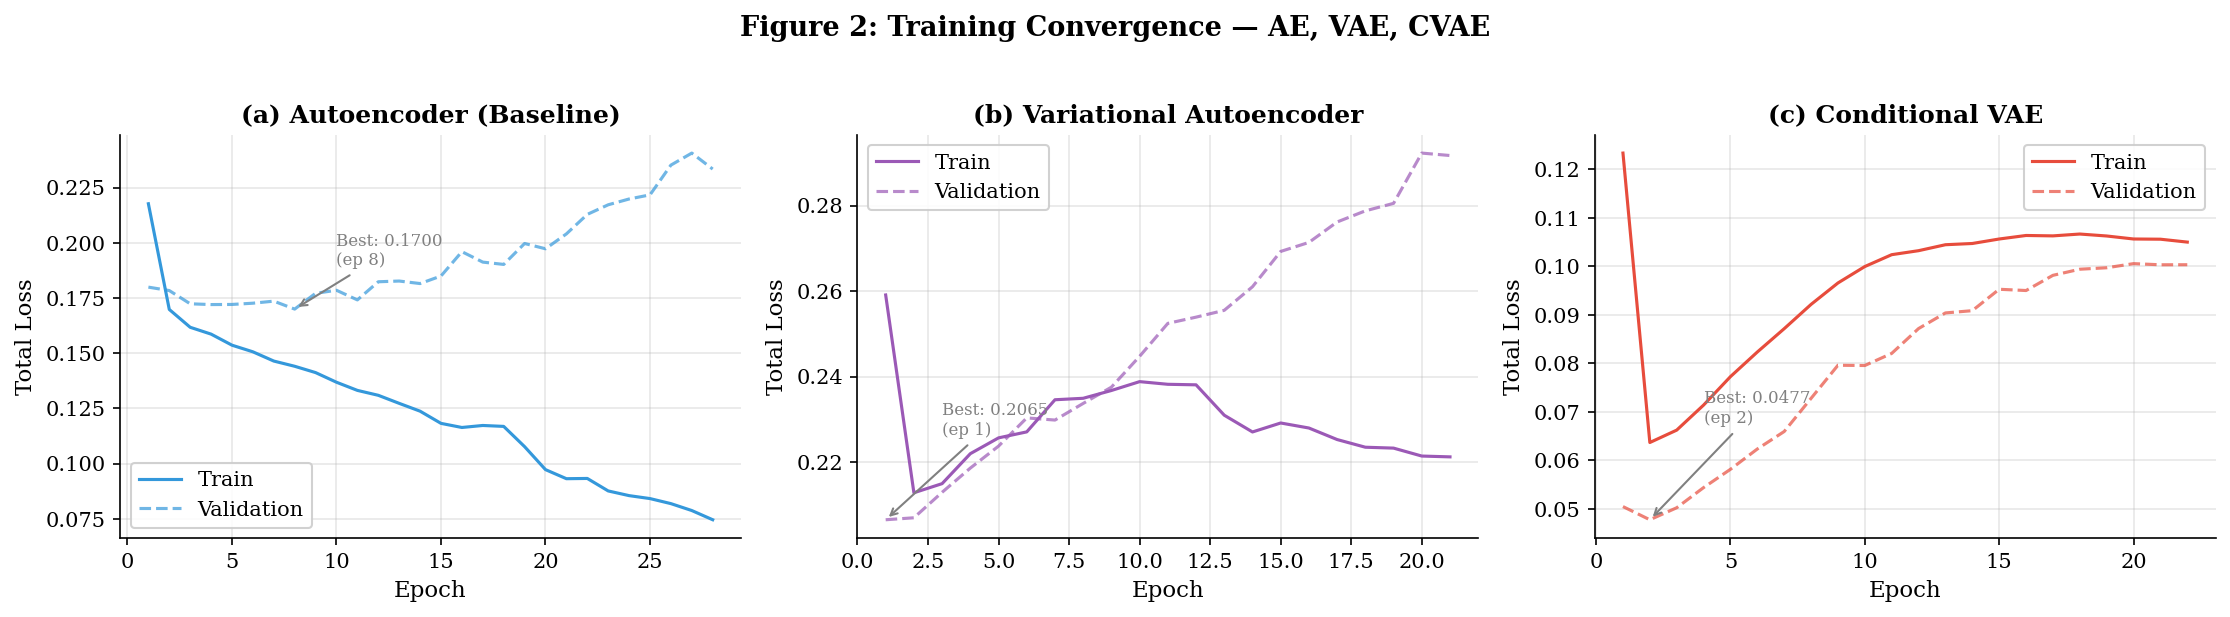

Saved → FIG2_training_curves.png (300 dpi)


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

model_configs = [
    (ae_history,   "AE",   "#3498db", "Autoencoder (Baseline)"),
    (vae_history,  "VAE",  "#9b59b6", "Variational Autoencoder"),
    (cvae_history, "CVAE", "#e74c3c", "Conditional VAE"),
]
for ax, (hist, name, color, title) in zip(axes, model_configs):
    ep = range(1, len(hist["train_loss"])+1)
    ax.plot(ep, hist["train_loss"],
            color=color, linewidth=1.5, label="Train")
    ax.plot(ep, hist["val_loss"],
            color=color, linewidth=1.5,
            linestyle="--", alpha=0.7, label="Validation")
    ax.set_title(f"({chr(97+model_configs.index((hist,name,color,title)))}) "
                 f"{title}", fontweight="bold")
    ax.set_xlabel("Epoch"); ax.set_ylabel("Total Loss")
    ax.legend(framealpha=0.9); ax.grid(True, alpha=0.3)
    best_ep   = int(np.argmin(hist["val_loss"]))+1
    best_loss = min(hist["val_loss"])
    ax.annotate(f"Best: {best_loss:.4f}\n(ep {best_ep})",
                xy=(best_ep, best_loss),
                xytext=(best_ep+2, best_loss+0.02),
                arrowprops={"arrowstyle":"->","color":"gray"},
                fontsize=8, color="gray")

plt.suptitle("Figure 2: Training Convergence — AE, VAE, CVAE",
             fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(f"{CONFIG['figures_dir']}/FIG2_training_curves.png",
            dpi=300, bbox_inches="tight")
plt.show()
print("Saved → FIG2_training_curves.png (300 dpi)")

## Latent Space Progression

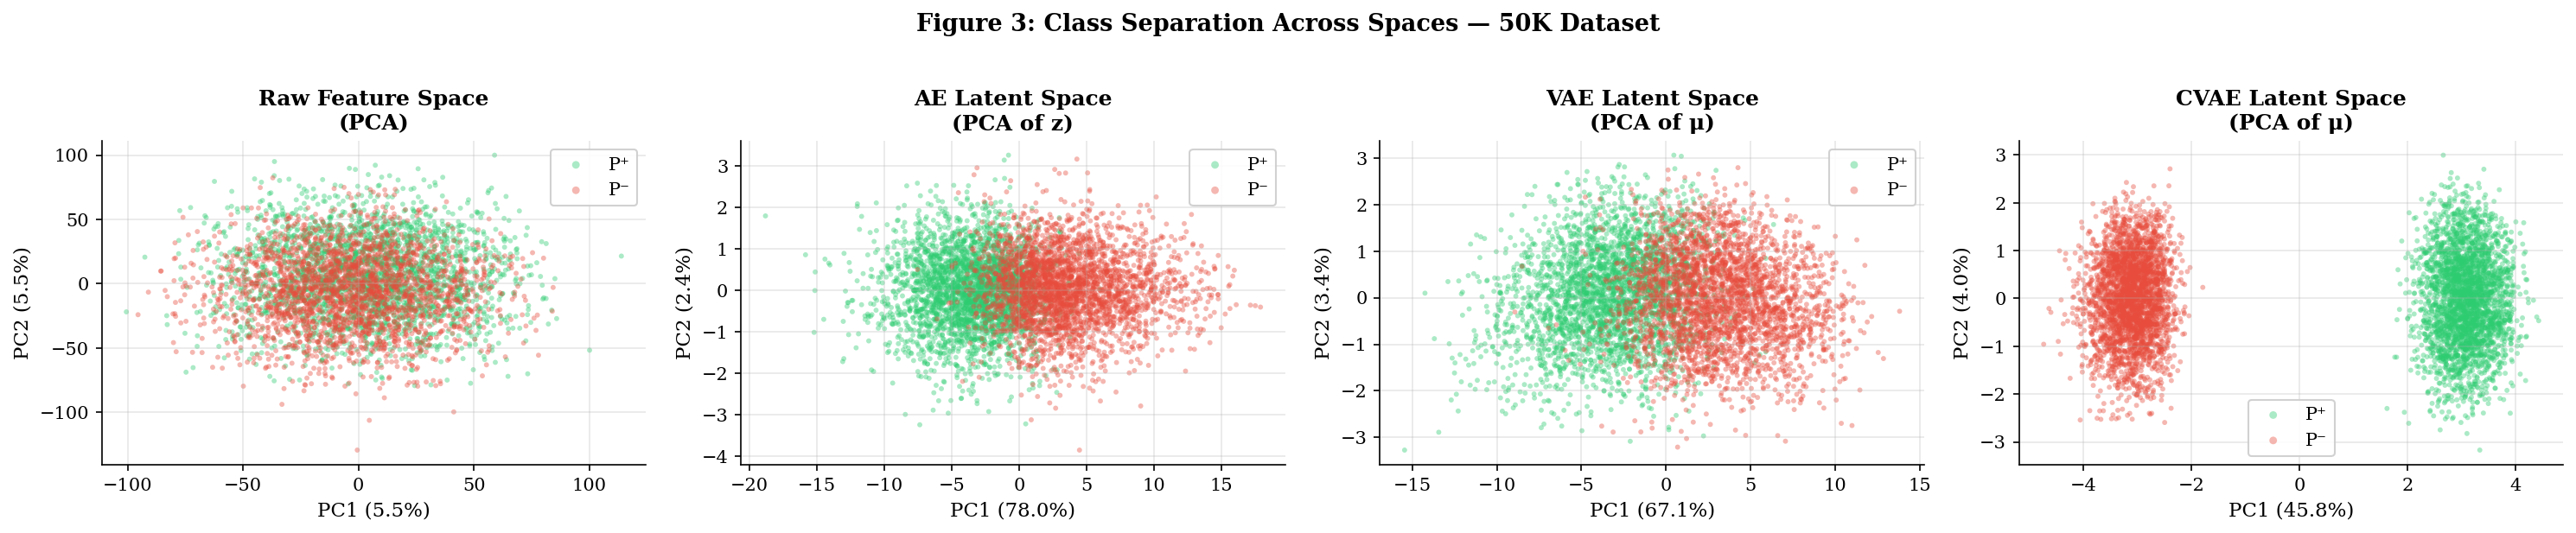

Saved → FIG3_latent_spaces.png (300 dpi)


In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))

space_configs = [
    (X_pca,      y_pca_sample,   var_ratio,     "Raw Feature Space\n(PCA)"),
    (z_pca,      all_y_full,     var_ratio_lat, "AE Latent Space\n(PCA of z)"),
    (mu_pca,     all_y_full_vae, var_vae,       "VAE Latent Space\n(PCA of μ)"),
    (cvae_mu_2d, all_cvae_y,     var_cvae,      "CVAE Latent Space\n(PCA of μ)"),
]
for ax, (coords, labels_arr, var, title) in zip(axes, space_configs):
    for label, name, color in [(1,"P⁺","#2ecc71"),(0,"P⁻","#e74c3c")]:
        mask = (labels_arr == label)
        idx  = np.random.choice(mask.sum(),
                                 min(3000, mask.sum()),
                                 replace=False)
        ax.scatter(coords[mask][idx,0],
                   coords[mask][idx,1],
                   c=color, label=name,
                   alpha=0.4, s=8, edgecolors="none")
    ax.set_title(title, fontweight="bold")
    ax.set_xlabel(f"PC1 ({var[0]*100:.1f}%)")
    ax.set_ylabel(f"PC2 ({var[1]*100:.1f}%)")
    ax.legend(framealpha=0.9, markerscale=1.5)
    ax.grid(True, alpha=0.3)

plt.suptitle("Figure 3: Class Separation Across Spaces — 50K Dataset",
             fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(f"{CONFIG['figures_dir']}/FIG3_latent_spaces.png",
            dpi=300, bbox_inches="tight")
plt.show()
print("Saved → FIG3_latent_spaces.png (300 dpi)")

## t-SNE

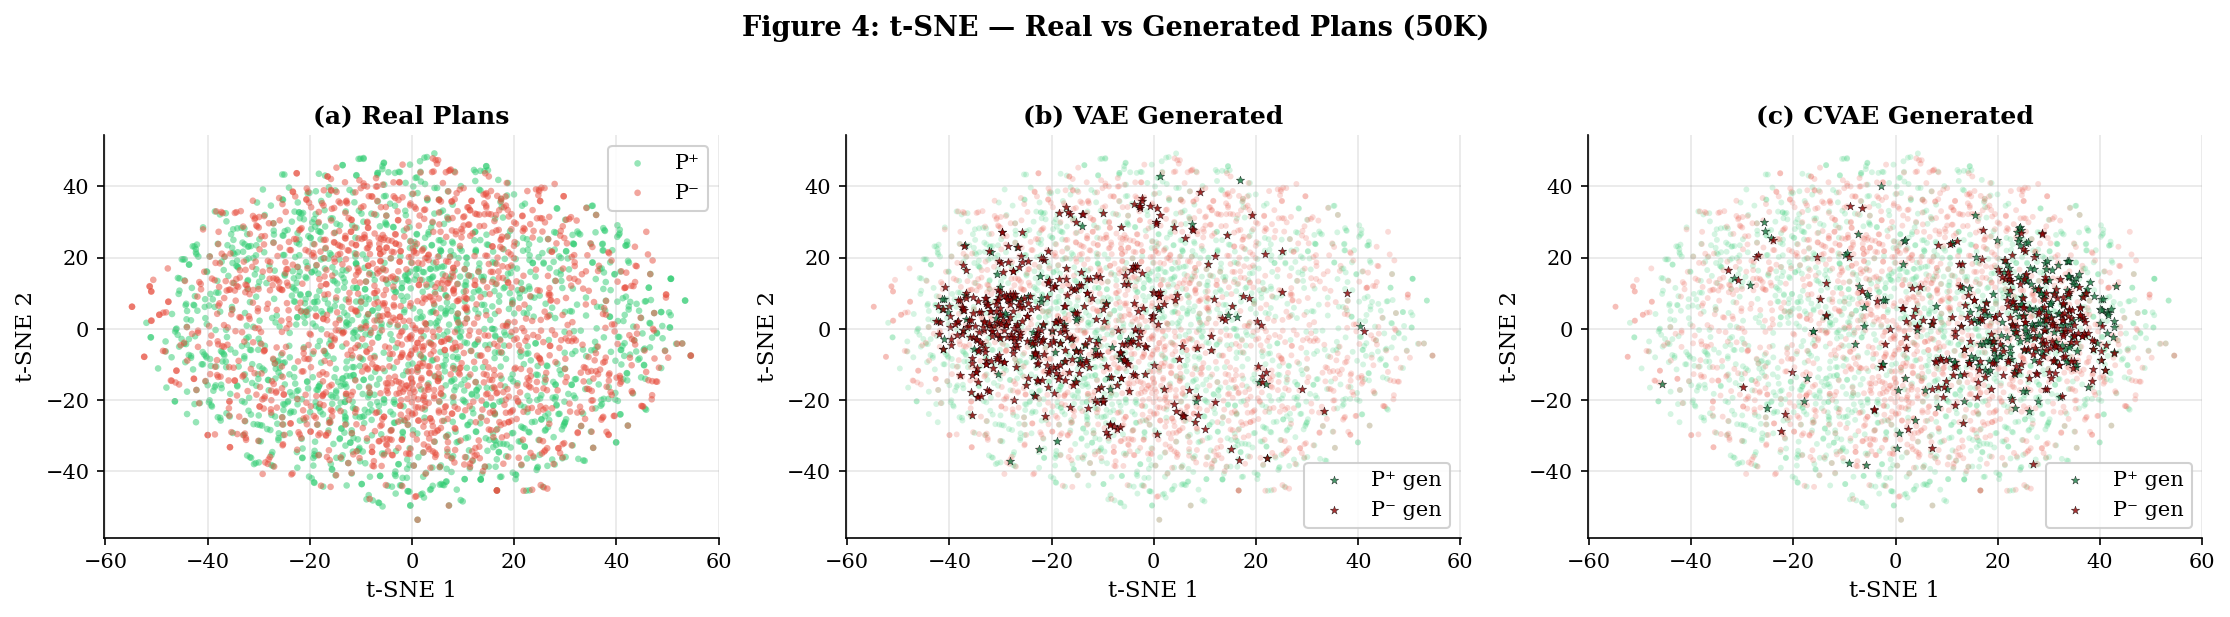

Saved → FIG4_tsne_generation.png (300 dpi)


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for label, name, color in [(1,"P⁺","#2ecc71"),(0,"P⁻","#e74c3c")]:
    mask = (class_labels==label) & (source_labels==0)
    axes[0].scatter(X_tsne[mask,0], X_tsne[mask,1],
                    c=color, label=name,
                    alpha=0.5, s=10, edgecolors="none")
axes[0].set_title("(a) Real Plans", fontweight="bold")
axes[0].legend(framealpha=0.9)
axes[0].set_xlabel("t-SNE 1"); axes[0].set_ylabel("t-SNE 2")
axes[0].grid(True, alpha=0.3)

for label, name, color in [(1,"P⁺","#2ecc71"),(0,"P⁻","#e74c3c")]:
    mask = (class_labels==label) & (source_labels==0)
    axes[1].scatter(X_tsne[mask,0], X_tsne[mask,1],
                    c=color, alpha=0.2, s=8, edgecolors="none")
for label, name, color in [(1,"P⁺ gen","#1a7a43"),
                            (0,"P⁻ gen","#8b0000")]:
    mask = (class_labels==(1 if "P⁺" in name else 0)) \
           & (source_labels==1)
    axes[1].scatter(X_tsne[mask,0], X_tsne[mask,1],
                    c=color, label=name, alpha=0.8,
                    s=18, marker="*",
                    edgecolors="black", linewidths=0.2)
axes[1].set_title("(b) VAE Generated", fontweight="bold")
axes[1].legend(framealpha=0.9)
axes[1].set_xlabel("t-SNE 1"); axes[1].set_ylabel("t-SNE 2")
axes[1].grid(True, alpha=0.3)

for label, name, color in [(1,"P⁺","#2ecc71"),(0,"P⁻","#e74c3c")]:
    mask = (class_labels==label) & (source_labels==0)
    axes[2].scatter(X_tsne[mask,0], X_tsne[mask,1],
                    c=color, alpha=0.2, s=8, edgecolors="none")
for label, name, color in [(1,"P⁺ gen","#1a7a43"),
                            (0,"P⁻ gen","#8b0000")]:
    mask = (class_labels==(1 if "P⁺" in name else 0)) \
           & (source_labels==2)
    axes[2].scatter(X_tsne[mask,0], X_tsne[mask,1],
                    c=color, label=name, alpha=0.8,
                    s=18, marker="*",
                    edgecolors="black", linewidths=0.2)
axes[2].set_title("(c) CVAE Generated", fontweight="bold")
axes[2].legend(framealpha=0.9)
axes[2].set_xlabel("t-SNE 1"); axes[2].set_ylabel("t-SNE 2")
axes[2].grid(True, alpha=0.3)

plt.suptitle("Figure 4: t-SNE — Real vs Generated Plans (50K)",
             fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(f"{CONFIG['figures_dir']}/FIG4_tsne_generation.png",
            dpi=300, bbox_inches="tight")
plt.show()
print("Saved → FIG4_tsne_generation.png (300 dpi)")

## DVR Results

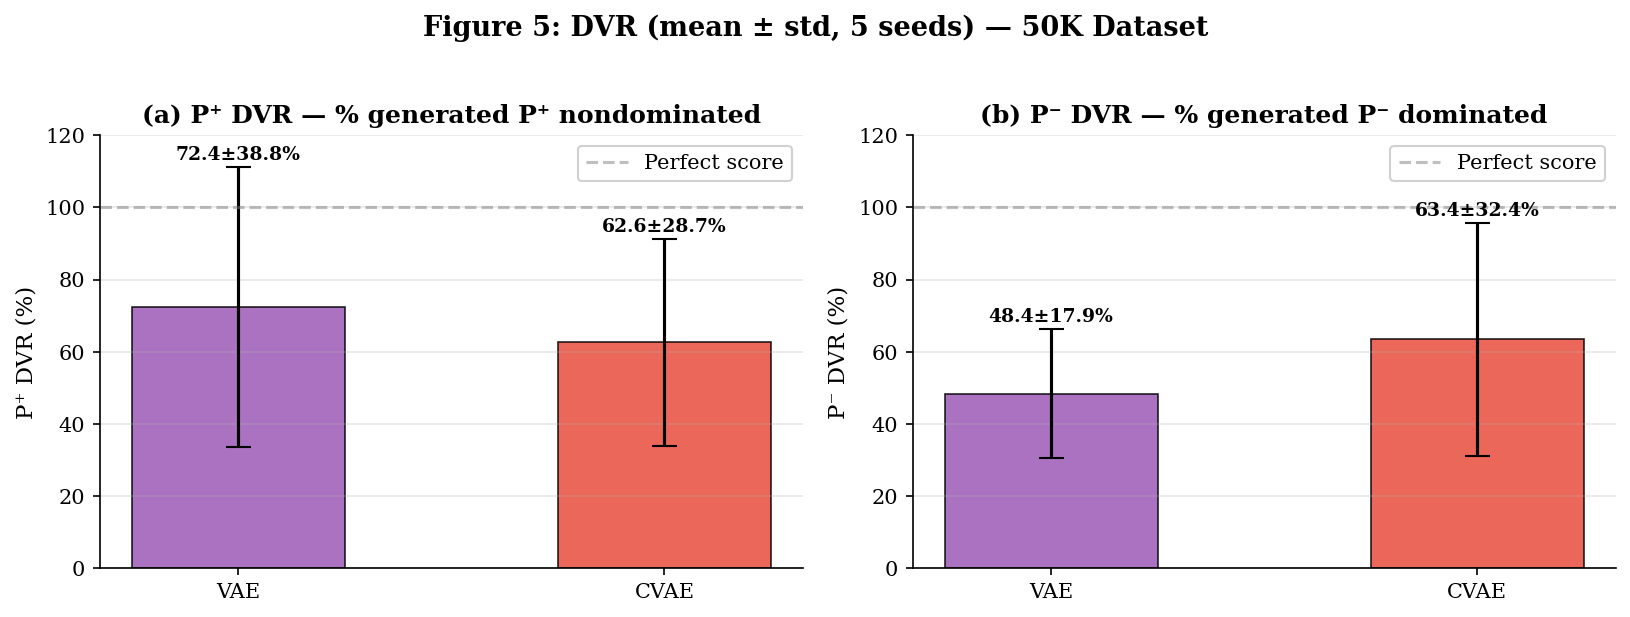

Saved → FIG5_dvr_results.png (300 dpi)


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

vae_dvr_pos_all  = metrics["VAE"]["dvr_positive"]
vae_dvr_neg_all  = metrics["VAE"]["dvr_negative"]
cvae_dvr_pos_all = metrics["CVAE"]["dvr_positive"]
cvae_dvr_neg_all = metrics["CVAE"]["dvr_negative"]

x      = np.array([0, 1])
colors = ["#9b59b6", "#e74c3c"]

for ax, (vals_list, ylabel, title_suffix) in zip(
    axes,
    [
        ([vae_dvr_pos_all, cvae_dvr_pos_all],
         "P⁺ DVR (%)",
         "(a) P⁺ DVR — % generated P⁺ nondominated"),
        ([vae_dvr_neg_all, cvae_dvr_neg_all],
         "P⁻ DVR (%)",
         "(b) P⁻ DVR — % generated P⁻ dominated"),
    ]
):
    means = [np.mean(v)*100 for v in vals_list]
    stds  = [np.std(v)*100  for v in vals_list]
    bars  = ax.bar(x, means, width=0.5, yerr=stds,
                   color=colors, edgecolor="black",
                   capsize=6, linewidth=0.8, alpha=0.85)
    ax.set_xticks(x)
    ax.set_xticklabels(["VAE", "CVAE"])
    ax.set_ylabel(ylabel)
    ax.set_title(title_suffix, fontweight="bold")
    ax.set_ylim(0, 120)
    ax.axhline(100, color="gray", linestyle="--",
               alpha=0.5, label="Perfect score")
    for bar, mean, std in zip(bars, means, stds):
        ax.text(bar.get_x() + bar.get_width()/2,
                mean + std + 2,
                f"{mean:.1f}±{std:.1f}%",
                ha="center", fontsize=9, fontweight="bold")
    ax.legend(framealpha=0.9)
    ax.grid(True, alpha=0.3, axis="y")

plt.suptitle("Figure 5: DVR (mean ± std, 5 seeds) — 50K Dataset",
             fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(f"{CONFIG['figures_dir']}/FIG5_dvr_results.png",
            dpi=300, bbox_inches="tight")
plt.show()
print("Saved → FIG5_dvr_results.png (300 dpi)")

## DVR Tradeoff + Interpolation

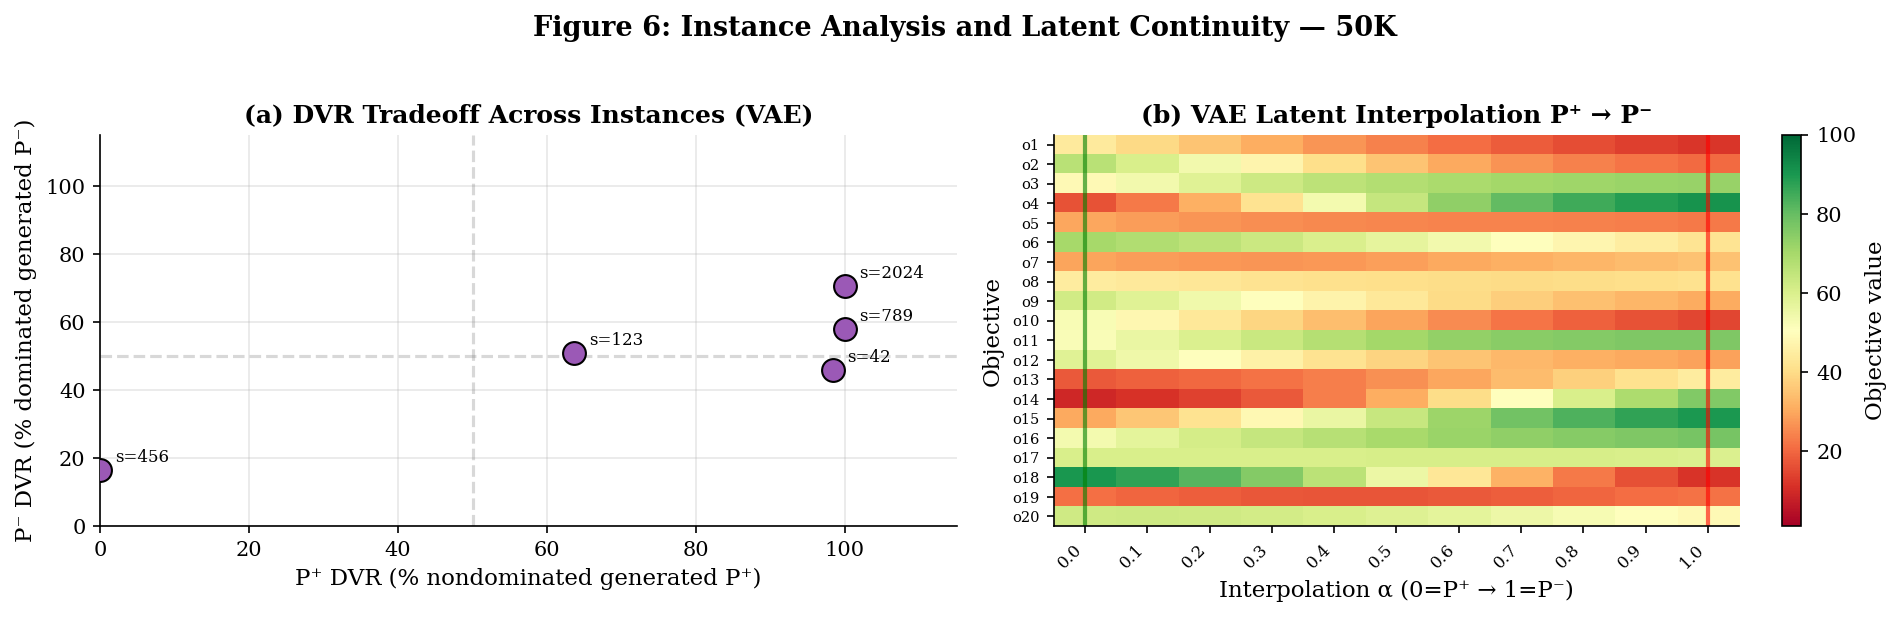

Saved → FIG6_tradeoff_interpolation.png (300 dpi)


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# DVR scatter
axes[0].scatter(dvr_pos_list, dvr_neg_list,
                s=120, zorder=5, c="#9b59b6",
                edgecolors="black", linewidths=1)
for seed, px, py in zip(seeds_list, dvr_pos_list, dvr_neg_list):
    axes[0].annotate(f"s={seed}", (px, py),
                     textcoords="offset points",
                     xytext=(7, 4), fontsize=8)
axes[0].set_xlabel("P⁺ DVR (% nondominated generated P⁺)")
axes[0].set_ylabel("P⁻ DVR (% dominated generated P⁻)")
axes[0].set_title("(a) DVR Tradeoff Across Instances (VAE)",
                  fontweight="bold")
axes[0].set_xlim(0, 115); axes[0].set_ylim(0, 115)
axes[0].axhline(50, color="gray", linestyle="--", alpha=0.3)
axes[0].axvline(50, color="gray", linestyle="--", alpha=0.3)
axes[0].grid(True, alpha=0.3)

# Interpolation heatmap
im = axes[1].imshow(vae_interp_orig.T, aspect="auto",
                     cmap="RdYlGn", vmin=1, vmax=100,
                     interpolation="nearest")
axes[1].set_yticks(range(20))
axes[1].set_yticklabels([f"o{i+1}" for i in range(20)], fontsize=7)
axes[1].set_xticks(range(len(alphas)))
axes[1].set_xticklabels([f"{a:.1f}" for a in alphas],
                          rotation=45, ha="right", fontsize=8)
axes[1].set_xlabel("Interpolation α (0=P⁺ → 1=P⁻)")
axes[1].set_ylabel("Objective")
axes[1].set_title("(b) VAE Latent Interpolation P⁺ → P⁻",
                  fontweight="bold")
axes[1].axvline(x=0,            color="green", linewidth=2, alpha=0.6)
axes[1].axvline(x=len(alphas)-1, color="red",  linewidth=2, alpha=0.6)
plt.colorbar(im, ax=axes[1], label="Objective value")

plt.suptitle("Figure 6: Instance Analysis and Latent Continuity — 50K",
             fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(f"{CONFIG['figures_dir']}/FIG6_tradeoff_interpolation.png",
            dpi=300, bbox_inches="tight")
plt.show()
print("Saved → FIG6_tradeoff_interpolation.png (300 dpi)")

## Multi-Seed Summary

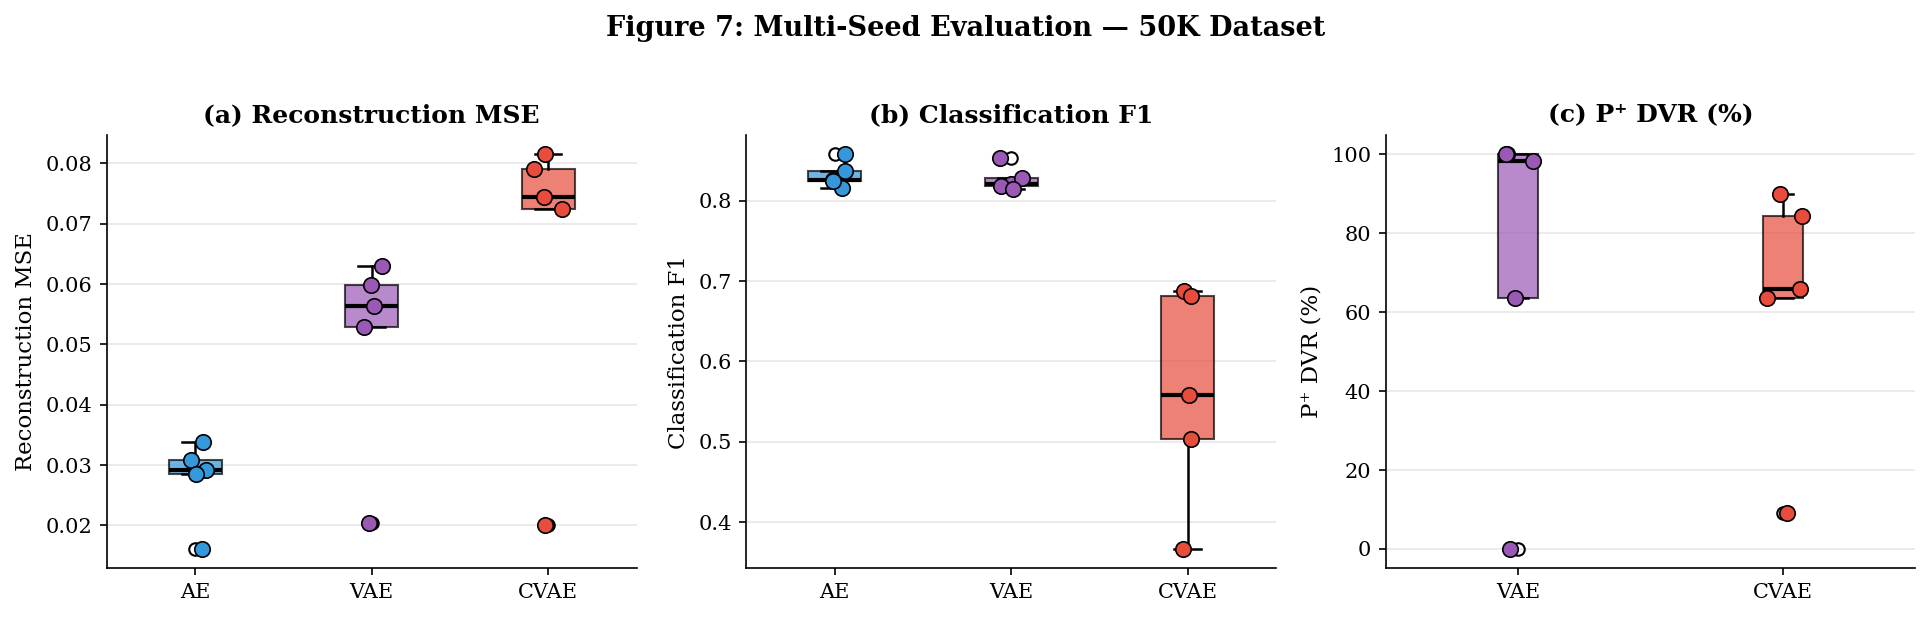

Saved → FIG7_multiseed_summary.png (300 dpi)


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

colors_pub = {"AE":"#3498db","VAE":"#9b59b6","CVAE":"#e74c3c"}
plot_cfgs  = [
    ("Reconstruction MSE", "mse",          ["AE","VAE","CVAE"], False),
    ("Classification F1",  "f1",           ["AE","VAE","CVAE"], False),
    ("P⁺ DVR (%)",         "dvr_positive", ["VAE","CVAE"],      True),
]

for ax, (ylabel, metric, models, is_pct) in zip(axes, plot_cfgs):
    data_plot=[]; labels_plot=[]; colors_plot=[]
    for mn in models:
        vals = metrics[mn].get(metric, [])
        if vals:
            data_plot.append(
                [v*100 if is_pct else v for v in vals])
            labels_plot.append(mn)
            colors_plot.append(colors_pub[mn])

    bp = ax.boxplot(data_plot, patch_artist=True,
                    medianprops={"color":"black","linewidth":2},
                    whiskerprops={"linewidth":1.2},
                    capprops={"linewidth":1.2})
    for patch, color in zip(bp["boxes"], colors_plot):
        patch.set_facecolor(color); patch.set_alpha(0.7)

    for i, (vals, color) in enumerate(
            zip(data_plot, colors_plot), start=1):
        jitter = np.random.uniform(-0.08, 0.08, len(vals))
        ax.scatter(np.array([i]*len(vals)) + jitter, vals,
                   color=color, zorder=5, s=55,
                   edgecolors="black", linewidths=0.8)

    ax.set_xticks(range(1, len(labels_plot)+1))
    ax.set_xticklabels(labels_plot)
    ax.set_ylabel(ylabel)
    ax.grid(True, alpha=0.3, axis="y")

axes[0].set_title("(a) Reconstruction MSE", fontweight="bold")
axes[1].set_title("(b) Classification F1",  fontweight="bold")
axes[2].set_title("(c) P⁺ DVR (%)",         fontweight="bold")

plt.suptitle("Figure 7: Multi-Seed Evaluation — 50K Dataset",
             fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(f"{CONFIG['figures_dir']}/FIG7_multiseed_summary.png",
            dpi=300, bbox_inches="tight")
plt.show()
print("Saved → FIG7_multiseed_summary.png (300 dpi)")

# **This Notebook Ends Here**

# **NEW ADDITIONS**

# **DVR for Plain Autoencoder (AE)**

*The Plain AE is **not natively a generative model** — it has no defined prior over its latent space, unlike the VAE (which uses N(0, I)) or the CVAE (which conditions on a label). To compute DVR for the AE we therefore fit an **empirical latent prior** from the encoded training set and sample from it. This is a post-hoc generation procedure and the methodological assumption is stated explicitly inside each cell.*

*We add two parallel DVR pipelines so the AE can be compared on equal footing against both the VAE and the CVAE:*

*- **Approach 1: VAE-analog (unconditional):** fit one Gaussian to the full training-latent cloud, sample 2000 latents, decode, then split into P+ / P- using the classifier head. Mirrors the VAE-DVR cell exactly.*

*- **Approach 2: CVAE-analog (class-conditional):** fit one Gaussian per class to the encoded P+ and P- training latents separately, sample 500 from each, decode. Mirrors the CVAE-DVR cell exactly.*

## Fit Empirical Latent Priors

*We reload the seed-42 AE checkpoint (saved as `ae_best.pt` during the original training in Step 5; the global `ae_model` object may otherwise be holding weights from the last multi-seed run). We then encode the full training split through `ae_model.encode` in non-shuffled mini-batches of 512 to collect a `(n_train, 16)` matrix of latent vectors paired with their true labels. From these training latents we fit three multivariate Gaussians by maximum likelihood: one unconditional Gaussian over all training latents (for Approach 1), and one Gaussian each over the P+ subset and the P- subset (for Approach 2). A small jitter of 1e-6·I is added to each covariance matrix to keep `numpy.random.multivariate_normal` numerically safe — at 16 dimensions with thousands of samples the empirical covariance is well-conditioned, but the jitter guards against any rank-deficiency edge case.*

In [ ]:
# Reload the best AE checkpoint to guarantee seed-42 weights
# (the global ae_model may have been overwritten by the multi-seed loop)
ae_model.load_state_dict(torch.load(ae_checkpoint, map_location=device))
ae_model.eval()

# Encode the full training split through the AE
# Using direct numpy iteration (no shuffle) so latents stay aligned with y_train
ae_z_train = []
_batch     = 512
with torch.no_grad():
    for i in range(0, len(X_train_scaled), _batch):
        xb = torch.tensor(
            X_train_scaled[i:i+_batch], dtype=torch.float32
        ).to(device)
        ae_z_train.append(ae_model.encode(xb).cpu().numpy())
ae_z_train = np.concatenate(ae_z_train)  # (n_train, 16)

latent_dim = ae_z_train.shape[1]
jitter     = 1e-6 * np.eye(latent_dim)

# Approach 1 — unconditional Gaussian over all training latents
ae_mu_uncond  = ae_z_train.mean(axis=0)
ae_cov_uncond = np.cov(ae_z_train.T) + jitter

# Approach 2 — class-conditional Gaussians
ae_z_pos = ae_z_train[y_train == 1]
ae_z_neg = ae_z_train[y_train == 0]

ae_mu_pos  = ae_z_pos.mean(axis=0)
ae_cov_pos = np.cov(ae_z_pos.T) + jitter
ae_mu_neg  = ae_z_neg.mean(axis=0)
ae_cov_neg = np.cov(ae_z_neg.T) + jitter

print("=" * 55)
print("  Empirical Latent Priors fitted to AE training latents")
print("=" * 55)
print(f"  Total training latents     : {ae_z_train.shape[0]:,}")
print(f"  Latent dimension           : {latent_dim}")
print(f"  P+ training latents        : {ae_z_pos.shape[0]:,}")
print(f"  P- training latents        : {ae_z_neg.shape[0]:,}")
print(f"  Unconditional ||mu||       : {np.linalg.norm(ae_mu_uncond):.4f}")
print(f"  ||mu_pos - mu_neg||        : "
      f"{np.linalg.norm(ae_mu_pos - ae_mu_neg):.4f}")
print(f"  trace(cov_uncond)          : {np.trace(ae_cov_uncond):.4f}")
print("=" * 55)

  Empirical Latent Priors fitted to AE training latents
  Total training latents     : 34,999
  Latent dimension           : 16
  P+ training latents        : 17,646
  P- training latents        : 17,353
  Unconditional ||mu||       : 1.1516
  ||mu_pos - mu_neg||        : 7.5128
  trace(cov_uncond)          : 32.0381


## Approach 1 — VAE-Analog DVR (Unconditional Sampling + Classifier Split)

*This cell mirrors the VAE-DVR cell exactly. We draw 2000 latent vectors from the unconditional empirical Gaussian we just fitted, decode them through `ae_model.decode` to get 20-dimensional generated plans in scaled space, run them through `ae_model.classifier` to get a predicted P+/P- label, then inverse-transform back to the original [1, 100] objective scale and split into predicted-P+ and predicted-P- groups. Each group is then evaluated against the same 10K real-plan reference pool using `compute_dvr_chunked` with `sample_size=500` and `chunk_size=5000` — the exact same hyperparameters used for VAE-DVR and CVAE-DVR. If either group happens to be empty (possible if the classifier collapses to one class), the corresponding DVR is reported as 0.0 with `n_gen=0`, matching the safety pattern in the existing VAE-DVR cell.*

In [ ]:
np.random.seed(CONFIG["seed"])
torch.manual_seed(CONFIG["seed"])

N_AE_UNCOND = 2000  # matches VAE: 2000 then classifier-split

# Sample latents from the unconditional empirical Gaussian
ae_z_uncond = np.random.multivariate_normal(
    ae_mu_uncond, ae_cov_uncond, size=N_AE_UNCOND
).astype(np.float32)

ae_model.eval()
with torch.no_grad():
    zt           = torch.tensor(ae_z_uncond).to(device)
    # Decode them into 20D plans (in scaled space)
    ae_gen_scaled_u = ae_model.decode(zt).cpu().numpy()
    # Run the same plans through the classifier head to get predicted labels
    ae_yp_u         = ae_model.classifier(zt).squeeze(1).cpu().numpy()

ae_yb_u    = (ae_yp_u >= 0.5).astype(int)
# Inverse-transform back to original [1, 100] objective scale
ae_gen_orig_u = np.clip(
    scaler.inverse_transform(ae_gen_scaled_u), 1, 100
)

# Split into predicted P+ and predicted P-
ae_gen_pos_u = ae_gen_orig_u[ae_yb_u == 1]
ae_gen_neg_u = ae_gen_orig_u[ae_yb_u == 0]

print(f"AE (Approach 1) — generated {N_AE_UNCOND} unconditional samples")
print(f"  Classifier-predicted P+ : {len(ae_gen_pos_u):,}")
print(f"  Classifier-predicted P- : {len(ae_gen_neg_u):,}")

# Compute DVR for each group against the 10k reference pool
# First, for P+
if len(ae_gen_pos_u) > 0:
    ae_dvr_pos_u, ae_vp_u, ae_np_u = compute_dvr_chunked(
        ae_gen_pos_u, X_sel_full, selected_indices,
        target="positive",
        sample_size = CONFIG["dvr_sample_size"],
        ref_size    = CONFIG["dvr_ref_size"],
        chunk_size  = CONFIG["dvr_chunk_size"],
        seed        = CONFIG["seed"],
    )
else:
    ae_dvr_pos_u, ae_vp_u, ae_np_u = 0.0, 0, 0

# Second, for P-
if len(ae_gen_neg_u) > 0:
    ae_dvr_neg_u, ae_vn_u, ae_nn_u = compute_dvr_chunked(
        ae_gen_neg_u, X_sel_full, selected_indices,
        target="negative",
        sample_size = CONFIG["dvr_sample_size"],
        ref_size    = CONFIG["dvr_ref_size"],
        chunk_size  = CONFIG["dvr_chunk_size"],
        seed        = CONFIG["seed"],
    )
else:
    ae_dvr_neg_u, ae_vn_u, ae_nn_u = 0.0, 0, 0

print(f"AE (Approach 1) — P+ DVR: {ae_dvr_pos_u*100:.1f}% "
      f"({ae_vp_u}/{ae_np_u} nondominated)")
print(f"AE (Approach 1) — P- DVR: {ae_dvr_neg_u*100:.1f}% "
      f"({ae_vn_u}/{ae_nn_u} dominated)")

AE (Approach 1) — generated 2000 unconditional samples
  Classifier-predicted P+ : 952
  Classifier-predicted P- : 1,048
AE (Approach 1) — P+ DVR: 90.6% (453/500 nondominated)
AE (Approach 1) — P- DVR: 72.0% (360/500 dominated)


## Approach 2 — CVAE-Analog DVR (Class-Conditional Sampling)

*This cell mirrors the CVAE-DVR cell exactly. We draw 500 latent vectors from the P+ empirical Gaussian and 500 from the P- empirical Gaussian, decode each group separately, and inverse-transform to original scale. Because each group is constructed by sampling from a region of latent space populated entirely by true-P+ (or true-P-) training plans, we can compute DVR for each group directly without consulting the classifier head — exactly the way the CVAE-DVR evaluation does. P+ samples are scored with `target="positive"` (valid = nondominated by the reference pool); P- samples with `target="negative"` (valid = dominated by at least one plan in the reference pool).*

In [ ]:
np.random.seed(CONFIG["seed"])
torch.manual_seed(CONFIG["seed"])

N_AE_PER_CLASS = 500  # matches CVAE: 500 P+ and 500 P-

# Sample from per-class empirical Gaussians
ae_z_pos_samp = np.random.multivariate_normal(
    ae_mu_pos, ae_cov_pos, size=N_AE_PER_CLASS
).astype(np.float32)
ae_z_neg_samp = np.random.multivariate_normal(
    ae_mu_neg, ae_cov_neg, size=N_AE_PER_CLASS
).astype(np.float32)

ae_model.eval()
with torch.no_grad():
    ae_gen_pos_scaled_c = ae_model.decode(
        torch.tensor(ae_z_pos_samp).to(device)
    ).cpu().numpy()
    ae_gen_neg_scaled_c = ae_model.decode(
        torch.tensor(ae_z_neg_samp).to(device)
    ).cpu().numpy()

ae_gen_pos_orig_c = np.clip(
    scaler.inverse_transform(ae_gen_pos_scaled_c), 1, 100
)
ae_gen_neg_orig_c = np.clip(
    scaler.inverse_transform(ae_gen_neg_scaled_c), 1, 100
)

print(f"AE (Approach 2) — generated "
      f"{N_AE_PER_CLASS} P+ and {N_AE_PER_CLASS} P- samples")

ae_dvr_pos_c, ae_vp_c, ae_np_c = compute_dvr_chunked(
    ae_gen_pos_orig_c, X_sel_full, selected_indices,
    target="positive",
    sample_size = CONFIG["dvr_sample_size"],
    ref_size    = CONFIG["dvr_ref_size"],
    chunk_size  = CONFIG["dvr_chunk_size"],
    seed        = CONFIG["seed"],
)
ae_dvr_neg_c, ae_vn_c, ae_nn_c = compute_dvr_chunked(
    ae_gen_neg_orig_c, X_sel_full, selected_indices,
    target="negative",
    sample_size = CONFIG["dvr_sample_size"],
    ref_size    = CONFIG["dvr_ref_size"],
    chunk_size  = CONFIG["dvr_chunk_size"],
    seed        = CONFIG["seed"],
)

print(f"AE (Approach 2) — P+ DVR: {ae_dvr_pos_c*100:.1f}% "
      f"({ae_vp_c}/{ae_np_c} nondominated)")
print(f"AE (Approach 2) — P- DVR: {ae_dvr_neg_c*100:.1f}% "
      f"({ae_vn_c}/{ae_nn_c} dominated)")

AE (Approach 2) — generated 500 P+ and 500 P- samples
AE (Approach 2) — P+ DVR: 86.6% (433/500 nondominated)
AE (Approach 2) — P- DVR: 72.2% (361/500 dominated)


## Updated Comparison Table (AE + VAE + CVAE)

*We extend the existing results table to include both AE-DVR variants alongside the VAE and CVAE numbers. The classification accuracy and reconstruction MSE for the AE come from the `ae_results` dictionary already saved in Step 5; the DVR columns are the four new numbers we just computed. This cell only reads pre-computed values — it does not recompute anything — so it is safe to re-run.*

In [ ]:
print("=" * 78)
print("  Gen-MOR 50K — Full Quantitative Results (incl. AE-DVR)")
print("=" * 78)
print(f"  {'Metric':<35} {'AE-Unc':>9} {'AE-Con':>9} "
      f"{'VAE':>8} {'CVAE':>8}")
print("-" * 78)
print(f"  {'P+ DVR (gen P+ nondominated)':<35} "
      f"{ae_dvr_pos_u*100:>8.1f}% {ae_dvr_pos_c*100:>8.1f}% "
      f"{vae_dvr_pos*100:>7.1f}% {cvae_dvr_pos*100:>7.1f}%")
print(f"  {'P- DVR (gen P- dominated)':<35} "
      f"{ae_dvr_neg_u*100:>8.1f}% {ae_dvr_neg_c*100:>8.1f}% "
      f"{vae_dvr_neg*100:>7.1f}% {cvae_dvr_neg*100:>7.1f}%")
print("=" * 78)
print("  AE-Unc = Approach 1 (unconditional latent sampling + "
      "classifier split)")
print("  AE-Con = Approach 2 (class-conditional latent sampling)")
print(f"  Ref pool: {CONFIG['dvr_ref_size']:,} real plans   "
      f"|   Eval sample: {CONFIG['dvr_sample_size']} per group")

  Gen-MOR 50K — Full Quantitative Results (incl. AE-DVR)
  Metric                                 AE-Unc    AE-Con      VAE     CVAE
------------------------------------------------------------------------------
  P+ DVR (gen P+ nondominated)            90.6%     86.6%    87.3%    70.2%
  P- DVR (gen P- dominated)               72.0%     72.2%    46.0%    26.6%
  AE-Unc = Approach 1 (unconditional latent sampling + classifier split)
  AE-Con = Approach 2 (class-conditional latent sampling)
  Ref pool: 10,000 real plans   |   Eval sample: 500 per group


## Updated DVR Bar Chart

*We extend the existing DVR bar chart (`12_dvr_results.png`) to include both AE variants. The new figure has the same two-panel structure as the original — P+ DVR on the left, P- DVR on the right — but with four bars per panel instead of two. We save it as `13_dvr_results_with_ae.png` so the original figure is preserved for the existing references in the notebook. Higher is better for both panels: a high P+ DVR means generated P+ plans are genuinely nondominated, and a high P- DVR means generated P- plans are genuinely dominated.*

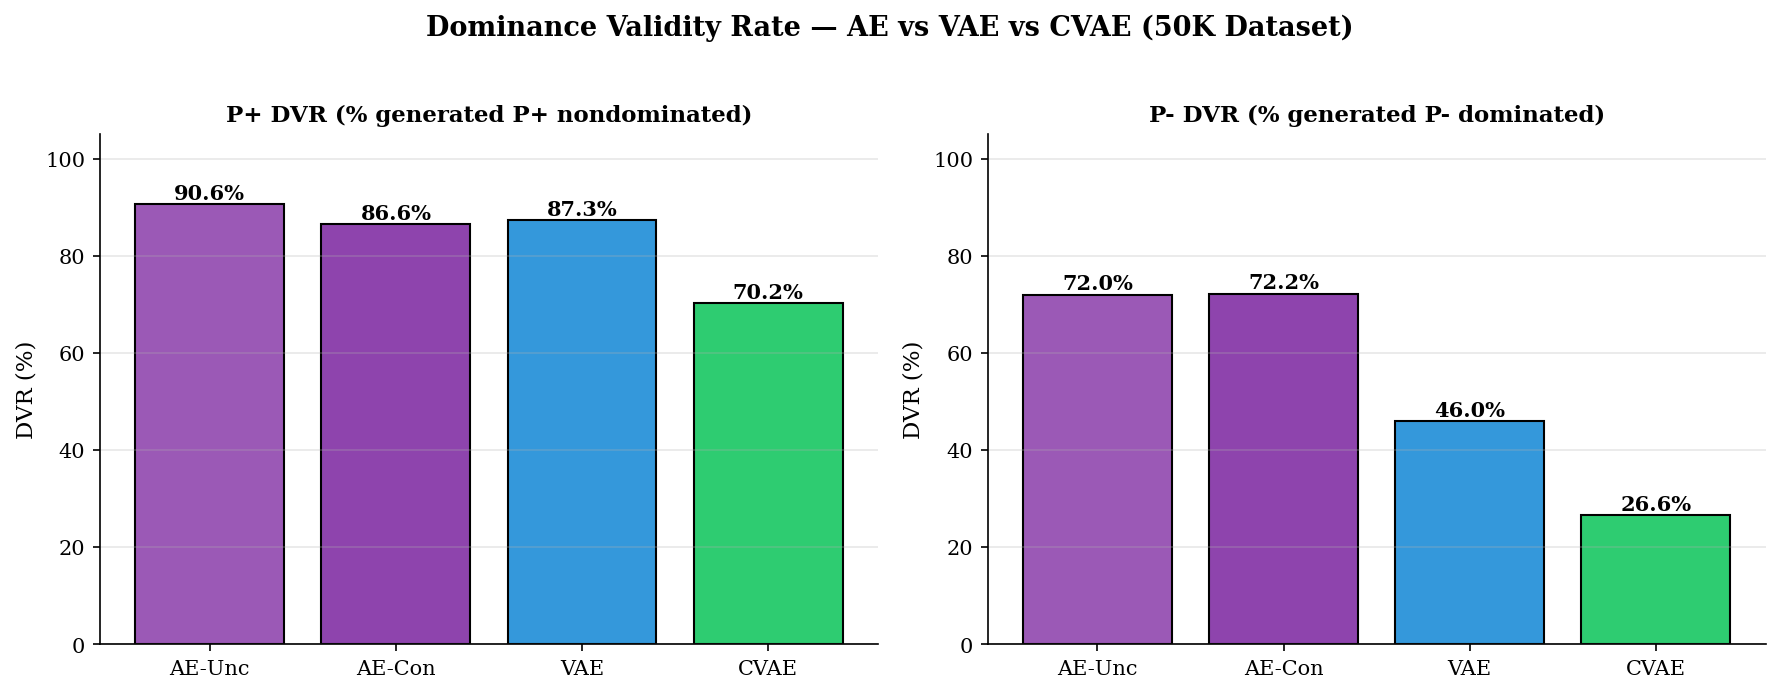

Saved → 13_dvr_results_with_ae.png


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

models_dvr_full = ["AE-Unc", "AE-Con", "VAE", "CVAE"]
colors_full     = ["#9b59b6", "#8e44ad", "#3498db", "#2ecc71"]

dvr_pos_full = [ae_dvr_pos_u*100, ae_dvr_pos_c*100,
                vae_dvr_pos*100,  cvae_dvr_pos*100]
dvr_neg_full = [ae_dvr_neg_u*100, ae_dvr_neg_c*100,
                vae_dvr_neg*100,  cvae_dvr_neg*100]

for ax, vals, title in zip(
    axes,
    [dvr_pos_full, dvr_neg_full],
    ["P+ DVR (% generated P+ nondominated)",
     "P- DVR (% generated P- dominated)"]
):
    bars = ax.bar(models_dvr_full, vals,
                  color=colors_full, edgecolor="black")
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width()/2,
                v + 1, f"{v:.1f}%",
                ha="center", fontsize=10, fontweight="bold")
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.set_ylim(0, max(105, max(vals) + 10))
    ax.set_ylabel("DVR (%)")
    ax.grid(True, alpha=0.3, axis="y")

plt.suptitle(
    "Dominance Validity Rate — AE vs VAE vs CVAE (50K Dataset)",
    fontsize=13, fontweight="bold", y=1.02
)
plt.tight_layout()
plt.savefig(f"{CONFIG['figures_dir']}/13_dvr_results_with_ae.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("Saved → 13_dvr_results_with_ae.png")

## Save AE DVR Results

*We persist the AE-DVR numbers in a new file `ae_dvr_results.json` rather than overwriting the existing `ae_results.json` so that the original Step-5 artifacts are left untouched. The file records both approach variants together with the underlying configuration (reference-pool size, evaluation sample size, chunk size, seed, and the number of generated samples used per approach) so the experiment is fully reproducible.*

In [ ]:
ae_dvr_results = {
    "model": "Plain Autoencoder",
    "approach_1_unconditional": {
        "description"   : "VAE-analog: sample from unconditional "
                          "empirical latent Gaussian, decode, "
                          "classifier-split into P+/P-.",
        "n_generated"   : int(N_AE_UNCOND),
        "n_pred_pos"    : int(len(ae_gen_pos_u)),
        "n_pred_neg"    : int(len(ae_gen_neg_u)),
        "dvr_positive"  : float(ae_dvr_pos_u),
        "dvr_negative"  : float(ae_dvr_neg_u),
        "valid_pos"     : int(ae_vp_u),
        "eval_pos"      : int(ae_np_u),
        "valid_neg"     : int(ae_vn_u),
        "eval_neg"      : int(ae_nn_u),
    },
    "approach_2_conditional": {
        "description"   : "CVAE-analog: sample from class-conditional "
                          "empirical latent Gaussians (one per class), "
                          "decode, evaluate with known label.",
        "n_per_class"   : int(N_AE_PER_CLASS),
        "dvr_positive"  : float(ae_dvr_pos_c),
        "dvr_negative"  : float(ae_dvr_neg_c),
        "valid_pos"     : int(ae_vp_c),
        "eval_pos"      : int(ae_np_c),
        "valid_neg"     : int(ae_vn_c),
        "eval_neg"      : int(ae_nn_c),
    },
    "config": {
        "dvr_sample_size": CONFIG["dvr_sample_size"],
        "dvr_ref_size"   : CONFIG["dvr_ref_size"],
        "dvr_chunk_size" : CONFIG["dvr_chunk_size"],
        "seed"           : CONFIG["seed"],
        "latent_dim"     : int(latent_dim),
        "jitter"         : 1e-6,
    },
    "methodology_note": (
        "The Plain AE has no defined prior over its latent space. "
        "DVR is computed by fitting empirical Gaussians to the "
        "encoded training latents (unconditional in Approach 1, "
        "class-conditional in Approach 2) and sampling from them. "
        "This is a post-hoc generative procedure layered on top of "
        "a non-generative model and should be interpreted as such."
    ),
}

_path = f"{CONFIG['results_dir']}/ae_dvr_results.json"
with open(_path, "w") as f:
    json.dump(ae_dvr_results, f, indent=2)
print(f"Saved → {_path}")

Saved → /content/drive/MyDrive/GenMOR/results/ae_dvr_results.json


## Verify Steps

In [ ]:
print("=" * 55)
print("  AE-DVR Verification")
print("=" * 55)
checks = {
    "AE checkpoint loaded"            : os.path.exists(ae_checkpoint),
    "Training latents collected"      : ae_z_train.shape[0] == len(y_train),
    "Unconditional Gaussian fitted"   : ae_cov_uncond.shape == (latent_dim, latent_dim),
    "Class-conditional Gaussians fit" : (
        ae_cov_pos.shape == (latent_dim, latent_dim)
        and ae_cov_neg.shape == (latent_dim, latent_dim)
    ),
    "AE-Approach1 P+ DVR in [0, 1]"   : 0.0 <= ae_dvr_pos_u <= 1.0,
    "AE-Approach1 P- DVR in [0, 1]"   : 0.0 <= ae_dvr_neg_u <= 1.0,
    "AE-Approach2 P+ DVR in [0, 1]"   : 0.0 <= ae_dvr_pos_c <= 1.0,
    "AE-Approach2 P- DVR in [0, 1]"   : 0.0 <= ae_dvr_neg_c <= 1.0,
    "DVR figure saved"                : os.path.exists(
        f"{CONFIG['figures_dir']}/13_dvr_results_with_ae.png"),
    "DVR results JSON saved"          : os.path.exists(
        f"{CONFIG['results_dir']}/ae_dvr_results.json"),
}
all_good = True
for name, status in checks.items():
    icon = "(OK)" if status else "(WARNING)"
    print(f"  {icon} {name}")
    if not status:
        all_good = False
print("=" * 55)
if all_good:
    print("  (OK) All AE-DVR checks passed.")
else:
    print("  (CHECK) Fix the items marked (WARNING).")

  AE-DVR Verification
  (OK) AE checkpoint loaded
  (OK) Training latents collected
  (OK) Unconditional Gaussian fitted
  (OK) Class-conditional Gaussians fit
  (OK) AE-Approach1 P+ DVR in [0, 1]
  (OK) AE-Approach1 P- DVR in [0, 1]
  (OK) AE-Approach2 P+ DVR in [0, 1]
  (OK) AE-Approach2 P- DVR in [0, 1]
  (OK) DVR figure saved
  (OK) DVR results JSON saved
  (OK) All AE-DVR checks passed.


# NEW ADDITIONS

# **CVAE v2 — Diagnosis-Driven Fixes**

*The original CVAE training curves show reconstruction loss **rising** during the KL annealing ramp and early-stopping firing at ~22 epochs — well before the KL weight reaches its target value of 0.5 at epoch 50. This is the classic signature of partial posterior collapse: the optimizer finds it cheaper to satisfy the KL term (by pulling the posterior toward N(0, I) and losing latent information) than to maintain reconstruction quality. The result is an undertrained decoder, which we observed empirically in the DVR results (CVAE P+ DVR of 60% vs VAE at 88%).*

*We train four variants targeting different parts of the failure mode:*

*- **v2a (lowKL):** reduce the final KL weight from 0.5 to 0.1. Single-variable change — least likely to introduce new variables.*
*- **v2b (lowKL+RecES):** v2a + switch early-stopping criterion from total loss to validation reconstruction loss. The original criterion was being gamed by the KL term dropping faster than reconstruction was rising.*
*- **v2c (cyclic):** cyclical KL annealing (4 cycles), based on the idea in Fu et al. 2019 ("Cyclical Annealing Schedule"). Gives the decoder repeated low-KL phases to relearn reconstruction.*
*- **v2d (freebits):** apply a per-dimension KL floor of 0.5 nats so the optimizer cannot fully collapse any single latent dimension to the prior. Based on Kingma et al. 2016 (IAF paper).*

*Note: the original CVAE training and all its downstream results are kept untouched. Variables here use `cvae_v2_*` naming so nothing existing is overwritten.*

## Flexible Loss and Training Function

*We define `cvae_loss_v2` and `train_cvae_v2` which generalize the originals with three knobs: a configurable KL weight schedule (linear or cyclical), an optional free-bits floor on per-dimension KL, and a configurable early-stopping criterion (total loss or reconstruction loss only). The original CVAE training behavior is recoverable by passing the defaults (linear schedule, kl_max=0.5, anneal=50, free_bits=0.0, early_stop_on="total"). All variants use the same `CVAE` class, optimizer (Adam, lr=1e-3), scheduler (ReduceLROnPlateau), and gradient clipping (max_norm=1.0) as the original — only the loss/schedule/stopping criterion change.*

In [ ]:
def cvae_loss_v2(x_recon, x_orig, mu, log_var,
                 y_pred, y_true,
                 recon_weight=1.0, kl_weight=0.5,
                 class_weight=0.5, free_bits=0.0):
    """
    Same as cvae_loss_fn but with optional per-dimension free-bits floor.
    free_bits = 0.0 reproduces the original behaviour exactly.
    """
    recon_loss = nn.MSELoss()(x_recon, x_orig)
    class_loss = nn.BCELoss()(y_pred, y_true)

    # Per-dim KL, batch-mean per dim -> shape (D,)
    kl_per_dim = -0.5 * (1 + log_var - mu.pow(2) - log_var.exp())
    kl_per_dim_batch_mean = kl_per_dim.mean(dim=0)

    if free_bits > 0.0:
        floor = torch.full_like(kl_per_dim_batch_mean, free_bits)
        kl_per_dim_batch_mean = torch.maximum(
            kl_per_dim_batch_mean, floor
        )

    # Mean over dims to keep loss scale comparable to original
    kl_loss    = kl_per_dim_batch_mean.mean()
    total_loss = (recon_weight * recon_loss
                  + kl_weight  * kl_loss
                  + class_weight * class_loss)
    return total_loss, recon_loss, kl_loss, class_loss


def get_kl_weight_v2(epoch, schedule, kl_max, anneal_epochs, n_cycles, total_epochs):
    """
    Linear: 0 -> kl_max over anneal_epochs, then constant at kl_max.
    Cyclical: n_cycles of (ramp 0->kl_max over half-cycle, hold kl_max for second half).
    """
    if schedule == "linear":
        return min(kl_max, kl_max * epoch / anneal_epochs)
    elif schedule == "cyclical":
        cycle_len = total_epochs / n_cycles
        cycle_pos = (epoch - 1) % cycle_len
        ramp_len  = cycle_len / 2
        if cycle_pos < ramp_len:
            return kl_max * (cycle_pos / ramp_len)
        return kl_max
    else:
        raise ValueError(f"Unknown schedule: {schedule}")


def train_cvae_v2(model, optimizer, scheduler,
                  train_loader, val_loader,
                  epochs, patience, checkpoint_path,
                  kl_max=0.5,
                  kl_schedule="linear",
                  kl_anneal_epochs=50,
                  kl_n_cycles=4,
                  free_bits=0.0,
                  early_stop_on="total"):
    """
    Flexible CVAE trainer. early_stop_on in {"total", "recon"}.
    Returns a history dict matching the original train_cvae layout
    plus a "kl_weight" list.
    """
    history = {
        "train_loss":[], "val_loss":[],
        "train_recon":[], "val_recon":[],
        "train_kl":[], "val_kl":[],
        "train_cls":[], "val_cls":[],
        "kl_weight":[],
    }
    best_metric    = float("inf")
    patience_count = 0

    for epoch in range(1, epochs + 1):
        kl_w = get_kl_weight_v2(
            epoch, kl_schedule, kl_max,
            kl_anneal_epochs, kl_n_cycles, epochs)
        history["kl_weight"].append(kl_w)

        # Training
        model.train()
        t_loss = t_recon = t_kl = t_cls = 0.0
        for x_batch, y_batch in train_loader:
            x_batch = x_batch.to(device)
            y_batch = y_batch.to(device)
            optimizer.zero_grad()
            x_recon, mu, log_var, z, y_pred = model(x_batch, y_batch)
            loss, recon_loss, kl_loss, class_loss = cvae_loss_v2(
                x_recon, x_batch, mu, log_var,
                y_pred, y_batch,
                kl_weight=kl_w, free_bits=free_bits)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            t_loss  += loss.item()
            t_recon += recon_loss.item()
            t_kl    += kl_loss.item()
            t_cls   += class_loss.item()

        n = len(train_loader)
        t_loss/=n; t_recon/=n; t_kl/=n; t_cls/=n

        # Validation
        model.eval()
        v_loss = v_recon = v_kl = v_cls = 0.0
        with torch.no_grad():
            for x_batch, y_batch in val_loader:
                x_batch = x_batch.to(device)
                y_batch = y_batch.to(device)
                x_recon, mu, log_var, z, y_pred = model(x_batch, y_batch)
                loss, recon_loss, kl_loss, class_loss = cvae_loss_v2(
                    x_recon, x_batch, mu, log_var,
                    y_pred, y_batch,
                    kl_weight=kl_w, free_bits=free_bits)
                v_loss  += loss.item()
                v_recon += recon_loss.item()
                v_kl    += kl_loss.item()
                v_cls   += class_loss.item()

        nv = len(val_loader)
        v_loss/=nv; v_recon/=nv; v_kl/=nv; v_cls/=nv

        scheduler.step(v_loss)

        for key, val in zip(
            ["train_loss","val_loss","train_recon","val_recon",
             "train_kl","val_kl","train_cls","val_cls"],
            [t_loss,v_loss,t_recon,v_recon,t_kl,v_kl,t_cls,v_cls]
        ):
            history[key].append(val)

        # Early stopping criterion
        metric_now = v_recon if early_stop_on == "recon" else v_loss
        if metric_now < best_metric:
            best_metric    = metric_now
            patience_count = 0
            torch.save(model.state_dict(), checkpoint_path)
        else:
            patience_count += 1

        if epoch % 20 == 0 or epoch == 1:
            print(f"Epoch {epoch:>4}/{epochs} | "
                  f"Train: {t_loss:.5f} "
                  f"(recon={t_recon:.5f} kl={t_kl:.5f} "
                  f"cls={t_cls:.5f}) | "
                  f"Val_total: {v_loss:.5f} Val_recon: {v_recon:.5f} | "
                  f"kl_w={kl_w:.3f}")

        if patience_count >= patience:
            print(f"\n Early stopping at epoch {epoch} "
                  f"(criterion: {early_stop_on})")
            break

    print(f"\n Best {early_stop_on}-loss: {best_metric:.5f} "
          f"-> {checkpoint_path}")
    return history


print("Flexible CVAE training utilities defined.")
print("  cvae_loss_v2     : original loss + optional free-bits floor")
print("  get_kl_weight_v2 : linear or cyclical KL schedule")
print("  train_cvae_v2    : trainer with all knobs exposed")

Flexible CVAE training utilities defined.
  cvae_loss_v2     : original loss + optional free-bits floor
  get_kl_weight_v2 : linear or cyclical KL schedule
  train_cvae_v2    : trainer with all knobs exposed


## Define Variant Configurations

*Each variant gets a name, a config dict, and a checkpoint path. The early-stopping criterion is chosen per variant according to what makes physical sense for that schedule. Cyclical annealing in particular **must** use reconstruction early stopping — the total loss oscillates with the KL weight, so total-loss early stopping fires meaninglessly on every cycle.*

In [ ]:
CVAE_V2_VARIANTS = {
    "lowKL": {
        "kl_max"           : 0.1,
        "kl_schedule"      : "linear",
        "kl_anneal_epochs" : 50,
        "free_bits"        : 0.0,
        "early_stop_on"    : "total",
        "label"            : "CVAE-lowKL",
    },
    "lowKL+RecES": {
        "kl_max"           : 0.1,
        "kl_schedule"      : "linear",
        "kl_anneal_epochs" : 50,
        "free_bits"        : 0.0,
        "early_stop_on"    : "recon",
        "label"            : "CVAE-lowKL+RecES",
    },
    "cyclic": {
        "kl_max"           : 0.5,
        "kl_schedule"      : "cyclical",
        "kl_anneal_epochs" : 50,   # unused for cyclical
        "kl_n_cycles"      : 4,
        "free_bits"        : 0.0,
        "early_stop_on"    : "recon",
        "label"            : "CVAE-cyclic",
    },
    "freebits": {
        "kl_max"           : 0.5,
        "kl_schedule"      : "linear",
        "kl_anneal_epochs" : 50,
        "free_bits"        : 0.5,
        "early_stop_on"    : "total",
        "label"            : "CVAE-freebits",
    },
}

print(f"Defined {len(CVAE_V2_VARIANTS)} CVAE v2 variants:")
for k, v in CVAE_V2_VARIANTS.items():
    print(f"  - {v['label']:<22s}  "
          f"kl_max={v['kl_max']}, schedule={v['kl_schedule']}, "
          f"free_bits={v['free_bits']}, "
          f"stop_on={v['early_stop_on']}")

Defined 4 CVAE v2 variants:
  - CVAE-lowKL              kl_max=0.1, schedule=linear, free_bits=0.0, stop_on=total
  - CVAE-lowKL+RecES        kl_max=0.1, schedule=linear, free_bits=0.0, stop_on=recon
  - CVAE-cyclic             kl_max=0.5, schedule=cyclical, free_bits=0.0, stop_on=recon
  - CVAE-freebits           kl_max=0.5, schedule=linear, free_bits=0.5, stop_on=total


## Train All Four Variants

*We loop through the variant configs and train each from scratch with a fresh `CVAE` instance, fresh Adam optimizer, and fresh `ReduceLROnPlateau` scheduler. Each variant gets its own checkpoint file under `checkpoints/cvae_v2_<name>.pt` and its training history is stored in `cvae_v2_results`. Total runtime depends on early-stopping behavior — variants with reconstruction-based early stopping (lowKL+RecES, cyclic) will likely train longer than the original CVAE since the total-loss early-stop trap is removed.*

*Run this cell once. Each variant trains independently — if one diverges, the others are unaffected.*

In [ ]:
cvae_v2_results = {}

for variant_name, cfg in CVAE_V2_VARIANTS.items():
    print("\n" + "=" * 70)
    print(f"  Training {cfg['label']}")
    print("=" * 70)

    set_seed(CONFIG["seed"])
    model = CVAE(
        input_dim   = CONFIG["input_dim"],
        hidden_dims = CONFIG["hidden_dims"],
        latent_dim  = CONFIG["latent_dim"],
    ).to(device)
    opt = optim.Adam(model.parameters(),
                     lr=CONFIG["learning_rate"], weight_decay=1e-5)
    sch = optim.lr_scheduler.ReduceLROnPlateau(
        opt, mode="min", factor=0.5, patience=10)
    ckpt = f"{CONFIG['checkpoint_dir']}/cvae_v2_{variant_name}.pt"

    hist = train_cvae_v2(
        model           = model,
        optimizer       = opt,
        scheduler       = sch,
        train_loader    = train_loader,
        val_loader      = val_loader,
        epochs          = CONFIG["epochs"],
        patience        = CONFIG["early_stop_patience"],
        checkpoint_path = ckpt,
        kl_max          = cfg["kl_max"],
        kl_schedule     = cfg["kl_schedule"],
        kl_anneal_epochs= cfg["kl_anneal_epochs"],
        kl_n_cycles     = cfg.get("kl_n_cycles", 4),
        free_bits       = cfg["free_bits"],
        early_stop_on   = cfg["early_stop_on"],
    )

    # Reload best checkpoint
    model.load_state_dict(torch.load(ckpt, map_location=device))
    model.eval()

    cvae_v2_results[variant_name] = {
        "model"      : model,
        "history"    : hist,
        "checkpoint" : ckpt,
        "config"     : cfg,
        "epochs_run" : len(hist["train_loss"]),
        "final_train_recon" : hist["train_recon"][-1],
        "final_val_recon"   : hist["val_recon"][-1],
        "final_kl"          : hist["val_kl"][-1],
    }

print("\n" + "=" * 70)
print("  All variants trained.")
print("=" * 70)
for name, r in cvae_v2_results.items():
    print(f"  {r['config']['label']:<22s}  "
          f"epochs={r['epochs_run']:>3d}  "
          f"final_val_recon={r['final_val_recon']:.5f}  "
          f"final_kl={r['final_kl']:.5f}")


  Training CVAE-lowKL
Epoch    1/200 | Train: 0.11323 (recon=0.06190 kl=3.33429 cls=0.08933) | Val_total: 0.03800 Val_recon: 0.02846 | kl_w=0.002
Epoch   20/200 | Train: 0.06346 (recon=0.02991 kl=0.82328 cls=0.00124) | Val_total: 0.05048 Val_recon: 0.01586 | kl_w=0.040

 Early stopping at epoch 23 (criterion: total)

 Best total-loss: 0.02947 -> /content/drive/MyDrive/GenMOR/checkpoints/cvae_v2_lowKL.pt

  Training CVAE-lowKL+RecES
Epoch    1/200 | Train: 0.11323 (recon=0.06190 kl=3.33429 cls=0.08933) | Val_total: 0.03800 Val_recon: 0.02846 | kl_w=0.002
Epoch   20/200 | Train: 0.06346 (recon=0.02991 kl=0.82328 cls=0.00124) | Val_total: 0.05048 Val_recon: 0.01586 | kl_w=0.040

 Early stopping at epoch 27 (criterion: recon)

 Best recon-loss: 0.01380 -> /content/drive/MyDrive/GenMOR/checkpoints/cvae_v2_lowKL+RecES.pt

  Training CVAE-cyclic
Epoch    1/200 | Train: 0.10665 (recon=0.06280 kl=4.28088 cls=0.08770) | Val_total: 0.03147 Val_recon: 0.03057 | kl_w=0.000
Epoch   20/200 | Train: 

## Training Curves Comparison

*We plot reconstruction loss, KL divergence, and KL weight schedule for all four v2 variants alongside the original CVAE. The reconstruction-loss panel is the diagnostic one: a healthy variant should show val reconstruction loss either decreasing or plateauing through training, not rising. If we see the same rising pattern as the original in any variant, that variant did not fix the problem.*

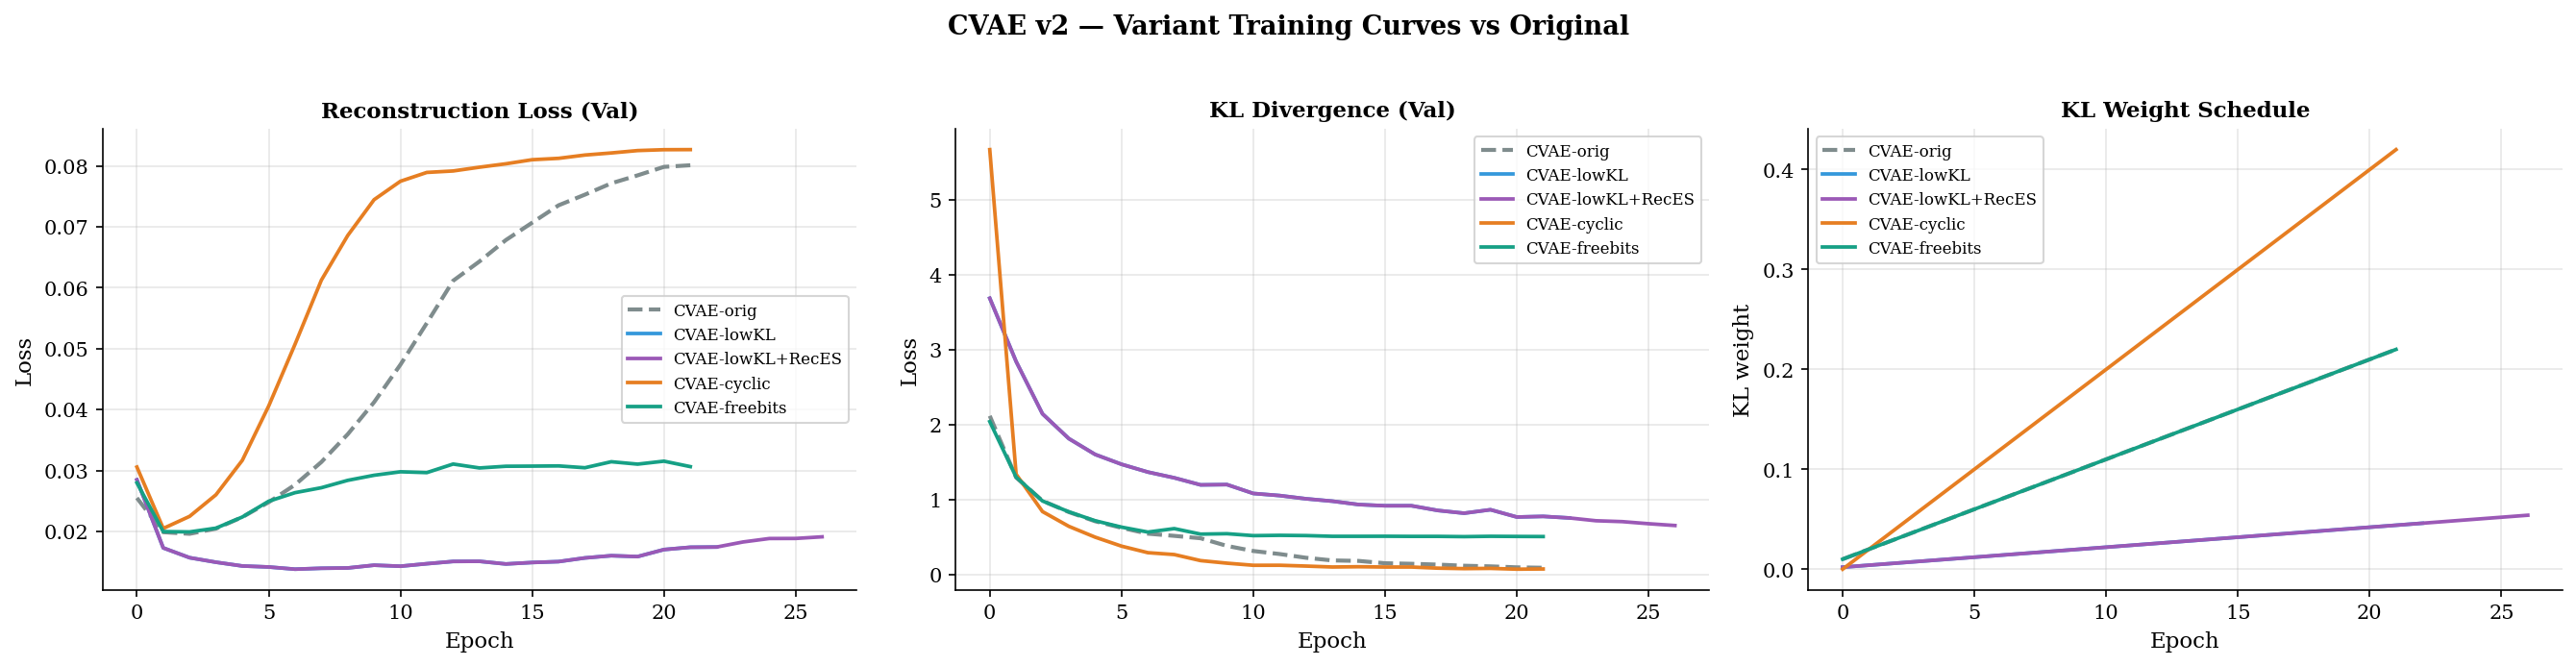

Saved -> 14_cvae_v2_curves.png


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
panels = [
    ("Reconstruction Loss (Val)", "val_recon"),
    ("KL Divergence (Val)",       "val_kl"),
    ("KL Weight Schedule",        "kl_weight"),
]

# Color cycle for variants
variant_colors = {
    "orig"        : "#7f8c8d",
    "lowKL"       : "#3498db",
    "lowKL+RecES" : "#9b59b6",
    "cyclic"      : "#e67e22",
    "freebits"    : "#16a085",
}

for ax, (title, key) in zip(axes, panels):
    # Original CVAE
    if key in cvae_history:
        ax.plot(cvae_history[key],
                label="CVAE-orig",
                color=variant_colors["orig"],
                linewidth=2, linestyle="--")

    for name, r in cvae_v2_results.items():
        if key in r["history"]:
            ax.plot(r["history"][key],
                    label=r["config"]["label"],
                    color=variant_colors[name],
                    linewidth=1.8)

    ax.set_title(title, fontweight="bold", fontsize=11)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss" if key != "kl_weight" else "KL weight")
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

plt.suptitle("CVAE v2 — Variant Training Curves vs Original",
             fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(f"{CONFIG['figures_dir']}/14_cvae_v2_curves.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("Saved -> 14_cvae_v2_curves.png")

## Generate Samples and Compute DVR for All Variants

*For each variant we call `model.generate(500, target_label=1.0, device)` to draw 500 P+ samples and `model.generate(500, target_label=0.0, device)` for 500 P- samples — same protocol as the original CVAE-DVR cell. Each group is then inverse-transformed to original [1, 100] scale, clipped, and scored with `compute_dvr_chunked` using the same reference pool and chunking hyperparameters as before.*

In [ ]:
np.random.seed(CONFIG["seed"])
torch.manual_seed(CONFIG["seed"])
N_PER_CLASS = 500

for name, r in cvae_v2_results.items():
    model = r["model"]
    model.eval()

    # Generate
    gen_pos_scaled, _ = model.generate(N_PER_CLASS, 1.0, device)
    gen_neg_scaled, _ = model.generate(N_PER_CLASS, 0.0, device)

    gen_pos_orig = np.clip(
        scaler.inverse_transform(gen_pos_scaled), 1, 100)
    gen_neg_orig = np.clip(
        scaler.inverse_transform(gen_neg_scaled), 1, 100)

    dvr_pos, vp, np_ = compute_dvr_chunked(
        gen_pos_orig, X_sel_full, selected_indices,
        target="positive",
        sample_size = CONFIG["dvr_sample_size"],
        ref_size    = CONFIG["dvr_ref_size"],
        chunk_size  = CONFIG["dvr_chunk_size"],
        seed        = CONFIG["seed"])
    dvr_neg, vn, nn_ = compute_dvr_chunked(
        gen_neg_orig, X_sel_full, selected_indices,
        target="negative",
        sample_size = CONFIG["dvr_sample_size"],
        ref_size    = CONFIG["dvr_ref_size"],
        chunk_size  = CONFIG["dvr_chunk_size"],
        seed        = CONFIG["seed"])

    r["dvr_pos"]   = dvr_pos
    r["dvr_neg"]   = dvr_neg
    r["valid_pos"] = vp
    r["eval_pos"]  = np_
    r["valid_neg"] = vn
    r["eval_neg"]  = nn_

    print(f"{r['config']['label']:<22s}  "
          f"P+ DVR: {dvr_pos*100:>5.1f}% ({vp}/{np_})  "
          f"P- DVR: {dvr_neg*100:>5.1f}% ({vn}/{nn_})")

CVAE-lowKL              P+ DVR:  77.2% (386/500)  P- DVR:  24.0% (120/500)
CVAE-lowKL+RecES        P+ DVR:  72.2% (361/500)  P- DVR:  45.6% (228/500)
CVAE-cyclic             P+ DVR:  52.6% (263/500)  P- DVR:  49.2% (246/500)
CVAE-freebits           P+ DVR:  48.2% (241/500)  P- DVR:  47.4% (237/500)


## Results Comparison Table

*All CVAE variants side by side with the original CVAE and the previously-computed AE and VAE numbers. This is the single table to put in front of your professor.*

In [ ]:
print("=" * 90)
print("  CVAE v2 — Full Comparison (incl. AE and VAE)")
print("=" * 90)
print(f"  {'Model':<24s} {'P+ DVR':>10s} {'P- DVR':>10s} "
      f"{'Epochs':>8s} {'Final Val Recon':>18s}")
print("-" * 90)

rows = [
    ("AE-Unc",   ae_dvr_pos_u,   ae_dvr_neg_u, "n/a", "n/a"),
    ("AE-Con",   ae_dvr_pos_c,   ae_dvr_neg_c, "n/a", "n/a"),
    ("VAE",      vae_dvr_pos,    vae_dvr_neg,
        len(vae_history.get("train_loss", [])) or "?",
        f"{vae_history['val_recon'][-1]:.5f}"
        if "val_recon" in vae_history else "n/a"),
    ("CVAE-orig", cvae_dvr_pos,  cvae_dvr_neg,
        len(cvae_history["train_loss"]),
        f"{cvae_history['val_recon'][-1]:.5f}"),
]
for r in rows:
    name, dp, dn, ep, vr = r
    dp_s = f"{dp*100:>5.1f}%"
    dn_s = f"{dn*100:>5.1f}%"
    print(f"  {name:<24s} {dp_s:>10s} {dn_s:>10s} "
          f"{str(ep):>8s} {str(vr):>18s}")

for name, r in cvae_v2_results.items():
    label = r["config"]["label"]
    dp_s = f"{r['dvr_pos']*100:>5.1f}%"
    dn_s = f"{r['dvr_neg']*100:>5.1f}%"
    print(f"  {label:<24s} {dp_s:>10s} {dn_s:>10s} "
          f"{r['epochs_run']:>8d} {r['final_val_recon']:>18.5f}")

print("=" * 90)
print(f"  Ref pool: {CONFIG['dvr_ref_size']:,}  |  "
      f"Eval sample: {CONFIG['dvr_sample_size']} per group  |  "
      f"Seed: {CONFIG['seed']}")

  CVAE v2 — Full Comparison (incl. AE and VAE)
  Model                        P+ DVR     P- DVR   Epochs    Final Val Recon
------------------------------------------------------------------------------------------
  AE-Unc                        90.6%      72.0%      n/a                n/a
  AE-Con                        86.6%      72.2%      n/a                n/a
  VAE                           87.3%      46.0%       21            0.07698
  CVAE-orig                     70.2%      26.6%       22            0.08011
  CVAE-lowKL                    77.2%      24.0%       23            0.01743
  CVAE-lowKL+RecES              72.2%      45.6%       27            0.01911
  CVAE-cyclic                   52.6%      49.2%       22            0.08268
  CVAE-freebits                 48.2%      47.4%       22            0.03063
  Ref pool: 10,000  |  Eval sample: 500 per group  |  Seed: 42


## Updated DVR Bar Chart (All Models + Variants)

*Two-panel bar chart with all models in a single view. Bars are colored by family — purple shades for AE, blue for VAE, green/orange shades for CVAE variants. The dashed horizontal line in each panel marks the **original CVAE** performance as the reference baseline.*

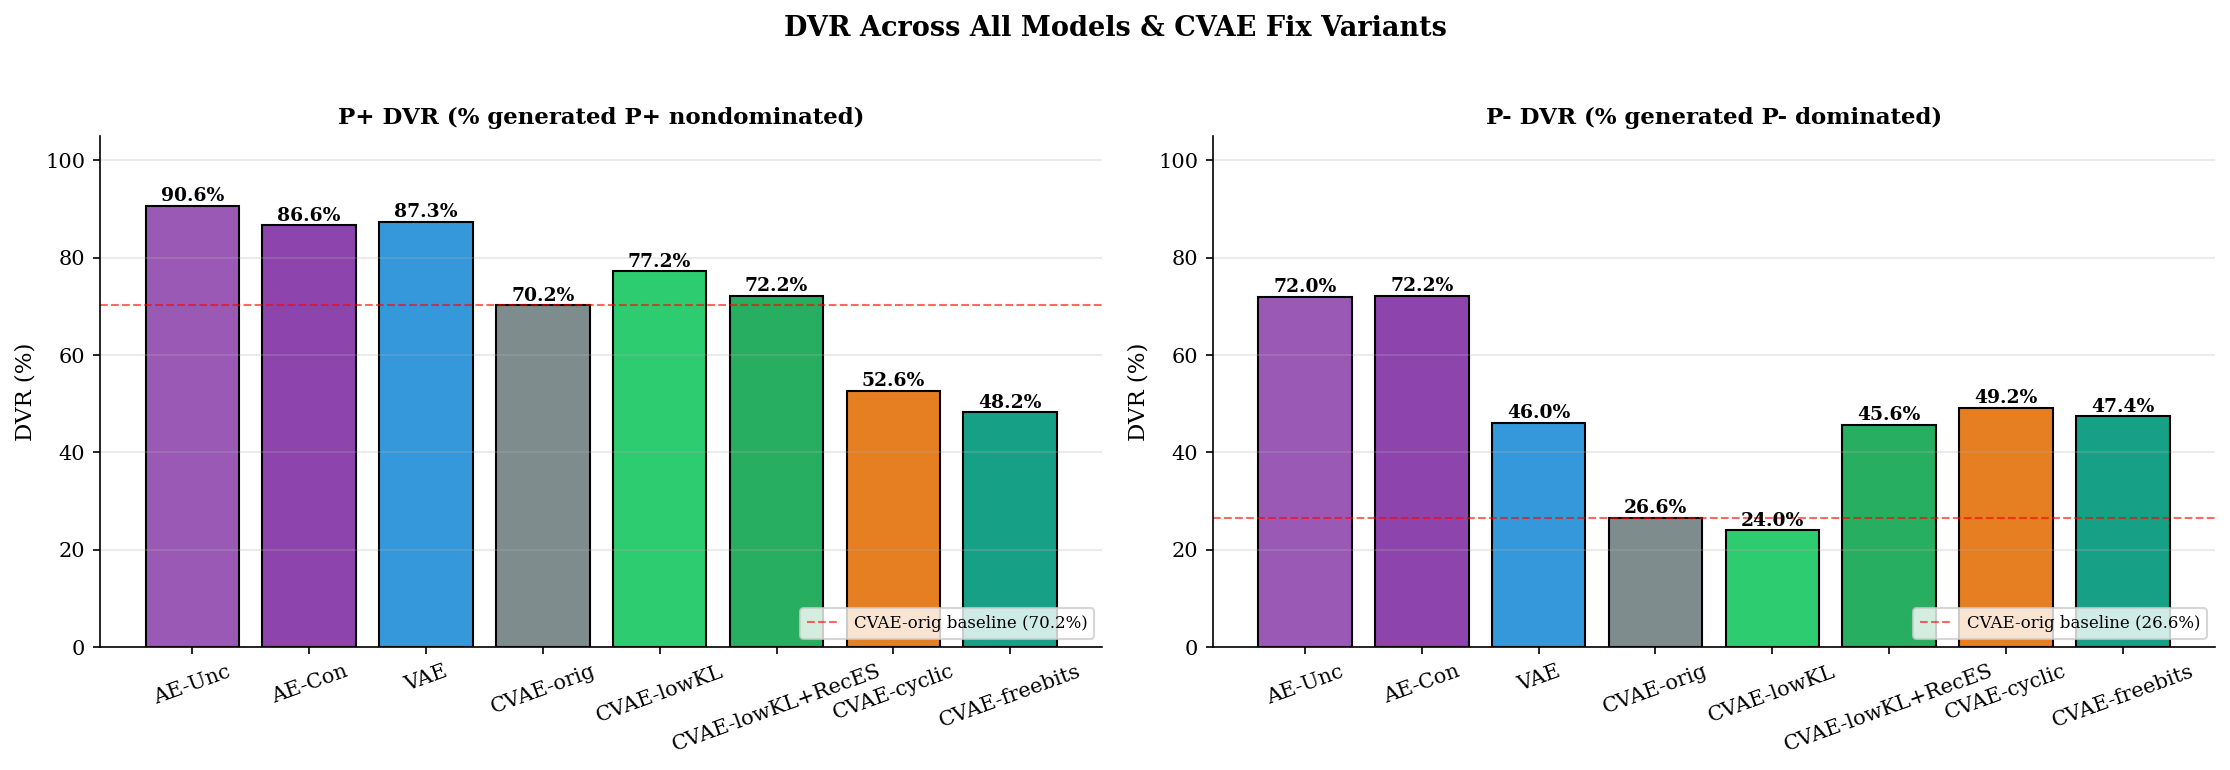

Saved -> 15_dvr_all_variants.png


In [ ]:
all_labels = ["AE-Unc", "AE-Con", "VAE", "CVAE-orig"] + \
             [cvae_v2_results[k]["config"]["label"]
              for k in cvae_v2_results]
all_colors = ["#9b59b6", "#8e44ad", "#3498db", "#7f8c8d",
              "#2ecc71", "#27ae60", "#e67e22", "#16a085"]

all_pos = [ae_dvr_pos_u*100, ae_dvr_pos_c*100,
           vae_dvr_pos*100,  cvae_dvr_pos*100]
all_neg = [ae_dvr_neg_u*100, ae_dvr_neg_c*100,
           vae_dvr_neg*100,  cvae_dvr_neg*100]
for k in cvae_v2_results:
    all_pos.append(cvae_v2_results[k]["dvr_pos"]*100)
    all_neg.append(cvae_v2_results[k]["dvr_neg"]*100)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for ax, vals, title, baseline in zip(
    axes,
    [all_pos, all_neg],
    ["P+ DVR (% generated P+ nondominated)",
     "P- DVR (% generated P- dominated)"],
    [cvae_dvr_pos*100, cvae_dvr_neg*100]
):
    bars = ax.bar(all_labels, vals, color=all_colors,
                  edgecolor="black")
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width()/2, v + 1,
                f"{v:.1f}%",
                ha="center", fontsize=9, fontweight="bold")
    ax.axhline(baseline, color="red", linestyle="--",
               linewidth=1, alpha=0.6,
               label=f"CVAE-orig baseline ({baseline:.1f}%)")
    ax.set_title(title, fontweight="bold", fontsize=11)
    ax.set_ylim(0, max(105, max(vals) + 10))
    ax.set_ylabel("DVR (%)")
    ax.grid(True, alpha=0.3, axis="y")
    ax.legend(loc="lower right", fontsize=8)
    ax.tick_params(axis="x", rotation=20)

plt.suptitle("DVR Across All Models & CVAE Fix Variants",
             fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(f"{CONFIG['figures_dir']}/15_dvr_all_variants.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("Saved -> 15_dvr_all_variants.png")

## Save CVAE v2 Results

In [ ]:
cvae_v2_save = {}
for name, r in cvae_v2_results.items():
    cvae_v2_save[name] = {
        "label"            : r["config"]["label"],
        "config"           : {k: v for k, v in r["config"].items()
                              if k != "label"},
        "epochs_run"       : r["epochs_run"],
        "final_val_recon"  : float(r["final_val_recon"]),
        "final_val_kl"     : float(r["final_kl"]),
        "dvr_positive"     : float(r["dvr_pos"]),
        "dvr_negative"     : float(r["dvr_neg"]),
        "valid_pos"        : int(r["valid_pos"]),
        "eval_pos"         : int(r["eval_pos"]),
        "valid_neg"        : int(r["valid_neg"]),
        "eval_neg"         : int(r["eval_neg"]),
        "checkpoint"       : r["checkpoint"],
    }

save_payload = {
    "models"           : cvae_v2_save,
    "original_cvae"    : {
        "dvr_positive" : float(cvae_dvr_pos),
        "dvr_negative" : float(cvae_dvr_neg),
        "epochs_run"   : len(cvae_history["train_loss"]),
        "final_val_recon": float(cvae_history["val_recon"][-1]),
    },
    "config"           : {
        "dvr_sample_size": CONFIG["dvr_sample_size"],
        "dvr_ref_size"   : CONFIG["dvr_ref_size"],
        "dvr_chunk_size" : CONFIG["dvr_chunk_size"],
        "seed"           : CONFIG["seed"],
        "n_generated_per_class": N_PER_CLASS,
    },
    "diagnosis_note"   : (
        "Original CVAE showed rising validation reconstruction loss "
        "during KL annealing and early-stopped at ~22 epochs on total "
        "validation loss before KL had finished annealing. v2 variants "
        "target this failure mode."
    ),
}

_path = f"{CONFIG['results_dir']}/cvae_v2_results.json"
with open(_path, "w") as f:
    json.dump(save_payload, f, indent=2)
print(f"Saved -> {_path}")

Saved -> /content/drive/MyDrive/GenMOR/results/cvae_v2_results.json


## Verify Steps

In [ ]:
print("=" * 60)
print("  CVAE v2 Verification")
print("=" * 60)
checks = {
    "All 4 variants trained": len(cvae_v2_results) == 4,
    "All variant checkpoints exist": all(
        os.path.exists(r["checkpoint"])
        for r in cvae_v2_results.values()),
    "All variant DVRs in [0, 1]": all(
        0.0 <= r["dvr_pos"] <= 1.0
        and 0.0 <= r["dvr_neg"] <= 1.0
        for r in cvae_v2_results.values()),
    "Training curves figure saved": os.path.exists(
        f"{CONFIG['figures_dir']}/14_cvae_v2_curves.png"),
    "All-variants DVR figure saved": os.path.exists(
        f"{CONFIG['figures_dir']}/15_dvr_all_variants.png"),
    "Results JSON saved": os.path.exists(
        f"{CONFIG['results_dir']}/cvae_v2_results.json"),
}
all_good = True
for name, status in checks.items():
    icon = "(OK)" if status else "(WARNING)"
    print(f"  {icon} {name}")
    if not status:
        all_good = False

# Did any variant actually improve on original?
orig_pos = cvae_dvr_pos
best_v2_pos = max(r["dvr_pos"] for r in cvae_v2_results.values())
best_name   = max(cvae_v2_results,
                  key=lambda k: cvae_v2_results[k]["dvr_pos"])
print("=" * 60)
print(f"  Original CVAE P+ DVR : {orig_pos*100:.1f}%")
print(f"  Best v2 variant      : "
      f"{cvae_v2_results[best_name]['config']['label']} "
      f"@ {best_v2_pos*100:.1f}%")
if best_v2_pos > orig_pos:
    print(f"  (OK) Improvement of "
          f"{(best_v2_pos - orig_pos)*100:.1f} percentage points")
else:
    print("  (CHECK) No v2 variant improved on the original. "
          "Inspect the training curves before drawing conclusions.")
print("=" * 60)
if all_good:
    print("  (OK) All structural checks passed.")
else:
    print("  (CHECK) Fix the items marked (WARNING).")

  CVAE v2 Verification
  (OK) All 4 variants trained
  (OK) All variant checkpoints exist
  (OK) All variant DVRs in [0, 1]
  (OK) Training curves figure saved
  (OK) All-variants DVR figure saved
  (OK) Results JSON saved
  Original CVAE P+ DVR : 70.2%
  Best v2 variant      : CVAE-lowKL @ 77.2%
  (OK) Improvement of 7.0 percentage points
  (OK) All structural checks passed.


# NEW ADDITION

# AE to generate plans wo using vae/cvae architecture

# **AE as a Generative Model — Path 1: Per-Class GMM Latent Prior**

*The Plain AE has no native prior over its latent space. In the earlier AE-DVR section we worked around this with two ad-hoc choices: a single Gaussian over all training latents (Approach 1) and one Gaussian per class (Approach 2). Both are crude — a single 16-D Gaussian assumes the encoded training latents form one unimodal blob, which is unlikely to be true once the classifier head has separated the classes and the reconstruction loss has shaped the manifold.*

*Path 1 replaces these single Gaussians with a **Gaussian Mixture Model (GMM)** fit per class. For each class we fit a K-component GMM to the encoded training latents of that class, then sample from it. A GMM can capture multimodal structure within a class — e.g. if P+ plans cluster around several sub-types — and so should better cover the actual data manifold than a single Gaussian.*

*No AE architectural changes are required for this approach. The same encoder, decoder, and classifier head are reused without modification. Only the sampling distribution over the latent space is changed.*

## Encode Training Latents and Fit Per-Class GMMs

*We reload the AE checkpoint (defensive — the multi-seed loop and the CVAE v2 cells may have left other models with stale weights, but the global `ae_model` object is what we re-populate). We re-encode the full training split through `ae_model.encode` in non-shuffled batches so the latent matrix stays aligned with `y_train`, then split by class label and fit one `sklearn.mixture.GaussianMixture` per class with K components each. Full covariance is used because a 16-D space with thousands of training points per class is well-conditioned and the extra flexibility is worth it.*

*K = 4 components per class is a reasonable starting point. If you want to tune it later, BIC scoring (`gmm.bic(X)`) on a held-out fraction of the latents is the standard approach — lower BIC means a better fit-vs-complexity tradeoff. We'll print BIC values so you can see what they look like.*

In [ ]:
from sklearn.mixture import GaussianMixture

# Tunable: components per class
N_GMM_COMPONENTS_PER_CLASS = 4

# Reload the AE checkpoint to guarantee seed-42 weights
ae_model.load_state_dict(torch.load(ae_checkpoint, map_location=device))
ae_model.eval()

# Encode the full training split (re-derive defensively)
ae_z_train_g = []
with torch.no_grad():
    for i in range(0, len(X_train_scaled), 512):
        xb = torch.tensor(
            X_train_scaled[i:i+512], dtype=torch.float32
        ).to(device)
        ae_z_train_g.append(ae_model.encode(xb).cpu().numpy())
ae_z_train_g = np.concatenate(ae_z_train_g)

# Split by class
z_pos_train = ae_z_train_g[y_train == 1]
z_neg_train = ae_z_train_g[y_train == 0]

# Fit per-class GMMs
gmm_pos = GaussianMixture(
    n_components  = N_GMM_COMPONENTS_PER_CLASS,
    covariance_type = "full",
    reg_covar     = 1e-6,
    random_state  = CONFIG["seed"],
    max_iter      = 200,
)
gmm_neg = GaussianMixture(
    n_components  = N_GMM_COMPONENTS_PER_CLASS,
    covariance_type = "full",
    reg_covar     = 1e-6,
    random_state  = CONFIG["seed"],
    max_iter      = 200,
)
gmm_pos.fit(z_pos_train)
gmm_neg.fit(z_neg_train)

print("=" * 60)
print("  Per-Class GMM Latent Priors fitted")
print("=" * 60)
print(f"  Components per class : {N_GMM_COMPONENTS_PER_CLASS}")
print(f"  P+ training latents  : {z_pos_train.shape[0]:,}")
print(f"  P- training latents  : {z_neg_train.shape[0]:,}")
print(f"  P+ GMM converged     : {gmm_pos.converged_}  "
      f"(iters: {gmm_pos.n_iter_})")
print(f"  P- GMM converged     : {gmm_neg.converged_}  "
      f"(iters: {gmm_neg.n_iter_})")
print(f"  P+ GMM log-likelihood: {gmm_pos.score(z_pos_train):.4f}  "
      f"(per-sample, higher better)")
print(f"  P- GMM log-likelihood: {gmm_neg.score(z_neg_train):.4f}")
print(f"  P+ GMM BIC           : {gmm_pos.bic(z_pos_train):.1f}  "
      f"(lower better)")
print(f"  P- GMM BIC           : {gmm_neg.bic(z_neg_train):.1f}")
print(f"  P+ component weights : {gmm_pos.weights_.round(3).tolist()}")
print(f"  P- component weights : {gmm_neg.weights_.round(3).tolist()}")
print("=" * 60)

  Per-Class GMM Latent Priors fitted
  Components per class : 4
  P+ training latents  : 17,646
  P- training latents  : 17,353
  P+ GMM converged     : True  (iters: 36)
  P- GMM converged     : True  (iters: 38)
  P+ GMM log-likelihood: -17.7520  (per-sample, higher better)
  P- GMM log-likelihood: -17.4953
  P+ GMM BIC           : 632477.0  (lower better)
  P- GMM BIC           : 613155.7
  P+ component weights : [0.286, 0.175, 0.25, 0.289]
  P- component weights : [0.31, 0.274, 0.184, 0.232]


## Generate P+ and P- Plans via GMM Sampling

*Each GMM exposes `.sample(n)` which returns `(samples, component_labels)`. The first element is what we want — an `(n, 16)` matrix of latent vectors drawn from the mixture. We sample 500 from each class to match the existing per-class sample sizes used by CVAE-DVR and AE-Con, decode through the AE decoder, and inverse-transform to original [1, 100] objective scale.*

In [ ]:
np.random.seed(CONFIG["seed"])
torch.manual_seed(CONFIG["seed"])

N_PER_CLASS_GMM = 500

# Sample latents from each GMM
z_pos_gmm, _ = gmm_pos.sample(N_PER_CLASS_GMM)
z_neg_gmm, _ = gmm_neg.sample(N_PER_CLASS_GMM)
z_pos_gmm = z_pos_gmm.astype(np.float32)
z_neg_gmm = z_neg_gmm.astype(np.float32)

# Decode through the AE decoder
ae_model.eval()
with torch.no_grad():
    ae_gen_pos_scaled_g = ae_model.decode(
        torch.tensor(z_pos_gmm).to(device)
    ).cpu().numpy()
    ae_gen_neg_scaled_g = ae_model.decode(
        torch.tensor(z_neg_gmm).to(device)
    ).cpu().numpy()

# Back to original objective scale
ae_gen_pos_orig_g = np.clip(
    scaler.inverse_transform(ae_gen_pos_scaled_g), 1, 100
)
ae_gen_neg_orig_g = np.clip(
    scaler.inverse_transform(ae_gen_neg_scaled_g), 1, 100
)

print(f"Generated {N_PER_CLASS_GMM} P+ and {N_PER_CLASS_GMM} P- plans "
      f"via per-class GMM (K={N_GMM_COMPONENTS_PER_CLASS})")
print(f"  P+ shape: {ae_gen_pos_orig_g.shape}  "
      f"value range: [{ae_gen_pos_orig_g.min():.2f}, "
      f"{ae_gen_pos_orig_g.max():.2f}]")
print(f"  P- shape: {ae_gen_neg_orig_g.shape}  "
      f"value range: [{ae_gen_neg_orig_g.min():.2f}, "
      f"{ae_gen_neg_orig_g.max():.2f}]")

Generated 500 P+ and 500 P- plans via per-class GMM (K=4)
  P+ shape: (500, 20)  value range: [1.46, 99.46]
  P- shape: (500, 20)  value range: [1.70, 99.39]


## What Do the Generated Plans Look Like?

*Visualize 8 generated P+ plans alongside 8 real P+ plans, and the same for P-. Each row is one plan; the 20 columns are the 20 objectives, color-coded by value in [1, 100]. If the AE-GMM pipeline is producing sensible plans we should see: generated plans falling in the same value range as real plans, generated P+ rows looking statistically similar to real P+ rows, and generated P- rows looking statistically similar to real P- rows — but not pixel-identical (otherwise we'd just be memorizing training data).*

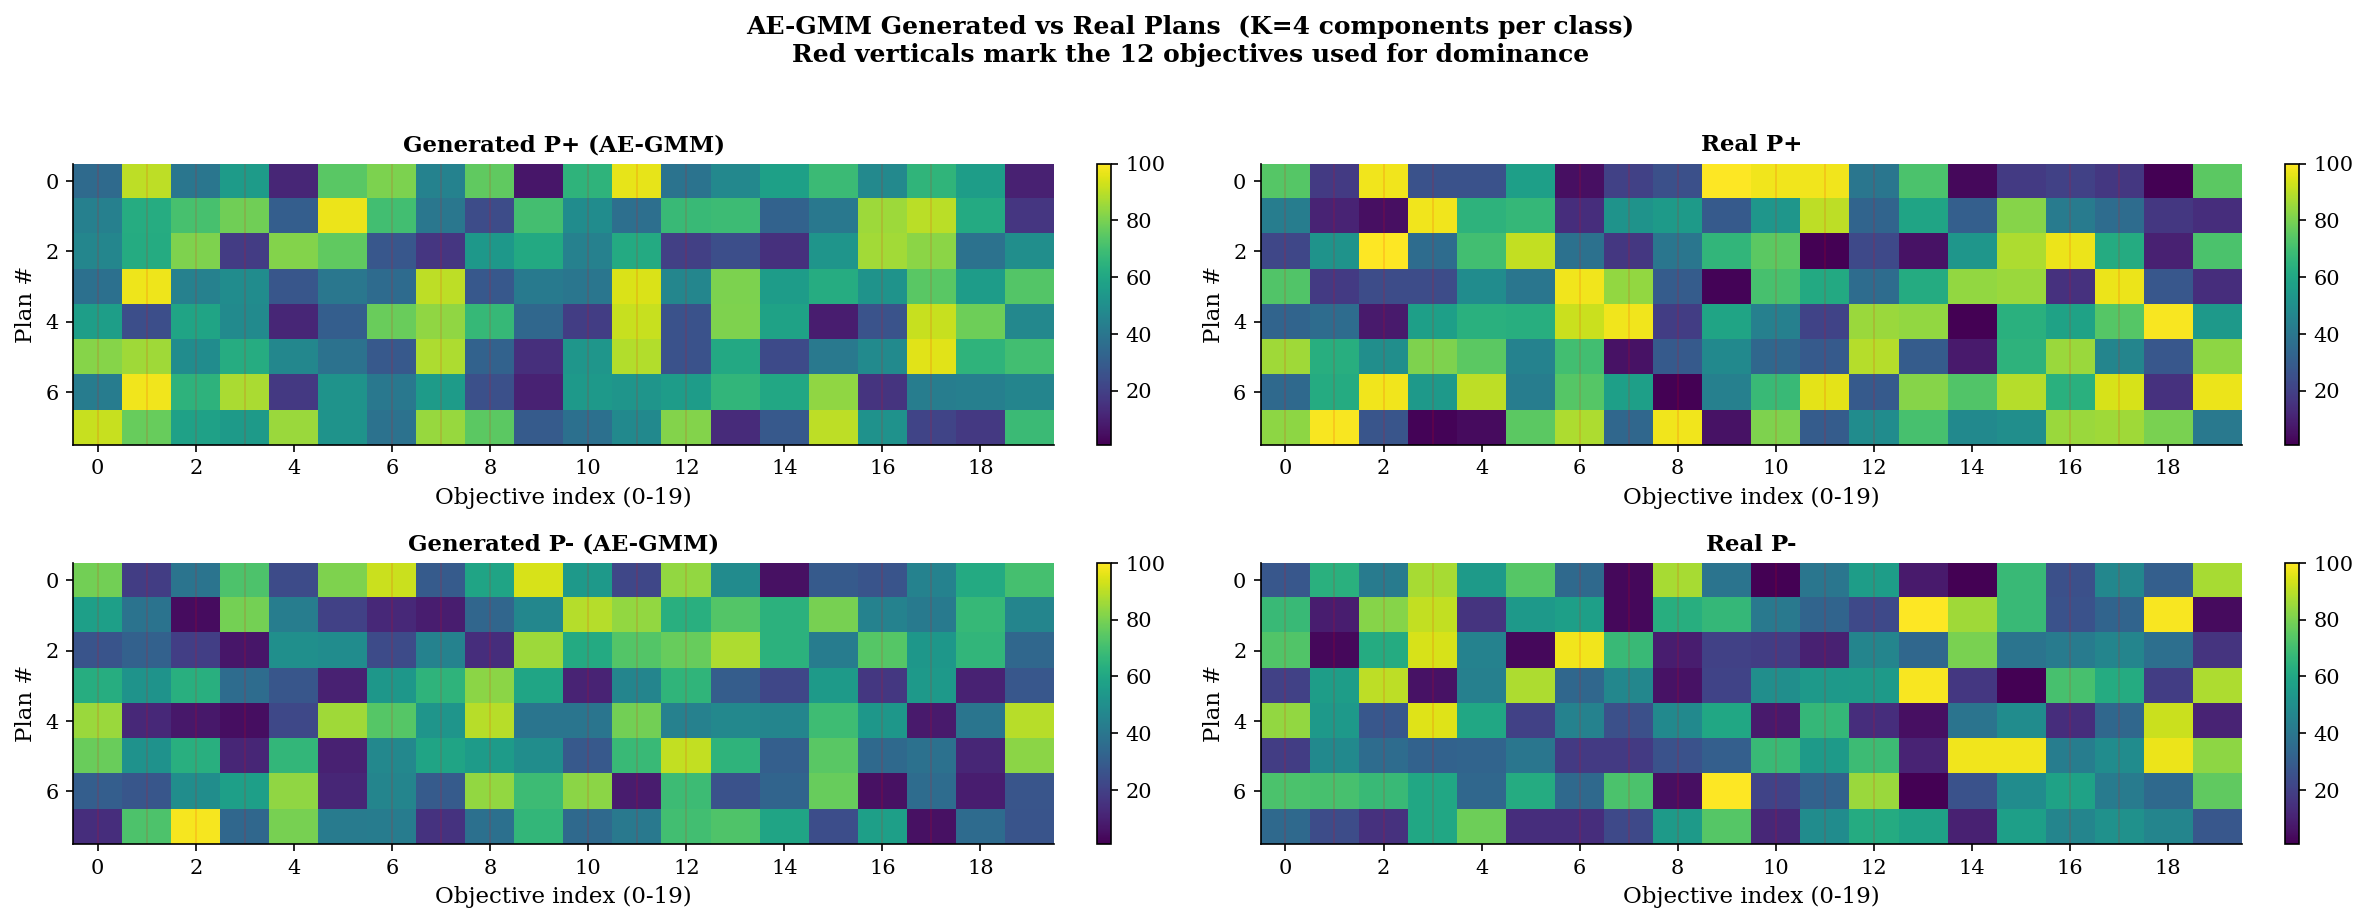

Saved -> 16_ae_gmm_generated_vs_real.png


In [ ]:
n_show = 8
rng = np.random.RandomState(CONFIG["seed"])

# Sample real plans of each class for comparison
real_pos_idx = rng.choice(np.where(y_full == 1)[0], size=n_show, replace=False)
real_neg_idx = rng.choice(np.where(y_full == 0)[0], size=n_show, replace=False)
real_pos_samp = X_orig_full[real_pos_idx]
real_neg_samp = X_orig_full[real_neg_idx]
gen_pos_samp  = ae_gen_pos_orig_g[:n_show]
gen_neg_samp  = ae_gen_neg_orig_g[:n_show]

fig, axes = plt.subplots(2, 2, figsize=(16, 6))
panels = [
    (axes[0, 0], gen_pos_samp,  "Generated P+ (AE-GMM)"),
    (axes[0, 1], real_pos_samp, "Real P+"),
    (axes[1, 0], gen_neg_samp,  "Generated P- (AE-GMM)"),
    (axes[1, 1], real_neg_samp, "Real P-"),
]
for ax, data, title in panels:
    im = ax.imshow(data, aspect="auto", cmap="viridis",
                   vmin=1, vmax=100)
    ax.set_title(title, fontweight="bold", fontsize=11)
    ax.set_xlabel("Objective index (0-19)")
    ax.set_ylabel("Plan #")
    ax.set_xticks(range(0, 20, 2))
    # Mark selected objectives (used for dominance)
    for s in selected_indices:
        ax.axvline(s, color="red", alpha=0.15, linewidth=0.8)
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.suptitle(
    f"AE-GMM Generated vs Real Plans  "
    f"(K={N_GMM_COMPONENTS_PER_CLASS} components per class)\n"
    f"Red verticals mark the 12 objectives used for dominance",
    fontsize=12, fontweight="bold", y=1.02
)
plt.tight_layout()
plt.savefig(f"{CONFIG['figures_dir']}/16_ae_gmm_generated_vs_real.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("Saved -> 16_ae_gmm_generated_vs_real.png")

## Distributional Check via PCA

*The heatmap shows individual plans. For an aggregate view we project 500 generated plans and 500 real plans into 2-D via PCA fit on the full 50K-plan reference set restricted to the 12 dominance objectives. A healthy generator's samples should land in the same region of PCA space as the real samples of the same class, but ideally cover the space rather than collapsing to a few points.*

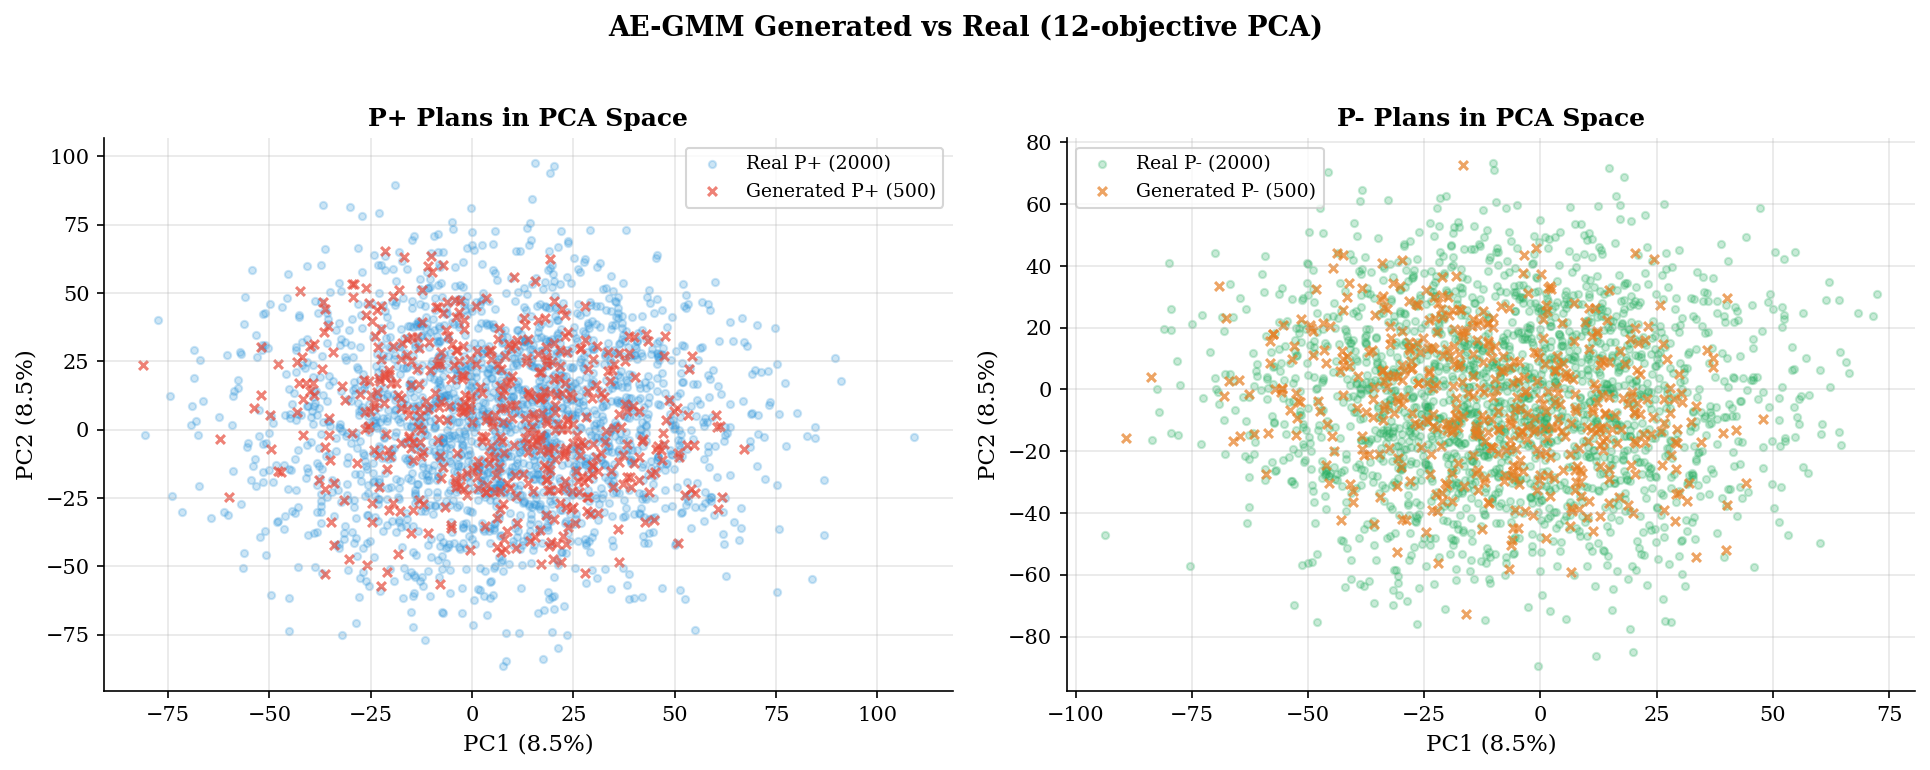

Saved -> 17_ae_gmm_pca.png


In [ ]:
from sklearn.decomposition import PCA

# Fit PCA on the full 50K dataset (dominance-relevant 12-D subspace)
pca_full = PCA(n_components=2, random_state=CONFIG["seed"])
pca_full.fit(X_sel_full)

# Project everything
real_pos_2d = pca_full.transform(X_orig_full[y_full == 1][:, selected_indices])
real_neg_2d = pca_full.transform(X_orig_full[y_full == 0][:, selected_indices])
gen_pos_2d  = pca_full.transform(ae_gen_pos_orig_g[:, selected_indices])
gen_neg_2d  = pca_full.transform(ae_gen_neg_orig_g[:, selected_indices])

# Subsample real for plotting (otherwise it's a solid blob)
n_real_plot = 2000
rng = np.random.RandomState(CONFIG["seed"])
rpi = rng.choice(len(real_pos_2d), size=min(n_real_plot, len(real_pos_2d)),
                 replace=False)
rni = rng.choice(len(real_neg_2d), size=min(n_real_plot, len(real_neg_2d)),
                 replace=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(real_pos_2d[rpi, 0], real_pos_2d[rpi, 1],
                c="#3498db", alpha=0.25, s=12, label=f"Real P+ ({len(rpi)})")
axes[0].scatter(gen_pos_2d[:, 0], gen_pos_2d[:, 1],
                c="#e74c3c", alpha=0.7, s=18,
                marker="x", label=f"Generated P+ ({len(gen_pos_2d)})")
axes[0].set_title("P+ Plans in PCA Space", fontweight="bold")

axes[1].scatter(real_neg_2d[rni, 0], real_neg_2d[rni, 1],
                c="#27ae60", alpha=0.25, s=12, label=f"Real P- ({len(rni)})")
axes[1].scatter(gen_neg_2d[:, 0], gen_neg_2d[:, 1],
                c="#e67e22", alpha=0.7, s=18,
                marker="x", label=f"Generated P- ({len(gen_neg_2d)})")
axes[1].set_title("P- Plans in PCA Space", fontweight="bold")

for ax in axes:
    ax.set_xlabel(f"PC1 ({pca_full.explained_variance_ratio_[0]*100:.1f}%)")
    ax.set_ylabel(f"PC2 ({pca_full.explained_variance_ratio_[1]*100:.1f}%)")
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)

plt.suptitle("AE-GMM Generated vs Real (12-objective PCA)",
             fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(f"{CONFIG['figures_dir']}/17_ae_gmm_pca.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("Saved -> 17_ae_gmm_pca.png")

## Compute DVR for AE-GMM Samples

*Same DVR protocol as Approach 2 (CVAE-analog): each class's 500 generated plans are scored against the 10K real-plan reference pool with the appropriate target. No classifier-head call is needed — class label is known by which GMM was sampled.*

In [ ]:
ae_dvr_pos_g, ae_vp_g, ae_np_g = compute_dvr_chunked(
    ae_gen_pos_orig_g, X_sel_full, selected_indices,
    target      = "positive",
    sample_size = CONFIG["dvr_sample_size"],
    ref_size    = CONFIG["dvr_ref_size"],
    chunk_size  = CONFIG["dvr_chunk_size"],
    seed        = CONFIG["seed"],
)
ae_dvr_neg_g, ae_vn_g, ae_nn_g = compute_dvr_chunked(
    ae_gen_neg_orig_g, X_sel_full, selected_indices,
    target      = "negative",
    sample_size = CONFIG["dvr_sample_size"],
    ref_size    = CONFIG["dvr_ref_size"],
    chunk_size  = CONFIG["dvr_chunk_size"],
    seed        = CONFIG["seed"],
)

print(f"AE-GMM (K={N_GMM_COMPONENTS_PER_CLASS}) — "
      f"P+ DVR: {ae_dvr_pos_g*100:.1f}% "
      f"({ae_vp_g}/{ae_np_g} nondominated)")
print(f"AE-GMM (K={N_GMM_COMPONENTS_PER_CLASS}) — "
      f"P- DVR: {ae_dvr_neg_g*100:.1f}% "
      f"({ae_vn_g}/{ae_nn_g} dominated)")

AE-GMM (K=4) — P+ DVR: 89.4% (447/500 nondominated)
AE-GMM (K=4) — P- DVR: 71.8% (359/500 dominated)


## Updated Comparison Table — All AE/VAE/CVAE Variants

*The full picture across every model we've evaluated. AE-GMM joins the AE family; CVAE-best is the lowKL+RecES variant from the CVAE v2 section since that was the only fix that helped.*

In [ ]:
# Pick the best CVAE v2 variant defensively
if "cvae_v2_results" in dir() and len(cvae_v2_results) > 0:
    _best_v2 = max(cvae_v2_results,
                   key=lambda k: cvae_v2_results[k]["dvr_pos"])
    cvae_best_label = cvae_v2_results[_best_v2]["config"]["label"]
    cvae_best_pos   = cvae_v2_results[_best_v2]["dvr_pos"]
    cvae_best_neg   = cvae_v2_results[_best_v2]["dvr_neg"]
else:
    cvae_best_label, cvae_best_pos, cvae_best_neg = "n/a", None, None

print("=" * 80)
print("  Full Model Comparison (incl. AE-GMM)")
print("=" * 80)
print(f"  {'Model':<28s} {'P+ DVR':>10s} {'P- DVR':>10s}  Notes")
print("-" * 80)
rows = [
    ("AE-Unc (single Gauss)",    ae_dvr_pos_u, ae_dvr_neg_u,
     "Approach 1: unconditional + classifier split"),
    ("AE-Con (per-class Gauss)", ae_dvr_pos_c, ae_dvr_neg_c,
     "Approach 2: per-class single Gaussian"),
    (f"AE-GMM (K={N_GMM_COMPONENTS_PER_CLASS} per class)",
     ae_dvr_pos_g, ae_dvr_neg_g,
     "Path 1: per-class GMM"),
    ("VAE",                      vae_dvr_pos,  vae_dvr_neg,
     "N(0,I) prior + classifier split"),
    ("CVAE-orig",                cvae_dvr_pos, cvae_dvr_neg,
     "Original CVAE (undertrained)"),
]
if cvae_best_pos is not None:
    rows.append((cvae_best_label, cvae_best_pos, cvae_best_neg,
                 "Best CVAE v2 variant"))

for name, dp, dn, note in rows:
    print(f"  {name:<28s} {dp*100:>9.1f}% {dn*100:>9.1f}%  {note}")
print("=" * 80)
print(f"  Ref pool: {CONFIG['dvr_ref_size']:,}  |  "
      f"Eval sample: {CONFIG['dvr_sample_size']} per group  |  "
      f"Seed: {CONFIG['seed']}")

  Full Model Comparison (incl. AE-GMM)
  Model                            P+ DVR     P- DVR  Notes
--------------------------------------------------------------------------------
  AE-Unc (single Gauss)             90.6%      72.0%  Approach 1: unconditional + classifier split
  AE-Con (per-class Gauss)          86.6%      72.2%  Approach 2: per-class single Gaussian
  AE-GMM (K=4 per class)            89.4%      71.8%  Path 1: per-class GMM
  VAE                               87.3%      46.0%  N(0,I) prior + classifier split
  CVAE-orig                         70.2%      26.6%  Original CVAE (undertrained)
  CVAE-lowKL                        77.2%      24.0%  Best CVAE v2 variant
  Ref pool: 10,000  |  Eval sample: 500 per group  |  Seed: 42


## Updated DVR Bar Chart Including AE-GMM

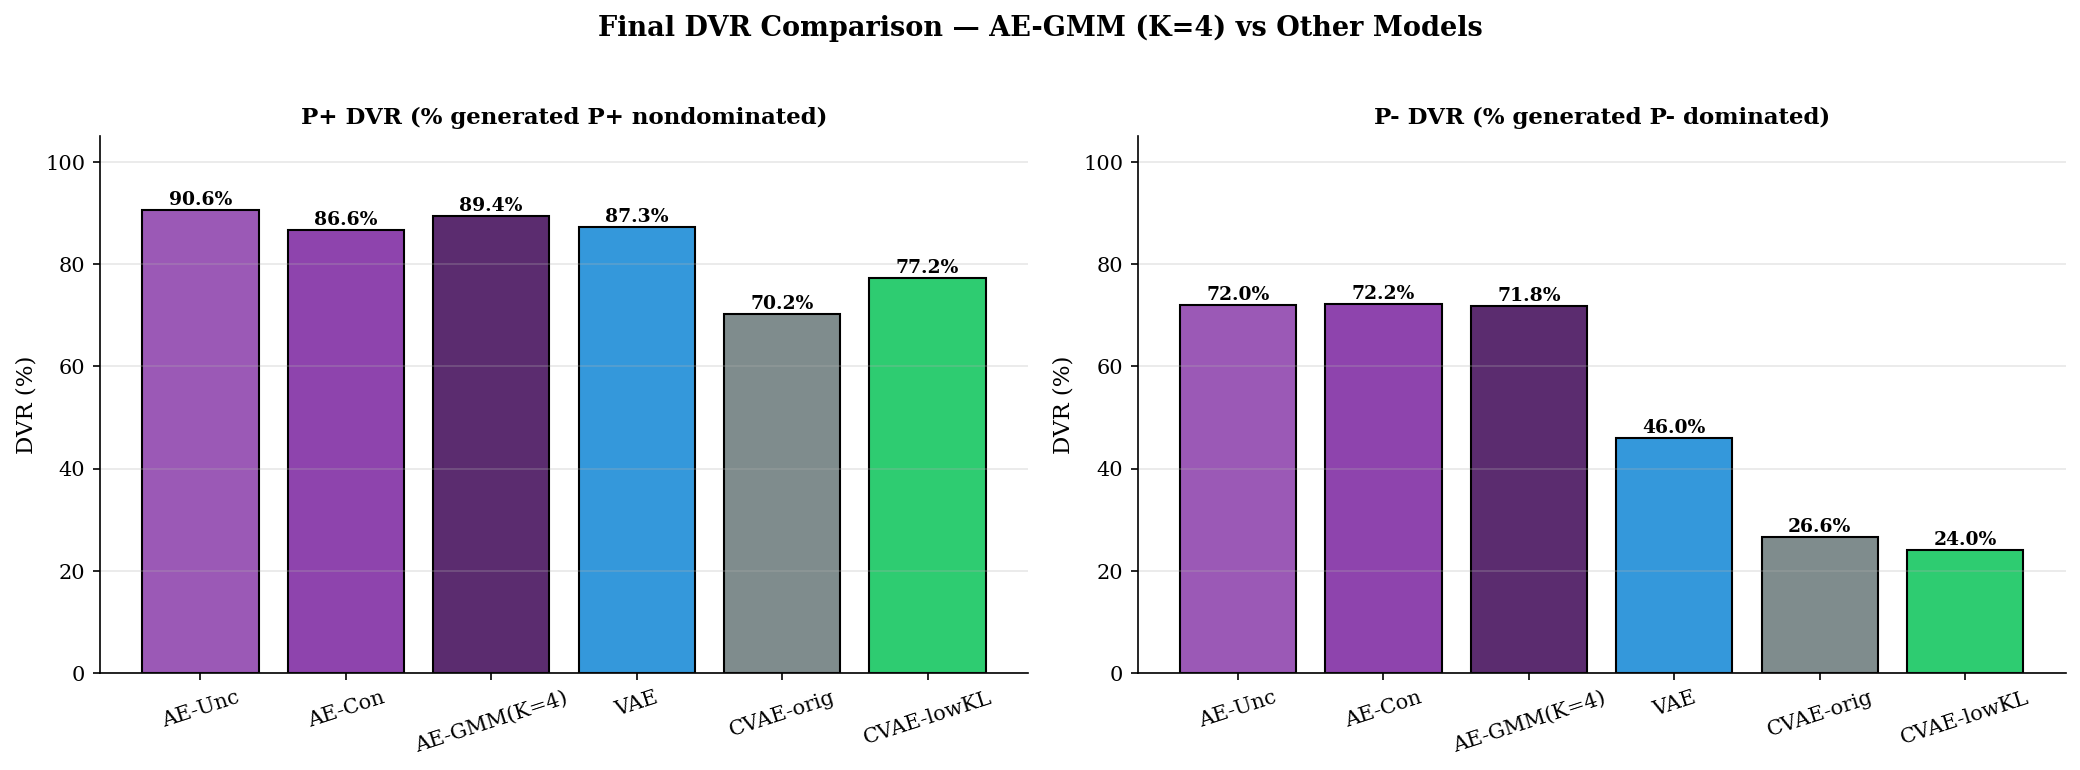

Saved -> 18_dvr_final_with_gmm.png


In [ ]:
labels_final = ["AE-Unc", "AE-Con",
                f"AE-GMM(K={N_GMM_COMPONENTS_PER_CLASS})",
                "VAE", "CVAE-orig"]
pos_final = [ae_dvr_pos_u*100, ae_dvr_pos_c*100, ae_dvr_pos_g*100,
             vae_dvr_pos*100,  cvae_dvr_pos*100]
neg_final = [ae_dvr_neg_u*100, ae_dvr_neg_c*100, ae_dvr_neg_g*100,
             vae_dvr_neg*100,  cvae_dvr_neg*100]
colors_final = ["#9b59b6", "#8e44ad", "#5b2c6f",
                "#3498db", "#7f8c8d"]

if cvae_best_pos is not None:
    labels_final.append(cvae_best_label)
    pos_final.append(cvae_best_pos*100)
    neg_final.append(cvae_best_neg*100)
    colors_final.append("#2ecc71")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, vals, title in zip(
    axes,
    [pos_final, neg_final],
    ["P+ DVR (% generated P+ nondominated)",
     "P- DVR (% generated P- dominated)"]
):
    bars = ax.bar(labels_final, vals,
                  color=colors_final, edgecolor="black")
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width()/2, v + 1,
                f"{v:.1f}%", ha="center",
                fontsize=9, fontweight="bold")
    ax.set_title(title, fontweight="bold", fontsize=11)
    ax.set_ylim(0, max(105, max(vals) + 10))
    ax.set_ylabel("DVR (%)")
    ax.grid(True, alpha=0.3, axis="y")
    ax.tick_params(axis="x", rotation=18)

plt.suptitle(
    f"Final DVR Comparison — AE-GMM (K={N_GMM_COMPONENTS_PER_CLASS}) "
    "vs Other Models",
    fontsize=13, fontweight="bold", y=1.02
)
plt.tight_layout()
plt.savefig(f"{CONFIG['figures_dir']}/18_dvr_final_with_gmm.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("Saved -> 18_dvr_final_with_gmm.png")

## Save AE-GMM Results

In [ ]:
ae_gmm_results = {
    "model"          : "Plain AE + Per-Class GMM Latent Prior",
    "path"           : "Path 1: empirical prior via GMM",
    "n_components"   : int(N_GMM_COMPONENTS_PER_CLASS),
    "n_per_class"    : int(N_PER_CLASS_GMM),
    "dvr_positive"   : float(ae_dvr_pos_g),
    "dvr_negative"   : float(ae_dvr_neg_g),
    "valid_pos"      : int(ae_vp_g),
    "eval_pos"       : int(ae_np_g),
    "valid_neg"      : int(ae_vn_g),
    "eval_neg"       : int(ae_nn_g),
    "gmm_pos_converged" : bool(gmm_pos.converged_),
    "gmm_neg_converged" : bool(gmm_neg.converged_),
    "gmm_pos_log_likelihood": float(gmm_pos.score(z_pos_train)),
    "gmm_neg_log_likelihood": float(gmm_neg.score(z_neg_train)),
    "gmm_pos_bic"    : float(gmm_pos.bic(z_pos_train)),
    "gmm_neg_bic"    : float(gmm_neg.bic(z_neg_train)),
    "gmm_pos_weights": gmm_pos.weights_.tolist(),
    "gmm_neg_weights": gmm_neg.weights_.tolist(),
    "config"         : {
        "dvr_sample_size": CONFIG["dvr_sample_size"],
        "dvr_ref_size"   : CONFIG["dvr_ref_size"],
        "dvr_chunk_size" : CONFIG["dvr_chunk_size"],
        "seed"           : CONFIG["seed"],
        "latent_dim"     : 16,
    },
    "methodology_note": (
        "AE has no native prior. We fit a per-class Gaussian Mixture "
        "Model (full covariance) to the encoded training latents of "
        "each class, then sample from each GMM and decode through the "
        "AE decoder. No architectural changes to the AE were required. "
        "This is more expressive than the single-Gaussian-per-class "
        "approach in Approach 2 because it can capture multimodal "
        "within-class structure."
    ),
}

_path = f"{CONFIG['results_dir']}/ae_gmm_results.json"
with open(_path, "w") as f:
    json.dump(ae_gmm_results, f, indent=2)
print(f"Saved -> {_path}")

Saved -> /content/drive/MyDrive/GenMOR/results/ae_gmm_results.json


## Verify Steps

In [ ]:
print("=" * 60)
print("  AE-GMM Verification")
print("=" * 60)
checks = {
    "P+ GMM converged"          : gmm_pos.converged_,
    "P- GMM converged"          : gmm_neg.converged_,
    "Generated P+ shape correct": ae_gen_pos_orig_g.shape == (
        N_PER_CLASS_GMM, CONFIG["input_dim"]),
    "Generated P- shape correct": ae_gen_neg_orig_g.shape == (
        N_PER_CLASS_GMM, CONFIG["input_dim"]),
    "Generated values in [1,100]": (
        ae_gen_pos_orig_g.min() >= 1.0
        and ae_gen_pos_orig_g.max() <= 100.0
        and ae_gen_neg_orig_g.min() >= 1.0
        and ae_gen_neg_orig_g.max() <= 100.0),
    "P+ DVR in [0,1]"           : 0.0 <= ae_dvr_pos_g <= 1.0,
    "P- DVR in [0,1]"           : 0.0 <= ae_dvr_neg_g <= 1.0,
    "Heatmap saved"             : os.path.exists(
        f"{CONFIG['figures_dir']}/16_ae_gmm_generated_vs_real.png"),
    "PCA figure saved"          : os.path.exists(
        f"{CONFIG['figures_dir']}/17_ae_gmm_pca.png"),
    "Final DVR figure saved"    : os.path.exists(
        f"{CONFIG['figures_dir']}/18_dvr_final_with_gmm.png"),
    "Results JSON saved"        : os.path.exists(
        f"{CONFIG['results_dir']}/ae_gmm_results.json"),
}
all_good = True
for name, status in checks.items():
    icon = "(OK)" if status else "(WARNING)"
    print(f"  {icon} {name}")
    if not status:
        all_good = False
print("=" * 60)

# Compare AE-GMM to AE-Con (the closest analog: per-class single Gaussian)
delta_pos = (ae_dvr_pos_g - ae_dvr_pos_c) * 100
delta_neg = (ae_dvr_neg_g - ae_dvr_neg_c) * 100
print(f"  AE-GMM vs AE-Con (per-class single Gaussian):")
print(f"    P+ DVR: {ae_dvr_pos_c*100:.1f}% -> "
      f"{ae_dvr_pos_g*100:.1f}%  (Delta = {delta_pos:+.1f} pp)")
print(f"    P- DVR: {ae_dvr_neg_c*100:.1f}% -> "
      f"{ae_dvr_neg_g*100:.1f}%  (Delta = {delta_neg:+.1f} pp)")
print("=" * 60)
if all_good:
    print("  (OK) All structural checks passed.")
else:
    print("  (CHECK) Fix the items marked (WARNING).")

  AE-GMM Verification
  (OK) P+ GMM converged
  (OK) P- GMM converged
  (OK) Generated P+ shape correct
  (OK) Generated P- shape correct
  (OK) Generated values in [1,100]
  (OK) P+ DVR in [0,1]
  (OK) P- DVR in [0,1]
  (OK) Heatmap saved
  (OK) PCA figure saved
  (OK) Final DVR figure saved
  (OK) Results JSON saved
  AE-GMM vs AE-Con (per-class single Gaussian):
    P+ DVR: 86.6% -> 89.4%  (Delta = +2.8 pp)
    P- DVR: 72.2% -> 71.8%  (Delta = -0.4 pp)
  (OK) All structural checks passed.


# **NEW ADDITIONS**
# **Different layers experiment**

# **Depth Experiment — Adding 1 and 2 More Layers to VAE & CVAE**

*Per professor's suggestion, we test whether deeper encoders/decoders improve VAE and CVAE performance on this dataset. The existing models use `hidden_dims = [256, 128]` (two hidden layers per encoder and decoder). We add one and two more hidden layers, extending the pattern downward toward the 16-D latent bottleneck:*

*- Depth 2 (original): `[256, 128]`*
*- Depth 3 (+1 layer): `[256, 128, 64]`*
*- Depth 4 (+2 layers): `[256, 128, 64, 32]`*

*The existing `VAE` and `CVAE` classes already accept `hidden_dims` as a list and loop over it internally, so no class redefinition is needed — only longer lists.*

*Training schedule note: the VAE variants use the original `train_vae` schedule since the original VAE training was healthy. The CVAE variants use `train_cvae_v2` with the **lowKL+RecES** settings identified earlier (max KL = 0.1, reconstruction-based early stopping) rather than the original broken `train_cvae`, because using the broken schedule would conflate depth with the previously-diagnosed posterior-collapse issue. The CVAE baseline for comparison is therefore `cvae_v2_results["lowKL+RecES"]` at depth 2, not the original CVAE.*

## Define Architecture Variants and Parameter Counts

In [ ]:
DEPTH_VARIANTS = {
    "depth3": {
        "hidden_dims": [256, 128, 64],
        "label"      : "+1 layer (depth 3)",
    },
    "depth4": {
        "hidden_dims": [256, 128, 64, 32],
        "label"      : "+2 layers (depth 4)",
    },
}

def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

# Build one of each for parameter counting (then discard)
print("=" * 70)
print("  Architecture Variants — Parameter Counts")
print("=" * 70)
print(f"  {'Variant':<28s} {'VAE params':>14s} {'CVAE params':>14s}")
print("-" * 70)

# Original (depth 2) for reference
_v_orig = VAE(CONFIG["input_dim"], [256, 128], CONFIG["latent_dim"])
_c_orig = CVAE(CONFIG["input_dim"], [256, 128], CONFIG["latent_dim"])
print(f"  {'depth 2 (original)':<28s} "
      f"{count_params(_v_orig):>14,d} {count_params(_c_orig):>14,d}")

for name, cfg in DEPTH_VARIANTS.items():
    _v = VAE(CONFIG["input_dim"], cfg["hidden_dims"], CONFIG["latent_dim"])
    _c = CVAE(CONFIG["input_dim"], cfg["hidden_dims"], CONFIG["latent_dim"])
    print(f"  {cfg['label']:<28s} "
          f"{count_params(_v):>14,d} {count_params(_c):>14,d}")

del _v_orig, _c_orig, _v, _c
print("=" * 70)

  Architecture Variants — Parameter Counts
  Variant                          VAE params    CVAE params
----------------------------------------------------------------------
  depth 2 (original)                   84,853         85,237
  +1 layer (depth 3)                   98,549         98,869
  +2 layers (depth 4)                 101,301        101,589


## Train Deeper VAE Variants

*Same training procedure as the original VAE — `train_vae` with default KL annealing (0 → 0.5 over 50 epochs), Adam optimizer at lr=1e-3, ReduceLROnPlateau scheduler. Each variant gets its own checkpoint file under `checkpoints/vae_depth{N}.pt`.*

In [ ]:
vae_depth_results = {}

for name, cfg in DEPTH_VARIANTS.items():
    print("\n" + "=" * 70)
    print(f"  Training VAE  {cfg['label']}  hidden_dims={cfg['hidden_dims']}")
    print("=" * 70)

    set_seed(CONFIG["seed"])
    model = VAE(
        input_dim   = CONFIG["input_dim"],
        hidden_dims = cfg["hidden_dims"],
        latent_dim  = CONFIG["latent_dim"],
    ).to(device)
    opt = optim.Adam(model.parameters(),
                     lr=CONFIG["learning_rate"], weight_decay=1e-5)
    sch = optim.lr_scheduler.ReduceLROnPlateau(
        opt, mode="min", factor=0.5, patience=10)
    ckpt = f"{CONFIG['checkpoint_dir']}/vae_{name}.pt"

    hist = train_vae(
        model           = model,
        optimizer       = opt,
        scheduler       = sch,
        train_loader    = train_loader,
        val_loader      = val_loader,
        epochs          = CONFIG["epochs"],
        patience        = CONFIG["early_stop_patience"],
        checkpoint_path = ckpt,
    )

    model.load_state_dict(torch.load(ckpt, map_location=device))
    model.eval()

    vae_depth_results[name] = {
        "model"     : model,
        "history"   : hist,
        "checkpoint": ckpt,
        "config"    : cfg,
        "n_params"  : count_params(model),
        "epochs_run": len(hist["train_loss"]),
    }

print("\n VAE depth variants trained.")
for n, r in vae_depth_results.items():
    print(f"  {r['config']['label']:<22s}  "
          f"params={r['n_params']:>8,d}  epochs={r['epochs_run']:>3d}")


  Training VAE  +1 layer (depth 3)  hidden_dims=[256, 128, 64]
Epoch    1/200 | Train: 0.27870 (recon=0.07467 kl=0.91324 cls=0.38981) | Val: 0.22842 | kl_w=0.010
Epoch   20/200 | Train: 0.19197 (recon=0.07900 kl=0.17741 cls=0.15498) | Val: 0.31657 | kl_w=0.200

 Early stopping at epoch 22

 Best val loss: 0.21780 → saved to /content/drive/MyDrive/GenMOR/checkpoints/vae_depth3.pt

  Training VAE  +2 layers (depth 4)  hidden_dims=[256, 128, 64, 32]
Epoch    1/200 | Train: 0.29296 (recon=0.08158 kl=0.65182 cls=0.40972) | Val: 0.24865 | kl_w=0.010
Epoch   20/200 | Train: 0.17661 (recon=0.08108 kl=0.14490 cls=0.13310) | Val: 0.33357 | kl_w=0.200

 Early stopping at epoch 24

 Best val loss: 0.23763 → saved to /content/drive/MyDrive/GenMOR/checkpoints/vae_depth4.pt

 VAE depth variants trained.
  +1 layer (depth 3)      params=  98,549  epochs= 22
  +2 layers (depth 4)     params= 101,301  epochs= 24


## Train Deeper CVAE Variants

*Using `train_cvae_v2` with the lowKL+RecES configuration (KL max = 0.1, reconstruction-based early stopping) since the original `train_cvae` schedule was diagnosed as broken. The depth-2 baseline for CVAE comparisons is therefore `cvae_v2_results["lowKL+RecES"]`, not the original CVAE.*

In [ ]:
cvae_depth_results = {}

# Shared training config (matches CVAE-lowKL+RecES from cvae_v2 experiments)
CVAE_TRAIN_CFG = {
    "kl_max"           : 0.1,
    "kl_schedule"      : "linear",
    "kl_anneal_epochs" : 50,
    "free_bits"        : 0.0,
    "early_stop_on"    : "recon",
}

for name, cfg in DEPTH_VARIANTS.items():
    print("\n" + "=" * 70)
    print(f"  Training CVAE  {cfg['label']}  hidden_dims={cfg['hidden_dims']}")
    print(f"  Training schedule: lowKL+RecES (kl_max=0.1, early_stop=recon)")
    print("=" * 70)

    set_seed(CONFIG["seed"])
    model = CVAE(
        input_dim   = CONFIG["input_dim"],
        hidden_dims = cfg["hidden_dims"],
        latent_dim  = CONFIG["latent_dim"],
    ).to(device)
    opt = optim.Adam(model.parameters(),
                     lr=CONFIG["learning_rate"], weight_decay=1e-5)
    sch = optim.lr_scheduler.ReduceLROnPlateau(
        opt, mode="min", factor=0.5, patience=10)
    ckpt = f"{CONFIG['checkpoint_dir']}/cvae_{name}.pt"

    hist = train_cvae_v2(
        model           = model,
        optimizer       = opt,
        scheduler       = sch,
        train_loader    = train_loader,
        val_loader      = val_loader,
        epochs          = CONFIG["epochs"],
        patience        = CONFIG["early_stop_patience"],
        checkpoint_path = ckpt,
        **CVAE_TRAIN_CFG,
    )

    model.load_state_dict(torch.load(ckpt, map_location=device))
    model.eval()

    cvae_depth_results[name] = {
        "model"     : model,
        "history"   : hist,
        "checkpoint": ckpt,
        "config"    : cfg,
        "n_params"  : count_params(model),
        "epochs_run": len(hist["train_loss"]),
    }

print("\n CVAE depth variants trained.")
for n, r in cvae_depth_results.items():
    print(f"  {r['config']['label']:<22s}  "
          f"params={r['n_params']:>8,d}  epochs={r['epochs_run']:>3d}")


  Training CVAE  +1 layer (depth 3)  hidden_dims=[256, 128, 64]
  Training schedule: lowKL+RecES (kl_max=0.1, early_stop=recon)
Epoch    1/200 | Train: 0.13787 (recon=0.07717 kl=1.91752 cls=0.11374) | Val_total: 0.06566 Val_recon: 0.05834 | kl_w=0.002
Epoch   20/200 | Train: 0.06309 (recon=0.03027 kl=0.80706 cls=0.00107) | Val_total: 0.04765 Val_recon: 0.01586 | kl_w=0.040

 Early stopping at epoch 30 (criterion: recon)

 Best recon-loss: 0.01424 -> /content/drive/MyDrive/GenMOR/checkpoints/cvae_depth3.pt

  Training CVAE  +2 layers (depth 4)  hidden_dims=[256, 128, 64, 32]
  Training schedule: lowKL+RecES (kl_max=0.1, early_stop=recon)
Epoch    1/200 | Train: 0.15919 (recon=0.08358 kl=0.98478 cls=0.14728) | Val_total: 0.08380 Val_recon: 0.07945 | kl_w=0.002
Epoch   20/200 | Train: 0.06991 (recon=0.04319 kl=0.65524 cls=0.00103) | Val_total: 0.05840 Val_recon: 0.03272 | kl_w=0.040

 Early stopping at epoch 34 (criterion: recon)

 Best recon-loss: 0.03191 -> /content/drive/MyDrive/GenMO

## Evaluate Deeper VAE Variants

*Compute reconstruction MSE on the test set, classification accuracy and F1 via the classifier head, and DVR by generating 2000 samples from N(0, I), splitting via the classifier, and scoring against the 10K reference pool — exactly the same protocol as the original VAE evaluation.*

In [ ]:
np.random.seed(CONFIG["seed"])
torch.manual_seed(CONFIG["seed"])

for name, r in vae_depth_results.items():
    model = r["model"]
    model.eval()

    # --- Test-set MSE + classification ---
    xs, xrs, yts, yps = [], [], [], []
    with torch.no_grad():
        for x_batch, y_batch in test_loader:
            x_batch = x_batch.to(device)
            x_recon, mu, log_var, z, y_p = model(x_batch)
            xs.append(x_batch.cpu().numpy())
            xrs.append(x_recon.cpu().numpy())
            yts.append(y_batch.numpy())
            yps.append(y_p.cpu().numpy())
    xs  = np.concatenate(xs);  xrs = np.concatenate(xrs)
    yts = np.concatenate(yts); yps = np.concatenate(yps)

    r["mse"] = float(np.mean((xs - xrs) ** 2))
    r["acc"] = float(accuracy_score(yts, (yps >= 0.5).astype(int)))
    r["f1"]  = float(f1_score(yts, (yps >= 0.5).astype(int),
                              average="weighted"))

    # --- DVR via N(0,I) generation + classifier split ---
    gen_scaled, _ = model.generate(2000, device)
    with torch.no_grad():
        # Re-classify generated samples to split into P+/P-
        gt = torch.tensor(gen_scaled, dtype=torch.float32).to(device)
        _, _, _, _, gyp = model(gt)
        gyb = (gyp.cpu().numpy() >= 0.5).astype(int)

    gen_orig = np.clip(scaler.inverse_transform(gen_scaled), 1, 100)
    gen_pos  = gen_orig[gyb == 1]
    gen_neg  = gen_orig[gyb == 0]
    r["n_gen_pos"] = int(len(gen_pos))
    r["n_gen_neg"] = int(len(gen_neg))

    if len(gen_pos) > 0:
        r["dvr_pos"], r["vp"], r["np"] = compute_dvr_chunked(
            gen_pos, X_sel_full, selected_indices,
            target="positive",
            sample_size = CONFIG["dvr_sample_size"],
            ref_size    = CONFIG["dvr_ref_size"],
            chunk_size  = CONFIG["dvr_chunk_size"],
            seed        = CONFIG["seed"])
    else:
        r["dvr_pos"], r["vp"], r["np"] = 0.0, 0, 0

    if len(gen_neg) > 0:
        r["dvr_neg"], r["vn"], r["nn"] = compute_dvr_chunked(
            gen_neg, X_sel_full, selected_indices,
            target="negative",
            sample_size = CONFIG["dvr_sample_size"],
            ref_size    = CONFIG["dvr_ref_size"],
            chunk_size  = CONFIG["dvr_chunk_size"],
            seed        = CONFIG["seed"])
    else:
        r["dvr_neg"], r["vn"], r["nn"] = 0.0, 0, 0

    print(f"VAE {r['config']['label']:<22s}  "
          f"MSE={r['mse']:.5f}  Acc={r['acc']*100:.1f}%  "
          f"F1={r['f1']:.3f}  "
          f"P+ DVR={r['dvr_pos']*100:.1f}%  P- DVR={r['dvr_neg']*100:.1f}%")

VAE +1 layer (depth 3)      MSE=0.03784  Acc=85.6%  F1=0.856  P+ DVR=90.6%  P- DVR=54.8%
VAE +2 layers (depth 4)     MSE=0.06221  Acc=85.9%  F1=0.859  P+ DVR=100.0%  P- DVR=83.4%


## Evaluate Deeper CVAE Variants

*Same MSE/acc/F1 protocol via the test set, plus CVAE-style DVR (generate 500 P+ and 500 P- via `model.generate(n, target_label, device)` and score directly — no classifier split needed).*

In [ ]:
np.random.seed(CONFIG["seed"])
torch.manual_seed(CONFIG["seed"])
N_PER_CLASS = 500

for name, r in cvae_depth_results.items():
    model = r["model"]
    model.eval()

    # --- Test-set MSE + classification ---
    xs, xrs, yts, yps = [], [], [], []
    with torch.no_grad():
        for x_batch, y_batch in test_loader:
            x_batch = x_batch.to(device)
            y_batch = y_batch.to(device)
            x_recon, mu, log_var, z, y_p = model(x_batch, y_batch)
            xs.append(x_batch.cpu().numpy())
            xrs.append(x_recon.cpu().numpy())
            yts.append(y_batch.cpu().numpy())
            yps.append(y_p.cpu().numpy())
    xs  = np.concatenate(xs);  xrs = np.concatenate(xrs)
    yts = np.concatenate(yts); yps = np.concatenate(yps)

    r["mse"] = float(np.mean((xs - xrs) ** 2))
    r["acc"] = float(accuracy_score(yts, (yps >= 0.5).astype(int)))
    r["f1"]  = float(f1_score(yts, (yps >= 0.5).astype(int),
                              average="weighted"))

    # --- Conditional generation + DVR ---
    gen_pos_scaled, _ = model.generate(N_PER_CLASS, 1.0, device)
    gen_neg_scaled, _ = model.generate(N_PER_CLASS, 0.0, device)
    gen_pos_orig = np.clip(scaler.inverse_transform(gen_pos_scaled), 1, 100)
    gen_neg_orig = np.clip(scaler.inverse_transform(gen_neg_scaled), 1, 100)

    r["dvr_pos"], r["vp"], r["np"] = compute_dvr_chunked(
        gen_pos_orig, X_sel_full, selected_indices,
        target="positive",
        sample_size = CONFIG["dvr_sample_size"],
        ref_size    = CONFIG["dvr_ref_size"],
        chunk_size  = CONFIG["dvr_chunk_size"],
        seed        = CONFIG["seed"])
    r["dvr_neg"], r["vn"], r["nn"] = compute_dvr_chunked(
        gen_neg_orig, X_sel_full, selected_indices,
        target="negative",
        sample_size = CONFIG["dvr_sample_size"],
        ref_size    = CONFIG["dvr_ref_size"],
        chunk_size  = CONFIG["dvr_chunk_size"],
        seed        = CONFIG["seed"])

    print(f"CVAE {r['config']['label']:<22s}  "
          f"MSE={r['mse']:.5f}  Acc={r['acc']*100:.1f}%  "
          f"F1={r['f1']:.3f}  "
          f"P+ DVR={r['dvr_pos']*100:.1f}%  P- DVR={r['dvr_neg']*100:.1f}%")

CVAE +1 layer (depth 3)      MSE=0.01420  Acc=100.0%  F1=1.000  P+ DVR=73.4%  P- DVR=42.6%
CVAE +2 layers (depth 4)     MSE=0.03180  Acc=100.0%  F1=1.000  P+ DVR=64.8%  P- DVR=76.4%


## Training Curves Comparison Across Depths

*Reconstruction loss (val) for each variant against its depth-2 baseline. If deeper architectures help, we should see lower final val recon. If they overfit or struggle to train, we should see val recon plateau higher or diverge from train recon.*

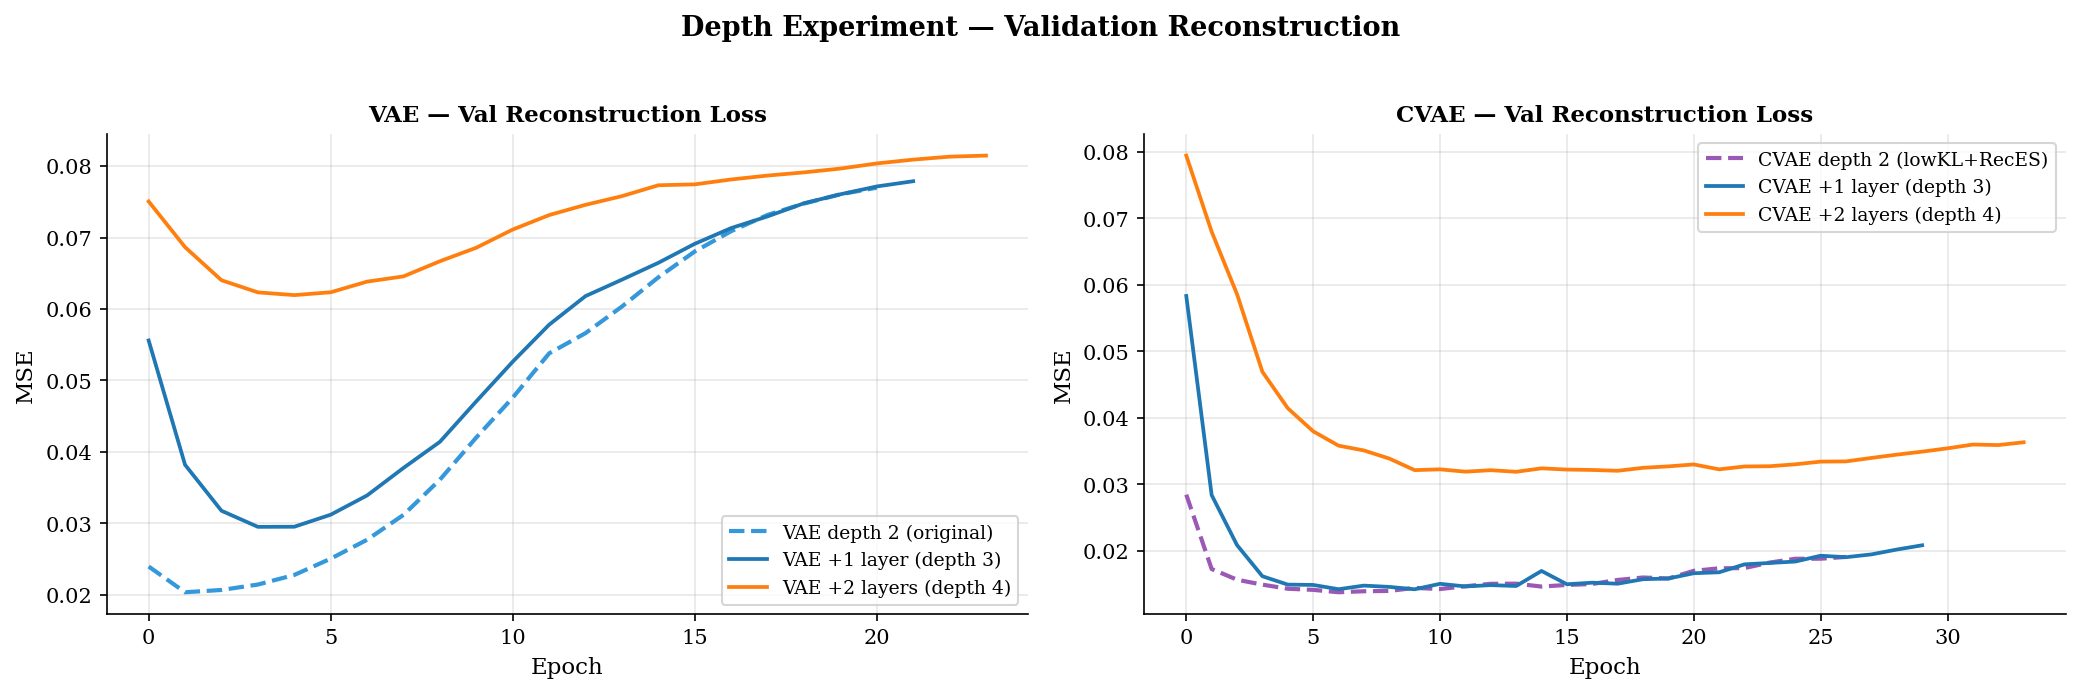

Saved -> 19_depth_curves.png


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# VAE panel
axes[0].plot(vae_history["val_recon"], label="VAE depth 2 (original)",
             color="#3498db", linewidth=2, linestyle="--")
for name, r in vae_depth_results.items():
    axes[0].plot(r["history"]["val_recon"],
                 label=f"VAE {r['config']['label']}",
                 linewidth=1.8)
axes[0].set_title("VAE — Val Reconstruction Loss",
                  fontweight="bold", fontsize=11)
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("MSE")
axes[0].legend(fontsize=9); axes[0].grid(True, alpha=0.3)

# CVAE panel — baseline is lowKL+RecES from cvae_v2_results
axes[1].plot(cvae_v2_results["lowKL+RecES"]["history"]["val_recon"],
             label="CVAE depth 2 (lowKL+RecES)",
             color="#9b59b6", linewidth=2, linestyle="--")
for name, r in cvae_depth_results.items():
    axes[1].plot(r["history"]["val_recon"],
                 label=f"CVAE {r['config']['label']}",
                 linewidth=1.8)
axes[1].set_title("CVAE — Val Reconstruction Loss",
                  fontweight="bold", fontsize=11)
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("MSE")
axes[1].legend(fontsize=9); axes[1].grid(True, alpha=0.3)

plt.suptitle("Depth Experiment — Validation Reconstruction",
             fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(f"{CONFIG['figures_dir']}/19_depth_curves.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("Saved -> 19_depth_curves.png")

## Comparison Table

In [ ]:
print("=" * 100)
print("  Depth Experiment — Full Comparison")
print("=" * 100)
print(f"  {'Model':<32s} {'Params':>10s} {'Epochs':>8s} "
      f"{'MSE':>9s} {'Acc':>7s} {'F1':>7s} "
      f"{'P+ DVR':>9s} {'P- DVR':>9s}")
print("-" * 100)

# Original VAE (depth 2)
n_p_vae_orig = sum(p.numel() for p in vae_model.parameters() if p.requires_grad)
print(f"  {'VAE depth 2 (original)':<32s} "
      f"{n_p_vae_orig:>10,d} "
      f"{len(vae_history['train_loss']):>8d} "
      f"{vae_mse:>9.5f} {vae_acc*100:>6.1f}% {vae_f1:>7.3f} "
      f"{vae_dvr_pos*100:>8.1f}% {vae_dvr_neg*100:>8.1f}%")
for name, r in vae_depth_results.items():
    print(f"  {'VAE ' + r['config']['label']:<32s} "
          f"{r['n_params']:>10,d} {r['epochs_run']:>8d} "
          f"{r['mse']:>9.5f} {r['acc']*100:>6.1f}% {r['f1']:>7.3f} "
          f"{r['dvr_pos']*100:>8.1f}% {r['dvr_neg']*100:>8.1f}%")
print()

# CVAE baseline = depth 2 lowKL+RecES
cv2 = cvae_v2_results["lowKL+RecES"]
n_p_cv2 = count_params(cv2["model"])
print(f"  {'CVAE depth 2 (lowKL+RecES)':<32s} "
      f"{n_p_cv2:>10,d} {cv2['epochs_run']:>8d} "
      f"{'n/a':>9s} {'n/a':>7s} {'n/a':>7s} "
      f"{cv2['dvr_pos']*100:>8.1f}% {cv2['dvr_neg']*100:>8.1f}%")
for name, r in cvae_depth_results.items():
    print(f"  {'CVAE ' + r['config']['label']:<32s} "
          f"{r['n_params']:>10,d} {r['epochs_run']:>8d} "
          f"{r['mse']:>9.5f} {r['acc']*100:>6.1f}% {r['f1']:>7.3f} "
          f"{r['dvr_pos']*100:>8.1f}% {r['dvr_neg']*100:>8.1f}%")
print("=" * 100)
print(f"  Note: CVAE depth 2 baseline does not have MSE/Acc/F1 "
      f"recomputed here — see cvae_v2_results for those.")
print(f"  Ref pool: {CONFIG['dvr_ref_size']:,}  |  "
      f"Eval sample: {CONFIG['dvr_sample_size']} per group  |  "
      f"Seed: {CONFIG['seed']}")

  Depth Experiment — Full Comparison
  Model                                Params   Epochs       MSE     Acc      F1    P+ DVR    P- DVR
----------------------------------------------------------------------------------------------------
  VAE depth 2 (original)               84,853       21   0.02387   84.7%   0.847     87.3%     46.0%
  VAE +1 layer (depth 3)               98,549       22   0.03784   85.6%   0.856     90.6%     54.8%
  VAE +2 layers (depth 4)             101,301       24   0.06221   85.9%   0.859    100.0%     83.4%

  CVAE depth 2 (lowKL+RecES)           85,237       27       n/a     n/a     n/a     72.2%     45.6%
  CVAE +1 layer (depth 3)              98,869       30   0.01420  100.0%   1.000     73.4%     42.6%
  CVAE +2 layers (depth 4)            101,589       34   0.03180  100.0%   1.000     64.8%     76.4%
  Note: CVAE depth 2 baseline does not have MSE/Acc/F1 recomputed here — see cvae_v2_results for those.
  Ref pool: 10,000  |  Eval sample: 500 per group 

## Bar Chart Comparison

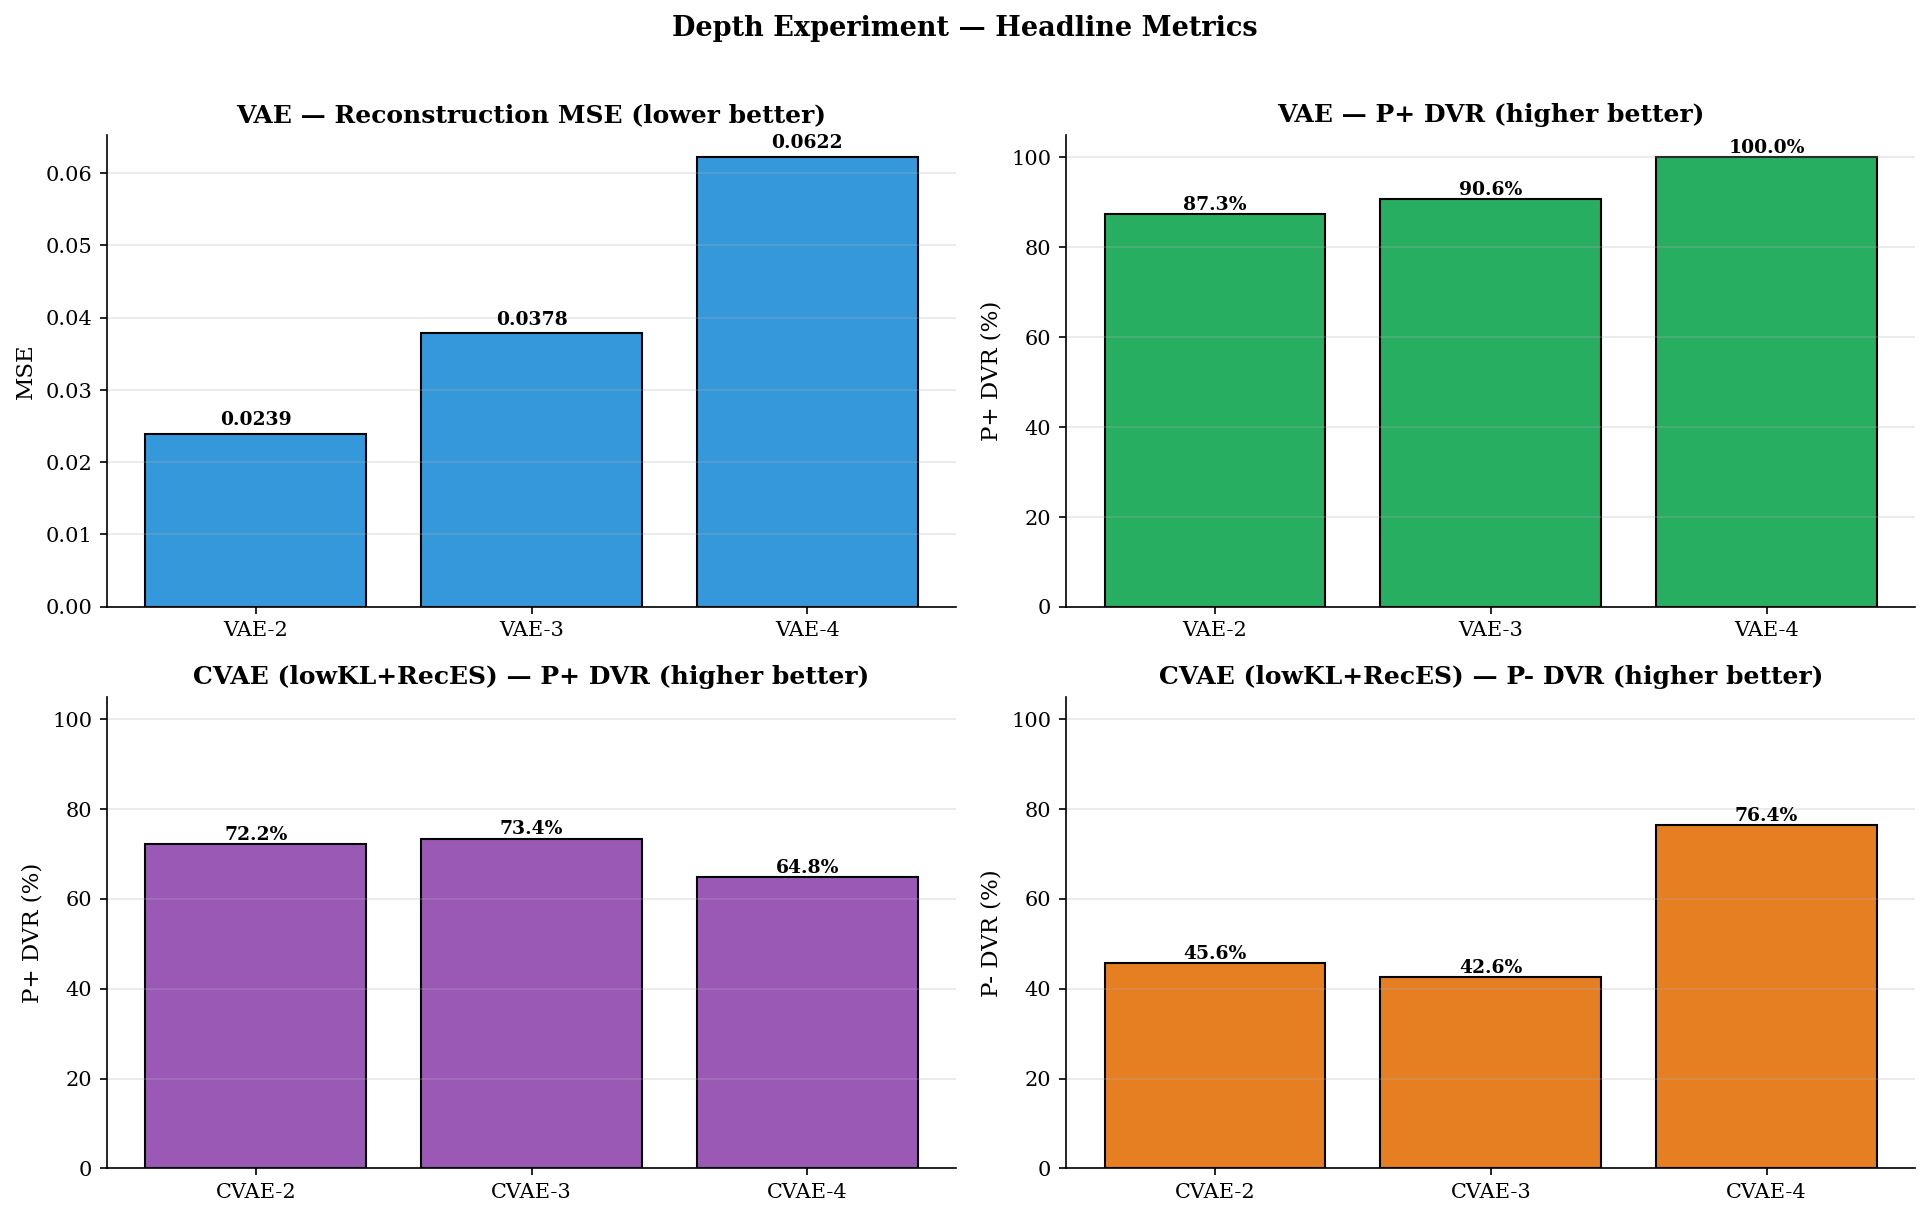

Saved -> 20_depth_bars.png


In [ ]:
# Build comparison arrays
vae_labels = ["VAE-2", "VAE-3", "VAE-4"]
vae_mses   = [vae_mse,
              vae_depth_results["depth3"]["mse"],
              vae_depth_results["depth4"]["mse"]]
vae_f1s    = [vae_f1,
              vae_depth_results["depth3"]["f1"],
              vae_depth_results["depth4"]["f1"]]
vae_dvrp   = [vae_dvr_pos*100,
              vae_depth_results["depth3"]["dvr_pos"]*100,
              vae_depth_results["depth4"]["dvr_pos"]*100]
vae_dvrn   = [vae_dvr_neg*100,
              vae_depth_results["depth3"]["dvr_neg"]*100,
              vae_depth_results["depth4"]["dvr_neg"]*100]

cv2 = cvae_v2_results["lowKL+RecES"]
cvae_labels = ["CVAE-2", "CVAE-3", "CVAE-4"]
cvae_dvrp   = [cv2["dvr_pos"]*100,
               cvae_depth_results["depth3"]["dvr_pos"]*100,
               cvae_depth_results["depth4"]["dvr_pos"]*100]
cvae_dvrn   = [cv2["dvr_neg"]*100,
               cvae_depth_results["depth3"]["dvr_neg"]*100,
               cvae_depth_results["depth4"]["dvr_neg"]*100]

fig, axes = plt.subplots(2, 2, figsize=(13, 8))

# Row 1: VAE
axes[0, 0].bar(vae_labels, vae_mses, color="#3498db", edgecolor="black")
axes[0, 0].set_title("VAE — Reconstruction MSE (lower better)",
                     fontweight="bold")
axes[0, 0].set_ylabel("MSE"); axes[0, 0].grid(True, alpha=0.3, axis="y")
for i, v in enumerate(vae_mses):
    axes[0, 0].text(i, v + max(vae_mses)*0.02, f"{v:.4f}",
                    ha="center", fontweight="bold", fontsize=9)

axes[0, 1].bar(vae_labels, vae_dvrp, color="#27ae60", edgecolor="black")
axes[0, 1].set_title("VAE — P+ DVR (higher better)",
                     fontweight="bold")
axes[0, 1].set_ylabel("P+ DVR (%)"); axes[0, 1].set_ylim(0, 105)
axes[0, 1].grid(True, alpha=0.3, axis="y")
for i, v in enumerate(vae_dvrp):
    axes[0, 1].text(i, v + 1, f"{v:.1f}%",
                    ha="center", fontweight="bold", fontsize=9)

# Row 2: CVAE
axes[1, 0].bar(cvae_labels, cvae_dvrp, color="#9b59b6", edgecolor="black")
axes[1, 0].set_title("CVAE (lowKL+RecES) — P+ DVR (higher better)",
                     fontweight="bold")
axes[1, 0].set_ylabel("P+ DVR (%)"); axes[1, 0].set_ylim(0, 105)
axes[1, 0].grid(True, alpha=0.3, axis="y")
for i, v in enumerate(cvae_dvrp):
    axes[1, 0].text(i, v + 1, f"{v:.1f}%",
                    ha="center", fontweight="bold", fontsize=9)

axes[1, 1].bar(cvae_labels, cvae_dvrn, color="#e67e22", edgecolor="black")
axes[1, 1].set_title("CVAE (lowKL+RecES) — P- DVR (higher better)",
                     fontweight="bold")
axes[1, 1].set_ylabel("P- DVR (%)"); axes[1, 1].set_ylim(0, 105)
axes[1, 1].grid(True, alpha=0.3, axis="y")
for i, v in enumerate(cvae_dvrn):
    axes[1, 1].text(i, v + 1, f"{v:.1f}%",
                    ha="center", fontweight="bold", fontsize=9)

plt.suptitle("Depth Experiment — Headline Metrics",
             fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig(f"{CONFIG['figures_dir']}/20_depth_bars.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("Saved -> 20_depth_bars.png")

## Save Results

In [ ]:
depth_save = {
    "vae_baseline_depth2": {
        "hidden_dims": [256, 128],
        "n_params"   : int(n_p_vae_orig),
        "epochs"     : len(vae_history["train_loss"]),
        "mse"        : float(vae_mse),
        "acc"        : float(vae_acc),
        "f1"         : float(vae_f1),
        "dvr_pos"    : float(vae_dvr_pos),
        "dvr_neg"    : float(vae_dvr_neg),
    },
    "vae_deeper": {
        name: {
            "label"      : r["config"]["label"],
            "hidden_dims": r["config"]["hidden_dims"],
            "n_params"   : int(r["n_params"]),
            "epochs"     : int(r["epochs_run"]),
            "mse"        : float(r["mse"]),
            "acc"        : float(r["acc"]),
            "f1"         : float(r["f1"]),
            "dvr_pos"    : float(r["dvr_pos"]),
            "dvr_neg"    : float(r["dvr_neg"]),
        } for name, r in vae_depth_results.items()
    },
    "cvae_baseline_depth2_lowKLRecES": {
        "hidden_dims": [256, 128],
        "n_params"   : int(n_p_cv2),
        "epochs"     : int(cv2["epochs_run"]),
        "dvr_pos"    : float(cv2["dvr_pos"]),
        "dvr_neg"    : float(cv2["dvr_neg"]),
    },
    "cvae_deeper": {
        name: {
            "label"      : r["config"]["label"],
            "hidden_dims": r["config"]["hidden_dims"],
            "n_params"   : int(r["n_params"]),
            "epochs"     : int(r["epochs_run"]),
            "mse"        : float(r["mse"]),
            "acc"        : float(r["acc"]),
            "f1"         : float(r["f1"]),
            "dvr_pos"    : float(r["dvr_pos"]),
            "dvr_neg"    : float(r["dvr_neg"]),
        } for name, r in cvae_depth_results.items()
    },
    "training_notes": {
        "vae"  : "Original train_vae (KL anneal 0->0.5 over 50 epochs)",
        "cvae" : "train_cvae_v2 with lowKL+RecES (kl_max=0.1, "
                 "early_stop=recon)",
    },
    "config": {
        "dvr_sample_size": CONFIG["dvr_sample_size"],
        "dvr_ref_size"   : CONFIG["dvr_ref_size"],
        "dvr_chunk_size" : CONFIG["dvr_chunk_size"],
        "seed"           : CONFIG["seed"],
    },
}

_path = f"{CONFIG['results_dir']}/depth_experiment_results.json"
with open(_path, "w") as f:
    json.dump(depth_save, f, indent=2)
print(f"Saved -> {_path}")

Saved -> /content/drive/MyDrive/GenMOR/results/depth_experiment_results.json


## Verify Steps

In [ ]:
print("=" * 60)
print("  Depth Experiment Verification")
print("=" * 60)
checks = {
    "All VAE depth variants trained" : len(vae_depth_results) == 2,
    "All CVAE depth variants trained": len(cvae_depth_results) == 2,
    "All VAE checkpoints exist"      : all(
        os.path.exists(r["checkpoint"])
        for r in vae_depth_results.values()),
    "All CVAE checkpoints exist"     : all(
        os.path.exists(r["checkpoint"])
        for r in cvae_depth_results.values()),
    "VAE DVRs in [0, 1]"             : all(
        0 <= r["dvr_pos"] <= 1 and 0 <= r["dvr_neg"] <= 1
        for r in vae_depth_results.values()),
    "CVAE DVRs in [0, 1]"            : all(
        0 <= r["dvr_pos"] <= 1 and 0 <= r["dvr_neg"] <= 1
        for r in cvae_depth_results.values()),
    "Training curves figure saved"   : os.path.exists(
        f"{CONFIG['figures_dir']}/19_depth_curves.png"),
    "Bar chart figure saved"         : os.path.exists(
        f"{CONFIG['figures_dir']}/20_depth_bars.png"),
    "Results JSON saved"             : os.path.exists(
        f"{CONFIG['results_dir']}/depth_experiment_results.json"),
}
all_good = True
for name, status in checks.items():
    icon = "(OK)" if status else "(WARNING)"
    print(f"  {icon} {name}")
    if not status:
        all_good = False
print("=" * 60)

# Quick verdict
best_vae_pos = max([vae_dvr_pos] +
                   [r["dvr_pos"] for r in vae_depth_results.values()])
best_cvae_pos = max([cv2["dvr_pos"]] +
                    [r["dvr_pos"] for r in cvae_depth_results.values()])
print(f"  VAE  best P+ DVR : {best_vae_pos*100:.1f}%  "
      f"(baseline {vae_dvr_pos*100:.1f}%)")
print(f"  CVAE best P+ DVR : {best_cvae_pos*100:.1f}%  "
      f"(baseline {cv2['dvr_pos']*100:.1f}%)")

if all_good:
    print("  (OK) All checks passed.")
else:
    print("  (CHECK) Fix items marked (WARNING).")

  Depth Experiment Verification
  (OK) All VAE depth variants trained
  (OK) All CVAE depth variants trained
  (OK) All VAE checkpoints exist
  (OK) All CVAE checkpoints exist
  (OK) VAE DVRs in [0, 1]
  (OK) CVAE DVRs in [0, 1]
  (OK) Training curves figure saved
  (OK) Bar chart figure saved
  (OK) Results JSON saved
  VAE  best P+ DVR : 100.0%  (baseline 87.3%)
  CVAE best P+ DVR : 73.4%  (baseline 72.2%)
  (OK) All checks passed.


# **Depth Experiment — Adding One More Layer (Depth 5)**

*Continuing the geometric halving pattern from the previous depth experiment, the next natural step is `hidden_dims = [256, 128, 64, 32, 16]` — three layers added relative to the original `[256, 128]`, one layer added relative to the depth-4 variant.*

*Caveat: the last hidden layer (16 units) now equals the latent_dim (16). This means the final hidden representation has the same dimensionality as the latent it projects into. After BatchNorm + ReLU on the last hidden layer, roughly half the activations are zeroed, and then `Linear(16 → 16)` projects to mu and log_var. The effective information capacity at that point may be limited. If depth 5 underperforms depth 3 and depth 4, this tight pre-bottleneck is the likely cause rather than depth itself being harmful.*

*We extend the existing `vae_depth_results` and `cvae_depth_results` dicts with the new entry so all previous comparison cells will pick up the new variant on re-run. The CVAE depth 5 uses the same lowKL+RecES training schedule as depths 3 and 4 to keep the depth axis isolated.*

## Define Depth-5 Variant and Parameter Counts

In [ ]:
# Add depth 5 to the existing variants dict
DEPTH_VARIANTS["depth5"] = {
    "hidden_dims": [256, 128, 64, 32, 16],
    "label"      : "+3 layers (depth 5)",
}

_v5 = VAE(CONFIG["input_dim"],
          DEPTH_VARIANTS["depth5"]["hidden_dims"],
          CONFIG["latent_dim"])
_c5 = CVAE(CONFIG["input_dim"],
           DEPTH_VARIANTS["depth5"]["hidden_dims"],
           CONFIG["latent_dim"])
print("=" * 70)
print("  Depth-5 Parameter Counts")
print("=" * 70)
print(f"  VAE  depth 5 params : {count_params(_v5):>10,d}")
print(f"  CVAE depth 5 params : {count_params(_c5):>10,d}")
print(f"  hidden_dims         : {DEPTH_VARIANTS['depth5']['hidden_dims']}")
print(f"  latent_dim          : {CONFIG['latent_dim']}")
del _v5, _c5
print("=" * 70)

  Depth-5 Parameter Counts
  VAE  depth 5 params :    101,653
  CVAE depth 5 params :    101,925
  hidden_dims         : [256, 128, 64, 32, 16]
  latent_dim          : 16


## Train VAE Depth 5

*Same `train_vae` schedule as VAE depths 2, 3, and 4 — KL anneal 0 → 0.5 over 50 epochs, Adam at lr=1e-3, ReduceLROnPlateau, total-loss early stopping.*

In [ ]:
cfg5 = DEPTH_VARIANTS["depth5"]
print("=" * 70)
print(f"  Training VAE  {cfg5['label']}  hidden_dims={cfg5['hidden_dims']}")
print("=" * 70)

set_seed(CONFIG["seed"])
model = VAE(
    input_dim   = CONFIG["input_dim"],
    hidden_dims = cfg5["hidden_dims"],
    latent_dim  = CONFIG["latent_dim"],
).to(device)
opt = optim.Adam(model.parameters(),
                 lr=CONFIG["learning_rate"], weight_decay=1e-5)
sch = optim.lr_scheduler.ReduceLROnPlateau(
    opt, mode="min", factor=0.5, patience=10)
ckpt = f"{CONFIG['checkpoint_dir']}/vae_depth5.pt"

hist = train_vae(
    model           = model,
    optimizer       = opt,
    scheduler       = sch,
    train_loader    = train_loader,
    val_loader      = val_loader,
    epochs          = CONFIG["epochs"],
    patience        = CONFIG["early_stop_patience"],
    checkpoint_path = ckpt,
)

model.load_state_dict(torch.load(ckpt, map_location=device))
model.eval()

vae_depth_results["depth5"] = {
    "model"     : model,
    "history"   : hist,
    "checkpoint": ckpt,
    "config"    : cfg5,
    "n_params"  : count_params(model),
    "epochs_run": len(hist["train_loss"]),
}
print(f"\nVAE depth 5 trained — params={count_params(model):,d}  "
      f"epochs={len(hist['train_loss'])}")

  Training VAE  +3 layers (depth 5)  hidden_dims=[256, 128, 64, 32, 16]
Epoch    1/200 | Train: 0.30470 (recon=0.08275 kl=0.44858 cls=0.43493) | Val: 0.25334 | kl_w=0.010
Epoch   20/200 | Train: 0.17894 (recon=0.08142 kl=0.14264 cls=0.13799) | Val: 0.33465 | kl_w=0.200

 Early stopping at epoch 24

 Best val loss: 0.24791 → saved to /content/drive/MyDrive/GenMOR/checkpoints/vae_depth5.pt

VAE depth 5 trained — params=101,653  epochs=24


## Train CVAE Depth 5

*Same `train_cvae_v2` schedule with lowKL+RecES settings as CVAE depths 3 and 4 (kl_max=0.1, reconstruction-based early stopping).*

In [ ]:
print("=" * 70)
print(f"  Training CVAE  {cfg5['label']}  hidden_dims={cfg5['hidden_dims']}")
print(f"  Training schedule: lowKL+RecES (kl_max=0.1, early_stop=recon)")
print("=" * 70)

set_seed(CONFIG["seed"])
model = CVAE(
    input_dim   = CONFIG["input_dim"],
    hidden_dims = cfg5["hidden_dims"],
    latent_dim  = CONFIG["latent_dim"],
).to(device)
opt = optim.Adam(model.parameters(),
                 lr=CONFIG["learning_rate"], weight_decay=1e-5)
sch = optim.lr_scheduler.ReduceLROnPlateau(
    opt, mode="min", factor=0.5, patience=10)
ckpt = f"{CONFIG['checkpoint_dir']}/cvae_depth5.pt"

hist = train_cvae_v2(
    model           = model,
    optimizer       = opt,
    scheduler       = sch,
    train_loader    = train_loader,
    val_loader      = val_loader,
    epochs          = CONFIG["epochs"],
    patience        = CONFIG["early_stop_patience"],
    checkpoint_path = ckpt,
    **CVAE_TRAIN_CFG,
)

model.load_state_dict(torch.load(ckpt, map_location=device))
model.eval()

cvae_depth_results["depth5"] = {
    "model"     : model,
    "history"   : hist,
    "checkpoint": ckpt,
    "config"    : cfg5,
    "n_params"  : count_params(model),
    "epochs_run": len(hist["train_loss"]),
}
print(f"\nCVAE depth 5 trained — params={count_params(model):,d}  "
      f"epochs={len(hist['train_loss'])}")

  Training CVAE  +3 layers (depth 5)  hidden_dims=[256, 128, 64, 32, 16]
  Training schedule: lowKL+RecES (kl_max=0.1, early_stop=recon)
Epoch    1/200 | Train: 0.17853 (recon=0.08462 kl=0.55502 cls=0.18561) | Val_total: 0.08615 Val_recon: 0.08279 | kl_w=0.002
Epoch   20/200 | Train: 0.07678 (recon=0.05928 kl=0.42734 cls=0.00082) | Val_total: 0.07017 Val_recon: 0.05301 | kl_w=0.040
Epoch   40/200 | Train: 0.08666 (recon=0.06566 kl=0.25624 cls=0.00100) | Val_total: 0.07700 Val_recon: 0.05705 | kl_w=0.080

 Early stopping at epoch 46 (criterion: recon)

 Best recon-loss: 0.05273 -> /content/drive/MyDrive/GenMOR/checkpoints/cvae_depth5.pt

CVAE depth 5 trained — params=101,925  epochs=46


## Evaluate VAE Depth 5

*Same evaluation protocol as the depth-3/4 cells: test-set MSE, classification accuracy and F1, then DVR via 2000 N(0,I) samples split by classifier.*

In [ ]:
np.random.seed(CONFIG["seed"])
torch.manual_seed(CONFIG["seed"])

r = vae_depth_results["depth5"]
model = r["model"]
model.eval()

# Test-set MSE + classification
xs, xrs, yts, yps = [], [], [], []
with torch.no_grad():
    for x_batch, y_batch in test_loader:
        x_batch = x_batch.to(device)
        x_recon, mu, log_var, z, y_p = model(x_batch)
        xs.append(x_batch.cpu().numpy())
        xrs.append(x_recon.cpu().numpy())
        yts.append(y_batch.numpy())
        yps.append(y_p.cpu().numpy())
xs  = np.concatenate(xs);  xrs = np.concatenate(xrs)
yts = np.concatenate(yts); yps = np.concatenate(yps)

r["mse"] = float(np.mean((xs - xrs) ** 2))
r["acc"] = float(accuracy_score(yts, (yps >= 0.5).astype(int)))
r["f1"]  = float(f1_score(yts, (yps >= 0.5).astype(int),
                          average="weighted"))

# DVR via N(0,I) generation + classifier split
gen_scaled, _ = model.generate(2000, device)
with torch.no_grad():
    gt = torch.tensor(gen_scaled, dtype=torch.float32).to(device)
    _, _, _, _, gyp = model(gt)
    gyb = (gyp.cpu().numpy() >= 0.5).astype(int)

gen_orig = np.clip(scaler.inverse_transform(gen_scaled), 1, 100)
gen_pos  = gen_orig[gyb == 1]
gen_neg  = gen_orig[gyb == 0]
r["n_gen_pos"] = int(len(gen_pos))
r["n_gen_neg"] = int(len(gen_neg))

if len(gen_pos) > 0:
    r["dvr_pos"], r["vp"], r["np"] = compute_dvr_chunked(
        gen_pos, X_sel_full, selected_indices,
        target="positive",
        sample_size = CONFIG["dvr_sample_size"],
        ref_size    = CONFIG["dvr_ref_size"],
        chunk_size  = CONFIG["dvr_chunk_size"],
        seed        = CONFIG["seed"])
else:
    r["dvr_pos"], r["vp"], r["np"] = 0.0, 0, 0

if len(gen_neg) > 0:
    r["dvr_neg"], r["vn"], r["nn"] = compute_dvr_chunked(
        gen_neg, X_sel_full, selected_indices,
        target="negative",
        sample_size = CONFIG["dvr_sample_size"],
        ref_size    = CONFIG["dvr_ref_size"],
        chunk_size  = CONFIG["dvr_chunk_size"],
        seed        = CONFIG["seed"])
else:
    r["dvr_neg"], r["vn"], r["nn"] = 0.0, 0, 0

print(f"VAE depth 5  MSE={r['mse']:.5f}  Acc={r['acc']*100:.1f}%  "
      f"F1={r['f1']:.3f}  "
      f"P+ DVR={r['dvr_pos']*100:.1f}%  P- DVR={r['dvr_neg']*100:.1f}%")
print(f"  Classifier split: {r['n_gen_pos']} predicted P+, "
      f"{r['n_gen_neg']} predicted P-")

VAE depth 5  MSE=0.07668  Acc=86.1%  F1=0.860  P+ DVR=0.0%  P- DVR=97.4%
  Classifier split: 0 predicted P+, 2000 predicted P-


## Evaluate CVAE Depth 5

*Same protocol as CVAE depth 3 and 4: test-set MSE/acc/F1, then conditional generation of 500 P+ and 500 P- via `model.generate(n, target_label, device)`, then DVR per class.*

In [ ]:
np.random.seed(CONFIG["seed"])
torch.manual_seed(CONFIG["seed"])
N_PER_CLASS = 500

r = cvae_depth_results["depth5"]
model = r["model"]
model.eval()

# Test-set MSE + classification
xs, xrs, yts, yps = [], [], [], []
with torch.no_grad():
    for x_batch, y_batch in test_loader:
        x_batch = x_batch.to(device)
        y_batch = y_batch.to(device)
        x_recon, mu, log_var, z, y_p = model(x_batch, y_batch)
        xs.append(x_batch.cpu().numpy())
        xrs.append(x_recon.cpu().numpy())
        yts.append(y_batch.cpu().numpy())
        yps.append(y_p.cpu().numpy())
xs  = np.concatenate(xs);  xrs = np.concatenate(xrs)
yts = np.concatenate(yts); yps = np.concatenate(yps)

r["mse"] = float(np.mean((xs - xrs) ** 2))
r["acc"] = float(accuracy_score(yts, (yps >= 0.5).astype(int)))
r["f1"]  = float(f1_score(yts, (yps >= 0.5).astype(int),
                          average="weighted"))

# Conditional generation + DVR
gen_pos_scaled, _ = model.generate(N_PER_CLASS, 1.0, device)
gen_neg_scaled, _ = model.generate(N_PER_CLASS, 0.0, device)
gen_pos_orig = np.clip(scaler.inverse_transform(gen_pos_scaled), 1, 100)
gen_neg_orig = np.clip(scaler.inverse_transform(gen_neg_scaled), 1, 100)

r["dvr_pos"], r["vp"], r["np"] = compute_dvr_chunked(
    gen_pos_orig, X_sel_full, selected_indices,
    target="positive",
    sample_size = CONFIG["dvr_sample_size"],
    ref_size    = CONFIG["dvr_ref_size"],
    chunk_size  = CONFIG["dvr_chunk_size"],
    seed        = CONFIG["seed"])
r["dvr_neg"], r["vn"], r["nn"] = compute_dvr_chunked(
    gen_neg_orig, X_sel_full, selected_indices,
    target="negative",
    sample_size = CONFIG["dvr_sample_size"],
    ref_size    = CONFIG["dvr_ref_size"],
    chunk_size  = CONFIG["dvr_chunk_size"],
    seed        = CONFIG["seed"])

print(f"CVAE depth 5  MSE={r['mse']:.5f}  Acc={r['acc']*100:.1f}%  "
      f"F1={r['f1']:.3f}  "
      f"P+ DVR={r['dvr_pos']*100:.1f}%  P- DVR={r['dvr_neg']*100:.1f}%")

CVAE depth 5  MSE=0.05246  Acc=100.0%  F1=1.000  P+ DVR=60.0%  P- DVR=91.0%


## Updated Training Curves (Depth 2 through 5)

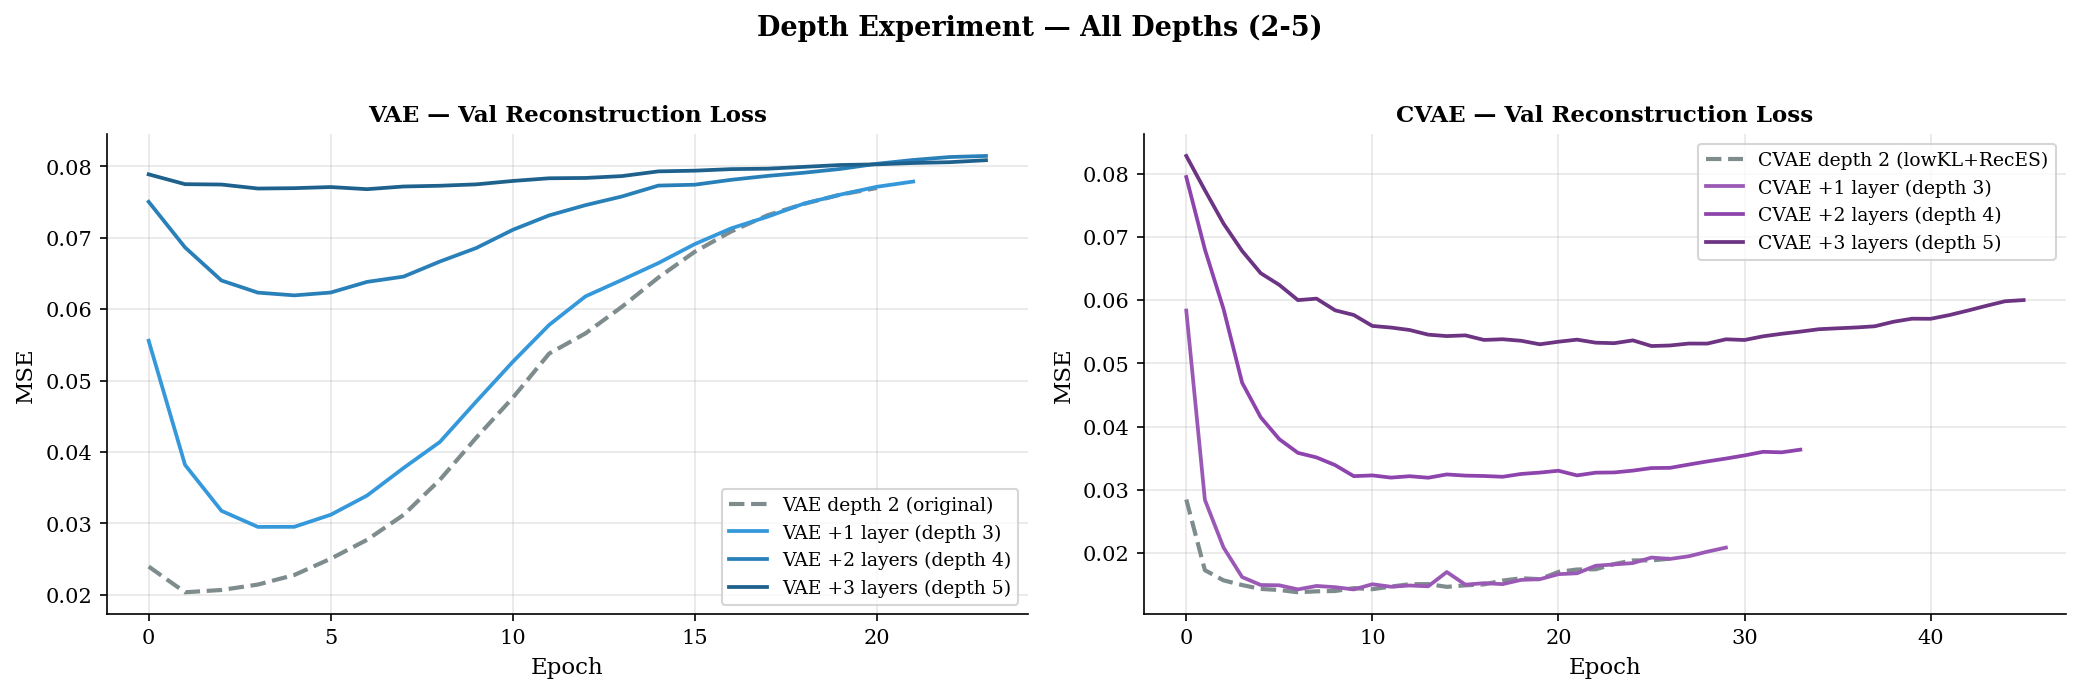

Saved -> 21_depth_curves_d5.png


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# VAE
axes[0].plot(vae_history["val_recon"], label="VAE depth 2 (original)",
             color="#7f8c8d", linewidth=2, linestyle="--")
colors_v = {"depth3": "#3498db", "depth4": "#2980b9", "depth5": "#1f618d"}
for name in ["depth3", "depth4", "depth5"]:
    r = vae_depth_results[name]
    axes[0].plot(r["history"]["val_recon"],
                 label=f"VAE {r['config']['label']}",
                 color=colors_v[name], linewidth=1.8)
axes[0].set_title("VAE — Val Reconstruction Loss",
                  fontweight="bold", fontsize=11)
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("MSE")
axes[0].legend(fontsize=9); axes[0].grid(True, alpha=0.3)

# CVAE
axes[1].plot(cvae_v2_results["lowKL+RecES"]["history"]["val_recon"],
             label="CVAE depth 2 (lowKL+RecES)",
             color="#7f8c8d", linewidth=2, linestyle="--")
colors_c = {"depth3": "#9b59b6", "depth4": "#8e44ad", "depth5": "#6c3483"}
for name in ["depth3", "depth4", "depth5"]:
    r = cvae_depth_results[name]
    axes[1].plot(r["history"]["val_recon"],
                 label=f"CVAE {r['config']['label']}",
                 color=colors_c[name], linewidth=1.8)
axes[1].set_title("CVAE — Val Reconstruction Loss",
                  fontweight="bold", fontsize=11)
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("MSE")
axes[1].legend(fontsize=9); axes[1].grid(True, alpha=0.3)

plt.suptitle("Depth Experiment — All Depths (2-5)",
             fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(f"{CONFIG['figures_dir']}/21_depth_curves_d5.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("Saved -> 21_depth_curves_d5.png")

## Updated Comparison Table (All Depths)

In [ ]:
print("=" * 100)
print("  Depth Experiment — Full Comparison (Depths 2 through 5)")
print("=" * 100)
print(f"  {'Model':<32s} {'Params':>10s} {'Epochs':>8s} "
      f"{'MSE':>9s} {'Acc':>7s} {'F1':>7s} "
      f"{'P+ DVR':>9s} {'P- DVR':>9s}")
print("-" * 100)

# VAE rows
print(f"  {'VAE depth 2 (original)':<32s} "
      f"{n_p_vae_orig:>10,d} "
      f"{len(vae_history['train_loss']):>8d} "
      f"{vae_mse:>9.5f} {vae_acc*100:>6.1f}% {vae_f1:>7.3f} "
      f"{vae_dvr_pos*100:>8.1f}% {vae_dvr_neg*100:>8.1f}%")
for name in ["depth3", "depth4", "depth5"]:
    r = vae_depth_results[name]
    print(f"  {'VAE ' + r['config']['label']:<32s} "
          f"{r['n_params']:>10,d} {r['epochs_run']:>8d} "
          f"{r['mse']:>9.5f} {r['acc']*100:>6.1f}% {r['f1']:>7.3f} "
          f"{r['dvr_pos']*100:>8.1f}% {r['dvr_neg']*100:>8.1f}%")
print()

# CVAE rows
cv2 = cvae_v2_results["lowKL+RecES"]
print(f"  {'CVAE depth 2 (lowKL+RecES)':<32s} "
      f"{n_p_cv2:>10,d} {cv2['epochs_run']:>8d} "
      f"{'n/a':>9s} {'n/a':>7s} {'n/a':>7s} "
      f"{cv2['dvr_pos']*100:>8.1f}% {cv2['dvr_neg']*100:>8.1f}%")
for name in ["depth3", "depth4", "depth5"]:
    r = cvae_depth_results[name]
    print(f"  {'CVAE ' + r['config']['label']:<32s} "
          f"{r['n_params']:>10,d} {r['epochs_run']:>8d} "
          f"{r['mse']:>9.5f} {r['acc']*100:>6.1f}% {r['f1']:>7.3f} "
          f"{r['dvr_pos']*100:>8.1f}% {r['dvr_neg']*100:>8.1f}%")
print("=" * 100)
print(f"  Ref pool: {CONFIG['dvr_ref_size']:,}  |  "
      f"Eval sample: {CONFIG['dvr_sample_size']} per group  |  "
      f"Seed: {CONFIG['seed']}")

  Depth Experiment — Full Comparison (Depths 2 through 5)
  Model                                Params   Epochs       MSE     Acc      F1    P+ DVR    P- DVR
----------------------------------------------------------------------------------------------------
  VAE depth 2 (original)               84,853       21   0.02387   84.7%   0.847     87.3%     46.0%
  VAE +1 layer (depth 3)               98,549       22   0.03784   85.6%   0.856     90.6%     54.8%
  VAE +2 layers (depth 4)             101,301       24   0.06221   85.9%   0.859    100.0%     83.4%
  VAE +3 layers (depth 5)             101,653       24   0.07668   86.1%   0.860      0.0%     97.4%

  CVAE depth 2 (lowKL+RecES)           85,237       27       n/a     n/a     n/a     72.2%     45.6%
  CVAE +1 layer (depth 3)              98,869       30   0.01420  100.0%   1.000     73.4%     42.6%
  CVAE +2 layers (depth 4)            101,589       34   0.03180  100.0%   1.000     64.8%     76.4%
  CVAE +3 layers (depth 5)      

In [ ]:
r = vae_depth_results["depth5"]
print(f"VAE depth 5: predicted P+ = {r['n_gen_pos']},  predicted P- = {r['n_gen_neg']}")
print(f"  P+ DVR was computed on {r['np']} samples (0 = placeholder, not real)")

VAE depth 5: predicted P+ = 0,  predicted P- = 2000
  P+ DVR was computed on 0 samples (0 = placeholder, not real)


## Updated Bar Charts

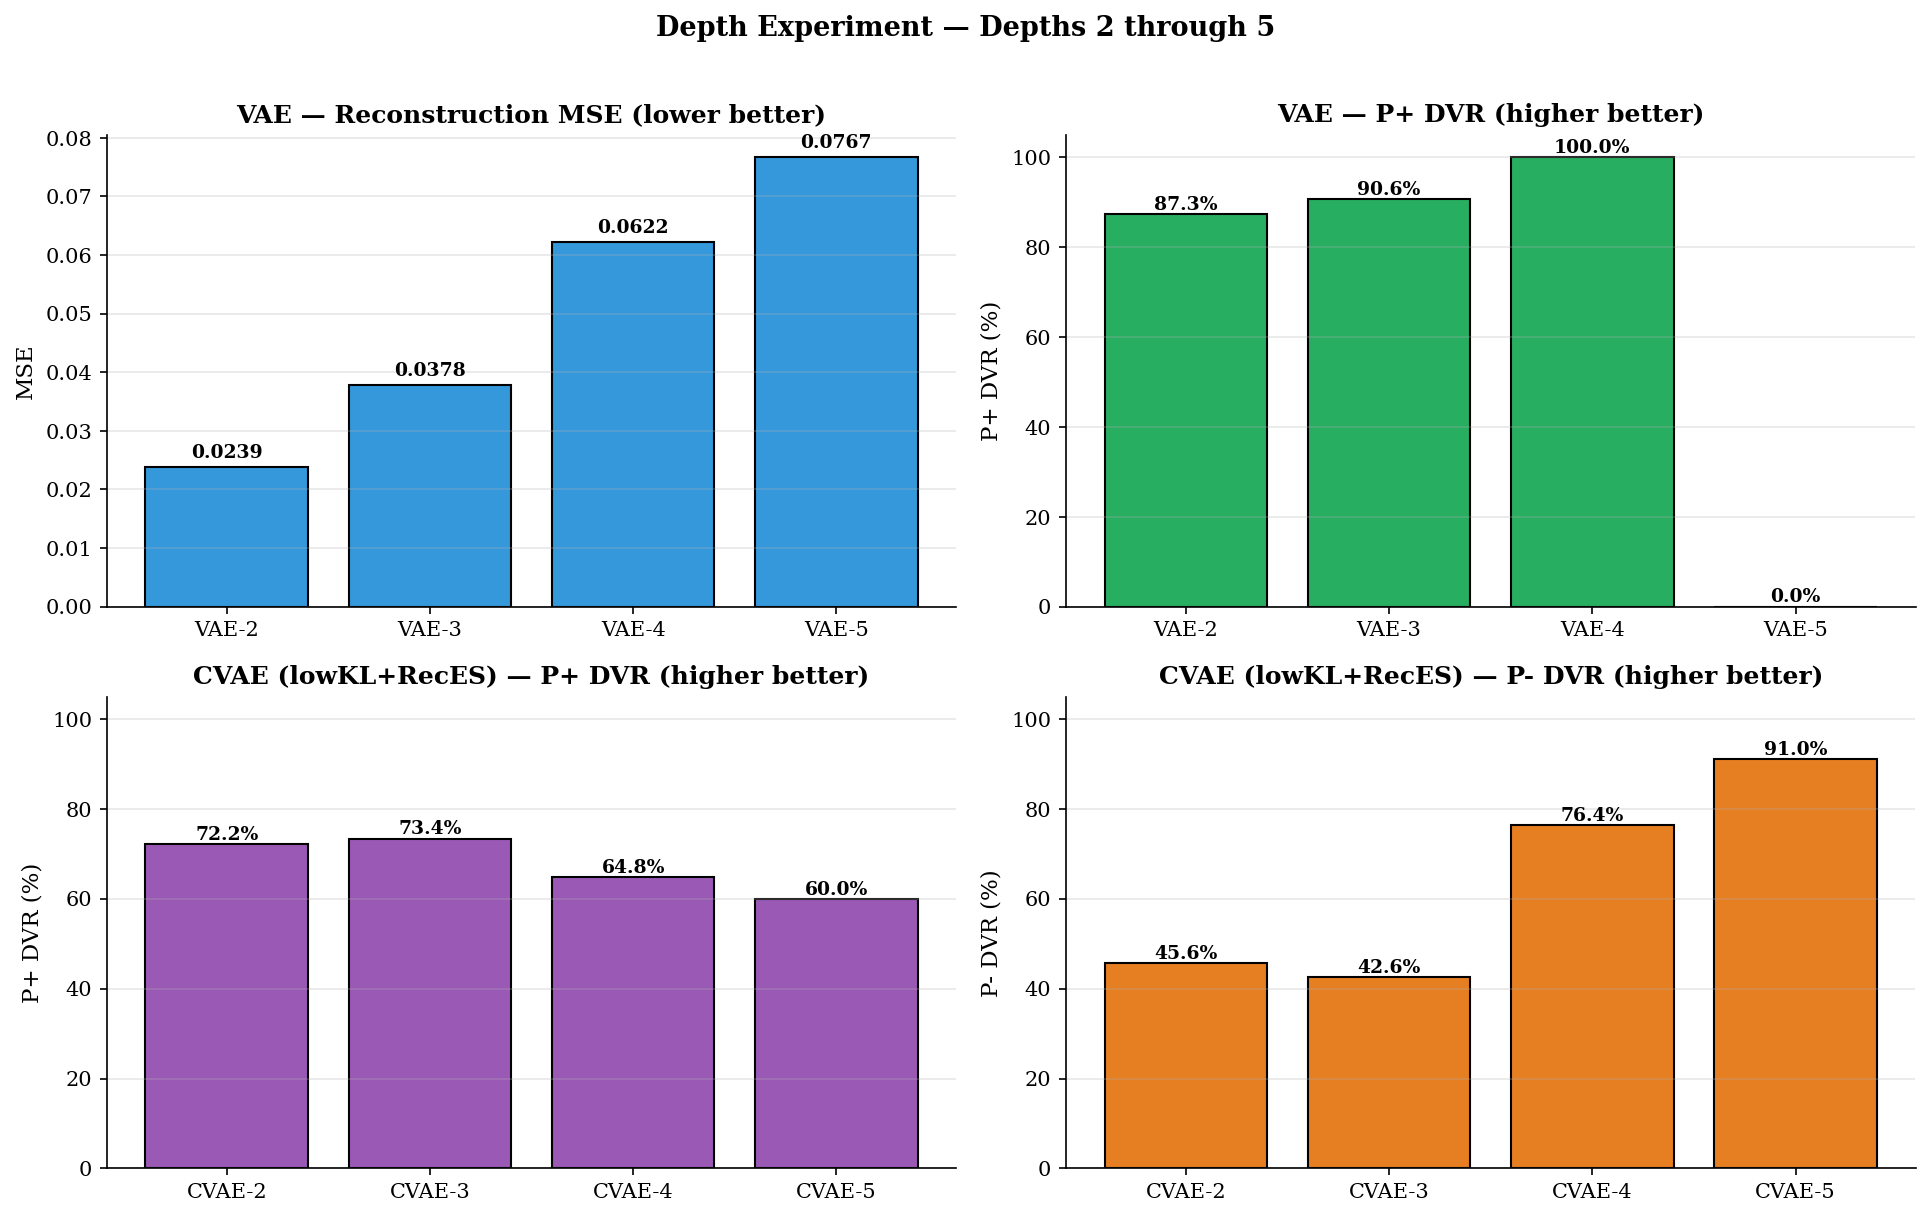

Saved -> 22_depth_bars_d5.png


In [ ]:
vae_labels = ["VAE-2", "VAE-3", "VAE-4", "VAE-5"]
vae_mses   = [vae_mse] + [vae_depth_results[d]["mse"]
                          for d in ["depth3", "depth4", "depth5"]]
vae_dvrp   = [vae_dvr_pos*100] + [vae_depth_results[d]["dvr_pos"]*100
                                  for d in ["depth3", "depth4", "depth5"]]

cvae_labels = ["CVAE-2", "CVAE-3", "CVAE-4", "CVAE-5"]
cvae_dvrp   = [cv2["dvr_pos"]*100] + [cvae_depth_results[d]["dvr_pos"]*100
                                      for d in ["depth3", "depth4", "depth5"]]
cvae_dvrn   = [cv2["dvr_neg"]*100] + [cvae_depth_results[d]["dvr_neg"]*100
                                      for d in ["depth3", "depth4", "depth5"]]

fig, axes = plt.subplots(2, 2, figsize=(13, 8))

axes[0, 0].bar(vae_labels, vae_mses, color="#3498db", edgecolor="black")
axes[0, 0].set_title("VAE — Reconstruction MSE (lower better)",
                     fontweight="bold")
axes[0, 0].set_ylabel("MSE"); axes[0, 0].grid(True, alpha=0.3, axis="y")
for i, v in enumerate(vae_mses):
    axes[0, 0].text(i, v + max(vae_mses)*0.02, f"{v:.4f}",
                    ha="center", fontweight="bold", fontsize=9)

axes[0, 1].bar(vae_labels, vae_dvrp, color="#27ae60", edgecolor="black")
axes[0, 1].set_title("VAE — P+ DVR (higher better)", fontweight="bold")
axes[0, 1].set_ylabel("P+ DVR (%)"); axes[0, 1].set_ylim(0, 105)
axes[0, 1].grid(True, alpha=0.3, axis="y")
for i, v in enumerate(vae_dvrp):
    axes[0, 1].text(i, v + 1, f"{v:.1f}%",
                    ha="center", fontweight="bold", fontsize=9)

axes[1, 0].bar(cvae_labels, cvae_dvrp, color="#9b59b6", edgecolor="black")
axes[1, 0].set_title("CVAE (lowKL+RecES) — P+ DVR (higher better)",
                     fontweight="bold")
axes[1, 0].set_ylabel("P+ DVR (%)"); axes[1, 0].set_ylim(0, 105)
axes[1, 0].grid(True, alpha=0.3, axis="y")
for i, v in enumerate(cvae_dvrp):
    axes[1, 0].text(i, v + 1, f"{v:.1f}%",
                    ha="center", fontweight="bold", fontsize=9)

axes[1, 1].bar(cvae_labels, cvae_dvrn, color="#e67e22", edgecolor="black")
axes[1, 1].set_title("CVAE (lowKL+RecES) — P- DVR (higher better)",
                     fontweight="bold")
axes[1, 1].set_ylabel("P- DVR (%)"); axes[1, 1].set_ylim(0, 105)
axes[1, 1].grid(True, alpha=0.3, axis="y")
for i, v in enumerate(cvae_dvrn):
    axes[1, 1].text(i, v + 1, f"{v:.1f}%",
                    ha="center", fontweight="bold", fontsize=9)

plt.suptitle("Depth Experiment — Depths 2 through 5",
             fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig(f"{CONFIG['figures_dir']}/22_depth_bars_d5.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("Saved -> 22_depth_bars_d5.png")

## Save Results (Including Depth 5)

*Overwrites `depth_experiment_results.json` with all four depths.*

In [ ]:
depth_save = {
    "vae_baseline_depth2": {
        "hidden_dims": [256, 128],
        "n_params"   : int(n_p_vae_orig),
        "epochs"     : len(vae_history["train_loss"]),
        "mse"        : float(vae_mse),
        "acc"        : float(vae_acc),
        "f1"         : float(vae_f1),
        "dvr_pos"    : float(vae_dvr_pos),
        "dvr_neg"    : float(vae_dvr_neg),
    },
    "vae_deeper": {
        name: {
            "label"      : r["config"]["label"],
            "hidden_dims": r["config"]["hidden_dims"],
            "n_params"   : int(r["n_params"]),
            "epochs"     : int(r["epochs_run"]),
            "mse"        : float(r["mse"]),
            "acc"        : float(r["acc"]),
            "f1"         : float(r["f1"]),
            "dvr_pos"    : float(r["dvr_pos"]),
            "dvr_neg"    : float(r["dvr_neg"]),
        } for name, r in vae_depth_results.items()
    },
    "cvae_baseline_depth2_lowKLRecES": {
        "hidden_dims": [256, 128],
        "n_params"   : int(n_p_cv2),
        "epochs"     : int(cv2["epochs_run"]),
        "dvr_pos"    : float(cv2["dvr_pos"]),
        "dvr_neg"    : float(cv2["dvr_neg"]),
    },
    "cvae_deeper": {
        name: {
            "label"      : r["config"]["label"],
            "hidden_dims": r["config"]["hidden_dims"],
            "n_params"   : int(r["n_params"]),
            "epochs"     : int(r["epochs_run"]),
            "mse"        : float(r["mse"]),
            "acc"        : float(r["acc"]),
            "f1"         : float(r["f1"]),
            "dvr_pos"    : float(r["dvr_pos"]),
            "dvr_neg"    : float(r["dvr_neg"]),
        } for name, r in cvae_depth_results.items()
    },
    "training_notes": {
        "vae"  : "Original train_vae (KL anneal 0->0.5 over 50 epochs)",
        "cvae" : "train_cvae_v2 with lowKL+RecES (kl_max=0.1, "
                 "early_stop=recon)",
        "depth5_caveat": (
            "Depth 5 has last hidden layer == latent_dim (both 16). "
            "Tight pre-bottleneck may limit information flow."
        ),
    },
    "config": {
        "dvr_sample_size": CONFIG["dvr_sample_size"],
        "dvr_ref_size"   : CONFIG["dvr_ref_size"],
        "dvr_chunk_size" : CONFIG["dvr_chunk_size"],
        "seed"           : CONFIG["seed"],
    },
}

_path = f"{CONFIG['results_dir']}/depth_experiment_results.json"
with open(_path, "w") as f:
    json.dump(depth_save, f, indent=2)
print(f"Saved -> {_path} (now includes depth 5)")

Saved -> /content/drive/MyDrive/GenMOR/results/depth_experiment_results.json (now includes depth 5)


## Verify Steps

In [ ]:
print("=" * 60)
print("  Depth-5 Verification")
print("=" * 60)
checks = {
    "VAE depth 5 trained"           : "depth5" in vae_depth_results,
    "CVAE depth 5 trained"          : "depth5" in cvae_depth_results,
    "VAE depth 5 checkpoint exists" : os.path.exists(
        vae_depth_results["depth5"]["checkpoint"]),
    "CVAE depth 5 checkpoint exists": os.path.exists(
        cvae_depth_results["depth5"]["checkpoint"]),
    "VAE depth 5 DVRs in [0,1]"     : (
        0 <= vae_depth_results["depth5"]["dvr_pos"] <= 1
        and 0 <= vae_depth_results["depth5"]["dvr_neg"] <= 1),
    "CVAE depth 5 DVRs in [0,1]"    : (
        0 <= cvae_depth_results["depth5"]["dvr_pos"] <= 1
        and 0 <= cvae_depth_results["depth5"]["dvr_neg"] <= 1),
    "Updated curves figure saved"   : os.path.exists(
        f"{CONFIG['figures_dir']}/21_depth_curves_d5.png"),
    "Updated bar chart saved"       : os.path.exists(
        f"{CONFIG['figures_dir']}/22_depth_bars_d5.png"),
}
all_good = True
for name, status in checks.items():
    icon = "(OK)" if status else "(WARNING)"
    print(f"  {icon} {name}")
    if not status:
        all_good = False
print("=" * 60)

# Best-so-far summary across all depths
best_vae_d = max(
    [("depth2", vae_dvr_pos)] +
    [(d, vae_depth_results[d]["dvr_pos"])
     for d in ["depth3", "depth4", "depth5"]],
    key=lambda t: t[1])
best_cvae_d = max(
    [("depth2", cv2["dvr_pos"])] +
    [(d, cvae_depth_results[d]["dvr_pos"])
     for d in ["depth3", "depth4", "depth5"]],
    key=lambda t: t[1])
print(f"  Best VAE  depth for P+ DVR : {best_vae_d[0]}  "
      f"({best_vae_d[1]*100:.1f}%)")
print(f"  Best CVAE depth for P+ DVR : {best_cvae_d[0]}  "
      f"({best_cvae_d[1]*100:.1f}%)")
print("=" * 60)
if all_good:
    print("  (OK) All checks passed.")
else:
    print("  (CHECK) Fix items marked (WARNING).")

  Depth-5 Verification
  (OK) VAE depth 5 trained
  (OK) CVAE depth 5 trained
  (OK) VAE depth 5 checkpoint exists
  (OK) CVAE depth 5 checkpoint exists
  (OK) VAE depth 5 DVRs in [0,1]
  (OK) CVAE depth 5 DVRs in [0,1]
  (OK) Updated curves figure saved
  (OK) Updated bar chart saved
  Best VAE  depth for P+ DVR : depth4  (100.0%)
  Best CVAE depth for P+ DVR : depth3  (73.4%)
  (OK) All checks passed.


# **Depth 5 Retry — Non-Collapsing Hidden Dims**

*The first depth-5 attempt used `hidden_dims = [256, 128, 64, 32, 16]`, where the last hidden layer matched the latent_dim. We diagnosed this as the likely cause of VAE depth 5's collapse: a 16-dim ReLU layer immediately before the 16-dim variational projection caused information loss right at the latent boundary.*

*This retry uses `hidden_dims = [256, 128, 64, 32, 24]`, keeping the last hidden layer wider than the latent (24 > 16). Same total depth (5 hidden layers), same encoder/decoder pattern, same training schedules as depths 3/4. Only the last hidden dimension changes. If this variant works better than depth-5 collapsing, the architectural diagnosis is confirmed: depth itself is fine, the geometric pinch at the latent boundary was the problem.*

*We store results under `depth5b` to keep the collapsing depth-5 results intact for direct comparison.*

## Add Depth-5b Variant and Parameter Count

In [ ]:
DEPTH_VARIANTS["depth5b"] = {
    "hidden_dims": [256, 128, 64, 32, 24],
    "label"      : "+3 layers (depth 5b, non-collapsing)",
}

_v5b = VAE(CONFIG["input_dim"],
           DEPTH_VARIANTS["depth5b"]["hidden_dims"],
           CONFIG["latent_dim"])
_c5b = CVAE(CONFIG["input_dim"],
            DEPTH_VARIANTS["depth5b"]["hidden_dims"],
            CONFIG["latent_dim"])

print("=" * 70)
print("  Depth-5b (Non-Collapsing) Parameter Counts")
print("=" * 70)
print(f"  hidden_dims         : {DEPTH_VARIANTS['depth5b']['hidden_dims']}")
print(f"  last hidden vs latent: 24 > 16 (no pinch)")
print(f"  VAE  depth 5b params : {count_params(_v5b):>10,d}")
print(f"  CVAE depth 5b params : {count_params(_c5b):>10,d}")
print(f"  (compare to depth 5 collapsing VAE: "
      f"{vae_depth_results['depth5']['n_params']:,d})")
del _v5b, _c5b
print("=" * 70)

  Depth-5b (Non-Collapsing) Parameter Counts
  hidden_dims         : [256, 128, 64, 32, 24]
  last hidden vs latent: 24 > 16 (no pinch)
  VAE  depth 5b params :    102,597
  CVAE depth 5b params :    102,877
  (compare to depth 5 collapsing VAE: 101,653)


## Train VAE Depth 5b

In [ ]:
cfg5b = DEPTH_VARIANTS["depth5b"]
print("=" * 70)
print(f"  Training VAE  {cfg5b['label']}")
print(f"  hidden_dims = {cfg5b['hidden_dims']}")
print("=" * 70)

set_seed(CONFIG["seed"])
model = VAE(
    input_dim   = CONFIG["input_dim"],
    hidden_dims = cfg5b["hidden_dims"],
    latent_dim  = CONFIG["latent_dim"],
).to(device)
opt = optim.Adam(model.parameters(),
                 lr=CONFIG["learning_rate"], weight_decay=1e-5)
sch = optim.lr_scheduler.ReduceLROnPlateau(
    opt, mode="min", factor=0.5, patience=10)
ckpt = f"{CONFIG['checkpoint_dir']}/vae_depth5b.pt"

hist = train_vae(
    model           = model,
    optimizer       = opt,
    scheduler       = sch,
    train_loader    = train_loader,
    val_loader      = val_loader,
    epochs          = CONFIG["epochs"],
    patience        = CONFIG["early_stop_patience"],
    checkpoint_path = ckpt,
)

model.load_state_dict(torch.load(ckpt, map_location=device))
model.eval()

vae_depth_results["depth5b"] = {
    "model"     : model,
    "history"   : hist,
    "checkpoint": ckpt,
    "config"    : cfg5b,
    "n_params"  : count_params(model),
    "epochs_run": len(hist["train_loss"]),
}
print(f"\nVAE depth 5b trained — "
      f"params={count_params(model):,d}  "
      f"epochs={len(hist['train_loss'])}")

  Training VAE  +3 layers (depth 5b, non-collapsing)
  hidden_dims = [256, 128, 64, 32, 24]
Epoch    1/200 | Train: 0.30353 (recon=0.08282 kl=0.59157 cls=0.42958) | Val: 0.24959 | kl_w=0.010
Epoch   20/200 | Train: 0.17676 (recon=0.08134 kl=0.14361 cls=0.13339) | Val: 0.33775 | kl_w=0.200

 Early stopping at epoch 23

 Best val loss: 0.24803 → saved to /content/drive/MyDrive/GenMOR/checkpoints/vae_depth5b.pt

VAE depth 5b trained — params=102,597  epochs=23


## Train CVAE Depth 5b

In [ ]:
print("=" * 70)
print(f"  Training CVAE  {cfg5b['label']}")
print(f"  hidden_dims = {cfg5b['hidden_dims']}")
print(f"  Schedule: lowKL+RecES (kl_max=0.1, early_stop=recon)")
print("=" * 70)

set_seed(CONFIG["seed"])
model = CVAE(
    input_dim   = CONFIG["input_dim"],
    hidden_dims = cfg5b["hidden_dims"],
    latent_dim  = CONFIG["latent_dim"],
).to(device)
opt = optim.Adam(model.parameters(),
                 lr=CONFIG["learning_rate"], weight_decay=1e-5)
sch = optim.lr_scheduler.ReduceLROnPlateau(
    opt, mode="min", factor=0.5, patience=10)
ckpt = f"{CONFIG['checkpoint_dir']}/cvae_depth5b.pt"

hist = train_cvae_v2(
    model           = model,
    optimizer       = opt,
    scheduler       = sch,
    train_loader    = train_loader,
    val_loader      = val_loader,
    epochs          = CONFIG["epochs"],
    patience        = CONFIG["early_stop_patience"],
    checkpoint_path = ckpt,
    **CVAE_TRAIN_CFG,
)

model.load_state_dict(torch.load(ckpt, map_location=device))
model.eval()

cvae_depth_results["depth5b"] = {
    "model"     : model,
    "history"   : hist,
    "checkpoint": ckpt,
    "config"    : cfg5b,
    "n_params"  : count_params(model),
    "epochs_run": len(hist["train_loss"]),
}
print(f"\nCVAE depth 5b trained — "
      f"params={count_params(model):,d}  "
      f"epochs={len(hist['train_loss'])}")

  Training CVAE  +3 layers (depth 5b, non-collapsing)
  hidden_dims = [256, 128, 64, 32, 24]
  Schedule: lowKL+RecES (kl_max=0.1, early_stop=recon)
Epoch    1/200 | Train: 0.16415 (recon=0.08356 kl=0.70643 cls=0.15835) | Val_total: 0.08411 Val_recon: 0.08034 | kl_w=0.002
Epoch   20/200 | Train: 0.07509 (recon=0.05484 kl=0.49454 cls=0.00095) | Val_total: 0.06725 Val_recon: 0.04799 | kl_w=0.040
Epoch   40/200 | Train: 0.08820 (recon=0.06186 kl=0.32106 cls=0.00132) | Val_total: 0.07688 Val_recon: 0.05168 | kl_w=0.080

 Early stopping at epoch 42 (criterion: recon)

 Best recon-loss: 0.04694 -> /content/drive/MyDrive/GenMOR/checkpoints/cvae_depth5b.pt

CVAE depth 5b trained — params=102,877  epochs=42


## Evaluate VAE Depth 5b

*Same evaluation protocol as the previous depths.*

In [ ]:
np.random.seed(CONFIG["seed"])
torch.manual_seed(CONFIG["seed"])

r = vae_depth_results["depth5b"]
model = r["model"]
model.eval()

# Test-set MSE + classification
xs, xrs, yts, yps = [], [], [], []
with torch.no_grad():
    for x_batch, y_batch in test_loader:
        x_batch = x_batch.to(device)
        x_recon, mu, log_var, z, y_p = model(x_batch)
        xs.append(x_batch.cpu().numpy())
        xrs.append(x_recon.cpu().numpy())
        yts.append(y_batch.numpy())
        yps.append(y_p.cpu().numpy())
xs  = np.concatenate(xs);  xrs = np.concatenate(xrs)
yts = np.concatenate(yts); yps = np.concatenate(yps)

r["mse"] = float(np.mean((xs - xrs) ** 2))
r["acc"] = float(accuracy_score(yts, (yps >= 0.5).astype(int)))
r["f1"]  = float(f1_score(yts, (yps >= 0.5).astype(int),
                          average="weighted"))

# DVR via N(0,I) generation + classifier split
gen_scaled, _ = model.generate(2000, device)
with torch.no_grad():
    gt = torch.tensor(gen_scaled, dtype=torch.float32).to(device)
    _, _, _, _, gyp = model(gt)
    gyb = (gyp.cpu().numpy() >= 0.5).astype(int)

gen_orig = np.clip(scaler.inverse_transform(gen_scaled), 1, 100)
gen_pos  = gen_orig[gyb == 1]
gen_neg  = gen_orig[gyb == 0]
r["n_gen_pos"] = int(len(gen_pos))
r["n_gen_neg"] = int(len(gen_neg))

if len(gen_pos) > 0:
    r["dvr_pos"], r["vp"], r["np"] = compute_dvr_chunked(
        gen_pos, X_sel_full, selected_indices,
        target="positive",
        sample_size = CONFIG["dvr_sample_size"],
        ref_size    = CONFIG["dvr_ref_size"],
        chunk_size  = CONFIG["dvr_chunk_size"],
        seed        = CONFIG["seed"])
else:
    r["dvr_pos"], r["vp"], r["np"] = 0.0, 0, 0

if len(gen_neg) > 0:
    r["dvr_neg"], r["vn"], r["nn"] = compute_dvr_chunked(
        gen_neg, X_sel_full, selected_indices,
        target="negative",
        sample_size = CONFIG["dvr_sample_size"],
        ref_size    = CONFIG["dvr_ref_size"],
        chunk_size  = CONFIG["dvr_chunk_size"],
        seed        = CONFIG["seed"])
else:
    r["dvr_neg"], r["vn"], r["nn"] = 0.0, 0, 0

print(f"VAE depth 5b  MSE={r['mse']:.5f}  Acc={r['acc']*100:.1f}%  "
      f"F1={r['f1']:.3f}  "
      f"P+ DVR={r['dvr_pos']*100:.1f}%  P- DVR={r['dvr_neg']*100:.1f}%")
print(f"  Classifier split: {r['n_gen_pos']} predicted P+, "
      f"{r['n_gen_neg']} predicted P-")

VAE depth 5b  MSE=0.07528  Acc=85.8%  F1=0.858  P+ DVR=0.0%  P- DVR=99.8%
  Classifier split: 0 predicted P+, 2000 predicted P-


## Evaluate CVAE Depth 5b

In [ ]:
np.random.seed(CONFIG["seed"])
torch.manual_seed(CONFIG["seed"])
N_PER_CLASS = 500

r = cvae_depth_results["depth5b"]
model = r["model"]
model.eval()

# Test-set MSE + classification
xs, xrs, yts, yps = [], [], [], []
with torch.no_grad():
    for x_batch, y_batch in test_loader:
        x_batch = x_batch.to(device)
        y_batch = y_batch.to(device)
        x_recon, mu, log_var, z, y_p = model(x_batch, y_batch)
        xs.append(x_batch.cpu().numpy())
        xrs.append(x_recon.cpu().numpy())
        yts.append(y_batch.cpu().numpy())
        yps.append(y_p.cpu().numpy())
xs  = np.concatenate(xs);  xrs = np.concatenate(xrs)
yts = np.concatenate(yts); yps = np.concatenate(yps)

r["mse"] = float(np.mean((xs - xrs) ** 2))
r["acc"] = float(accuracy_score(yts, (yps >= 0.5).astype(int)))
r["f1"]  = float(f1_score(yts, (yps >= 0.5).astype(int),
                          average="weighted"))

# Conditional generation + DVR
gen_pos_scaled, _ = model.generate(N_PER_CLASS, 1.0, device)
gen_neg_scaled, _ = model.generate(N_PER_CLASS, 0.0, device)
gen_pos_orig = np.clip(scaler.inverse_transform(gen_pos_scaled), 1, 100)
gen_neg_orig = np.clip(scaler.inverse_transform(gen_neg_scaled), 1, 100)

r["dvr_pos"], r["vp"], r["np"] = compute_dvr_chunked(
    gen_pos_orig, X_sel_full, selected_indices,
    target="positive",
    sample_size = CONFIG["dvr_sample_size"],
    ref_size    = CONFIG["dvr_ref_size"],
    chunk_size  = CONFIG["dvr_chunk_size"],
    seed        = CONFIG["seed"])
r["dvr_neg"], r["vn"], r["nn"] = compute_dvr_chunked(
    gen_neg_orig, X_sel_full, selected_indices,
    target="negative",
    sample_size = CONFIG["dvr_sample_size"],
    ref_size    = CONFIG["dvr_ref_size"],
    chunk_size  = CONFIG["dvr_chunk_size"],
    seed        = CONFIG["seed"])

print(f"CVAE depth 5b  MSE={r['mse']:.5f}  Acc={r['acc']*100:.1f}%  "
      f"F1={r['f1']:.3f}  "
      f"P+ DVR={r['dvr_pos']*100:.1f}%  P- DVR={r['dvr_neg']*100:.1f}%")

CVAE depth 5b  MSE=0.04685  Acc=100.0%  F1=1.000  P+ DVR=71.8%  P- DVR=92.8%


## Comparison Table — Both Depth-5 Variants vs Depths 2-4

*The key comparison: does depth 5b (non-collapsing) match or exceed depth 4? If yes, the hidden_dims pinch was the cause of depth 5's collapse and the architectural diagnosis is confirmed. If depth 5b underperforms depth 4, depth itself is at the saturation point for this dataset.*

In [ ]:
print("=" * 100)
print("  Depth Experiment — Including Depth 5b (Non-Collapsing)")
print("=" * 100)
print(f"  {'Model':<38s} {'Params':>10s} {'Epochs':>8s} "
      f"{'MSE':>9s} {'Acc':>7s} {'F1':>7s} "
      f"{'P+ DVR':>9s} {'P- DVR':>9s}")
print("-" * 100)

# VAE rows
print(f"  {'VAE depth 2 (original)':<38s} "
      f"{n_p_vae_orig:>10,d} "
      f"{len(vae_history['train_loss']):>8d} "
      f"{vae_mse:>9.5f} {vae_acc*100:>6.1f}% {vae_f1:>7.3f} "
      f"{vae_dvr_pos*100:>8.1f}% {vae_dvr_neg*100:>8.1f}%")
for name in ["depth3", "depth4", "depth5", "depth5b"]:
    r = vae_depth_results[name]
    print(f"  {'VAE ' + r['config']['label']:<38s} "
          f"{r['n_params']:>10,d} {r['epochs_run']:>8d} "
          f"{r['mse']:>9.5f} {r['acc']*100:>6.1f}% {r['f1']:>7.3f} "
          f"{r['dvr_pos']*100:>8.1f}% {r['dvr_neg']*100:>8.1f}%")
print()

# CVAE rows
cv2 = cvae_v2_results["lowKL+RecES"]
print(f"  {'CVAE depth 2 (lowKL+RecES)':<38s} "
      f"{n_p_cv2:>10,d} {cv2['epochs_run']:>8d} "
      f"{'n/a':>9s} {'n/a':>7s} {'n/a':>7s} "
      f"{cv2['dvr_pos']*100:>8.1f}% {cv2['dvr_neg']*100:>8.1f}%")
for name in ["depth3", "depth4", "depth5", "depth5b"]:
    r = cvae_depth_results[name]
    print(f"  {'CVAE ' + r['config']['label']:<38s} "
          f"{r['n_params']:>10,d} {r['epochs_run']:>8d} "
          f"{r['mse']:>9.5f} {r['acc']*100:>6.1f}% {r['f1']:>7.3f} "
          f"{r['dvr_pos']*100:>8.1f}% {r['dvr_neg']*100:>8.1f}%")
print("=" * 100)
print(f"  Ref pool: {CONFIG['dvr_ref_size']:,}  |  "
      f"Eval sample: {CONFIG['dvr_sample_size']} per group  |  "
      f"Seed: {CONFIG['seed']}")
print(f"  depth 5:  hidden_dims=[256,128,64,32,16] — last hidden = latent_dim")
print(f"  depth 5b: hidden_dims=[256,128,64,32,24] — last hidden > latent_dim")

  Depth Experiment — Including Depth 5b (Non-Collapsing)
  Model                                      Params   Epochs       MSE     Acc      F1    P+ DVR    P- DVR
----------------------------------------------------------------------------------------------------
  VAE depth 2 (original)                     84,853       21   0.02387   84.7%   0.847     87.3%     46.0%
  VAE +1 layer (depth 3)                     98,549       22   0.03784   85.6%   0.856     90.6%     54.8%
  VAE +2 layers (depth 4)                   101,301       24   0.06221   85.9%   0.859    100.0%     83.4%
  VAE +3 layers (depth 5)                   101,653       24   0.07668   86.1%   0.860      0.0%     97.4%
  VAE +3 layers (depth 5b, non-collapsing)    102,597       23   0.07528   85.8%   0.858      0.0%     99.8%

  CVAE depth 2 (lowKL+RecES)                 85,237       27       n/a     n/a     n/a     72.2%     45.6%
  CVAE +1 layer (depth 3)                    98,869       30   0.01420  100.0%   1.000    

In [ ]:
for name in ["depth3", "depth4", "depth5"]:
    r = vae_depth_results[name]
    n_pos = r.get("n_gen_pos", "n/a")
    n_neg = r.get("n_gen_neg", "n/a")
    print(f"VAE {name}: predicted P+ = {n_pos}, predicted P- = {n_neg}")

VAE depth3: predicted P+ = 139, predicted P- = 1861
VAE depth4: predicted P+ = 8, predicted P- = 1992
VAE depth5: predicted P+ = 0, predicted P- = 2000


In [ ]:
MIN_SAMPLES_FOR_DVR = 50  # below this, report as "not meaningful"

if len(gen_pos) < MIN_SAMPLES_FOR_DVR:
    print(f"  WARNING: only {len(gen_pos)} predicted-P+ samples — "
          f"DVR not statistically meaningful")

## CVAE Depth Diagnostics — Verifying the Numbers Are Real

*Unlike VAE where we worried about classifier filtering reducing the evaluation sample size, CVAE always evaluates on exactly 500 P+ and 500 P- (one per `target_label`). So the "small sample" artifact does not apply.*

*Instead, the failure modes that could produce misleading CVAE numbers are: (1) label-ignoring decoder — generates similar plans regardless of `target_label`, making the P+/P- distinction meaningless; (2) mode collapse — generates only a few near-identical "safe" plans; (3) latent space inconsistency — the classifier head's view of latent space disagrees with the decoder's view.*

*We run all three checks across CVAE depths 3, 4, 5, and 5b to see whether the headline DVR numbers reflect genuine class-conditional generation or hide one of these failure modes.*

In [ ]:
print("=" * 80)
print("  CVAE Diagnostic 1 — Are P+ and P- Generations Actually Different?")
print("=" * 80)
print(f"  {'Variant':<14s} {'Mean ||P+ - P-||':>20s} "
      f"{'P+ centroid':>14s} {'P- centroid':>14s}")
print("-" * 80)

cvae_diag = {}

for name in ["depth3", "depth4", "depth5", "depth5b"]:
    r = cvae_depth_results[name]
    model = r["model"]
    model.eval()

    # Regenerate fresh samples for diagnostics (seeded for repro)
    set_seed(CONFIG["seed"])
    np.random.seed(CONFIG["seed"])
    torch.manual_seed(CONFIG["seed"])

    gen_pos_scaled, _ = model.generate(500, 1.0, device)
    gen_neg_scaled, _ = model.generate(500, 0.0, device)
    gen_pos = np.clip(scaler.inverse_transform(gen_pos_scaled), 1, 100)
    gen_neg = np.clip(scaler.inverse_transform(gen_neg_scaled), 1, 100)

    # Centroid distance
    centroid_pos = gen_pos.mean(axis=0)
    centroid_neg = gen_neg.mean(axis=0)
    centroid_dist = np.linalg.norm(centroid_pos - centroid_neg)

    cvae_diag[name] = {
        "gen_pos": gen_pos,
        "gen_neg": gen_neg,
        "centroid_dist": float(centroid_dist),
        "centroid_pos_norm": float(np.linalg.norm(centroid_pos)),
        "centroid_neg_norm": float(np.linalg.norm(centroid_neg)),
    }

    print(f"  {r['config']['label']:<14s} {centroid_dist:>20.3f} "
          f"{np.linalg.norm(centroid_pos):>14.2f} "
          f"{np.linalg.norm(centroid_neg):>14.2f}")

print("=" * 80)
print("  Higher centroid distance = decoder treats labels differently (good).")
print("  Near zero = decoder is ignoring the label (CVAE pathology).")
print("  For context: real-data centroid distance between P+ and P- in")
print(f"  objective space = "
      f"{np.linalg.norm(X_orig_full[y_full==1].mean(axis=0) - X_orig_full[y_full==0].mean(axis=0)):.3f}")

  CVAE Diagnostic 1 — Are P+ and P- Generations Actually Different?
  Variant            Mean ||P+ - P-||    P+ centroid    P- centroid
--------------------------------------------------------------------------------
  +1 layer (depth 3)               18.051         233.57         222.02
  +2 layers (depth 4)               31.964         239.18         227.98
  +3 layers (depth 5)               49.731         235.76         216.12
  +3 layers (depth 5b, non-collapsing)               47.426         237.82         226.16
  Higher centroid distance = decoder treats labels differently (good).
  Near zero = decoder is ignoring the label (CVAE pathology).
  For context: real-data centroid distance between P+ and P- in
  objective space = 39.268


In [ ]:
print("=" * 80)
print("  CVAE Diagnostic 2 — Output Diversity (Within-Group)")
print("=" * 80)
print(f"  {'Variant':<14s} {'P+ diversity':>16s} {'P- diversity':>16s} "
      f"{'Real P+':>11s} {'Real P-':>11s}")
print("-" * 80)

# Compute reference diversity from real data
rng = np.random.RandomState(CONFIG["seed"])
real_pos = X_orig_full[y_full == 1]
real_neg = X_orig_full[y_full == 0]
idx_pos = rng.choice(len(real_pos), size=500, replace=False)
idx_neg = rng.choice(len(real_neg), size=500, replace=False)
real_pos_samp = real_pos[idx_pos]
real_neg_samp = real_neg[idx_neg]

def avg_pairwise_dist(X, n_pairs=2000):
    """Mean pairwise L2 distance between random sample pairs."""
    n = len(X)
    rng_local = np.random.RandomState(CONFIG["seed"])
    i = rng_local.choice(n, size=n_pairs)
    j = rng_local.choice(n, size=n_pairs)
    return float(np.linalg.norm(X[i] - X[j], axis=1).mean())

real_pos_div = avg_pairwise_dist(real_pos_samp)
real_neg_div = avg_pairwise_dist(real_neg_samp)

for name in ["depth3", "depth4", "depth5", "depth5b"]:
    r = cvae_depth_results[name]
    d = cvae_diag[name]
    p_div = avg_pairwise_dist(d["gen_pos"])
    n_div = avg_pairwise_dist(d["gen_neg"])
    d["pos_diversity"] = p_div
    d["neg_diversity"] = n_div

    print(f"  {r['config']['label']:<14s} {p_div:>16.3f} {n_div:>16.3f} "
          f"{real_pos_div:>11.3f} {real_neg_div:>11.3f}")

print("=" * 80)
print("  Generated diversity close to real diversity = healthy generation.")
print("  Generated diversity much lower than real = mode collapse.")
print("  Generated diversity much higher than real = decoder is producing")
print("  noisier outputs than real plans (still bad).")

  CVAE Diagnostic 2 — Output Diversity (Within-Group)
  Variant            P+ diversity     P- diversity     Real P+     Real P-
--------------------------------------------------------------------------------
  +1 layer (depth 3)          153.344          153.229     182.496     174.263
  +2 layers (depth 4)          135.556          131.090     182.496     174.263
  +3 layers (depth 5)           99.593           97.395     182.496     174.263
  +3 layers (depth 5b, non-collapsing)          109.721          106.105     182.496     174.263
  Generated diversity close to real diversity = healthy generation.
  Generated diversity much lower than real = mode collapse.
  Generated diversity much higher than real = decoder is producing
  noisier outputs than real plans (still bad).


In [ ]:
print("=" * 80)
print("  CVAE Diagnostic 3 — Classifier-Head Consistency Check")
print("=" * 80)
print("  Run the classifier head on samples generated with each target_label.")
print("  Healthy: classifier predicts P+ on target=1 samples, P- on target=0.")
print(f"  {'Variant':<14s} {'P(P+|gen P+)':>15s} {'P(P+|gen P-)':>15s} "
      f"{'Agreement':>11s}")
print("-" * 80)

for name in ["depth3", "depth4", "depth5", "depth5b"]:
    r = cvae_depth_results[name]
    model = r["model"]
    model.eval()
    d = cvae_diag[name]

    # Get the scaled (model-native) versions for the classifier
    set_seed(CONFIG["seed"])
    gen_pos_scaled, _ = model.generate(500, 1.0, device)
    gen_neg_scaled, _ = model.generate(500, 0.0, device)

    # Run the classifier head — feed back through encoder with both labels
    # then take the classifier output from z. Easier: run forward with the
    # generated label, get y_pred from forward().
    with torch.no_grad():
        # Encode generated-P+ as if they were class 1 (matches generation)
        xp = torch.tensor(gen_pos_scaled, dtype=torch.float32).to(device)
        xn = torch.tensor(gen_neg_scaled, dtype=torch.float32).to(device)
        yp_lbl = torch.ones(500).to(device)
        yn_lbl = torch.zeros(500).to(device)
        _, _, _, _, p_pred_on_pos = model(xp, yp_lbl)
        _, _, _, _, p_pred_on_neg = model(xn, yn_lbl)

    mean_p_on_pos = float(p_pred_on_pos.cpu().numpy().mean())
    mean_p_on_neg = float(p_pred_on_neg.cpu().numpy().mean())
    # Agreement: classifier should say "likely P+" for gen-P+ and
    # "likely P-" for gen-P-. We measure separation.
    separation = mean_p_on_pos - mean_p_on_neg

    d["clf_mean_on_pos"] = mean_p_on_pos
    d["clf_mean_on_neg"] = mean_p_on_neg
    d["clf_separation"]  = separation

    verdict = ("strong" if separation > 0.5
               else "moderate" if separation > 0.2
               else "weak")
    print(f"  {r['config']['label']:<14s} {mean_p_on_pos:>15.3f} "
          f"{mean_p_on_neg:>15.3f} {separation:>+10.3f} ({verdict})")

print("=" * 80)
print("  P(P+|gen P+) close to 1 and P(P+|gen P-) close to 0 = "
      "decoder and classifier agree (healthy).")
print("  Both values near 0.5 or values flipped = latent space")
print("  inconsistency (decoder generates by label but classifier")
print("  cannot tell them apart).")

  CVAE Diagnostic 3 — Classifier-Head Consistency Check
  Run the classifier head on samples generated with each target_label.
  Healthy: classifier predicts P+ on target=1 samples, P- on target=0.
  Variant           P(P+|gen P+)    P(P+|gen P-)   Agreement
--------------------------------------------------------------------------------
  +1 layer (depth 3)           1.000           0.002     +0.998 (strong)
  +2 layers (depth 4)           1.000           0.000     +1.000 (strong)
  +3 layers (depth 5)           1.000           0.000     +1.000 (strong)
  +3 layers (depth 5b, non-collapsing)           1.000           0.000     +1.000 (strong)
  P(P+|gen P+) close to 1 and P(P+|gen P-) close to 0 = decoder and classifier agree (healthy).
  Both values near 0.5 or values flipped = latent space
  inconsistency (decoder generates by label but classifier
  cannot tell them apart).


## Summary

In [ ]:
print("=" * 90)
print("  CVAE Depth Diagnostic — Combined Verdict")
print("=" * 90)
print(f"  {'Variant':<14s} {'DVR P+':>8s} {'DVR P-':>8s} "
      f"{'P+/P- dist':>11s} {'Diversity':>11s} {'Clf sep':>9s} "
      f"{'Verdict':>18s}")
print("-" * 90)

# Real data reference
real_centroid_dist = np.linalg.norm(
    X_orig_full[y_full == 1].mean(axis=0)
    - X_orig_full[y_full == 0].mean(axis=0)
)
real_avg_div = (real_pos_div + real_neg_div) / 2

for name in ["depth3", "depth4", "depth5", "depth5b"]:
    r = cvae_depth_results[name]
    d = cvae_diag[name]
    avg_div = (d["pos_diversity"] + d["neg_diversity"]) / 2

    # Verdict heuristic
    label_responsive = d["centroid_dist"] > 0.3 * real_centroid_dist
    has_diversity    = avg_div > 0.5 * real_avg_div
    clf_agrees       = d["clf_separation"] > 0.2

    if label_responsive and has_diversity and clf_agrees:
        verdict = "healthy"
    elif not label_responsive:
        verdict = "label-ignoring"
    elif not has_diversity:
        verdict = "mode collapse"
    elif not clf_agrees:
        verdict = "latent mismatch"
    else:
        verdict = "partial"

    print(f"  {r['config']['label']:<14s} "
          f"{r['dvr_pos']*100:>7.1f}% {r['dvr_neg']*100:>7.1f}% "
          f"{d['centroid_dist']:>11.3f} {avg_div:>11.3f} "
          f"{d['clf_separation']:>+9.3f} {verdict:>18s}")

print("=" * 90)
print(f"  Real data reference: centroid dist = {real_centroid_dist:.3f},  "
      f"avg diversity = {real_avg_div:.3f}")
print("=" * 90)
print("  Verdict legend:")
print("    healthy        : all checks pass — DVR is trustworthy")
print("    label-ignoring : decoder produces similar outputs regardless")
print("                     of target_label — DVR numbers misleading")
print("    mode collapse  : generated plans too similar to each other")
print("                     — diversity too low vs real data")
print("    latent mismatch: classifier disagrees with what decoder did")
print("                     — internal model inconsistency")
print("    partial        : something off but not in a single category")

  CVAE Depth Diagnostic — Combined Verdict
  Variant          DVR P+   DVR P-  P+/P- dist   Diversity   Clf sep            Verdict
------------------------------------------------------------------------------------------
  +1 layer (depth 3)    73.4%    42.6%      18.051     153.287    +0.998            healthy
  +2 layers (depth 4)    64.8%    76.4%      31.964     133.323    +1.000            healthy
  +3 layers (depth 5)    60.0%    91.0%      49.731      98.494    +1.000            healthy
  +3 layers (depth 5b, non-collapsing)    71.8%    92.8%      47.426     107.913    +1.000            healthy
  Real data reference: centroid dist = 39.268,  avg diversity = 178.380
  Verdict legend:
    healthy        : all checks pass — DVR is trustworthy
    label-ignoring : decoder produces similar outputs regardless
                     of target_label — DVR numbers misleading
    mode collapse  : generated plans too similar to each other
                     — diversity too low vs real dat

## Bar Chart — Depth 5 vs Depth 5b Side-by-Side

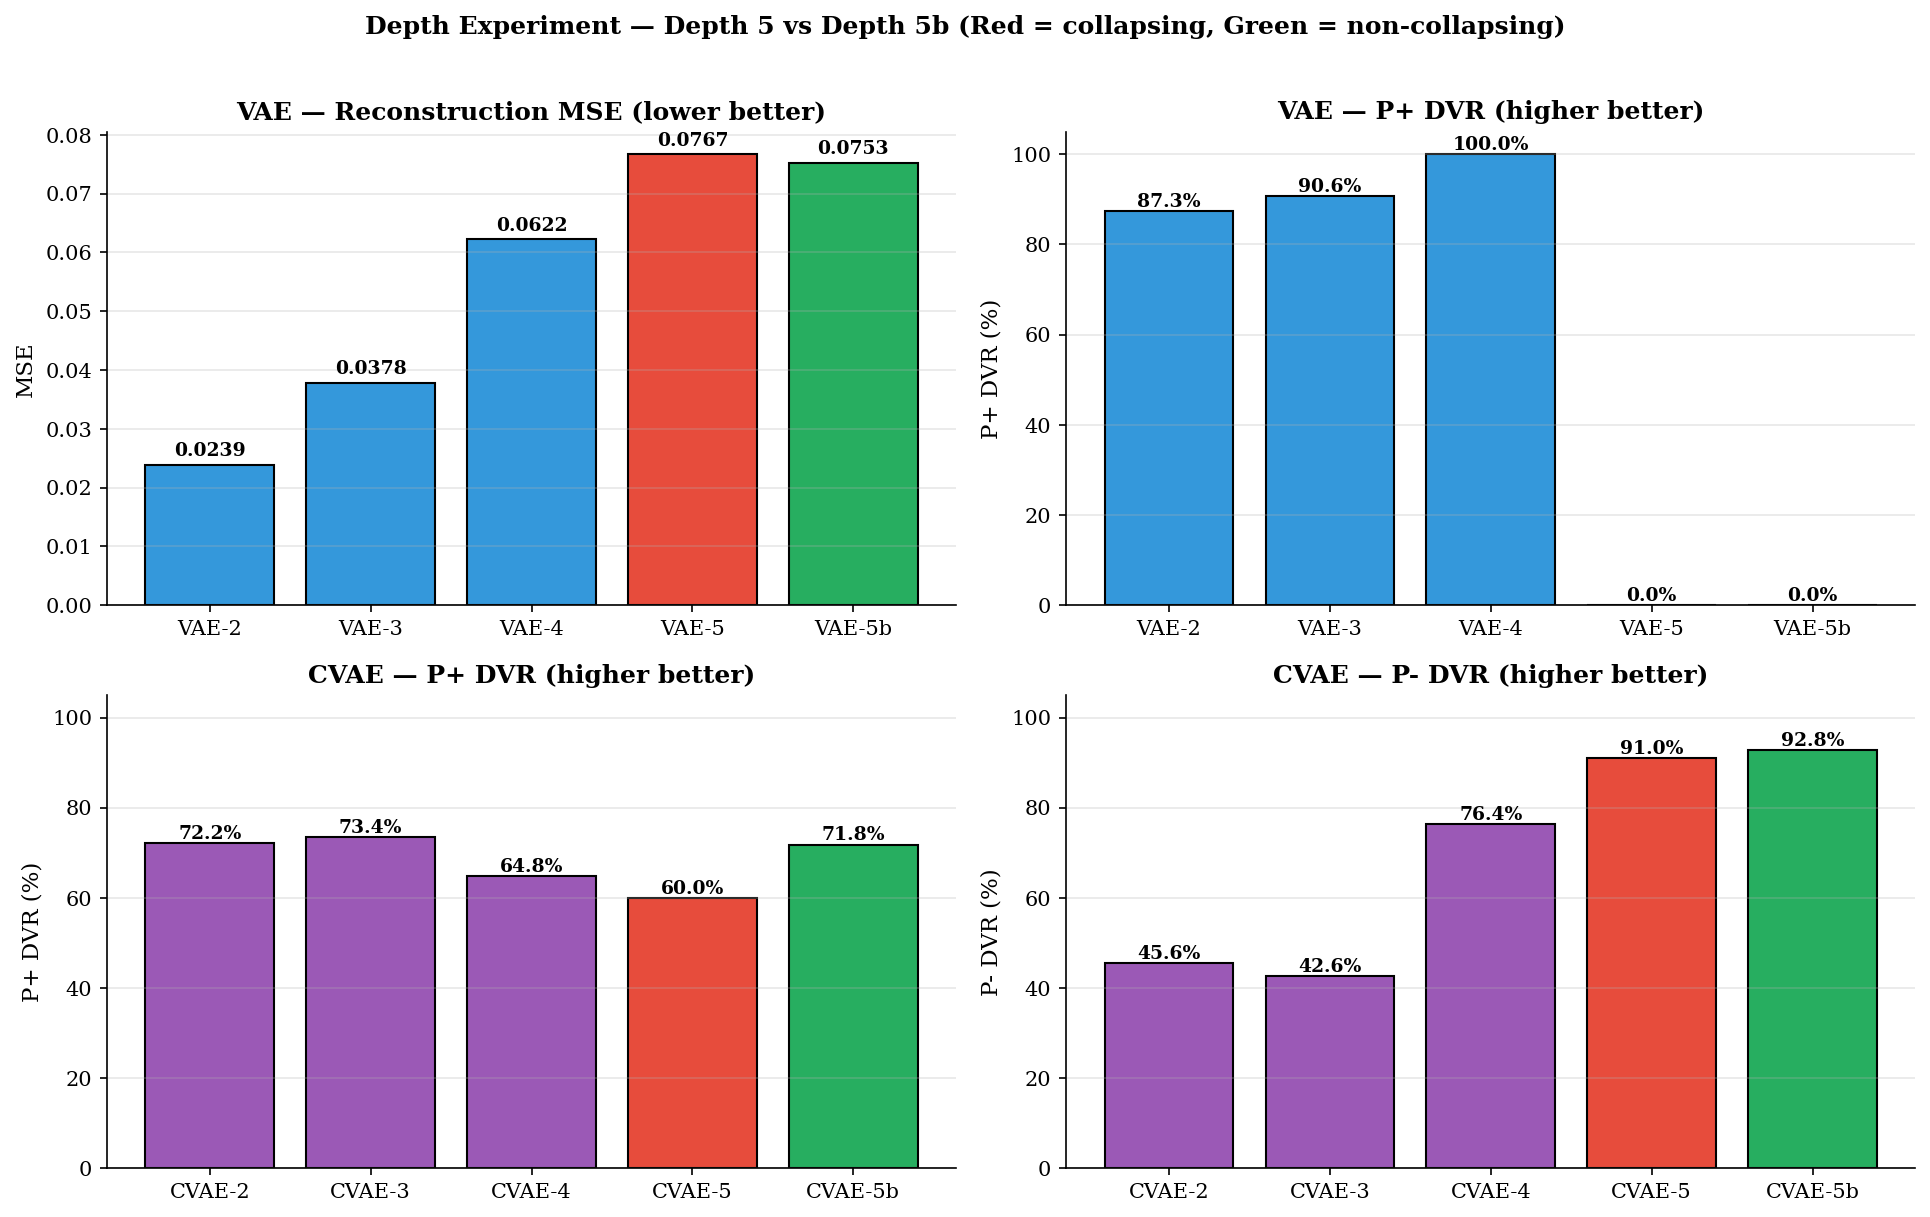

Saved -> 23_depth_5b_compare.png


In [ ]:
vae_labels = ["VAE-2", "VAE-3", "VAE-4", "VAE-5", "VAE-5b"]
vae_mses   = ([vae_mse] +
              [vae_depth_results[d]["mse"]
               for d in ["depth3", "depth4", "depth5", "depth5b"]])
vae_dvrp   = ([vae_dvr_pos*100] +
              [vae_depth_results[d]["dvr_pos"]*100
               for d in ["depth3", "depth4", "depth5", "depth5b"]])

cv2 = cvae_v2_results["lowKL+RecES"]
cvae_labels = ["CVAE-2", "CVAE-3", "CVAE-4", "CVAE-5", "CVAE-5b"]
cvae_dvrp   = ([cv2["dvr_pos"]*100] +
               [cvae_depth_results[d]["dvr_pos"]*100
                for d in ["depth3", "depth4", "depth5", "depth5b"]])
cvae_dvrn   = ([cv2["dvr_neg"]*100] +
               [cvae_depth_results[d]["dvr_neg"]*100
                for d in ["depth3", "depth4", "depth5", "depth5b"]])

# Highlight depth-5 and depth-5b with different shading to make
# the comparison visually obvious
vae_colors  = ["#3498db", "#3498db", "#3498db", "#e74c3c", "#27ae60"]
cvae_colors = ["#9b59b6", "#9b59b6", "#9b59b6", "#e74c3c", "#27ae60"]

fig, axes = plt.subplots(2, 2, figsize=(13, 8))

axes[0, 0].bar(vae_labels, vae_mses, color=vae_colors, edgecolor="black")
axes[0, 0].set_title("VAE — Reconstruction MSE (lower better)",
                     fontweight="bold")
axes[0, 0].set_ylabel("MSE"); axes[0, 0].grid(True, alpha=0.3, axis="y")
for i, v in enumerate(vae_mses):
    axes[0, 0].text(i, v + max(vae_mses)*0.02, f"{v:.4f}",
                    ha="center", fontweight="bold", fontsize=9)

axes[0, 1].bar(vae_labels, vae_dvrp, color=vae_colors, edgecolor="black")
axes[0, 1].set_title("VAE — P+ DVR (higher better)", fontweight="bold")
axes[0, 1].set_ylabel("P+ DVR (%)"); axes[0, 1].set_ylim(0, 105)
axes[0, 1].grid(True, alpha=0.3, axis="y")
for i, v in enumerate(vae_dvrp):
    axes[0, 1].text(i, v + 1, f"{v:.1f}%",
                    ha="center", fontweight="bold", fontsize=9)

axes[1, 0].bar(cvae_labels, cvae_dvrp, color=cvae_colors, edgecolor="black")
axes[1, 0].set_title("CVAE — P+ DVR (higher better)", fontweight="bold")
axes[1, 0].set_ylabel("P+ DVR (%)"); axes[1, 0].set_ylim(0, 105)
axes[1, 0].grid(True, alpha=0.3, axis="y")
for i, v in enumerate(cvae_dvrp):
    axes[1, 0].text(i, v + 1, f"{v:.1f}%",
                    ha="center", fontweight="bold", fontsize=9)

axes[1, 1].bar(cvae_labels, cvae_dvrn, color=cvae_colors, edgecolor="black")
axes[1, 1].set_title("CVAE — P- DVR (higher better)", fontweight="bold")
axes[1, 1].set_ylabel("P- DVR (%)"); axes[1, 1].set_ylim(0, 105)
axes[1, 1].grid(True, alpha=0.3, axis="y")
for i, v in enumerate(cvae_dvrn):
    axes[1, 1].text(i, v + 1, f"{v:.1f}%",
                    ha="center", fontweight="bold", fontsize=9)

plt.suptitle("Depth Experiment — Depth 5 vs Depth 5b "
             "(Red = collapsing, Green = non-collapsing)",
             fontsize=12, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig(f"{CONFIG['figures_dir']}/23_depth_5b_compare.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("Saved -> 23_depth_5b_compare.png")

## Save Updated Results

In [ ]:
depth_save = {
    "vae_baseline_depth2": {
        "hidden_dims": [256, 128],
        "n_params"   : int(n_p_vae_orig),
        "epochs"     : len(vae_history["train_loss"]),
        "mse"        : float(vae_mse),
        "acc"        : float(vae_acc),
        "f1"         : float(vae_f1),
        "dvr_pos"    : float(vae_dvr_pos),
        "dvr_neg"    : float(vae_dvr_neg),
    },
    "vae_deeper": {
        name: {
            "label"      : r["config"]["label"],
            "hidden_dims": r["config"]["hidden_dims"],
            "n_params"   : int(r["n_params"]),
            "epochs"     : int(r["epochs_run"]),
            "mse"        : float(r["mse"]),
            "acc"        : float(r["acc"]),
            "f1"         : float(r["f1"]),
            "dvr_pos"    : float(r["dvr_pos"]),
            "dvr_neg"    : float(r["dvr_neg"]),
        } for name, r in vae_depth_results.items()
    },
    "cvae_baseline_depth2_lowKLRecES": {
        "hidden_dims": [256, 128],
        "n_params"   : int(n_p_cv2),
        "epochs"     : int(cv2["epochs_run"]),
        "dvr_pos"    : float(cv2["dvr_pos"]),
        "dvr_neg"    : float(cv2["dvr_neg"]),
    },
    "cvae_deeper": {
        name: {
            "label"      : r["config"]["label"],
            "hidden_dims": r["config"]["hidden_dims"],
            "n_params"   : int(r["n_params"]),
            "epochs"     : int(r["epochs_run"]),
            "mse"        : float(r["mse"]),
            "acc"        : float(r["acc"]),
            "f1"         : float(r["f1"]),
            "dvr_pos"    : float(r["dvr_pos"]),
            "dvr_neg"    : float(r["dvr_neg"]),
        } for name, r in cvae_depth_results.items()
    },
    "training_notes": {
        "vae"  : "Original train_vae (KL anneal 0->0.5 over 50 epochs)",
        "cvae" : "train_cvae_v2 with lowKL+RecES (kl_max=0.1, "
                 "early_stop=recon)",
        "depth5_caveat": (
            "Depth 5 (collapsing) has last hidden layer == latent_dim. "
            "Depth 5b (non-collapsing) has last hidden = 24 > latent_dim. "
            "The comparison isolates the geometric-pinch effect from depth itself."
        ),
    },
    "config": {
        "dvr_sample_size": CONFIG["dvr_sample_size"],
        "dvr_ref_size"   : CONFIG["dvr_ref_size"],
        "dvr_chunk_size" : CONFIG["dvr_chunk_size"],
        "seed"           : CONFIG["seed"],
    },
}

_path = f"{CONFIG['results_dir']}/depth_experiment_results.json"
with open(_path, "w") as f:
    json.dump(depth_save, f, indent=2)
print(f"Saved -> {_path} (now includes depth 5b)")

Saved -> /content/drive/MyDrive/GenMOR/results/depth_experiment_results.json (now includes depth 5b)


## Verify Steps

In [ ]:
print("=" * 60)
print("  Depth-5b Verification")
print("=" * 60)
checks = {
    "VAE depth 5b trained"           : "depth5b" in vae_depth_results,
    "CVAE depth 5b trained"          : "depth5b" in cvae_depth_results,
    "VAE 5b checkpoint exists"       : os.path.exists(
        vae_depth_results["depth5b"]["checkpoint"]),
    "CVAE 5b checkpoint exists"      : os.path.exists(
        cvae_depth_results["depth5b"]["checkpoint"]),
    "VAE 5b DVRs in [0,1]"           : (
        0 <= vae_depth_results["depth5b"]["dvr_pos"] <= 1
        and 0 <= vae_depth_results["depth5b"]["dvr_neg"] <= 1),
    "CVAE 5b DVRs in [0,1]"          : (
        0 <= cvae_depth_results["depth5b"]["dvr_pos"] <= 1
        and 0 <= cvae_depth_results["depth5b"]["dvr_neg"] <= 1),
    "Comparison figure saved"        : os.path.exists(
        f"{CONFIG['figures_dir']}/23_depth_5b_compare.png"),
}
all_good = True
for name, status in checks.items():
    icon = "(OK)" if status else "(WARNING)"
    print(f"  {icon} {name}")
    if not status:
        all_good = False
print("=" * 60)

# Compare 5 vs 5b explicitly
v5  = vae_depth_results["depth5"]
v5b = vae_depth_results["depth5b"]
c5  = cvae_depth_results["depth5"]
c5b = cvae_depth_results["depth5b"]
v4  = vae_depth_results["depth4"]
c4  = cvae_depth_results["depth4"]

print(f"  Depth 5 vs 5b comparison:")
print(f"  VAE  5  : MSE={v5['mse']:.5f}  "
      f"P+ DVR={v5['dvr_pos']*100:>5.1f}%  "
      f"P- DVR={v5['dvr_neg']*100:>5.1f}%")
print(f"  VAE  5b : MSE={v5b['mse']:.5f}  "
      f"P+ DVR={v5b['dvr_pos']*100:>5.1f}%  "
      f"P- DVR={v5b['dvr_neg']*100:>5.1f}%")
print(f"  VAE  4  : MSE={v4['mse']:.5f}  "
      f"P+ DVR={v4['dvr_pos']*100:>5.1f}%  "
      f"P- DVR={v4['dvr_neg']*100:>5.1f}%   (best so far)")
print()
print(f"  CVAE 5  : MSE={c5['mse']:.5f}  "
      f"P+ DVR={c5['dvr_pos']*100:>5.1f}%  "
      f"P- DVR={c5['dvr_neg']*100:>5.1f}%")
print(f"  CVAE 5b : MSE={c5b['mse']:.5f}  "
      f"P+ DVR={c5b['dvr_pos']*100:>5.1f}%  "
      f"P- DVR={c5b['dvr_neg']*100:>5.1f}%")
print(f"  CVAE 4  : MSE={c4['mse']:.5f}  "
      f"P+ DVR={c4['dvr_pos']*100:>5.1f}%  "
      f"P- DVR={c4['dvr_neg']*100:>5.1f}%   (best so far)")

print("=" * 60)
if all_good:
    print("  (OK) All checks passed.")
else:
    print("  (CHECK) Fix items marked (WARNING).")

  Depth-5b Verification
  (OK) VAE depth 5b trained
  (OK) CVAE depth 5b trained
  (OK) VAE 5b checkpoint exists
  (OK) CVAE 5b checkpoint exists
  (OK) VAE 5b DVRs in [0,1]
  (OK) CVAE 5b DVRs in [0,1]
  (OK) Comparison figure saved
  Depth 5 vs 5b comparison:
  VAE  5  : MSE=0.07668  P+ DVR=  0.0%  P- DVR= 97.4%
  VAE  5b : MSE=0.07528  P+ DVR=  0.0%  P- DVR= 99.8%
  VAE  4  : MSE=0.06221  P+ DVR=100.0%  P- DVR= 83.4%   (best so far)

  CVAE 5  : MSE=0.05246  P+ DVR= 60.0%  P- DVR= 91.0%
  CVAE 5b : MSE=0.04685  P+ DVR= 71.8%  P- DVR= 92.8%
  CVAE 4  : MSE=0.03180  P+ DVR= 64.8%  P- DVR= 76.4%   (best so far)
  (OK) All checks passed.


# **NEW ADDITIONS**
# **Lower KL for VAE (to see if there is any improvements)**

# **Deeper VAE — Lower KL Fix Attempt**

*The depth experiment showed VAE depths 4 and 5 progressively degraded the classifier's ability to recognize generated samples as P+. Diagnostic check confirmed the failure mode: at depth 4 only 8/2000 generated samples were predicted P+ (depth 2 baseline: ~1000), and at depth 5 zero. The "100% P+ DVR" at depth 4 was an artifact of 8-sample evaluation, not real performance.*

*The likely cause is the same aggregate-posterior / prior mismatch issue we diagnosed for CVAE — KL pressure pulls the latent space toward N(0, I), and with more layers this pull is harder to balance against reconstruction. The fix that worked for CVAE was `lowKL+RecES`: reduce the max KL weight from 0.5 to 0.1 and switch early stopping to validation reconstruction loss. We apply the same fix to deeper VAEs here.*

*Scope: we retrain depths 4 and 5b only. Depth 3 already matched depth 2 so there's little to recover; depth 5 (collapsing hidden_dims) is structurally broken and won't be fixed by changing the KL schedule. Storing results as `vae_lowkl_results` to keep the original depth experiment intact for trend visibility.*

## Flexible VAE Training Function (mirrors train_cvae_v2)

*Identical structure to `train_cvae_v2` — configurable KL max, linear or cyclical KL schedule, optional free-bits floor, and configurable early-stopping criterion. Default behavior with `kl_max=0.5, kl_anneal_epochs=50, early_stop_on="total", free_bits=0.0` reproduces the original `train_vae` exactly.*

In [ ]:
def vae_loss_v2(x_recon, x_orig, mu, log_var,
                y_pred, y_true,
                recon_weight=1.0, kl_weight=0.5,
                class_weight=0.5, free_bits=0.0):
    """
    VAE loss with optional per-dimension free-bits floor on KL.
    free_bits = 0.0 reproduces the original vae_loss_fn behaviour.
    """
    recon_loss = nn.MSELoss()(x_recon, x_orig)
    class_loss = nn.BCELoss()(y_pred, y_true)

    kl_per_dim = -0.5 * (1 + log_var - mu.pow(2) - log_var.exp())
    kl_per_dim_batch_mean = kl_per_dim.mean(dim=0)

    if free_bits > 0.0:
        floor = torch.full_like(kl_per_dim_batch_mean, free_bits)
        kl_per_dim_batch_mean = torch.maximum(
            kl_per_dim_batch_mean, floor
        )

    kl_loss = kl_per_dim_batch_mean.mean()
    total_loss = (recon_weight * recon_loss
                  + kl_weight  * kl_loss
                  + class_weight * class_loss)
    return total_loss, recon_loss, kl_loss, class_loss


def train_vae_v2(model, optimizer, scheduler,
                 train_loader, val_loader,
                 epochs, patience, checkpoint_path,
                 kl_max=0.5,
                 kl_schedule="linear",
                 kl_anneal_epochs=50,
                 kl_n_cycles=4,
                 free_bits=0.0,
                 early_stop_on="total"):
    """
    Flexible VAE trainer mirroring train_cvae_v2.
    """
    history = {
        "train_loss":[], "val_loss":[],
        "train_recon":[], "val_recon":[],
        "train_kl":[], "val_kl":[],
        "train_cls":[], "val_cls":[],
        "kl_weight":[],
    }
    best_metric    = float("inf")
    patience_count = 0

    for epoch in range(1, epochs + 1):
        kl_w = get_kl_weight_v2(
            epoch, kl_schedule, kl_max,
            kl_anneal_epochs, kl_n_cycles, epochs)
        history["kl_weight"].append(kl_w)

        # Training
        model.train()
        t_loss = t_recon = t_kl = t_cls = 0.0
        for x_batch, y_batch in train_loader:
            x_batch = x_batch.to(device)
            y_batch = y_batch.to(device)
            optimizer.zero_grad()
            x_recon, mu, log_var, z, y_pred = model(x_batch)
            loss, recon_loss, kl_loss, class_loss = vae_loss_v2(
                x_recon, x_batch, mu, log_var,
                y_pred, y_batch,
                kl_weight=kl_w, free_bits=free_bits)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            t_loss  += loss.item()
            t_recon += recon_loss.item()
            t_kl    += kl_loss.item()
            t_cls   += class_loss.item()

        n = len(train_loader)
        t_loss/=n; t_recon/=n; t_kl/=n; t_cls/=n

        # Validation
        model.eval()
        v_loss = v_recon = v_kl = v_cls = 0.0
        with torch.no_grad():
            for x_batch, y_batch in val_loader:
                x_batch = x_batch.to(device)
                y_batch = y_batch.to(device)
                x_recon, mu, log_var, z, y_pred = model(x_batch)
                loss, recon_loss, kl_loss, class_loss = vae_loss_v2(
                    x_recon, x_batch, mu, log_var,
                    y_pred, y_batch,
                    kl_weight=kl_w, free_bits=free_bits)
                v_loss  += loss.item()
                v_recon += recon_loss.item()
                v_kl    += kl_loss.item()
                v_cls   += class_loss.item()

        nv = len(val_loader)
        v_loss/=nv; v_recon/=nv; v_kl/=nv; v_cls/=nv

        scheduler.step(v_loss)

        for key, val in zip(
            ["train_loss","val_loss","train_recon","val_recon",
             "train_kl","val_kl","train_cls","val_cls"],
            [t_loss,v_loss,t_recon,v_recon,t_kl,v_kl,t_cls,v_cls]
        ):
            history[key].append(val)

        # Early stopping criterion
        metric_now = v_recon if early_stop_on == "recon" else v_loss
        if metric_now < best_metric:
            best_metric    = metric_now
            patience_count = 0
            torch.save(model.state_dict(), checkpoint_path)
        else:
            patience_count += 1

        if epoch % 20 == 0 or epoch == 1:
            print(f"Epoch {epoch:>4}/{epochs} | "
                  f"Train: {t_loss:.5f} "
                  f"(recon={t_recon:.5f} kl={t_kl:.5f} "
                  f"cls={t_cls:.5f}) | "
                  f"Val_total: {v_loss:.5f} Val_recon: {v_recon:.5f} | "
                  f"kl_w={kl_w:.3f}")

        if patience_count >= patience:
            print(f"\n Early stopping at epoch {epoch} "
                  f"(criterion: {early_stop_on})")
            break

    print(f"\n Best {early_stop_on}-loss: {best_metric:.5f} "
          f"-> {checkpoint_path}")
    return history


print("Flexible VAE training utilities defined.")
print("  vae_loss_v2   : VAE loss + optional free-bits floor")
print("  train_vae_v2  : trainer with KL schedule and stopping knobs")

Flexible VAE training utilities defined.
  vae_loss_v2   : VAE loss + optional free-bits floor
  train_vae_v2  : trainer with KL schedule and stopping knobs


## Train VAE Depth 4 with lowKL+RecES

In [ ]:
vae_lowkl_results = {}

VAE_LOWKL_CFG = {
    "kl_max"           : 0.1,
    "kl_schedule"      : "linear",
    "kl_anneal_epochs" : 50,
    "free_bits"        : 0.0,
    "early_stop_on"    : "recon",
}

for variant_name in ["depth4", "depth5b"]:
    cfg = DEPTH_VARIANTS[variant_name]
    print("\n" + "=" * 70)
    print(f"  Training VAE  {cfg['label']}  with lowKL+RecES")
    print(f"  hidden_dims = {cfg['hidden_dims']}")
    print(f"  Schedule    : kl_max=0.1, early_stop=recon")
    print("=" * 70)

    set_seed(CONFIG["seed"])
    model = VAE(
        input_dim   = CONFIG["input_dim"],
        hidden_dims = cfg["hidden_dims"],
        latent_dim  = CONFIG["latent_dim"],
    ).to(device)
    opt = optim.Adam(model.parameters(),
                     lr=CONFIG["learning_rate"], weight_decay=1e-5)
    sch = optim.lr_scheduler.ReduceLROnPlateau(
        opt, mode="min", factor=0.5, patience=10)
    ckpt = f"{CONFIG['checkpoint_dir']}/vae_lowkl_{variant_name}.pt"

    hist = train_vae_v2(
        model           = model,
        optimizer       = opt,
        scheduler       = sch,
        train_loader    = train_loader,
        val_loader      = val_loader,
        epochs          = CONFIG["epochs"],
        patience        = CONFIG["early_stop_patience"],
        checkpoint_path = ckpt,
        **VAE_LOWKL_CFG,
    )

    model.load_state_dict(torch.load(ckpt, map_location=device))
    model.eval()

    vae_lowkl_results[variant_name] = {
        "model"     : model,
        "history"   : hist,
        "checkpoint": ckpt,
        "config"    : cfg,
        "n_params"  : count_params(model),
        "epochs_run": len(hist["train_loss"]),
    }
    print(f"\nVAE {variant_name} lowKL trained — "
          f"epochs={len(hist['train_loss'])}, "
          f"params={count_params(model):,d}")

print("\n VAE lowKL depth variants trained:")
for n, r in vae_lowkl_results.items():
    print(f"  {r['config']['label']:<28s}  "
          f"params={r['n_params']:>8,d}  "
          f"epochs={r['epochs_run']:>3d}")


  Training VAE  +2 layers (depth 4)  with lowKL+RecES
  hidden_dims = [256, 128, 64, 32]
  Schedule    : kl_max=0.1, early_stop=recon
Epoch    1/200 | Train: 0.28668 (recon=0.08131 kl=0.80982 cls=0.40751) | Val_total: 0.24073 Val_recon: 0.07453 | kl_w=0.002
Epoch   20/200 | Train: 0.14065 (recon=0.05028 kl=0.81029 cls=0.11591) | Val_total: 0.30758 Val_recon: 0.04181 | kl_w=0.040

 Early stopping at epoch 30 (criterion: recon)

 Best recon-loss: 0.04042 -> /content/drive/MyDrive/GenMOR/checkpoints/vae_lowkl_depth4.pt

VAE depth4 lowKL trained — epochs=30, params=101,301

  Training VAE  +3 layers (depth 5b, non-collapsing)  with lowKL+RecES
  hidden_dims = [256, 128, 64, 32, 24]
  Schedule    : kl_max=0.1, early_stop=recon
Epoch    1/200 | Train: 0.29767 (recon=0.08269 kl=0.74043 cls=0.42701) | Val_total: 0.24419 Val_recon: 0.07945 | kl_w=0.002
Epoch   20/200 | Train: 0.14575 (recon=0.06609 kl=0.56433 cls=0.11417) | Val_total: 0.32077 Val_recon: 0.06157 | kl_w=0.040

 Early stopping at

## Evaluate lowKL Variants

*Same evaluation protocol used for the original depth experiment: test-set MSE/acc/F1, then DVR via 2000 N(0, I) samples split by classifier. The classifier-predicted-P+/P- counts are reported alongside — that's the diagnostic that exposed the depth-4 artifact last time, and the most important thing to look at here.*

In [ ]:
np.random.seed(CONFIG["seed"])
torch.manual_seed(CONFIG["seed"])

for variant_name, r in vae_lowkl_results.items():
    model = r["model"]
    model.eval()

    # Test-set MSE + classification
    xs, xrs, yts, yps = [], [], [], []
    with torch.no_grad():
        for x_batch, y_batch in test_loader:
            x_batch = x_batch.to(device)
            x_recon, mu, log_var, z, y_p = model(x_batch)
            xs.append(x_batch.cpu().numpy())
            xrs.append(x_recon.cpu().numpy())
            yts.append(y_batch.numpy())
            yps.append(y_p.cpu().numpy())
    xs  = np.concatenate(xs);  xrs = np.concatenate(xrs)
    yts = np.concatenate(yts); yps = np.concatenate(yps)

    r["mse"] = float(np.mean((xs - xrs) ** 2))
    r["acc"] = float(accuracy_score(yts, (yps >= 0.5).astype(int)))
    r["f1"]  = float(f1_score(yts, (yps >= 0.5).astype(int),
                              average="weighted"))

    # DVR via N(0,I) generation + classifier split
    gen_scaled, _ = model.generate(2000, device)
    with torch.no_grad():
        gt = torch.tensor(gen_scaled, dtype=torch.float32).to(device)
        _, _, _, _, gyp = model(gt)
        gyb = (gyp.cpu().numpy() >= 0.5).astype(int)

    gen_orig = np.clip(scaler.inverse_transform(gen_scaled), 1, 100)
    gen_pos  = gen_orig[gyb == 1]
    gen_neg  = gen_orig[gyb == 0]
    r["n_gen_pos"] = int(len(gen_pos))
    r["n_gen_neg"] = int(len(gen_neg))

    if len(gen_pos) > 0:
        r["dvr_pos"], r["vp"], r["np"] = compute_dvr_chunked(
            gen_pos, X_sel_full, selected_indices,
            target="positive",
            sample_size = CONFIG["dvr_sample_size"],
            ref_size    = CONFIG["dvr_ref_size"],
            chunk_size  = CONFIG["dvr_chunk_size"],
            seed        = CONFIG["seed"])
    else:
        r["dvr_pos"], r["vp"], r["np"] = 0.0, 0, 0

    if len(gen_neg) > 0:
        r["dvr_neg"], r["vn"], r["nn"] = compute_dvr_chunked(
            gen_neg, X_sel_full, selected_indices,
            target="negative",
            sample_size = CONFIG["dvr_sample_size"],
            ref_size    = CONFIG["dvr_ref_size"],
            chunk_size  = CONFIG["dvr_chunk_size"],
            seed        = CONFIG["seed"])
    else:
        r["dvr_neg"], r["vn"], r["nn"] = 0.0, 0, 0

    # Flag small-sample DVR results
    p_warn = " (SMALL SAMPLE)" if r["n_gen_pos"] < 50 else ""
    n_warn = " (SMALL SAMPLE)" if r["n_gen_neg"] < 50 else ""

    print(f"VAE {variant_name} (lowKL)  "
          f"MSE={r['mse']:.5f}  Acc={r['acc']*100:.1f}%  "
          f"F1={r['f1']:.3f}")
    print(f"  Classifier split: {r['n_gen_pos']} predicted P+, "
          f"{r['n_gen_neg']} predicted P-")
    print(f"  P+ DVR: {r['dvr_pos']*100:.1f}% "
          f"on {r['np']} samples{p_warn}")
    print(f"  P- DVR: {r['dvr_neg']*100:.1f}% "
          f"on {r['nn']} samples{n_warn}")

VAE depth4 (lowKL)  MSE=0.04020  Acc=85.4%  F1=0.854
  Classifier split: 168 predicted P+, 1832 predicted P-
  P+ DVR: 86.3% on 168 samples
  P- DVR: 49.2% on 500 samples
VAE depth5b (lowKL)  MSE=0.06096  Acc=84.8%  F1=0.848
  Classifier split: 75 predicted P+, 1925 predicted P-
  P+ DVR: 88.0% on 75 samples
  P- DVR: 70.8% on 500 samples


## Comparison — Original vs lowKL for Each Depth

*Side-by-side comparison so you can see whether lowKL recovered the deeper VAEs. The key check is the predicted-P+ count: if it's still near zero, the KL fix didn't address the underlying issue (collapse is structural, not training-driven). If it's now in the hundreds, the KL pressure was the problem and the fix worked.*

In [ ]:
print("=" * 100)
print("  Deeper VAE — Original Training vs lowKL+RecES")
print("=" * 100)
print(f"  {'Variant':<28s} {'Pred P+':>9s} {'Pred P-':>9s} "
      f"{'MSE':>9s} {'P+ DVR':>9s} {'P- DVR':>9s} {'P+ n':>8s}")
print("-" * 100)

# Baseline references
print(f"  {'VAE depth 2 (orig train)':<28s} "
      f"{'~1000':>9s} {'~1000':>9s} "
      f"{vae_mse:>9.5f} {vae_dvr_pos*100:>8.1f}% "
      f"{vae_dvr_neg*100:>8.1f}% {'~500':>8s}")
print()

for variant_name in ["depth4", "depth5b"]:
    r_orig = vae_depth_results[variant_name]
    r_lowkl = vae_lowkl_results[variant_name]

    print(f"  {'VAE '+variant_name+' (orig train)':<28s} "
          f"{r_orig.get('n_gen_pos', '?'):>9} "
          f"{r_orig.get('n_gen_neg', '?'):>9} "
          f"{r_orig['mse']:>9.5f} "
          f"{r_orig['dvr_pos']*100:>8.1f}% "
          f"{r_orig['dvr_neg']*100:>8.1f}% "
          f"{r_orig.get('np', '?'):>8}")

    print(f"  {'VAE '+variant_name+' (lowKL+RecES)':<28s} "
          f"{r_lowkl['n_gen_pos']:>9d} "
          f"{r_lowkl['n_gen_neg']:>9d} "
          f"{r_lowkl['mse']:>9.5f} "
          f"{r_lowkl['dvr_pos']*100:>8.1f}% "
          f"{r_lowkl['dvr_neg']*100:>8.1f}% "
          f"{r_lowkl['np']:>8d}")
    print()

print("=" * 100)
print("  Verdict heuristics:")
print("    Pred P+ count > 200    : classifier sees generated samples "
      "as plausibly P+ — lowKL helped recover the generation pathway")
print("    Pred P+ count 50-200   : partial recovery — DVR is "
      "borderline meaningful")
print("    Pred P+ count < 50     : lowKL did not fix the issue — "
      "DVR is still a small-sample artifact")

  Deeper VAE — Original Training vs lowKL+RecES
  Variant                        Pred P+   Pred P-       MSE    P+ DVR    P- DVR     P+ n
----------------------------------------------------------------------------------------------------
  VAE depth 2 (orig train)         ~1000     ~1000   0.02387     87.3%     46.0%     ~500

  VAE depth4 (orig train)              8      1992   0.06221    100.0%     83.4%        8
  VAE depth4 (lowKL+RecES)           168      1832   0.04020     86.3%     49.2%      168

  VAE depth5b (orig train)             0      2000   0.07528      0.0%     99.8%        0
  VAE depth5b (lowKL+RecES)           75      1925   0.06096     88.0%     70.8%       75

  Verdict heuristics:
    Pred P+ count > 200    : classifier sees generated samples as plausibly P+ — lowKL helped recover the generation pathway
    Pred P+ count 50-200   : partial recovery — DVR is borderline meaningful
    Pred P+ count < 50     : lowKL did not fix the issue — DVR is still a small-samp

## Training Curves Comparison

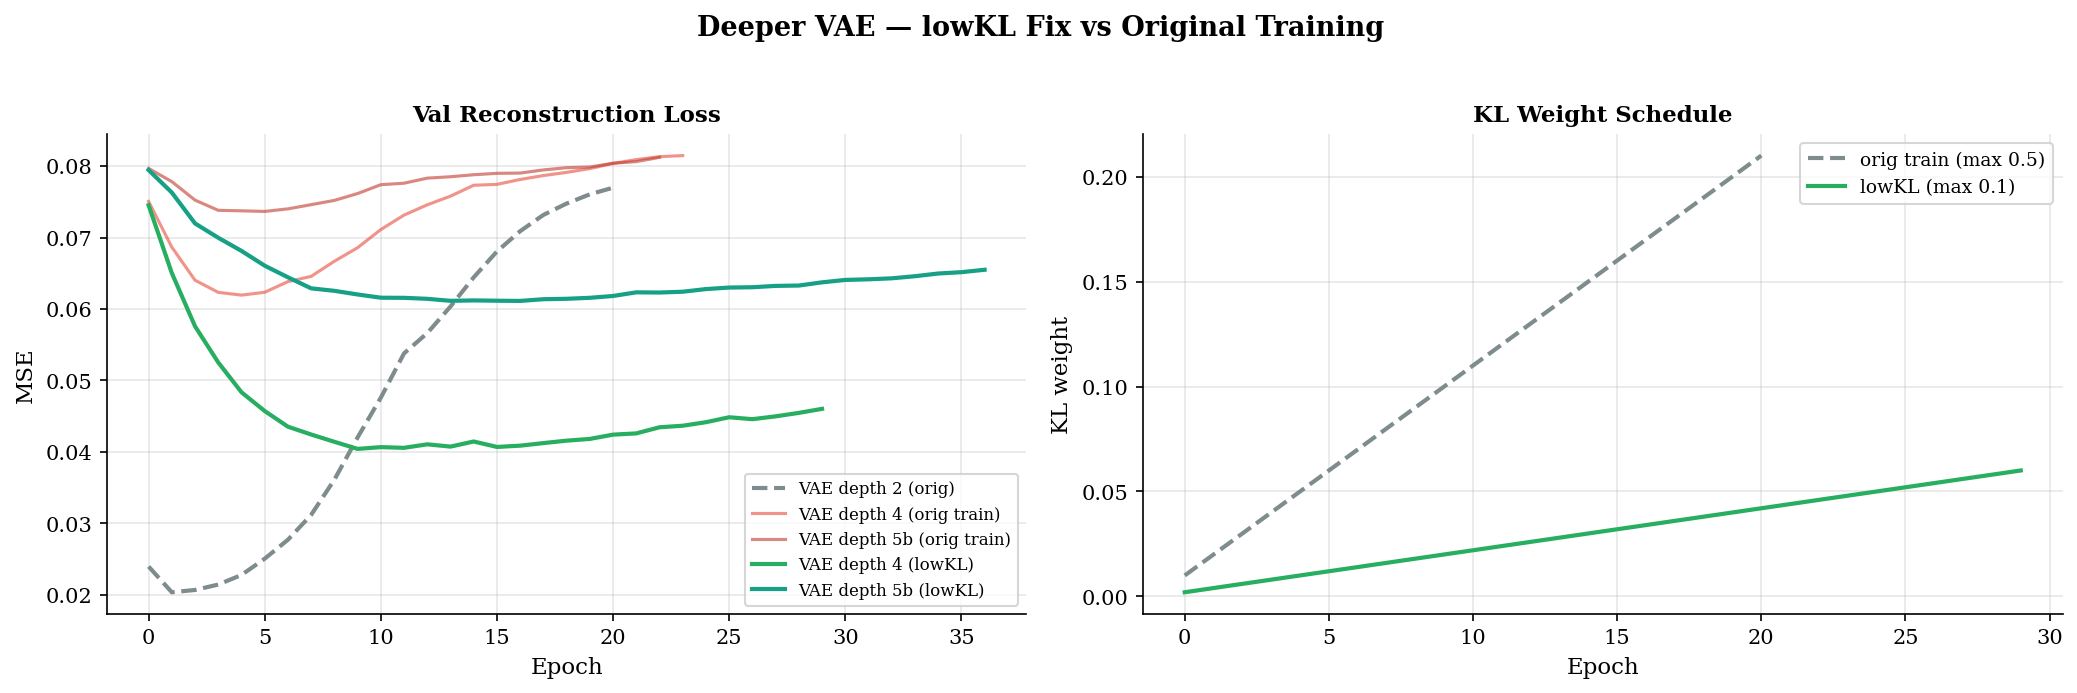

Saved -> 24_vae_lowkl_curves.png


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Reconstruction loss
axes[0].plot(vae_history["val_recon"], label="VAE depth 2 (orig)",
             color="#7f8c8d", linewidth=2, linestyle="--")
axes[0].plot(vae_depth_results["depth4"]["history"]["val_recon"],
             label="VAE depth 4 (orig train)",
             color="#e74c3c", linewidth=1.5, alpha=0.6)
axes[0].plot(vae_depth_results["depth5b"]["history"]["val_recon"],
             label="VAE depth 5b (orig train)",
             color="#c0392b", linewidth=1.5, alpha=0.6)
axes[0].plot(vae_lowkl_results["depth4"]["history"]["val_recon"],
             label="VAE depth 4 (lowKL)",
             color="#27ae60", linewidth=2)
axes[0].plot(vae_lowkl_results["depth5b"]["history"]["val_recon"],
             label="VAE depth 5b (lowKL)",
             color="#16a085", linewidth=2)
axes[0].set_title("Val Reconstruction Loss",
                  fontweight="bold", fontsize=11)
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("MSE")
axes[0].legend(fontsize=8); axes[0].grid(True, alpha=0.3)

# KL weight schedules (just the lowKL runs vs originals)
axes[1].plot(vae_history.get("kl_weight", []),
             label="orig train (max 0.5)",
             color="#7f8c8d", linewidth=2, linestyle="--")
axes[1].plot(vae_lowkl_results["depth4"]["history"]["kl_weight"],
             label="lowKL (max 0.1)",
             color="#27ae60", linewidth=2)
axes[1].set_title("KL Weight Schedule",
                  fontweight="bold", fontsize=11)
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("KL weight")
axes[1].legend(fontsize=9); axes[1].grid(True, alpha=0.3)

plt.suptitle("Deeper VAE — lowKL Fix vs Original Training",
             fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(f"{CONFIG['figures_dir']}/24_vae_lowkl_curves.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("Saved -> 24_vae_lowkl_curves.png")

## Save Results

In [ ]:
vae_lowkl_save = {
    "schedule": {
        "kl_max"           : VAE_LOWKL_CFG["kl_max"],
        "kl_schedule"      : VAE_LOWKL_CFG["kl_schedule"],
        "kl_anneal_epochs" : VAE_LOWKL_CFG["kl_anneal_epochs"],
        "early_stop_on"    : VAE_LOWKL_CFG["early_stop_on"],
        "free_bits"        : VAE_LOWKL_CFG["free_bits"],
    },
    "variants": {
        name: {
            "label"      : r["config"]["label"],
            "hidden_dims": r["config"]["hidden_dims"],
            "n_params"   : int(r["n_params"]),
            "epochs"     : int(r["epochs_run"]),
            "mse"        : float(r["mse"]),
            "acc"        : float(r["acc"]),
            "f1"         : float(r["f1"]),
            "dvr_pos"    : float(r["dvr_pos"]),
            "dvr_neg"    : float(r["dvr_neg"]),
            "n_gen_pos"  : int(r["n_gen_pos"]),
            "n_gen_neg"  : int(r["n_gen_neg"]),
            "eval_pos_n" : int(r["np"]),
            "eval_neg_n" : int(r["nn"]),
            "checkpoint" : r["checkpoint"],
        } for name, r in vae_lowkl_results.items()
    },
    "rationale": (
        "Applied lowKL+RecES (the CVAE fix) to deeper VAEs to test "
        "whether classifier collapse on generated samples was driven by "
        "the KL schedule rather than depth itself. Depth 3 not retrained "
        "(already comparable to depth 2). Depth 5 with collapsing "
        "hidden_dims not retrained (structurally broken regardless of "
        "schedule)."
    ),
}

_path = f"{CONFIG['results_dir']}/vae_lowkl_results.json"
with open(_path, "w") as f:
    json.dump(vae_lowkl_save, f, indent=2)
print(f"Saved -> {_path}")

Saved -> /content/drive/MyDrive/GenMOR/results/vae_lowkl_results.json


## Verify Steps

In [ ]:
print("=" * 60)
print("  VAE lowKL Verification")
print("=" * 60)
checks = {
    "Both lowKL variants trained"  : len(vae_lowkl_results) == 2,
    "Checkpoints exist"            : all(
        os.path.exists(r["checkpoint"])
        for r in vae_lowkl_results.values()),
    "DVRs in [0, 1]"               : all(
        0.0 <= r["dvr_pos"] <= 1.0
        and 0.0 <= r["dvr_neg"] <= 1.0
        for r in vae_lowkl_results.values()),
    "Curves figure saved"          : os.path.exists(
        f"{CONFIG['figures_dir']}/24_vae_lowkl_curves.png"),
    "Results JSON saved"           : os.path.exists(
        f"{CONFIG['results_dir']}/vae_lowkl_results.json"),
}
all_good = True
for name, status in checks.items():
    icon = "(OK)" if status else "(WARNING)"
    print(f"  {icon} {name}")
    if not status:
        all_good = False
print("=" * 60)

# Final verdict
print(f"  Recovery check:")
for name, r in vae_lowkl_results.items():
    r_orig = vae_depth_results[name]
    n_pos_orig  = r_orig.get("n_gen_pos", 0)
    n_pos_lowkl = r["n_gen_pos"]
    delta = n_pos_lowkl - n_pos_orig

    if n_pos_lowkl >= 200:
        verdict = "FIXED — predicted P+ now in healthy range"
    elif n_pos_lowkl >= 50:
        verdict = "PARTIAL — DVR borderline meaningful"
    else:
        verdict = "NOT FIXED — issue is structural, not training-driven"

    print(f"  {name}: pred P+ {n_pos_orig} -> {n_pos_lowkl} "
          f"(delta {delta:+d})  --  {verdict}")
print("=" * 60)
if all_good:
    print("  (OK) All structural checks passed.")
else:
    print("  (CHECK) Fix items marked (WARNING).")

  VAE lowKL Verification
  (OK) Both lowKL variants trained
  (OK) Checkpoints exist
  (OK) DVRs in [0, 1]
  (OK) Curves figure saved
  (OK) Results JSON saved
  Recovery check:
  depth4: pred P+ 8 -> 168 (delta +160)  --  PARTIAL — DVR borderline meaningful
  depth5b: pred P+ 0 -> 75 (delta +75)  --  PARTIAL — DVR borderline meaningful
  (OK) All structural checks passed.


# NEW ADDITIONS

# **Random Baseline Experiment — Null Model for Nondomination**

*If we generate plan value vectors completely at random — each component drawn from a uniform distribution over the allowed range, with no model involved — what fraction are nondominated? This establishes the **null-model baseline**: the base rate of nondomination under pure chance. Every generative model (AE, VAE, CVAE) must beat this baseline to be doing anything beyond random guessing.*

*Method: generate 1000 plan vectors. Each vector has 20 components (matching the dataset's 20 objectives). Each component is drawn independently from Uniform[1, 100] — the actual allowed range in this project (the professor's example said 0-100; our data is clipped to [1, 100], so we use [1, 100] to match the real reference pool exactly). We then measure what fraction of these 1000 random vectors are nondominated against the same 10K real-plan reference pool used for all DVR computations, checking dominance on the same 12 selected objectives. Finally we compare this base rate to the CVAE's nondominated rate (its P+ DVR).*

## Confirm the Value Range

*We confirm the per-objective min/max of the real data, uses a single global range [1, 100] for all components, which we use as the primary method. We also record the per-objective observed ranges so we can run a secondary, more conservative null model that samples within each objective's actual observed range (a stronger baseline, since real objectives may not all span the full [1, 100]).*

In [ ]:
# Per-objective observed ranges in the real data (original scale)
obj_min = X_orig_full.min(axis=0)   # (20,)
obj_max = X_orig_full.max(axis=0)   # (20,)

print("=" * 60)
print("  Value Range Confirmation")
print("=" * 60)
print(f"  Global min across all objectives : {X_orig_full.min():.2f}")
print(f"  Global max across all objectives : {X_orig_full.max():.2f}")
print(f"  Number of objectives (components): {X_orig_full.shape[1]}")
print(f"  Dominance checked on {len(selected_indices)} selected objectives")
print()
print("  Per-objective ranges (first 6 shown):")
for i in range(min(6, X_orig_full.shape[1])):
    tag = " [selected]" if i in selected_indices else ""
    print(f"    Objective {i:>2d}: [{obj_min[i]:.2f}, {obj_max[i]:.2f}]{tag}")
print("=" * 60)
print(f"  Primary method: Uniform[1, 100] for all components")

  Value Range Confirmation
  Global min across all objectives : 1.00
  Global max across all objectives : 100.00
  Number of objectives (components): 20
  Dominance checked on 12 selected objectives

  Per-objective ranges (first 6 shown):
    Objective  0: [1.00, 100.00] [selected]
    Objective  1: [1.00, 100.00] [selected]
    Objective  2: [1.00, 100.00] [selected]
    Objective  3: [1.00, 100.00] [selected]
    Objective  4: [1.00, 100.00]
    Objective  5: [1.00, 100.00]
  Primary method: Uniform[1, 100] for all components


## Primary Experiment — 1000 Random Uniform[1, 100] Plans

*Generate exactly 1000 random plans as the, each component Uniform[1, 100], then measure the nondominated rate. We also compute the dominated rate as a consistency check — the two should sum to approximately 1.0 (every plan is either dominated or not, modulo the reference-pool sampling).*

In [ ]:
RANDOM_SEED = CONFIG["seed"]
N_RANDOM    = 1000

rng = np.random.RandomState(RANDOM_SEED)
random_plans = rng.uniform(low=1.0, high=100.0,
                           size=(N_RANDOM, X_orig_full.shape[1]))

# Nondominated rate (target="positive")
rand_nondom_rate, rand_nd_valid, rand_nd_n = compute_dvr_chunked(
    random_plans, X_sel_full, selected_indices,
    target      = "positive",
    sample_size = N_RANDOM,
    ref_size    = CONFIG["dvr_ref_size"],
    chunk_size  = CONFIG["dvr_chunk_size"],
    seed        = RANDOM_SEED)

# Dominated rate (target="negative") — consistency check
rand_dom_rate, rand_d_valid, rand_d_n = compute_dvr_chunked(
    random_plans, X_sel_full, selected_indices,
    target      = "negative",
    sample_size = N_RANDOM,
    ref_size    = CONFIG["dvr_ref_size"],
    chunk_size  = CONFIG["dvr_chunk_size"],
    seed        = RANDOM_SEED)

print("=" * 60)
print(f"  Random Baseline — {N_RANDOM} Uniform[1,100] plans")
print("=" * 60)
print(f"  Nondominated rate : {rand_nondom_rate*100:.1f}%  "
      f"({rand_nd_valid}/{rand_nd_n})")
print(f"  Dominated rate    : {rand_dom_rate*100:.1f}%  "
      f"({rand_d_valid}/{rand_d_n})")
print(f"  Sum (should ~100%): {(rand_nondom_rate + rand_dom_rate)*100:.1f}%")
print("=" * 60)
print(f"  Interpretation: a randomly generated plan has a "
      f"{rand_nondom_rate*100:.1f}% chance")
print(f"  of being nondominated against the real-plan reference pool.")

  Random Baseline — 1000 Uniform[1,100] plans
  Nondominated rate : 69.2%  (692/1000)
  Dominated rate    : 30.8%  (308/1000)
  Sum (should ~100%): 100.0%
  Interpretation: a randomly generated plan has a 69.2% chance
  of being nondominated against the real-plan reference pool.


## Robustness — Multiple Seeds

*A single draw of 1000 plans has sampling noise. We repeat the experiment across 10 independent seeds (each a fresh 1000-plan draw) and report the mean and standard deviation of the nondominated rate. This gives a confidence range around the base rate rather than a single point estimate.*

In [ ]:
n_seeds = 10
nondom_rates = []

for s in range(n_seeds):
    rng_s = np.random.RandomState(1000 + s)
    rp = rng_s.uniform(low=1.0, high=100.0,
                       size=(N_RANDOM, X_orig_full.shape[1]))
    rate, _, _ = compute_dvr_chunked(
        rp, X_sel_full, selected_indices,
        target      = "positive",
        sample_size = N_RANDOM,
        ref_size    = CONFIG["dvr_ref_size"],
        chunk_size  = CONFIG["dvr_chunk_size"],
        seed        = 1000 + s)
    nondom_rates.append(rate)
    print(f"  Seed {1000+s}: {rate*100:.1f}% nondominated")

nondom_rates = np.array(nondom_rates)
rand_mean = float(nondom_rates.mean())
rand_std  = float(nondom_rates.std())

print("=" * 60)
print(f"  Random nondominated rate over {n_seeds} seeds:")
print(f"    Mean : {rand_mean*100:.1f}%")
print(f"    Std  : {rand_std*100:.1f}%")
print(f"    Range: [{nondom_rates.min()*100:.1f}%, "
      f"{nondom_rates.max()*100:.1f}%]")
print("=" * 60)

  Seed 1000: 65.9% nondominated
  Seed 1001: 69.1% nondominated
  Seed 1002: 67.9% nondominated
  Seed 1003: 71.5% nondominated
  Seed 1004: 67.7% nondominated
  Seed 1005: 71.4% nondominated
  Seed 1006: 72.6% nondominated
  Seed 1007: 67.5% nondominated
  Seed 1008: 70.5% nondominated
  Seed 1009: 67.0% nondominated
  Random nondominated rate over 10 seeds:
    Mean : 69.1%
    Std  : 2.1%
    Range: [65.9%, 72.6%]


## Secondary (Stronger) Baseline — Per-Objective Observed Ranges

*A more conservative null model: instead of Uniform[1, 100] globally, sample each component from Uniform[min_i, max_i] using that objective's actual observed range in the real data. This produces random plans that are more "realistic" per-objective, making it a harder baseline to beat. If real objectives all span close to [1, 100], this will match the primary result; if some objectives have narrower ranges, this baseline may differ.*

In [ ]:
rng = np.random.RandomState(RANDOM_SEED)
random_plans_perobj = rng.uniform(
    low  = obj_min,
    high = obj_max,
    size = (N_RANDOM, X_orig_full.shape[1]))

perobj_nondom_rate, perobj_valid, perobj_n = compute_dvr_chunked(
    random_plans_perobj, X_sel_full, selected_indices,
    target      = "positive",
    sample_size = N_RANDOM,
    ref_size    = CONFIG["dvr_ref_size"],
    chunk_size  = CONFIG["dvr_chunk_size"],
    seed        = RANDOM_SEED)

print("=" * 60)
print(f"  Per-Objective-Range Random Baseline")
print("=" * 60)
print(f"  Nondominated rate : {perobj_nondom_rate*100:.1f}%  "
      f"({perobj_valid}/{perobj_n})")
print(f"  (vs global Uniform[1,100]: {rand_nondom_rate*100:.1f}%)")
print("=" * 60)

  Per-Objective-Range Random Baseline
  Nondominated rate : 69.2%  (692/1000)
  (vs global Uniform[1,100]: 69.2%)


## Comparison — Random Baseline vs Generative Models

*We contrast the random nondominated rate against the CVAE's P+ DVR (its nondominated rate for P+-conditioned generation) and, for context, the other models. The "lift over random" column shows how many times more likely each model is to produce a nondominated plan compared to pure chance.*

In [ ]:
# Gather model P+ DVRs defensively (only those in scope)
model_rates = [("Random Uniform[1,100]", rand_mean)]

if "cvae_dvr_pos" in dir():
    model_rates.append(("CVAE-orig", cvae_dvr_pos))
if "cvae_v2_results" in dir() and "lowKL+RecES" in cvae_v2_results:
    model_rates.append(("CVAE-lowKL+RecES",
                        cvae_v2_results["lowKL+RecES"]["dvr_pos"]))
if "vae_dvr_pos" in dir():
    model_rates.append(("VAE", vae_dvr_pos))
if "ae_dvr_pos_u" in dir():
    model_rates.append(("AE-Unc", ae_dvr_pos_u))
if "ae_dvr_pos_c" in dir():
    model_rates.append(("AE-Con", ae_dvr_pos_c))
if "ae_dvr_pos_g" in dir():
    model_rates.append(("AE-GMM", ae_dvr_pos_g))

print("=" * 70)
print("  Nondominated Rate — Random Baseline vs Models")
print("=" * 70)
print(f"  {'Method':<26s} {'Nondom Rate':>13s} {'Lift over Random':>18s}")
print("-" * 70)
for name, rate in model_rates:
    lift = rate / rand_mean if rand_mean > 0 else float("inf")
    lift_s = f"{lift:.2f}x" if name != "Random Uniform[1,100]" else "(baseline)"
    print(f"  {name:<26s} {rate*100:>12.1f}% {lift_s:>18s}")
print("=" * 70)
print(f"  Random baseline = {rand_mean*100:.1f}% +/- {rand_std*100:.1f}% "
      f"(mean over {n_seeds} seeds)")
print(f"  Lift = model nondominated rate / random nondominated rate")

  Nondominated Rate — Random Baseline vs Models
  Method                       Nondom Rate   Lift over Random
----------------------------------------------------------------------
  Random Uniform[1,100]              69.1%         (baseline)
  CVAE-orig                          70.2%              1.02x
  CVAE-lowKL+RecES                   72.2%              1.04x
  VAE                                87.3%              1.26x
  AE-Unc                             90.6%              1.31x
  AE-Con                             86.6%              1.25x
  AE-GMM                             89.4%              1.29x
  Random baseline = 69.1% +/- 2.1% (mean over 10 seeds)
  Lift = model nondominated rate / random nondominated rate


## Bar Chart

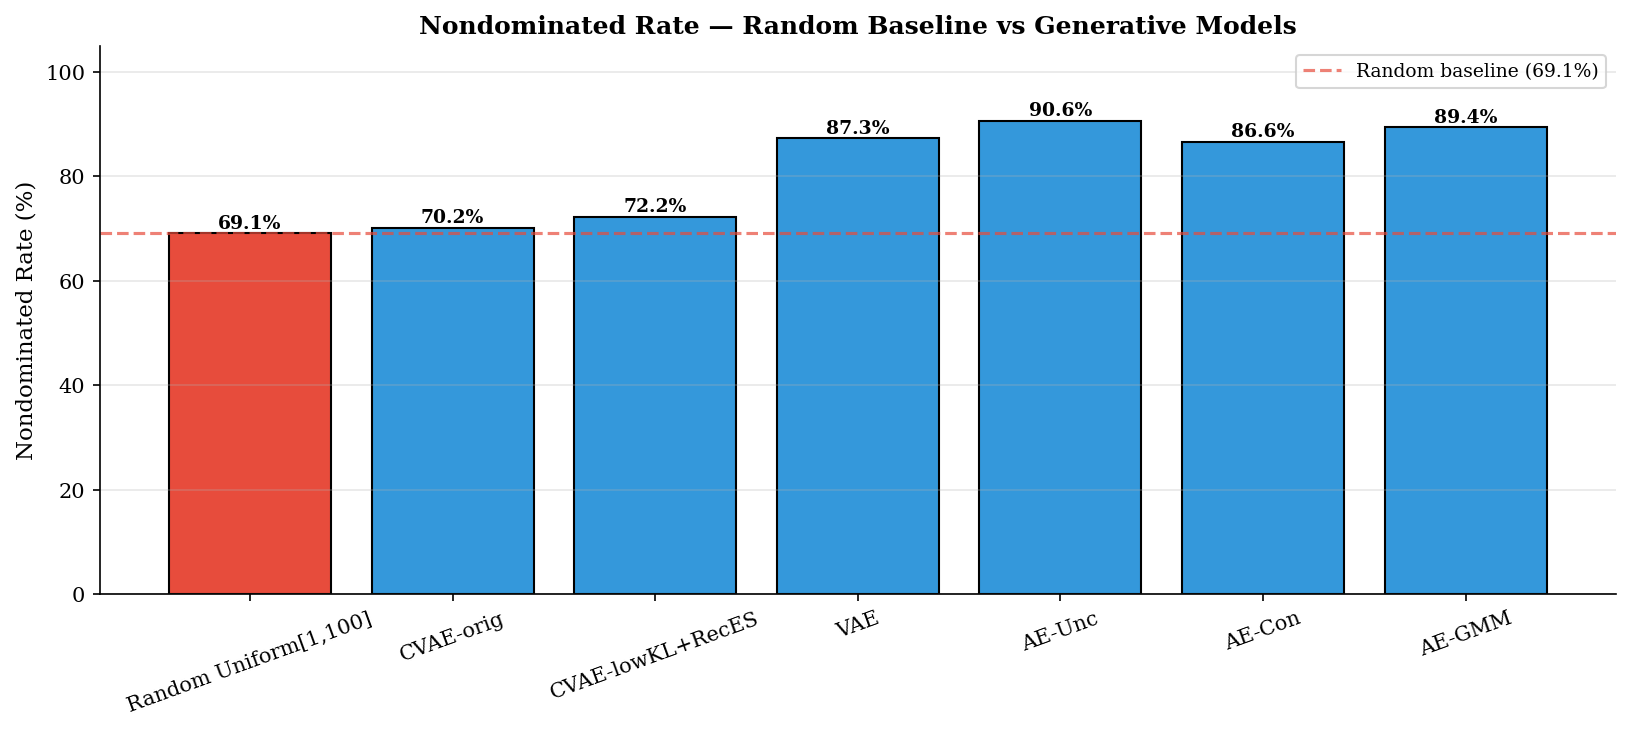

Saved -> 25_random_baseline.png


In [ ]:
names  = [m[0] for m in model_rates]
rates  = [m[1]*100 for m in model_rates]
colors = (["#e74c3c"] +   # random = red
          ["#3498db"] * (len(names) - 1))

fig, ax = plt.subplots(figsize=(11, 5))
bars = ax.bar(names, rates, color=colors, edgecolor="black")
for b, v in zip(bars, rates):
    ax.text(b.get_x() + b.get_width()/2, v + 1, f"{v:.1f}%",
            ha="center", fontweight="bold", fontsize=9)

# Random baseline reference line
ax.axhline(rand_mean*100, color="#e74c3c", linestyle="--",
           linewidth=1.5, alpha=0.7,
           label=f"Random baseline ({rand_mean*100:.1f}%)")

ax.set_ylabel("Nondominated Rate (%)")
ax.set_title("Nondominated Rate — Random Baseline vs Generative Models",
             fontweight="bold", fontsize=12)
ax.set_ylim(0, max(105, max(rates) + 10))
ax.grid(True, alpha=0.3, axis="y")
ax.legend(loc="upper right", fontsize=9)
ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.savefig(f"{CONFIG['figures_dir']}/25_random_baseline.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("Saved -> 25_random_baseline.png")

## Save Results

In [ ]:
random_baseline_save = {
    "method": "Uniform random plan generation (no model)",
    "value_range": [1.0, 100.0],
    "n_objectives": int(X_orig_full.shape[1]),
    "n_selected_objectives": len(selected_indices),
    "primary_global_uniform": {
        "n_plans"          : N_RANDOM,
        "nondominated_rate": float(rand_nondom_rate),
        "dominated_rate"   : float(rand_dom_rate),
        "seed"             : RANDOM_SEED,
    },
    "robustness_multiseed": {
        "n_seeds"  : n_seeds,
        "mean"     : rand_mean,
        "std"      : rand_std,
        "min"      : float(nondom_rates.min()),
        "max"      : float(nondom_rates.max()),
        "all_rates": nondom_rates.tolist(),
    },
    "per_objective_range_baseline": {
        "nondominated_rate": float(perobj_nondom_rate),
    },
    "model_comparison": {
        name: {
            "nondominated_rate": float(rate),
            "lift_over_random" : float(rate / rand_mean)
                                 if rand_mean > 0 else None,
        } for name, rate in model_rates
    },
    "interpretation": (
        "Establishes the base rate of nondomination under pure random "
        "generation. Generative models must exceed this rate to "
        "demonstrate they capture dominance structure beyond chance."
    ),
    "config": {
        "dvr_ref_size"  : CONFIG["dvr_ref_size"],
        "dvr_chunk_size": CONFIG["dvr_chunk_size"],
    },
}

_path = f"{CONFIG['results_dir']}/random_baseline_results.json"
with open(_path, "w") as f:
    json.dump(random_baseline_save, f, indent=2)
print(f"Saved -> {_path}")

Saved -> /content/drive/MyDrive/GenMOR/results/random_baseline_results.json


## Verify Steps

In [ ]:
print("=" * 60)
print("  Random Baseline Verification")
print("=" * 60)
checks = {
    "Generated 1000 random plans"   : random_plans.shape == (
        N_RANDOM, X_orig_full.shape[1]),
    "All values in [1, 100]"        : (
        random_plans.min() >= 1.0 and random_plans.max() <= 100.0),
    "Nondom rate in [0, 1]"         : 0.0 <= rand_nondom_rate <= 1.0,
    "Nondom + dom ~ 1.0"            : abs(
        (rand_nondom_rate + rand_dom_rate) - 1.0) < 0.05,
    "Multi-seed completed"          : len(nondom_rates) == n_seeds,
    "Per-objective baseline done"   : 0.0 <= perobj_nondom_rate <= 1.0,
    "Bar chart saved"               : os.path.exists(
        f"{CONFIG['figures_dir']}/25_random_baseline.png"),
    "Results JSON saved"            : os.path.exists(
        f"{CONFIG['results_dir']}/random_baseline_results.json"),
}
all_good = True
for name, status in checks.items():
    icon = "(OK)" if status else "(WARNING)"
    print(f"  {icon} {name}")
    if not status:
        all_good = False
print("=" * 60)

# Headline finding
if "cvae_v2_results" in dir() and "lowKL+RecES" in cvae_v2_results:
    cvae_rate = cvae_v2_results["lowKL+RecES"]["dvr_pos"]
    lift = cvae_rate / rand_mean if rand_mean > 0 else float("inf")
    print(f"  HEADLINE:")
    print(f"    Random nondominated rate    : {rand_mean*100:.1f}%")
    print(f"    CVAE (lowKL+RecES) P+ DVR   : {cvae_rate*100:.1f}%")
    print(f"    CVAE lift over random       : {lift:.2f}x")
print("=" * 60)
if all_good:
    print("  (OK) All checks passed.")
else:
    print("  (CHECK) Fix items marked (WARNING).")

  Random Baseline Verification
  (OK) Generated 1000 random plans
  (OK) All values in [1, 100]
  (OK) Nondom rate in [0, 1]
  (OK) Nondom + dom ~ 1.0
  (OK) Multi-seed completed
  (OK) Per-objective baseline done
  (OK) Bar chart saved
  (OK) Results JSON saved
  HEADLINE:
    Random nondominated rate    : 69.1%
    CVAE (lowKL+RecES) P+ DVR   : 72.2%
    CVAE lift over random       : 1.04x
  (OK) All checks passed.
